# Estudo de Caso 3 — edição didática auditada

Este caderno percorre a amostra de 595 processos e os registros do DataJud para responder ao roteiro da disciplina. Ele preserva as contas do estudo original e torna explícitas as decisões de curadoria, os denominadores e os limites de cada resultado. A sequência acompanha a lógica do Estudo de Caso 1: entender as fontes, limpar e auditar, descrever, modelar e só então considerar aplicação.

**Distinção que orienta a leitura:** a pesquisa atribuiu rótulos jurídicos mediante leitura de petições e verificação de massificação. O DataJud registra sobretudo a trajetória processual. Os grupos que uma análise não supervisionada encontra nesses registros são descritos como *perfis de trajetória*. A matriz de confusão permite confrontá-los com os rótulos da pesquisa, mas não autoriza rebatizá-los como certeza ou indício de predação.

As saídas desta edição são gravadas em `estcaso3_revisado/`; os dados e o gabarito numérico são lidos do projeto original. Os desfechos inferidos por TPU passam por auditoria automática e seguem identificados como proxies. Os dados simulados no final servem ao ensino e à avaliação do método; não são novos casos observados.

**Versão final para entrega.** As Partes I a IV respondem ao roteiro. A Parte V testa a sensibilidade dos métodos e a previsão no ajuizamento; ali aparece o achado que reorganiza a leitura: o **assunto** do processo (código 6226) concentra o indício. A Parte VI usa modelos bayesianos para estimar a prevalência com o assunto de toda a moldura, propagar a incerteza das verossimilhanças e da codificação e estabilizar os coeficientes. **A resposta final, item a item, está na Seção 35.**


# Estudo de Caso 3: Probabilidade, Bayes, Modelos Logísticos, Correspondência e Classificação das Lides Predatórias nos 14 JEC de Natal/RN

**Autor:** Rafael Costa · **Disciplina:** CDEaDPP 2026.2 · **Professor:** Cleuler Barbosa das Neves
**Pesquisa de origem:** Hadja Rayanne Holanda de Alencar (mestrado PPGDP) · **Edição:** `estcaso3_revisado/estcaso3_revisado.ipynb`, gerada por `estcaso3_revisado/build.py`

## Para que serve este notebook

O roteiro do professor tem duas finalidades:

1. **Conteúdo.** Resolver os itens R1–R19 sobre os dados da Hadja: probabilidade condicional, Bayes, logitos multinomial, ordinal e condicional, comparação por ROC e Gini, um classificador não supervisionado ordinal aplicado ao DataJud, e o teste contra o intervalo publicado. Inclui também o pedido do professor de **análise de correspondência e biplots** (P1).
2. **Arquitetura.** Servir de **modelo replicável** para a turma: simular dados por modelos adequados e montar o **Quadro de Variáveis** e o **Dicionário de Dados** no estilo *Large-N* de Toshkov (2016, caps. 7, 8 e 11), como apêndices dos projetos de pesquisa (P2).

## Mapa do roteiro

| Item | Pedido | Seção |
|---|---|---|
| R1–R2 | probabilidade condicional, com exemplos da amostra de 595 | 5 |
| R3–R9 | Bayes termo a termo; H₀ × Hₐ como partição; priori, verossimilhança com os desfechos do DataJud, probabilidade total, posteriori | 3 (desfechos) e 6 |
| R10–R12 | logito multinomial, ordinal e condicional | 8 |
| R13–R14 | melhor ajuste; comparação com a logística da Hadja; ROC e Gini | 9 |
| R15–R16 | classificador **não supervisionado** ordinal treinado nos dados novos (DataJud, com os desfechos); matriz de confusão | 10 |
| R17–R18 | aplicação aos dados do DataJud e os três perfis | 11 |
| R19 | o resultado cai no IC de 17,65%? | 12, 16 e 31 |
| P1 | análise de correspondência e biplots (Friendly & Meyer) | 7 |
| P2 | simulação, Quadro de Variáveis e Dicionário de Dados | 2, 13, 19 e 23 |
| — | sensibilidade dos métodos e previsão no ajuizamento | 15–30 |
| — | modelos bayesianos: MRP, verossimilhanças incertas, erro de codificação, logística com prioris | 31–34 |
| — | **resposta final consolidada** | **35** |

## Decisões fixadas antes das análises

Estas escolhas foram registradas no plano analítico desta edição. Elas não foram escolhidas pelo p-valor (GELMAN; LOKEN, 2013).

| # | Decisão | Escolha |
|---|---|---|
| D1 | priori | processo: P(Hₐ) = 0,30 (NT CIJMG 01/2022; Araripina), sensibilidade com 0,10 e 0,50; prevalência: Beta(6, 14) (média 0,30, peso de 20 processos), sensibilidade com Beta(1, 1), Beta(30, 70) e Beta(10, 10) |
| D2 | par H₀ × Hₐ | dois níveis: **processo** (principal, R4–R8) e **prevalência** (θ ≥ 0,30 × θ < 0,30, complemento) |
| D3 | denominador | 444 elegíveis (estimador de razão) para testar θ ≥ 0,30; 595 para a prevalência na moldura e para o R19 |
| D4 | 2 não localizados no PJe | ficam no denominador, como na pesquisa; n = 593 como sensibilidade |
| D5 | ponto de corte | 0,5, fixado antes; Youden só como sensibilidade; nas 3 classes, a de maior probabilidade |
| D6 | universo da população | moldura de 50.320 enriquecida por número no DataJud, com a via de cada processo registrada |
| D7 | recoleta | nenhuma; os processos da moldura sem documento no DataJud entram como limitação |
| D8 | multiplicidade | famílias declaradas antes de cada bloco, com correção de Holm; α = 0,05; nenhuma exclusão além do desenho |
| D9 | volumes por parte e advogado (proxies de F3) | pendente; não aplicada |
| D10 | auditoria dos desfechos | comparação automática de regras TPU e consistência temporal; validade jurídica externa não observável |
| D11 | prioris bayesianas (Parte VI) | fracamente informativas, declaradas em cada seção; sensibilidade quando a conclusão depende delas |

## 1. Ambiente, versões e sementes

O estudo começa registrando versões, caminhos e sementes. Isso permite identificar o ambiente que produziu as tabelas e repetir a simulação sem que a ordem das células mude seus números. Os dados brutos continuam na pasta do projeto; esta edição grava as saídas em uma pasta própria.

In [1]:
# Ambiente, caminhos, sementes, paleta e formatadores
import json
import math
import platform
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
from scipy import stats
from IPython.display import Markdown, display

RAIZ = Path.cwd()
if not (RAIZ / 'pyproject.toml').exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
assert (RAIZ / 'pyproject.toml').exists(), 'execute o notebook na raiz do projeto cdedpp'
sys.path.insert(0, str(RAIZ / 'src'))
from estcaso3 import comum as C
from estcaso3.comum import fnum, fint, fpct, fp, fic, tabela_ptbr

PASTA_DADOS = RAIZ / 'dat' / 'estcaso_lide_pred'
BRUTOS, DATAJUD = PASTA_DADOS / 'brutos', PASTA_DADOS / 'datajud'
PROCESSADO = RAIZ / 'estcaso3_revisado' / 'processado'
FIGURAS, TABELAS = RAIZ / 'estcaso3_revisado' / 'figuras', RAIZ / 'estcaso3_revisado' / 'tabelas'
for p in (PROCESSADO, FIGURAS, TABELAS):
    p.mkdir(parents=True, exist_ok=True)
PLANILHA = BRUTOS / 'PlanilhaPreenchidaVariaveisCorrigida_CN_JE_S1422934_Mestrado_03_02.xlsx'
CASOS_NOVOS = BRUTOS / 'casos_novos_JEC_Natal_chamado_S1392344_21.05.2025.xlsx'
GAB = json.loads((PASTA_DADOS / 'processado' / 'exposicao_numeros.json').read_text(encoding='utf-8'))   # gabarito da apostila

# Sementes separadas por finalidade (E9): incluir ou retirar um gráfico não muda o bootstrap
SEMENTES = C.sementes(2026)
display(pd.DataFrame({'finalidade': list(SEMENTES),
                      'semente (inteiro derivado)': [C.inteiro_semente(s) for s in SEMENTES.values()]}))

# Avisos: nada é silenciado em bloco (E12); cada bloco registra os seus em AVISOS
warnings.simplefilter('default')
# única exceção, pontual e documentada: avisos de API (não de resultado) que o lifelines emite com o pandas 3
warnings.filterwarnings('ignore', category=pd.errors.Pandas4Warning, module='lifelines')
warnings.filterwarnings('ignore', category=DeprecationWarning, module='lifelines')
AVISOS: list = []
CONFERENCIAS: list = []       # asserts contra o gabarito
V: dict = {}                  # valores formatados que preenchem os textos de interpretação
INTERP_EXIBIDAS: list = []


def exibir(chave, texto):
    """Mostra a interpretação com os marcadores preenchidos por V (falha se faltar algum)."""
    display(Markdown(C.preencher(texto, V)))
    INTERP_EXIBIDAS.append(chave)


# Paleta acessível (Okabe-Ito) e tema
OKABE = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#CC79A7', '#56B4E9', '#F0E442', '#000000']
CORES_CLASSE3 = {'não predatória': '#0072B2', 'indício sem certeza': '#E69F00', 'certeza': '#D55E00'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': matplotlib.cycler(color=OKABE), 'axes.formatter.use_locale': False,
                     'font.size': 10})
pd.set_option('display.float_format', lambda v: fnum(v, 4))
pd.set_option('display.max_columns', 40)
ALFA = 0.05

versoes = {'Python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
           'scipy': scipy.__version__, 'statsmodels': statsmodels.__version__, 'scikit-learn': sklearn.__version__,
           'matplotlib': matplotlib.__version__}
for m in ('prince', 'stepmix', 'kmodes', 'lifelines'):
    versoes[m] = __import__(m).__version__
display(pd.Series(versoes, name='versão').to_frame())

,finalidade,semente (inteiro derivado)
0,validacao_cruzada,479243620
1,bootstrap,454024514
2,lca,1818751028
3,simulacao,140975052
4,jitter,2115331525
5,kmodes,518772527
6,conferencia_manual,975381835
7,permutacao,387682574


,versão
Python,3.12.8
pandas,3.0.5
numpy,2.5.2
scipy,1.18.0
statsmodels,0.14.6
scikit-learn,1.9.0
matplotlib,3.11.1
prince,0.20.1
stepmix,3.0.0
kmodes,0.12.2


---

# PARTE I: OS DADOS

## 2. Curadoria, Desenho Amostral e Quadro de Variáveis

### 2.1 Fontes e regras de leitura

| Fonte | Conteúdo | Papel |
|---|---|---|
| `PlanilhaPreenchida…xlsx`, aba `AMOSTRA` | os processos sorteados, com as variáveis Sim/Não lidas no PJe (F1, F2, F3) | dados primários da pesquisa |
| mesma planilha, abas `TJRN` e `Base consolidada` | extração do TJRN e moldura depurada | desenho amostral |
| mesma planilha, aba `Amostragem (Fórmula)` | as fórmulas do sorteio | reconstrução do desenho |
| `casos_novos…xlsx` | lista oficial de casos novos do TJRN | conferência da moldura |

**Por que estas regras.** O número CNJ tem 20 dígitos e não cabe com exatidão num número de ponto flutuante. Por isso:

- ele é lido **sempre como texto**;
- o dígito verificador (mod 97, Res. CNJ 65/2008) é conferido **depois de cada transformação**.

A resposta "Não preencher – parou na Fase I/II" não é um "Não": é **ausência estrutural**, porque a variável não foi avaliada. Por isso vira `pd.NA`, e não `False`. Os nomes de partes e advogados que existem na moldura **nunca** são exibidos: a moldura só entra por contagens.

A primeira conferência é a identidade dos processos. Números CNJ são identificadores, não quantidades: a leitura como texto preserva zeros à esquerda. A validação do dígito verificador e o mapa de correções evitam que um erro de planilha gere uma falsa ausência no DataJud.

In [2]:
# 2.1 Leitura da AMOSTRA como texto, restauração e conferência dos números CNJ
bruta = pd.read_excel(PLANILHA, sheet_name='AMOSTRA', dtype=str)
assert bruta.shape == (595, 34)

def codigo_coluna(c):
    m = __import__('re').match(r'^(F\d_[A-Z0-9]+)', c)
    return m.group(1) if m else {'Amostra selecionada': 'ordem', 'Número do Processo': 'numero_bruto',
                                 'Unidade Judiciária': 'unidade', 'Ano da distribuição': 'ano',
                                 'Classe': 'classe_planilha', 'Conclusão FASE I': 'conclusao_fase1',
                                 'Conclusão FASE II': 'conclusao_fase2', 'obs': 'obs'}[c]

ROTULOS = {codigo_coluna(c): (c.split('-', 1)[1].strip(' -') if c.startswith('F') else c) for c in bruta.columns}
am = bruta.rename(columns=codigo_coluna)
F1 = [c for c in am.columns if c.startswith('F1_')]
F2 = [c for c in am.columns if c.startswith('F2_')]
F3 = [c for c in am.columns if c.startswith('F3_')]
assert (len(F1), len(F2), len(F3)) == (6, 17, 3)

# 20 células foram gravadas como NÚMERO no .xlsx e perderam os últimos dígitos no próprio arquivo
correcoes = dict(json.loads((DATAJUD / 'amostra_numeros_corrigidos.json').read_text(encoding='utf-8')))
am['numero'] = am['numero_bruto'].map(C.texto_cnj).replace(correcoes).astype('string')
C.conferir_cnj(am['numero'], 'leitura da AMOSTRA')
assert am['numero'].is_unique
eram_numero = (am['numero_bruto'].str.strip().str.len() != 20).sum()   # chegam sem o zero à esquerda (19 dígitos)
V.update(n_amostra=fint(len(am)), n_cnj_restaurados=fint(len(correcoes)), n_cnj_eram_numero=fint(eram_numero))
assert eram_numero == len(correcoes) == C.confere('números restaurados', len(correcoes), GAB['numeros_restaurados'],
                                                  registro=CONFERENCIAS)

# Relatório de grafias: cada forma encontrada → forma canônica
formas = (am[F1 + F2 + F3].melt(var_name='variavel', value_name='grafia').dropna()
          .assign(canonica=lambda d: d.grafia.map(C.grafia_canonica)))
relatorio_grafias = (formas.groupby(['grafia', 'canonica'])
                     .agg(ocorrencias=('variavel', 'size'),
                          variaveis=('variavel', lambda s: ', '.join(sorted(set(s))[:6]) + (' …' if s.nunique() > 6 else '')))
                     .reset_index().sort_values(['canonica', 'ocorrencias'], ascending=[True, False]))
CANONICAS = {'Sim', 'Não', 'Não preencher - Parou na Fase I', 'Não preencher - Parou na Fase II'}
relatorio_grafias['forma fora do padrão'] = ~relatorio_grafias.grafia.isin(CANONICAS)
display(relatorio_grafias)
fora = relatorio_grafias[relatorio_grafias['forma fora do padrão']]
V.update(n_grafias_fora=fint(len(fora)), n_celulas_corrigidas=fint(fora.ocorrencias.sum()),
         grafias_fora=', '.join(f'"{g}" ({fint(n)})' for g, n in zip(fora.grafia, fora.ocorrencias)))

,grafia,canonica,ocorrencias,variaveis,forma fora do padrão
3,Não preencher - Parou na Fase I,NA estrutural,2567,"F2_01, F2_02, F2_03, F2_04, F2_05, F2_06 …",False
2,Não Preencher - Parou na Fase II,NA estrutural,1083,"F3_18, F3_19, F3_20",True
1,Não,Não,10787,"F1_A, F1_B, F1_C, F1_D, F1_E, F1_F …",False
6,não,Não,65,"F2_01, F2_02, F2_03, F2_04, F2_05, F2_06 …",True
0,Nãio,Não,11,"F2_07, F2_08, F2_09, F2_10, F2_11, F2_12 …",True
5,Sim,Sim,945,"F1_A, F1_B, F1_C, F1_E, F1_F, F2_01 …",False
7,sim,Sim,10,"F2_01, F2_02, F2_06, F2_10, F2_11, F3_19 …",True
4,SIm,Sim,1,F3_18,True


In [3]:
exibir('cur_leitura', r'''
**Leitura.** Os {{n_amostra}} processos foram lidos como texto, e todos os números CNJ têm DV válido.

- **Números corrompidos no arquivo.** {{n_cnj_eram_numero}} células da coluna do número foram gravadas pelo Excel como **número**, e não como texto. O número CNJ é longo demais para caber com exatidão num ponto flutuante, então os últimos dígitos se perderam **no próprio arquivo**. O prefixo (sequencial, DV e ano) sobreviveu. Por isso, os {{n_cnj_restaurados}} foram restaurados com o sufixo dos JEC de Natal (J.TR.OOOO), e só se aceitou a restauração quando o DV declarado conferiu.
- **Grafias.** Há {{n_grafias_fora}} formas fora do padrão em {{n_celulas_corrigidas}} células: {{grafias_fora}}. Todas têm leitura inequívoca e foram normalizadas para Sim, Não ou NA estrutural.

**Consequência.** A curadoria não muda nenhuma resposta da pesquisadora: só torna explícito o que cada célula quer dizer.
''')


**Leitura.** Os 595 processos foram lidos como texto, e todos os números CNJ têm DV válido.

- **Números corrompidos no arquivo.** 20 células da coluna do número foram gravadas pelo Excel como **número**, e não como texto. O número CNJ é longo demais para caber com exatidão num ponto flutuante, então os últimos dígitos se perderam **no próprio arquivo**. O prefixo (sequencial, DV e ano) sobreviveu. Por isso, os 20 foram restaurados com o sufixo dos JEC de Natal (J.TR.OOOO), e só se aceitou a restauração quando o DV declarado conferiu.
- **Grafias.** Há 5 formas fora do padrão em 1.170 células: "Não Preencher - Parou na Fase II" (1.083), "não" (65), "Nãio" (11), "sim" (10), "SIm" (1). Todas têm leitura inequívoca e foram normalizadas para Sim, Não ou NA estrutural.

**Consequência.** A curadoria não muda nenhuma resposta da pesquisadora: só torna explícito o que cada célula quer dizer.


As respostas das três fases precisam conservar a diferença entre “não ocorreu” e “não foi avaliado”. O código tipa cada sinal e reconstrói o funil; a tabela seguinte mostra quais denominadores pertencem a cada pergunta. Uma proporção calculada sobre 233 processos não representa automaticamente os 595 sorteados.

In [4]:
# 2.1 Tipagem e variáveis derivadas do funil
for c in F1 + F2 + F3:
    am[c] = am[c].map(C.sim_nao).astype('boolean')
am['ordem'] = am['ordem'].astype('Int32')
am['ano'] = am['ano'].astype('Int16')
am['jec'] = am['unidade'].str.extract(r'^(\d+)')[0].astype('Int8')
am['unidade'] = pd.Categorical(am['unidade'], categories=[f'{i}º JUIZADO ESPECIAL CÍVEL' for i in range(1, 15)])
am['classe_planilha'] = am['classe_planilha'].astype('category')

am['excluido_f1'] = am[F1].fillna(False).any(axis=1).astype('boolean')
am['alguma_f2'] = (~am['excluido_f1'] & am[F2].fillna(False).any(axis=1)).astype('boolean')
am['n_F2'] = am[F2].fillna(False).sum(axis=1).astype('Int8')
am['indicio'] = (am['F3_19'].fillna(False) & am['F3_20'].fillna(False)).astype('boolean')
am['certeza'] = (am['indicio'] & am['F3_18'].fillna(False)).astype('boolean')
NIVEIS_CLASSE3 = ['não predatória', 'indício sem certeza', 'certeza']
am['classe3_cod'] = pd.Series(np.select([am['certeza'].to_numpy(bool), am['indicio'].to_numpy(bool)], [2, 1], 0),
                              index=am.index).astype('Int8')
am['classe3'] = pd.Categorical.from_codes(am['classe3_cod'].astype(int), categories=NIVEIS_CLASSE3, ordered=True)
am['fase_alcancada'] = pd.Categorical(np.select([am['excluido_f1'].to_numpy(bool), ~am['alguma_f2'].to_numpy(bool)], ['I', 'II'], 'III'),
                                      categories=['I', 'II', 'III'], ordered=True)

# Asserts: o funil confere com a publicação e com o gabarito
funil = dict(n=len(am), excluidos_f1=int(am.excluido_f1.sum()), fase2=int((~am.excluido_f1).sum()),
             sem_f2=int((~am.excluido_f1 & ~am.alguma_f2).sum()), fase3=int(am.alguma_f2.sum()),
             demais_f3=int((am.alguma_f2 & ~am.indicio).sum()), so_indicio=int((am.indicio & ~am.certeza).sum()),
             indicio=int(am.indicio.sum()), certeza=int(am.certeza.sum()))
for k, v in funil.items():
    C.confere(f'funil.{k}', v, GAB['funil'][k], registro=CONFERENCIAS)
assert (funil['excluidos_f1'], funil['fase2'], funil['sem_f2'], funil['fase3'], funil['indicio'], funil['certeza']) \
    == (151, 444, 211, 233, 105, 30)
assert not (am.indicio & ~am.alguma_f2).any(), 'indício fora da Fase III'
assert not (am.certeza & ~am.indicio).any(), 'certeza fora do indício'

# Coerência com as colunas de conclusão da própria planilha
assert ((am.conclusao_fase1 == 'Parou na Fase I') == am.excluido_f1).all()
assert ((am.conclusao_fase2 == 'Processo irá para Fase III') == am.alguma_f2).all()

tab_funil = pd.DataFrame({'Etapa': ['sorteados', 'excluídos na Fase I', 'seguem para a Fase II', 'sem nenhum F2',
                                    'chegam à Fase III', 'demais da Fase III', 'indício sem certeza', 'certeza',
                                    'indício (inclui certeza)'],
                          'n': [funil[k] for k in ('n', 'excluidos_f1', 'fase2', 'sem_f2', 'fase3', 'demais_f3',
                                                   'so_indicio', 'certeza', 'indicio')]})
tab_funil['% dos 595'] = tab_funil['n'] / len(am)
display(tabela_ptbr(tab_funil, pct=['% dos 595']))
display(am['classe3'].value_counts().sort_index().rename('n').to_frame())
V.update({f'funil_{k}': fint(v) for k, v in funil.items()})
V.update(p_indicio=fpct(funil['indicio'] / funil['n']), p_certeza=fpct(funil['certeza'] / funil['n']))

,Etapa,n,% dos 595
0,sorteados,595,"100,00%"
1,excluídos na Fase I,151,"25,38%"
2,seguem para a Fase II,444,"74,62%"
3,sem nenhum F2,211,"35,46%"
4,chegam à Fase III,233,"39,16%"
5,demais da Fase III,128,"21,51%"
6,indício sem certeza,75,"12,61%"
7,certeza,30,"5,04%"
8,indício (inclui certeza),105,"17,65%"


,n
classe3,
não predatória,490
indício sem certeza,75
certeza,30


In [5]:
exibir('cur_funil', r'''
**Leitura: o funil confere com a publicação.** Dos {{funil_n}} sorteados:

- {{funil_excluidos_f1}} saem na Fase I e {{funil_fase2}} seguem;
- {{funil_sem_f2}} não têm nenhum indício formal e {{funil_fase3}} chegam à Fase III;
- na Fase III, {{funil_indicio}} são **indício** ({{p_indicio}} dos sorteados) e, desses, {{funil_certeza}} são **certeza** ({{p_certeza}}).

**A classe3 é uma partição.** Cada processo está em exatamente um nível: não predatória < indício sem certeza ({{funil_so_indicio}}) < certeza ({{funil_certeza}}). "Indício" e "certeza", ao contrário, se sobrepõem (certeza ⊂ indício). Por isso, {{p_indicio}} e {{p_certeza}} não se somam.

**Cuidado com o denominador.** Fora dos {{funil_fase3}}, o "não indício" não foi **observado**: ele é consequência do funil, porque as F3 nunca foram avaliadas. Os modelos da Parte III usam os {{funil_fase3}} por isso.
''')


**Leitura: o funil confere com a publicação.** Dos 595 sorteados:

- 151 saem na Fase I e 444 seguem;
- 211 não têm nenhum indício formal e 233 chegam à Fase III;
- na Fase III, 105 são **indício** (17,65% dos sorteados) e, desses, 30 são **certeza** (5,04%).

**A classe3 é uma partição.** Cada processo está em exatamente um nível: não predatória < indício sem certeza (75) < certeza (30). "Indício" e "certeza", ao contrário, se sobrepõem (certeza ⊂ indício). Por isso, 17,65% e 5,04% não se somam.

**Cuidado com o denominador.** Fora dos 233, o "não indício" não foi **observado**: ele é consequência do funil, porque as F3 nunca foram avaliadas. Os modelos da Parte III usam os 233 por isso.


Depois da padronização, a auditoria procura valores ausentes e contradições entre a conclusão da fase e os campos preenchidos. Registrar essas exceções é parte da análise: uma regra que apenas força consistência esconderia problemas do dado original.

In [6]:
# 2.1 Ausência estrutural e incoerências do preenchimento
# (a) F2 só é avaliada para quem passou da Fase I; (b) F3 só para quem tem algum F2
na_f2 = am[F2].isna()
assert na_f2[am.excluido_f1.to_numpy()].all().all(), 'F2 preenchida em excluído na Fase I'
assert not na_f2[~am.excluido_f1.to_numpy()].any().any(), 'F2 vazia em processo elegível'
f3_preenchida = am[F3].notna().all(axis=1)
anomalos_f3 = am[f3_preenchida & ~am.alguma_f2]
assert len(anomalos_f3) == 1 and f3_preenchida.sum() == 234
A6 = anomalos_f3['numero'].iloc[0]
assert not am.loc[anomalos_f3.index, F3].any(axis=1).iloc[0], 'o caso A6 tem F3 = Não em todas'
f1_vazio = am[am[F1].isna().any(axis=1)]
assert len(f1_vazio) == 1 and bool(f1_vazio.excluido_f1.iloc[0])
nao_localizados = am[am['obs'].notna()]
assert len(nao_localizados) == 2 and nao_localizados.excluido_f1.all()
dupla_f1 = int((am[F1].fillna(False).sum(axis=1) > 1).sum())

incoerencias = pd.DataFrame([
    ('A5/B-4', 'grafias fora do padrão', f"{V['n_grafias_fora']} formas em {V['n_celulas_corrigidas']} células",
     'normalizadas para Sim/Não/NA; relatório acima'),
    ('A6/B-23', f'{C.formatar_cnj(A6)}: parou na Fase II, mas a F3 foi preenchida ("Não" nas três)', '1 processo',
     'F3 tratada como não avaliada (NA); contagens inalteradas'),
    ('A7', 'F1_F vazio num processo já excluído por outra F1', '1 processo', 'sem efeito: o processo sai na Fase I'),
    ('A8', 'não localizados no PJe (obs)', f'{len(nao_localizados)} processos',
     'ficam no denominador como excluídos na Fase I (D4); n = 593 como sensibilidade'),
    ('B-3', 'rótulo de F1_C: AMOSTRA diz "processo de conhecimento em curso"; aba Quadro variáveis diz "atermação"',
     'cabeçalho', 'registrado; o significado aplicado na leitura dos autos não é verificável aqui'),
    ('—', 'processos com mais de uma F1 marcada', f'{dupla_f1} processo(s)', 'sem efeito na contagem de excluídos'),
], columns=['achado', 'descrição', 'alcance', 'tratamento'])
display(incoerencias)
for c in F3:
    am.loc[am.index.isin(anomalos_f3.index), c] = pd.NA    # F3 não avaliada fora da Fase III (estrutural)
assert (am[F3].notna().all(axis=1) == am.alguma_f2).all()
V.update(cnj_A6=C.formatar_cnj(A6), n_nao_localizados=fint(len(nao_localizados)), n_f3_preenchida=fint(f3_preenchida.sum()), n_dupla_f1=fint(dupla_f1),
         nao_localizados=' e '.join(C.formatar_cnj(n) for n in nao_localizados.numero))

,achado,descrição,alcance,tratamento
0,A5/B-4,grafias fora do padrão,5 formas em 1.170 células,normalizadas para Sim/Não/NA; relatório acima
1,A6/B-23,"0808495-54.2024.8.20.5004: parou na Fase II, m...",1 processo,F3 tratada como não avaliada (NA); contagens i...
2,A7,F1_F vazio num processo já excluído por outra F1,1 processo,sem efeito: o processo sai na Fase I
3,A8,não localizados no PJe (obs),2 processos,ficam no denominador como excluídos na Fase I ...
4,B-3,"rótulo de F1_C: AMOSTRA diz ""processo de conhe...",cabeçalho,registrado; o significado aplicado na leitura ...
5,—,processos com mais de uma F1 marcada,1 processo(s),sem efeito na contagem de excluídos


In [7]:
exibir('cur_incoerencias', r'''
**Leitura.** As incoerências são poucas e nenhuma altera as contagens publicadas.

- **O caso {{cnj_A6}}.** A planilha diz que ele parou na Fase II, mas as três F3 foram preenchidas com "Não". A Fase III foi preenchida em {{n_f3_preenchida}} processos, e não em {{funil_fase3}}. Como as três respostas são "Não", o caso não muda o funil. Aqui as F3 dele passam a NA, porque não deveriam ter sido avaliadas.
- **Os {{n_nao_localizados}} não localizados no PJe** ({{nao_localizados}}) também não existem no DataJud. A pesquisa os contou como excluídos na Fase I. Eles ficam no denominador (decisão D4), e o efeito de retirá-los aparece na Seção 12.
- **Rótulo de F1_C.** A aba AMOSTRA e a aba Quadro variáveis dão significados diferentes a F1_C. A diferença não pode ser resolvida pelos dados e fica registrada como limitação de validade.
- **F1 duplas.** {{n_dupla_f1}} processo(s) tiveram mais de uma razão de exclusão. Isso é admitido na nota da Tab. 9 da monografia.
''')


**Leitura.** As incoerências são poucas e nenhuma altera as contagens publicadas.

- **O caso 0808495-54.2024.8.20.5004.** A planilha diz que ele parou na Fase II, mas as três F3 foram preenchidas com "Não". A Fase III foi preenchida em 234 processos, e não em 233. Como as três respostas são "Não", o caso não muda o funil. Aqui as F3 dele passam a NA, porque não deveriam ter sido avaliadas.
- **Os 2 não localizados no PJe** (0800560-94.2023.8.20.5004 e 0812303-38.2022.8.20.5004) também não existem no DataJud. A pesquisa os contou como excluídos na Fase I. Eles ficam no denominador (decisão D4), e o efeito de retirá-los aparece na Seção 12.
- **Rótulo de F1_C.** A aba AMOSTRA e a aba Quadro variáveis dão significados diferentes a F1_C. A diferença não pode ser resolvida pelos dados e fica registrada como limitação de validade.
- **F1 duplas.** 1 processo(s) tiveram mais de uma razão de exclusão. Isso é admitido na nota da Tab. 9 da monografia.


### 2.2 A moldura: da extração do TJRN à Base consolidada

A amostra foi sorteada de uma lista, a **moldura** (BOLFARINE; BUSSAB, 2004, p. 102). Para saber a que população o resultado se generaliza, é preciso refazer a depuração que levou da extração do TJRN à `Base consolidada`. O notebook do professor relata as perdas, mas a soma não fecha (A-10). Aqui, cada regra é aplicada e conferida número a número.

A moldura define a população sobre a qual uma estimativa amostral pode ser projetada. A contagem por etapas reconstrói as exclusões da extração do TJRN e permite verificar se os 50.320 processos usados no estudo são realmente os mesmos do denominador final.

In [8]:
# 2.2 Reconstrução da depuração TJRN → Base consolidada (só contagens; partes e advogados nunca são exibidos)
tjrn = pd.read_excel(PLANILHA, sheet_name='TJRN', dtype=str)
base = pd.read_excel(PLANILHA, sheet_name='Base consolidada', dtype=str)
for nome, df in (('TJRN', tjrn), ('Base consolidada', base)):
    df['NÚMERO PROCESSO'] = df['NÚMERO PROCESSO'].astype('string')
    C.conferir_cnj(df['NÚMERO PROCESSO'], f'leitura {nome}')
CLASSES_EXEC = {'EXECUÇÃO DE TÍTULO EXTRAJUDICIAL', 'HOMOLOGAÇÃO DA TRANSAÇÃO EXTRAJUDICIAL',
                'HOMOLOGAÇÃO DE TRANSAÇÃO EXTRAJUDICIAL'}
passo1 = tjrn.drop_duplicates('NÚMERO PROCESSO', keep='first')
passo2 = passo1[~passo1['CLASSE'].isin(CLASSES_EXEC)]
passo3 = passo2[passo2['ADVOGADO'].notna()]
C.conferir_cnj(passo3['NÚMERO PROCESSO'], 'depuração reconstruída')
assert set(passo3['NÚMERO PROCESSO']) == set(base['NÚMERO PROCESSO']), 'a reconstrução não reproduz a moldura'
# a linha mantida em cada número repetido é a primeira (classe e fase iguais às da Base em 100% dos casos)
b_idx = base.set_index('NÚMERO PROCESSO')
assert (passo3.set_index('NÚMERO PROCESSO').loc[b_idx.index, 'CLASSE'] == b_idx['CLASSE']).all()

perdas = pd.DataFrame({
    'Etapa': ['extração TJRN (linhas)', '− linhas repetidas do mesmo número (mantida a 1ª)',
              '− execução de título / homologação de transação extrajudicial', '− sem advogado cadastrado',
              '= moldura (Base consolidada)'],
    'n': [len(tjrn), len(tjrn) - len(passo1), len(passo1) - len(passo2), len(passo2) - len(passo3), len(passo3)]})
display(tabela_ptbr(perdas))
assert perdas.n.tolist() == [86963, 20739, 6903, 9001, 50320]

# números relatados pelo notebook do professor (fonte externa, citados para conferência; A-10)
PROF = dict(total=86964, perdas=(20739, 6903, 9001), aloc_ano=(170, 224, 200))
casos = pd.read_excel(CASOS_NOVOS, sheet_name='Sheet1', dtype=str)
C.conferir_cnj(casos['NÚMERO PROCESSO'], 'leitura casos novos')
n_tjrn_em_casos = len(set(passo1['NÚMERO PROCESSO']) & set(casos['NÚMERO PROCESSO']))
V.update(tjrn_linhas=fint(len(tjrn)), tjrn_repetidas=fint(len(tjrn) - len(passo1)), tjrn_unicos=fint(len(passo1)),
         perda_exec=fint(len(passo1) - len(passo2)), perda_sem_adv=fint(len(passo2) - len(passo3)),
         N_moldura=fint(len(base)), casos_linhas=fint(len(casos)), casos_unicos=fint(casos['NÚMERO PROCESSO'].nunique()),
         casos_anos=f"{casos['ANO'].min()}–{casos['ANO'].max()}", tjrn_em_casos=fint(n_tjrn_em_casos),
         base_g1=fint((base['GRAU'] == 'G1').sum()), prof_total=fint(PROF['total']),
         prof_perdas=fint(sum(PROF['perdas'])), prof_resultado=fint(PROF['total'] - sum(PROF['perdas'])),
         base_cumprimento=fint(base['CLASSE'].str.startswith('CUMPRIMENTO').sum()))

,Etapa,n
0,extração TJRN (linhas),86.963
1,− linhas repetidas do mesmo número (mantida a 1ª),20.739
2,− execução de título / homologação de transaçã...,6.903
3,− sem advogado cadastrado,9.001
4,= moldura (Base consolidada),50.320


In [9]:
exibir('cur_moldura', r'''
**Leitura: a depuração foi reconstruída número a número.**

| Etapa | Processos |
|---|---:|
| extração do TJRN (linhas) | {{tjrn_linhas}} |
| − linhas repetidas (o mesmo número em duas fases ou classes) | {{tjrn_repetidas}} |
| = números únicos | {{tjrn_unicos}} |
| − execução de título e homologação de transação extrajudicial | {{perda_exec}} |
| − sem advogado cadastrado | {{perda_sem_adv}} |
| = **moldura** (Base consolidada) | **{{N_moldura}}** |

- **Fecha exatamente.** As três regras reproduzem a Base consolidada número a número. A conta do notebook do professor ({{prof_total}} − {{prof_perdas}} = {{prof_resultado}}, A-10) erra por uma linha, porque começa de {{prof_total}}, o total com a linha do cabeçalho.
- **O que a moldura é.** São ações dos 14 JEC distribuídas em 2022–2024, com advogado, excluídas as execuções extrajudiciais. Ela ainda contém {{base_cumprimento}} processos cuja classe atual é de cumprimento de sentença (classe da data da extração, não da distribuição) e {{base_g1}} no grau G1.
- **A lista oficial é maior.** A planilha de casos novos tem {{casos_linhas}} linhas e {{casos_unicos}} números ({{casos_anos}}). {{tjrn_em_casos}} dos {{tjrn_unicos}} números únicos da extração estão nela.

**Consequência.** A população a que a amostra se generaliza é a **moldura de {{N_moldura}}**. Não é a extração inteira ({{tjrn_linhas}} linhas). Projetar sobre um total maior que a moldura, como faz a monografia, supõe a mesma prevalência nos processos que a própria pesquisa excluiu.
''')


**Leitura: a depuração foi reconstruída número a número.**

| Etapa | Processos |
|---|---:|
| extração do TJRN (linhas) | 86.963 |
| − linhas repetidas (o mesmo número em duas fases ou classes) | 20.739 |
| = números únicos | 66.224 |
| − execução de título e homologação de transação extrajudicial | 6.903 |
| − sem advogado cadastrado | 9.001 |
| = **moldura** (Base consolidada) | **50.320** |

- **Fecha exatamente.** As três regras reproduzem a Base consolidada número a número. A conta do notebook do professor (86.964 − 36.643 = 50.321, A-10) erra por uma linha, porque começa de 86.964, o total com a linha do cabeçalho.
- **O que a moldura é.** São ações dos 14 JEC distribuídas em 2022–2024, com advogado, excluídas as execuções extrajudiciais. Ela ainda contém 5.198 processos cuja classe atual é de cumprimento de sentença (classe da data da extração, não da distribuição) e 222 no grau G1.
- **A lista oficial é maior.** A planilha de casos novos tem 111.353 linhas e 89.912 números (2021–2024). 66.188 dos 66.224 números únicos da extração estão nela.

**Consequência.** A população a que a amostra se generaliza é a **moldura de 50.320**. Não é a extração inteira (86.963 linhas). Projetar sobre um total maior que a moldura, como faz a monografia, supõe a mesma prevalência nos processos que a própria pesquisa excluiu.


### 2.3 O desenho do sorteio

A aba `Amostragem (Fórmula)` guarda o **mecanismo** do sorteio: fórmulas `ALEATÓRIOENTRE` sobre faixas da coluna `Ordem` da moldura. Elas são voláteis e não têm semente, e por isso o sorteio não é reprodutível. O **resultado**, porém, está preservado: a coluna "Amostra selecionada" traz a `Ordem` de cada sorteado. As perguntas aqui são três:

1. quais são os estratos;
2. se a alocação é proporcional;
3. de onde vem a alocação que o notebook do professor apresenta.

Ver BOLFARINE; BUSSAB (2004, p. 95 e 102) e o relatório H4 do projeto.

Uma amostra estratificada deve ser lida segundo o modo como foi sorteada. Aqui se confere a alocação por ano e a correspondência com as faixas da planilha; essa informação orienta os intervalos e impede tratar a distribuição entre juizados como se fosse o estrato de sorteio.

In [10]:
# 2.3 Estratos, faixas do sorteio e alocação
import openpyxl, re
wb = openpyxl.load_workbook(PLANILHA, read_only=True)
faixas = pd.Series([re.sub(r'\s', '', str(r[0])) for r in wb['Amostragem (Fórmula)'].iter_rows(min_row=2, max_col=1, values_only=True)
                    if r[0] and 'RANDBETWEEN' in str(r[0])]).value_counts().rename('nº de fórmulas')
display(faixas.to_frame())

base['ordem'] = base['Ordem'].astype(int)
base['ano_inicio'] = base['DATA INÍCIO'].str[6:10].astype(int)            # DATA INÍCIO = dd-mm-aaaa hh:mm:ss
assert base.sort_values('ordem')['ano_inicio'].is_monotonic_increasing
estratos = base.groupby('ano_inicio')['ordem'].agg(ordem_min='min', ordem_max='max', N_h='size')
sorteados = base.set_index('ordem').loc[am['ordem'].astype(int).to_numpy()]
# a Ordem sorteada aponta, na moldura, para o mesmo número em todos os 595 — inclusive os 20 restaurados pelo DV
# (confirmação da restauração por uma fonte independente)
assert (sorteados['NÚMERO PROCESSO'].to_numpy() == am['numero'].to_numpy()).all()
assert (sorteados['ano_inicio'].to_numpy() == am['ano'].astype(int).to_numpy()).all()
estratos['n_h'] = am.groupby('ano').size().to_numpy()
estratos['proporcional (n·N_h/N)'] = 595 * estratos['N_h'] / estratos['N_h'].sum()
estratos['f_h'] = estratos['n_h'] / estratos['N_h']
for ano, nh in estratos['n_h'].items():
    C.confere(f'n_h {ano}', nh, GAB['estratificado']['indicio']['n_h'][str(ano)], registro=CONFERENCIAS)
display(tabela_ptbr(estratos.reset_index(), casas={'proporcional (n·N_h/N)': 2, 'f_h': 4}))

# defeito de fronteira: a faixa do 2º estrato termina em 34.257, que é o 1º processo de 2024
fronteira = int(base.loc[base.ordem == 34257, 'ano_inicio'].iloc[0])
assert fronteira == 2024 and '=RANDBETWEEN(16388,34257)' in faixas.index

# de onde vêm os 170/224/200: alocação proporcional calculada pela coluna ANO (ano do movimento de referência)
ano_col = pd.to_numeric(base['ANO'], errors='coerce')
valido = ano_col.between(2022, 2024)
aloc_ano = (595 * ano_col[valido].value_counts().sort_index() / valido.sum())
assert valido.sum() == 48794 and tuple(aloc_ano.round().astype(int)) == PROF['aloc_ano']

# o JEC não é estrato: dentro de cada ano, a distribuição pelos 14 JEC adere à da moldura
base['jec'] = base['UNIDADE'].str.extract(r'^(\d+)')[0].astype(int)
ader = []
for ano in (2022, 2023, 2024):
    obs = am.loc[am.ano == ano, 'jec'].value_counts().reindex(range(1, 15), fill_value=0)
    prop = base.loc[base.ano_inicio == ano, 'jec'].value_counts(normalize=True).reindex(range(1, 15))
    q = stats.chisquare(obs, prop * obs.sum())
    ader.append(dict(ano=ano, chi2=q.statistic, gl=13, p=q.pvalue, n=int(obs.sum()), esperado_min=float((prop * obs.sum()).min())))
ader = pd.DataFrame(ader)
display(tabela_ptbr(ader, p=['p']))
V.update({f'N_{a}': fint(n) for a, n in estratos['N_h'].items()})
V.update({f'n_{a}': fint(n) for a, n in estratos['n_h'].items()})
V.update({f'prop_{a}': fnum(v, 2) for a, v in estratos['proporcional (n·N_h/N)'].items()})
V.update(ordem_fronteira=fint(34257), gl_ader=str(ader.gl.iloc[0]), f_min=fpct(estratos.f_h.min(), 3), f_max=fpct(estratos.f_h.max(), 3), n_ano_valido=fint(valido.sum()),
         aloc_ano='/'.join(fint(v) for v in aloc_ano), ader_p=', '.join(fp(p).replace('p = ', '') for p in ader.p),
         n_formulas=fint(faixas.sum()))

,nº de fórmulas
"=RANDBETWEEN(34258,50320)",1513
"=RANDBETWEEN(16388,34257)",500
"=RANDBETWEEN(1,16387)",399


,ano_inicio,ordem_min,ordem_max,N_h,n_h,proporcional (n·N_h/N),f_h
0,2022,1,16.387,16.387,194,"193,77","0,0118"
1,2023,16.388,34.256,17.869,211,"211,29","0,0118"
2,2024,34.257,50.320,16.064,190,"189,95","0,0118"


,ano,chi2,gl,p,n,esperado_min
0,2022,"8,64",13,"p = 0,7998",194,"13,41"
1,2023,"8,77",13,"p = 0,7899",211,"14,51"
2,2024,"6,60",13,"p = 0,9218",190,"13,02"


In [11]:
exibir('cur_desenho', r'''
**Leitura: estratificação por ano, com alocação proporcional; o JEC não é estrato.**

- **Os estratos são os anos.** A `Ordem` da moldura está em ordem de data de início. As faixas de 2022, 2023 e 2024 têm N_h = {{N_2022}}, {{N_2023}} e {{N_2024}}. A aba do sorteio tem {{n_formulas}} fórmulas `ALEATÓRIOENTRE`, uma faixa por ano.
- **A alocação é proporcional.** As contas exatas dão {{prop_2022}}, {{prop_2023}} e {{prop_2024}}. Foram sorteados {{n_2022}}, {{n_2023}} e {{n_2024}}. A fração amostral vai de {{f_min}} a {{f_max}}: a amostra é **autoponderada**, isto é, todo processo da moldura teve a mesma chance de entrar.
- **Defeito de fronteira.** A faixa do 2º estrato vai até a Ordem {{ordem_fronteira}}, que já é o primeiro processo de 2024. Esse processo só podia ser sorteado pelo estrato de 2023. O efeito numérico é nulo, mas é um defeito de moldura × estrato.
- **De onde vem a alocação do notebook do professor ({{aloc_ano}}).** É a alocação proporcional calculada pela coluna `ANO` da Base, que é o ano do **movimento de referência**, e não o da distribuição. Essa coluna tem {{n_ano_valido}} linhas entre 2022 e 2024 e dá exatamente aqueles números. Pela data de início, a alocação é exatamente proporcional.
- **A restauração dos números confere.** A `Ordem` registrada para cada sorteado aponta, na moldura, para o mesmo número CNJ nos {{n_amostra}} casos, inclusive nos {{n_cnj_restaurados}} restaurados pelo DV. É uma confirmação por fonte independente.
- **O JEC caiu ao acaso.** Dentro de cada ano, a distribuição dos sorteados pelos 14 JEC adere à da moldura (χ² de aderência, gl = {{gl_ader}}; p = {{ader_p}}).

**Consequência.** Os estimadores da Seção 12 usam pesos N_h/n_h e variância estratificada por ano. A estratificação por JEC × ano (Seção 8) é só controle de heterogeneidade, e não o desenho. O sorteio não é reprodutível (planilha volátil, sem semente). Preservou-se o **resultado**, não o mecanismo.
''')


**Leitura: estratificação por ano, com alocação proporcional; o JEC não é estrato.**

- **Os estratos são os anos.** A `Ordem` da moldura está em ordem de data de início. As faixas de 2022, 2023 e 2024 têm N_h = 16.387, 17.869 e 16.064. A aba do sorteio tem 2.412 fórmulas `ALEATÓRIOENTRE`, uma faixa por ano.
- **A alocação é proporcional.** As contas exatas dão 193,77, 211,29 e 189,95. Foram sorteados 194, 211 e 190. A fração amostral vai de 1,181% a 1,184%: a amostra é **autoponderada**, isto é, todo processo da moldura teve a mesma chance de entrar.
- **Defeito de fronteira.** A faixa do 2º estrato vai até a Ordem 34.257, que já é o primeiro processo de 2024. Esse processo só podia ser sorteado pelo estrato de 2023. O efeito numérico é nulo, mas é um defeito de moldura × estrato.
- **De onde vem a alocação do notebook do professor (170/224/200).** É a alocação proporcional calculada pela coluna `ANO` da Base, que é o ano do **movimento de referência**, e não o da distribuição. Essa coluna tem 48.794 linhas entre 2022 e 2024 e dá exatamente aqueles números. Pela data de início, a alocação é exatamente proporcional.
- **A restauração dos números confere.** A `Ordem` registrada para cada sorteado aponta, na moldura, para o mesmo número CNJ nos 595 casos, inclusive nos 20 restaurados pelo DV. É uma confirmação por fonte independente.
- **O JEC caiu ao acaso.** Dentro de cada ano, a distribuição dos sorteados pelos 14 JEC adere à da moldura (χ² de aderência, gl = 13; p = 0,7998, 0,7899, 0,9218).

**Consequência.** Os estimadores da Seção 12 usam pesos N_h/n_h e variância estratificada por ano. A estratificação por JEC × ano (Seção 8) é só controle de heterogeneidade, e não o desenho. O sorteio não é reprodutível (planilha volátil, sem semente). Preservou-se o **resultado**, não o mecanismo.


### 2.4 Os juizados ficaram proporcionais na amostra?

A pesquisa sorteou processos **por ano**, sem fixar quantos viriam de cada juizado. Isso não é, por si só, um erro: se o sorteio dentro de cada ano for aleatório, a participação de cada JEC oscila em torno de sua participação na moldura. A comparação correta usa os **50.320 processos da Base consolidada**, pois foi dela que saíram os 595 sorteados. Os registros do DataJud são examinados depois, como verificação da cobertura dessa mesma moldura.

Para cada ano e JEC, calculamos a contagem esperada `n_ano × N_ano,jec/N_ano`. Somamos as contagens esperadas dos três anos e confrontamos com as observadas. A simulação repete 20.000 sorteios sem reposição, mantendo os tamanhos de amostra de 2022, 2023 e 2024 e a composição real de cada ano. Ela fornece um teste global dos 14 JEC e outro das 42 combinações ano × JEC. Para localizar desvios individuais sem selecionar um juizado depois de olhar os dados, o valor de p ajustado usa o **maior desvio padronizado** de cada réplica.

,JEC,N da referência,n da amostra,n esperado,% referência,% amostra,diferença (p.p.),desvio padronizado,p ajustado (14 JEC)
0,1,3.649,43,"43,147","7,252%","7,227%","-0,025","-0,023",p = 1
1,2,3.555,55,"42,036","7,065%","9,244%","2,179","2,086","p = 0,4025"
2,3,3.593,43,"42,485","7,140%","7,227%","0,087","0,083",p = 1
3,4,3.535,39,"41,799","7,025%","6,555%","-0,470","-0,452",p = 1
4,5,3.544,33,"41,905","7,043%","5,546%","-1,497","-1,435","p = 0,8918"
5,6,3.635,48,"42,981","7,224%","8,067%","0,843","0,800","p = 0,9993"
6,7,3.680,39,"43,513","7,313%","6,555%","-0,759","-0,715","p = 0,9998"
7,8,3.647,42,"43,124","7,248%","7,059%","-0,189","-0,179",p = 1
8,9,3.630,44,"42,921","7,214%","7,395%","0,181","0,172",p = 1
9,10,3.559,45,"42,084","7,073%","7,563%","0,490","0,469",p = 1


,ano,n,qui-quadrado,p por sorteio
0,2022,194,"8,637","p = 0,7928"
1,2023,211,"8,773","p = 0,7795"
2,2024,190,"6,596","p = 0,9159"


,"sorteio por ano, sem cotas por JEC"
N,"50.320,0000"
n,"595,0000"
estatística global,"8,7627"
p global,"0,7866"
estatística ano × JEC,"24,0060"
p ano × JEC,"0,9705"


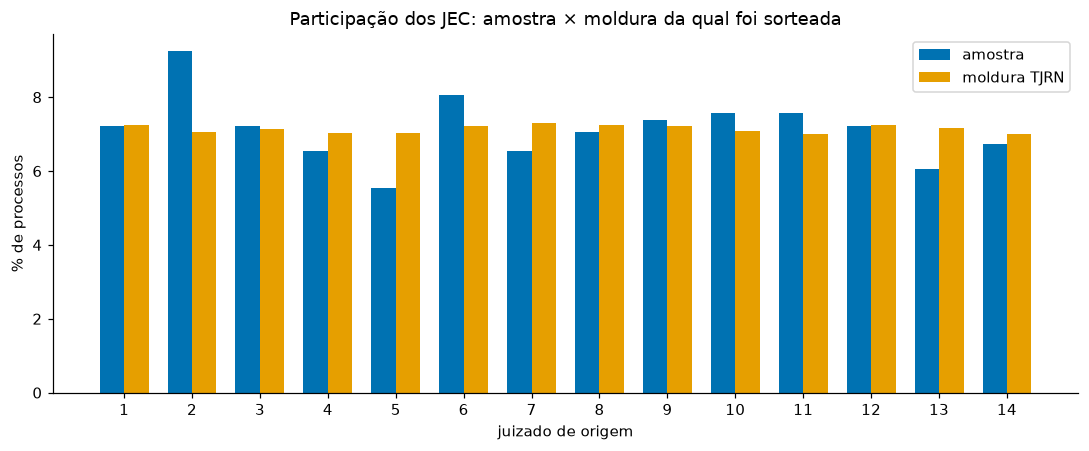

In [12]:
def diagnosticar_juizados(moldura, sorteio, *, semente=20261029, replicas=20000):
    '''Compara JEC de origem, condicionando o sorteio aos tamanhos por ano.'''
    jecs = list(range(1, 15))
    N = moldura.groupby(['ano', 'jec']).size().unstack(fill_value=0).reindex(columns=jecs, fill_value=0)
    O = sorteio.groupby(['ano', 'jec']).size().unstack(fill_value=0).reindex(index=N.index, columns=jecs, fill_value=0)
    Nh, nh = N.sum(axis=1), O.sum(axis=1)
    P = N.div(Nh, axis=0)
    E_ano = P.mul(nh, axis=0)
    E, observado = E_ano.sum(axis=0).to_numpy(), O.sum(axis=0).to_numpy()
    V = (P.mul(1 - P).mul(nh * (Nh - nh) / (Nh - 1), axis=0)).sum(axis=0).to_numpy()
    z = (observado - E) / np.sqrt(V)
    rng = np.random.default_rng(semente)
    sim_total = np.zeros((replicas, 14), dtype=int)
    sim_estratos = np.zeros(replicas)
    anos = []
    for ano in N.index:
        simulados = rng.multivariate_hypergeometric(N.loc[ano].to_numpy(), int(nh.loc[ano]), size=replicas)
        sim_total += simulados
        e_ano = E_ano.loc[ano].to_numpy()
        estat = float(((O.loc[ano].to_numpy() - e_ano) ** 2 / e_ano).sum())
        estat_sim = ((simulados - e_ano) ** 2 / e_ano).sum(axis=1)
        sim_estratos += estat_sim
        anos.append({'ano': int(ano), 'n': int(nh.loc[ano]), 'qui-quadrado': estat,
                     'p por sorteio': (1 + int((estat_sim >= estat).sum())) / (replicas + 1)})
    estat_global = float((((observado - E) ** 2) / E).sum())
    estat_sim_global = ((sim_total - E) ** 2 / E).sum(axis=1)
    estat_estratos = float((((O.to_numpy() - E_ano.to_numpy()) ** 2) / E_ano.to_numpy()).sum())
    max_sim = np.max(np.abs((sim_total - E) / np.sqrt(V)), axis=1)
    tabela = pd.DataFrame({'JEC': jecs, 'N da referência': N.sum(axis=0).to_numpy(),
                           'n da amostra': observado, 'n esperado': E,
                           '% referência': N.sum(axis=0).to_numpy() / Nh.sum(),
                           '% amostra': observado / nh.sum(),
                           'diferença (p.p.)': 100 * (observado / nh.sum() - N.sum(axis=0).to_numpy() / Nh.sum()),
                           'desvio padronizado': z,
                           'p ajustado (14 JEC)': [(1 + int((max_sim >= abs(v)).sum())) / (replicas + 1) for v in z]})
    resumo = {'N': int(Nh.sum()), 'n': int(nh.sum()), 'estatística global': estat_global,
              'p global': (1 + int((estat_sim_global >= estat_global).sum())) / (replicas + 1),
              'estatística ano × JEC': estat_estratos,
              'p ano × JEC': (1 + int((sim_estratos >= estat_estratos).sum())) / (replicas + 1)}
    return tabela, pd.DataFrame(anos), resumo

_base_jec = base.rename(columns={'ano_inicio': 'ano'})[['ano', 'jec']].copy()
_am_jec = am[['ano', 'jec']].copy()
TAB_JEC, ANOS_JEC, RES_JEC = diagnosticar_juizados(_base_jec, _am_jec)
assert (RES_JEC['N'], RES_JEC['n']) == (50320, 595)
assert int(TAB_JEC.loc[TAB_JEC.JEC == 2, 'n da amostra'].iloc[0]) == 55
display(tabela_ptbr(TAB_JEC, casas=3, pct=['% referência', '% amostra'], p=['p ajustado (14 JEC)']))
display(tabela_ptbr(ANOS_JEC, casas=3, p=['p por sorteio']))
display(pd.Series(RES_JEC, name='sorteio por ano, sem cotas por JEC').to_frame())

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(TAB_JEC.JEC - 0.18, 100 * TAB_JEC['% amostra'], width=0.36, label='amostra')
ax.bar(TAB_JEC.JEC + 0.18, 100 * TAB_JEC['% referência'], width=0.36, label='moldura TJRN')
ax.set(xlabel='juizado de origem', ylabel='% de processos', xticks=TAB_JEC.JEC,
       title='Participação dos JEC: amostra × moldura da qual foi sorteada')
ax.legend(); fig.tight_layout()
fig.savefig(FIGURAS / 'amostra_juizados_moldura.png', dpi=150)
plt.show()

**Leitura da moldura.** Os juizados têm participações próximas de 7% na população depurada. O 2º JEC é o maior excesso na amostra: 55 casos, contra aproximadamente 42 esperados; sua participação passa de 7,06% na moldura a 9,24% na amostra. O 5º tem 33 casos, contra aproximadamente 42 esperados. Considerados todos os juizados e os anos do sorteio, as diferenças são compatíveis com a oscilação de uma amostra desse tamanho: o teste global por simulação resulta em **p ≈ 0,79** e o teste das combinações ano × JEC em **p ≈ 0,97**. Nenhum juizado se destaca após considerar as 14 comparações; para o 2º, o p ajustado é aproximadamente 0,40.

Isso **não prova ausência de viés** nem recupera a semente do sorteio original. Mostra que os números realizados não dão evidência de uma distorção por juizado. Sem cotas por JEC, há menos controle da precisão de estimativas **de cada juizado isoladamente**: aqui cada unidade contribuiu com aproximadamente 33 a 55 processos.

### 2.4.1 A interseção entre ano e juizado

Uma distribuição próxima da população no total dos três anos poderia esconder excessos em um ano compensados por faltas em outro. Por isso, a tabela seguinte abre as **42 células**: para cada ano e JEC, mostra quantos processos havia na população elegível, quantos vieram para a amostra, quantos seriam esperados sob sorteio aleatório dentro do ano e as duas participações **dentro daquele mesmo ano**. A diferença em pontos percentuais compara essas participações, sem misturar os tamanhos de 2022, 2023 e 2024.

O mapa facilita localizar excessos e faltas. Para que um destaque visual entre 42 células não seja confundido com evidência de viés, simulamos novamente 20.000 sorteios com os três tamanhos anuais fixos e comparamos cada desvio padronizado com o **maior desvio de todas as 42 células** em cada réplica. O valor de p ajustado responde à busca pelo caso mais discrepante; os testes globais por ano e para as 42 células foram apresentados acima.

,ano,JEC,N elegível,n sorteado,n esperado,% elegível no ano,% amostra no ano,diferença (p.p.),desvio padronizado,p ajustado (42 células)
0,2022,1,1.178,17,"13,946","7,189%","8,763%","1,574","0,854",p = 1
1,2022,2,1.175,19,"13,910","7,170%","9,794%","2,623","1,425","p = 0,9988"
2,2022,3,1.176,17,"13,922","7,176%","8,763%","1,586","0,861",p = 1
3,2022,4,1.150,13,"13,614","7,018%","6,701%","-0,317","-0,174",p = 1
4,2022,5,1.151,10,"13,626","7,024%","5,155%","-1,869","-1,025",p = 1
5,2022,6,1.147,10,"13,579","6,999%","5,155%","-1,845","-1,013",p = 1
6,2022,7,1.190,11,"14,088","7,262%","5,670%","-1,592","-0,859",p = 1
7,2022,8,1.194,14,"14,135","7,286%","7,216%","-0,070","-0,038",p = 1
8,2022,9,1.164,17,"13,780","7,103%","8,763%","1,660","0,905",p = 1
9,2022,10,1.208,18,"14,301","7,372%","9,278%","1,907","1,022",p = 1


,ano,JEC,maior desvio padronizado,p ajustado para buscar entre 42,p global das 42 células
0,2023,2,"1,502","p = 0,9969","p = 0,9705"


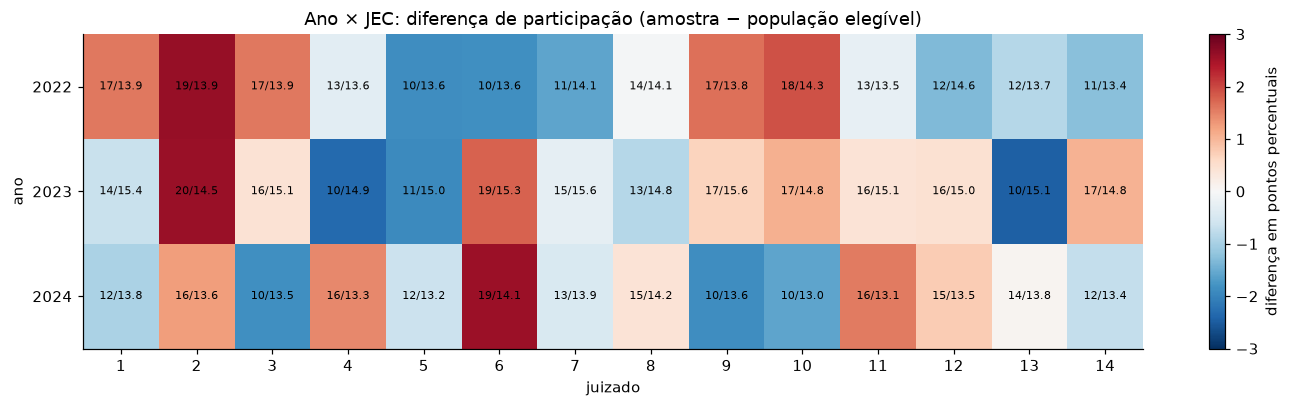

In [13]:
_N_cruzado = _base_jec.groupby(['ano', 'jec']).size().unstack(fill_value=0).reindex(columns=range(1, 15))
_O_cruzado = _am_jec.groupby(['ano', 'jec']).size().unstack(fill_value=0).reindex(
    index=_N_cruzado.index, columns=_N_cruzado.columns, fill_value=0)
_N_anuais = _N_cruzado.sum(axis=1)
_n_anuais = _O_cruzado.sum(axis=1)
_p_cruzado = _N_cruzado.div(_N_anuais, axis=0)
_E_cruzado = _p_cruzado.mul(_n_anuais, axis=0)
_var_cruzado = _p_cruzado.mul(1 - _p_cruzado).mul(
    _n_anuais * (_N_anuais - _n_anuais) / (_N_anuais - 1), axis=0)
_z_cruzado = (_O_cruzado - _E_cruzado) / np.sqrt(_var_cruzado)
_dif_cruzado = 100 * (_O_cruzado.div(_n_anuais, axis=0) - _p_cruzado)
_rng_cruzado = np.random.default_rng(20261030)
_max_desvio_simulado = np.zeros(20000)
for _ano_cruzado in _N_cruzado.index:
    _sorteios = _rng_cruzado.multivariate_hypergeometric(
        _N_cruzado.loc[_ano_cruzado].to_numpy(), int(_n_anuais.loc[_ano_cruzado]), size=20000)
    _z_sorteios = np.abs((_sorteios - _E_cruzado.loc[_ano_cruzado].to_numpy()) /
                        np.sqrt(_var_cruzado.loc[_ano_cruzado].to_numpy()))
    _max_desvio_simulado = np.maximum(_max_desvio_simulado, _z_sorteios.max(axis=1))

_linhas_cruzadas = []
for _ano_cruzado in _N_cruzado.index:
    for _jec_cruzado in _N_cruzado.columns:
        _z = float(_z_cruzado.loc[_ano_cruzado, _jec_cruzado])
        _linhas_cruzadas.append({
            'ano': int(_ano_cruzado), 'JEC': int(_jec_cruzado),
            'N elegível': int(_N_cruzado.loc[_ano_cruzado, _jec_cruzado]),
            'n sorteado': int(_O_cruzado.loc[_ano_cruzado, _jec_cruzado]),
            'n esperado': float(_E_cruzado.loc[_ano_cruzado, _jec_cruzado]),
            '% elegível no ano': float(_p_cruzado.loc[_ano_cruzado, _jec_cruzado]),
            '% amostra no ano': float(_O_cruzado.loc[_ano_cruzado, _jec_cruzado] / _n_anuais.loc[_ano_cruzado]),
            'diferença (p.p.)': float(_dif_cruzado.loc[_ano_cruzado, _jec_cruzado]),
            'desvio padronizado': _z,
            'p ajustado (42 células)': (1 + int((_max_desvio_simulado >= abs(_z)).sum())) / 20001,
        })
TAB_ANO_JEC = pd.DataFrame(_linhas_cruzadas)
assert len(TAB_ANO_JEC) == 42 and TAB_ANO_JEC['n sorteado'].sum() == 595
assert TAB_ANO_JEC['n sorteado'].min() == 10 and TAB_ANO_JEC['n sorteado'].max() == 20
display(tabela_ptbr(TAB_ANO_JEC, casas=3,
                    pct=['% elegível no ano', '% amostra no ano'], p=['p ajustado (42 células)']))

_extremo = TAB_ANO_JEC.loc[TAB_ANO_JEC['desvio padronizado'].abs().idxmax()]
_resumo_cruzado = pd.DataFrame([{
    'ano': int(_extremo['ano']), 'JEC': int(_extremo['JEC']),
    'maior desvio padronizado': float(abs(_extremo['desvio padronizado'])),
    'p ajustado para buscar entre 42': float(_extremo['p ajustado (42 células)']),
    'p global das 42 células': RES_JEC['p ano × JEC'],
}])
display(tabela_ptbr(_resumo_cruzado, casas=3,
                    p=['p ajustado para buscar entre 42', 'p global das 42 células']))

fig, ax = plt.subplots(figsize=(13, 3.8))
_escala = max(3.0, float(np.abs(_dif_cruzado.to_numpy()).max()))
_imagem = ax.imshow(_dif_cruzado.to_numpy(), cmap='RdBu_r', vmin=-_escala, vmax=_escala, aspect='auto')
for _i, _ano_cruzado in enumerate(_N_cruzado.index):
    for _j, _jec_cruzado in enumerate(_N_cruzado.columns):
        ax.text(_j, _i, f'{int(_O_cruzado.loc[_ano_cruzado, _jec_cruzado])}/'
                f'{_E_cruzado.loc[_ano_cruzado, _jec_cruzado]:.1f}',
                ha='center', va='center', fontsize=7)
ax.set(xticks=np.arange(14), xticklabels=list(_N_cruzado.columns),
       yticks=np.arange(len(_N_cruzado)), yticklabels=list(_N_cruzado.index),
       xlabel='juizado', ylabel='ano',
       title='Ano × JEC: diferença de participação (amostra − população elegível)')
fig.colorbar(_imagem, ax=ax, label='diferença em pontos percentuais')
fig.tight_layout()
fig.savefig(FIGURAS / 'amostra_ano_juizado_intersecao.png', dpi=150)
plt.show()

**Leitura da interseção.** A amostra tem **194 processos de 2022, 211 de 2023 e 190 de 2024**. Cada combinação ano × JEC contribui com **10 a 20 processos**. Os testes globais por ano ficam aproximadamente em **p = 0,79 (2022), 0,78 (2023) e 0,92 (2024)**; o teste conjunto das 42 células dá **p ≈ 0,97**. O maior desvio padronizado é o 2º JEC em 2023: **20 sorteados contra 14,5 esperados**. Ao considerar que se procurou o maior desvio entre 42 células, seu p ajustado fica aproximadamente em **0,997**. Assim, não aparece um desequilíbrio escondido em um ano que a tabela agregada tivesse cancelado.

Os valores de p testam compatibilidade com o sorteio aleatório por ano; não provam equivalência exata nem corrigem eventuais falhas da planilha original. Em especial, 10 a 20 casos por célula bastam para inspecionar a distribuição do sorteio, mas são poucos para estimar com precisão a taxa de indício em cada combinação de ano e juizado.

### 2.5 O desbalanceamento observado altera a estimativa de indício?

O teste anterior pergunta se as contagens por juizado são plausíveis sob o sorteio. Para medir o possível efeito sobre o resultado substantivo, ajustamos a amostra às proporções conhecidas das **42 combinações ano × JEC** da moldura. Cada processo recebe peso `N_ano,jec/n_ano,jec`; todas as células têm observações, mas algumas são pequenas. Comparamos a proporção simples, a estimativa estratificada somente por ano e a estimativa pós-estratificada por ano e juizado. Essa é uma análise de sensibilidade da estimativa agregada, não uma substituição automática do desenho original.

In [14]:
_N_ano_jec = base.groupby(['ano_inicio', 'jec']).size().rename('N_celula')
_n_ano_jec = am.groupby(['ano', 'jec']).size().rename('n_celula')
_pesos_jec = am[['ano', 'jec', 'indicio', 'certeza']].copy()
_pesos_jec = _pesos_jec.join(_N_ano_jec, on=['ano', 'jec']).join(_n_ano_jec, on=['ano', 'jec'])
assert _pesos_jec[['N_celula', 'n_celula']].notna().all().all()
_pesos_jec['peso_ano_jec'] = _pesos_jec.N_celula / _pesos_jec.n_celula
assert np.isclose(_pesos_jec.peso_ano_jec.sum(), len(base))
_N_ano = base.groupby('ano_inicio').size().rename('N_ano')
_n_ano = am.groupby('ano').size().rename('n_ano')
_pesos_jec = _pesos_jec.join(_N_ano, on='ano').join(_n_ano, on='ano')
_pesos_jec['peso_ano'] = _pesos_jec.N_ano / _pesos_jec.n_ano
_linhas_impacto = []
for _rotulo, _coluna in [('indício', 'indicio'), ('certeza', 'certeza')]:
    _y = _pesos_jec[_coluna].astype(int)
    _simples = float(_y.mean())
    _estrat = float(np.average(_y, weights=_pesos_jec.peso_ano))
    _pos = float(np.average(_y, weights=_pesos_jec.peso_ano_jec))
    _linhas_impacto.append({'categoria': _rotulo, 'proporção simples': _simples,
                            'ajuste por ano': _estrat, 'ajuste por ano × JEC': _pos,
                            'mudança ante ajuste por ano (p.p.)': 100 * (_pos - _estrat)})
TAB_IMPACTO_JEC = pd.DataFrame(_linhas_impacto)
display(tabela_ptbr(TAB_IMPACTO_JEC, casas=3,
                    pct=['proporção simples', 'ajuste por ano', 'ajuste por ano × JEC']))
display(pd.Series({'menor n em ano × JEC': int(_n_ano_jec.min()),
                   'maior n em ano × JEC': int(_n_ano_jec.max()),
                   'n efetivo dos pesos ano × JEC': float(_pesos_jec.peso_ano_jec.sum() ** 2 /
                       (_pesos_jec.peso_ano_jec ** 2).sum())}, name='diagnóstico dos pesos').to_frame())

,categoria,proporção simples,ajuste por ano,ajuste por ano × JEC,mudança ante ajuste por ano (p.p.)
0,indício,"17,647%","17,648%","17,468%","-0,180"
1,certeza,"5,042%","5,044%","5,092%","0,048"


,diagnóstico dos pesos
menor n em ano × JEC,"10,0000"
maior n em ano × JEC,"20,0000"
n efetivo dos pesos ano × JEC,"570,5360"


**Leitura do efeito prático.** O indício estimado com os pesos originais por ano é aproximadamente **17,65%**. Ao incorporar também a participação de cada JEC na moldura, fica em aproximadamente **17,47%**, uma diferença de **−0,18 ponto percentual**. Para certeza, a mudança é de aproximadamente **5,04% para 5,09%**. Assim, a falta de cotas por JEC teve efeito pequeno nas **estimativas agregadas observadas**. O tamanho efetivo dos novos pesos é cerca de 571, ante 595 sorteados; esse ajuste não cria informação nova nem melhora a precisão para um JEC isolado.

### 2.6 Quadro de Variáveis e Dicionário de Dados

O Plano de Ensino pede, para cada variável: nome, descrição, tipo, escala, unidade, faixa ou categorias, validade e confiabilidade (TOSHKOV, 2016, cap. 8, p. 200–208; EPSTEIN; KING, 2013, p. 108 e 134). A aba `Quadro variáveis` da planilha está **incompleta**: só vai até F2_09, quebra nomes em duas linhas e traz um rótulo divergente para F1_C (B-3). O quadro abaixo é gerado a partir dos próprios dados, para que tipos, faixas e contagens nunca divirjam do conjunto analítico.

O Quadro de Variáveis liga cada coluna à definição substantiva, à escala e à regra de ausência. O conjunto curado é exportado depois dessas verificações, para que as análises usem a mesma versão dos dados e os colegas possam rastrear cada transformação.

In [15]:
# 2.6 Quadro de Variáveis (gerado dos dados) e exportação do conjunto curado
def linha(nome, descricao, tipo, escala, unidade, categorias, validade, confiabilidade):
    s = am[nome]
    return dict(nome=nome, descricao=descricao, tipo=tipo, escala=escala, unidade=unidade, faixa_categorias=categorias,
                validade=validade, confiabilidade=confiabilidade, dtype=str(s.dtype), n_validos=int(s.notna().sum()),
                na_estrutural=int(s.isna().sum()))

CONF_MANUAL = 'um codificador, sem segunda leitura (kappa entre codificadores indisponível)'
q = [linha('numero', 'número CNJ do processo', 'identificador', '—', '—', '20 dígitos; DV mod 97',
           'DV conferido após cada transformação; 20 restaurados', 'exata'),
     linha('ordem', 'posição na moldura (Base consolidada)', 'identificador', '—', '—', '1–50.320', 'confere com a moldura', 'exata'),
     linha('jec', 'juizado (unidade judiciária)', 'qualitativa', 'nominal (14 níveis)', '—', '1º a 14º JEC', 'da moldura', 'exata'),
     linha('ano', 'ano de distribuição (estrato)', 'qualitativa', 'ordinal', 'ano', '2022–2024', 'DATA INÍCIO da moldura', 'exata'),
     linha('classe_planilha', 'classe processual na data da coleta', 'qualitativa', 'nominal', '—',
           ', '.join(am.classe_planilha.cat.categories[:3]) + ' …', 'classe atual, não a de distribuição', 'registro do PJe')]
for c in F1 + F2 + F3:
    fase = {'1': 'I (exclusão)', '2': 'II (indícios formais)', '3': 'III (massificação)'}[c[1]]
    na = {'1': 'nenhum', '2': 'NA estrutural se excluído na Fase I', '3': 'NA estrutural fora da Fase III'}[c[1]]
    q.append(linha(c, f'{ROTULOS[c]} — Fase {fase}', 'qualitativa', 'nominal dicotômica', '—', f'Sim/Não; {na}',
                   'Anexo A da Rec. CNJ 159/2024; leitura dos autos', CONF_MANUAL))
q += [linha('excluido_f1', 'saiu na Fase I (alguma F1)', 'qualitativa', 'nominal dicotômica', '—', 'Sim/Não',
            'derivada', 'determinística'),
      linha('n_F2', 'número de indícios F2 marcados', 'quantitativa', 'razão (contagem)', 'indícios', f'0–{int(am.n_F2.max())}',
            'derivada', 'determinística'),
      linha('fase_alcancada', 'última fase alcançada no funil', 'qualitativa', 'ordinal', '—', 'I < II < III',
            'derivada', 'determinística'),
      linha('indicio', 'indício de lide predatória (F3_19 ∧ F3_20)', 'qualitativa', 'nominal dicotômica', '—', 'Sim/Não',
            'regra da pesquisa', 'função das F3'),
      linha('certeza', 'certeza (F3_18 ∧ F3_19 ∧ F3_20)', 'qualitativa', 'nominal dicotômica', '—', 'Sim/Não',
            'regra da pesquisa', 'função das F3'),
      linha('classe3', 'classificação final em 3 níveis exclusivos', 'qualitativa', 'ordinal', '—',
            ' < '.join(NIVEIS_CLASSE3), 'partição do espaço amostral', 'função das F3')]
QUADRO = pd.DataFrame(q)
display(QUADRO)

# exportação: conjunto curado (CNJ texto) + quadro; releitura conferida
COLS = ['numero', 'ordem', 'jec', 'unidade', 'ano', 'classe_planilha'] + F1 + F2 + F3 + \
       ['obs', 'excluido_f1', 'alguma_f2', 'n_F2', 'indicio', 'certeza', 'classe3_cod', 'classe3', 'fase_alcancada']
am[COLS].to_parquet(PROCESSADO / 'amostra_curada.parquet', index=False)
relida = pd.read_parquet(PROCESSADO / 'amostra_curada.parquet')
C.conferir_cnj(relida['numero'], 'exportação parquet')
assert relida.shape == (595, len(COLS)) and relida['classe3'].cat.ordered
with pd.ExcelWriter(TABELAS / 'quadro_variaveis_estcaso3.xlsx') as xw:
    QUADRO.to_excel(xw, sheet_name='Quadro de Variáveis', index=False)
    relatorio_grafias.to_excel(xw, sheet_name='Grafias', index=False)
    incoerencias.to_excel(xw, sheet_name='Incoerências', index=False)
    perdas.to_excel(xw, sheet_name='Moldura', index=False)
V.update(n_variaveis_quadro=fint(len(QUADRO)), n_colunas_export=fint(len(COLS)))

,nome,descricao,tipo,escala,unidade,faixa_categorias,validade,confiabilidade,dtype,n_validos,na_estrutural
0,numero,número CNJ do processo,identificador,—,—,20 dígitos; DV mod 97,DV conferido após cada transformação; 20 resta...,exata,string,595,0
1,ordem,posição na moldura (Base consolidada),identificador,—,—,1–50.320,confere com a moldura,exata,Int32,595,0
2,jec,juizado (unidade judiciária),qualitativa,nominal (14 níveis),—,1º a 14º JEC,da moldura,exata,Int8,595,0
3,ano,ano de distribuição (estrato),qualitativa,ordinal,ano,2022–2024,DATA INÍCIO da moldura,exata,Int16,595,0
4,classe_planilha,classe processual na data da coleta,qualitativa,nominal,—,"CUMPRIMENTO DE SENTENÇA, CUMPRIMENTO PROVISÓRI...","classe atual, não a de distribuição",registro do PJe,category,595,0
5,F1_A,Ações de pessoa física no polo passivo — Fase ...,qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",boolean,595,0
6,F1_B,Ausência de grande litigante no polo passivo —...,qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",boolean,595,0
7,F1_C,Processo de conhecimento em curso — Fase I (ex...,qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",boolean,595,0
8,F1_D,Processos suspensos — Fase I (exclusão),qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",boolean,595,0
9,F1_E,Distribuição incorreta — Fase I (exclusão),qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",boolean,595,0


In [16]:
exibir('cur_quadro', r'''
**Leitura.** O Quadro de Variáveis tem {{n_variaveis_quadro}} linhas, com as oito colunas exigidas no Plano de Ensino. Tipo, faixa e número de valores válidos são calculados dos dados, e por isso não podem divergir do conjunto analítico.

- **Escalas.** As F1, F2 e F3 são nominais dicotômicas. A classe3 e a fase alcançada são **ordinais**. O `n_F2` é uma contagem (Seção 4). O número CNJ é um **identificador**: é texto, e nunca número.
- **Validade e confiabilidade.** As variáveis F foram lidas por **uma só codificadora**, sem segunda leitura. Não há como medir a confiabilidade entre codificadores (kappa), e esse é o principal limite de medição do estudo. As derivadas são funções determinísticas das F.
- **Exportação.** O conjunto curado ({{n_colunas_export}} colunas) foi gravado em `processado/amostra_curada.parquet` e relido, com o DV conferido de novo. O quadro, o relatório de grafias, as incoerências e a moldura foram gravados em `tabelas/quadro_variaveis_estcaso3.xlsx`.

O mesmo quadro, estendido com as variáveis do DataJud, é o **gabarito para a turma** na Seção 13.
''')


**Leitura.** O Quadro de Variáveis tem 37 linhas, com as oito colunas exigidas no Plano de Ensino. Tipo, faixa e número de valores válidos são calculados dos dados, e por isso não podem divergir do conjunto analítico.

- **Escalas.** As F1, F2 e F3 são nominais dicotômicas. A classe3 e a fase alcançada são **ordinais**. O `n_F2` é uma contagem (Seção 4). O número CNJ é um **identificador**: é texto, e nunca número.
- **Validade e confiabilidade.** As variáveis F foram lidas por **uma só codificadora**, sem segunda leitura. Não há como medir a confiabilidade entre codificadores (kappa), e esse é o principal limite de medição do estudo. As derivadas são funções determinísticas das F.
- **Exportação.** O conjunto curado (41 colunas) foi gravado em `processado/amostra_curada.parquet` e relido, com o DV conferido de novo. O quadro, o relatório de grafias, as incoerências e a moldura foram gravados em `tabelas/quadro_variaveis_estcaso3.xlsx`.

O mesmo quadro, estendido com as variáveis do DataJud, é o **gabarito para a turma** na Seção 13.


## 3. Os Dados Novos: Desfechos da Amostra no DataJud (R6)

### 3.1 Pergunta e método

O roteiro pede a **verossimilhança** das hipóteses à luz dos desfechos dos processos (extinção, acordo ou sentença) obtidos no DataJud (R6). Antes de usar o desfecho como evidência (Seção 6), é preciso medi-lo bem.

**A fonte.** A API pública do DataJud (CNJ) devolve, para cada número, um documento por grau: JE (juizado), G1, TR (Turma Recursal)… Cada documento traz a classe **atual**, o órgão atual, os assuntos e a lista de **movimentos** codificados pela Tabela Processual Unificada (TPU). A coleta da amostra já está em cache (`datajud/amostra.jsonl.gz`); este notebook não chama a API.

**Por que o proxy completo, e não a regra da apostila.** A apostila usou uma regra simplificada: a última decisão terminativa antes de o processo virar cumprimento de sentença. O módulo `framework/modulos/datajud_tpu` define o desfecho por um *proxy* declarado em YAML (`proxies/desfecho_conhecimento.yaml`), com:

| Elemento | Regra |
|---|---|
| fase | só movimentos **anteriores** ao corte conhecimento → cumprimento (evolução de classe 14739/10966; retificação 14738 só na falta deles; início de cumprimento 11385) |
| categorias | subárvores da TPU: acordo; procedência, procedência parcial, improcedência e outras de mérito; extinções sem mérito por motivo (desistência, abandono, ausência do autor, indeferimento, competência/rito do JEC, pressupostos, litispendência…) |
| escolha | a **última** decisão da fase; no mesmo dia, vence a precedência acordo > mérito > sem mérito (o conflito é registrado) |
| anulação e cancelamento | anulação (11373) apaga as decisões anteriores; cancelamento (12291) só sinaliza |
| residuais | sem decisão: "evoluiu sem sentença registrada", "transitado sem sentença registrada" (848), "arquivado sem sentença" (246/22) ou "em tramitação" (censurado) |

Os residuais são a diferença mais importante: a regra simplificada põe todos no mesmo saco ("sem desfecho registrado"), quando eles significam coisas distintas.

**Unidade de análise.** É o processo, isto é, o número. O desfecho vem do documento de entrada (JE; G1 quando o processo foi redistribuído para uma vara). O recurso vem do documento da Turma Recursal.

O DataJud registra movimentos e situação administrativa, não uma leitura integral dos autos. O módulo de TPU traduz códigos em um desfecho operacional. Esta é uma medida indireta, cuja regra precisa ser declarada antes de discutir associação com litigância predatória.

In [17]:
# 3.1 Normalização e derivação com o módulo datajud_tpu (proxies completos)
from estcaso3 import datajud_processo as DJ

MANIFESTO = json.loads((DATAJUD / 'manifesto.json').read_text(encoding='utf-8'))
DATA_COLETA = MANIFESTO['amostra']['fim_utc'][:10]
with C.capturar_avisos('DataJud: normalização e derivação (amostra)', AVISOS):
    TPU_ATUAL, PROXIES = DJ.carregar_tpu_proxies()           # falha se a TPU mudou desde a expansão dos proxies
    tab_dj, der_dj = DJ.derivar([DATAJUD / 'amostra.jsonl.gz'], TPU_ATUAL, PROXIES, DATA_COLETA)
docs_dj = tab_dj['documentos']
C.conferir_cnj(docs_dj['numero'], 'documentos DataJud')
display(pd.DataFrame({'documentos': docs_dj.groupby('grau').size(), 'processos': docs_dj.groupby('grau').numero.nunique()}))
V.update(dj_documentos=fint(len(docs_dj)), dj_processos=fint(docs_dj.numero.nunique()),
         dj_tr=fint((docs_dj.grau == 'TR').sum()), dj_data_coleta=pd.Timestamp(DATA_COLETA).strftime('%d/%m/%Y'),
         tpu_versao=TPU_ATUAL.versao['movimentos_ultima_alteracao'])

,documentos,processos
grau,,
G1,4,4
G2,3,3
JE,589,589
TR,154,154


Cada processo pode ter vários documentos e graus. A consolidação reduz isso a uma linha por número CNJ, mantendo o grau de entrada e os eventos relevantes. A junção com a amostra é validada como um para um, pois duplicatas alterariam contagens e probabilidades.

In [18]:
# 3.2 Uma linha por processo (função compartilhada com a população: DJ.consolidar)
proc = DJ.consolidar(tab_dj, der_dj)
assert len(proc) == C.confere('processos com documento JE/G1', len(proc),
                              GAB['datajud']['processos_com_documento_JE_G1'], registro=CONFERENCIAS)
ROTULO_CATEGORIA = DJ.ROTULO_CATEGORIA

# junção com a amostra curada (CNJ texto; DV conferido depois do merge)
dj = am.merge(proc, on='numero', how='left', validate='1:1')
C.conferir_cnj(dj['numero'], 'merge amostra × DataJud')
assert dj['grau_entrada'].isna().sum() == len(nao_localizados)
assert set(dj.loc[dj.grau_entrada.isna(), 'numero']) == set(nao_localizados.numero)

tab_desf = (proc.groupby(['desfecho', 'desfecho_rotulo'], observed=True).size().rename('n').reset_index()
            .sort_values(['desfecho', 'n'], ascending=[True, False]))
tab_desf['% dos processos'] = tab_desf['n'] / len(proc)
display(tabela_ptbr(tab_desf, pct=['% dos processos']))
grp = proc['desfecho'].value_counts().reindex(proc['desfecho'].cat.categories)
ic_grp = pd.DataFrame({'n': grp, 'proporção': grp / len(proc)})
ic_grp[['IC 95% inf.', 'IC 95% sup.']] = [C.wilson(k, len(proc)) for k in grp]
display(tabela_ptbr(ic_grp.reset_index(), pct=['proporção', 'IC 95% inf.', 'IC 95% sup.']))
SLUG_DESFECHO = {'acordo': 'acordo', 'mérito': 'merito', 'extinção sem mérito': 'sem_merito',
                 'sem sentença registrada': 'sem_sentenca'}
V.update({f'dj_n_{SLUG_DESFECHO[k]}': fint(v) for k, v in grp.items()})
V.update({f'dj_p_{SLUG_DESFECHO[k]}': fpct(v / len(proc), 1) for k, v in grp.items()})
V.update(dj_n_proc=fint(len(proc)), dj_n_g1=fint((proc.grau_entrada == 'G1').sum()),
         dj_n_conflito=fint(proc.conflito_mesmo_dia.sum()),
         dj_n_ultima_dif_primeira=fint((proc.primeira_categoria.notna() & (proc.primeira_categoria != proc.desfecho_categoria)).sum()),
         dj_n_recurso=fint(proc.houve_recurso.sum()), dj_p_recurso=fpct(proc.houve_recurso.mean(), 1),
         dj_n_redist=fint(proc.redistribuido.sum()), dj_n_cumprimento=fint(proc.evoluiu_cumprimento.sum()),
         dj_n_origem_inferida=fint(proc.classe_origem_inferida.sum()),
         dj_n_competencia=fint((proc.desfecho_categoria == 'extincao_competencia_rito_jec').sum()),
         dj_n_censurado=fint((proc.desfecho_categoria == 'em_tramitacao').sum()))

,desfecho,desfecho_rotulo,n,% dos processos
0,acordo,acordo,65,"10,96%"
5,mérito,procedência parcial,183,"30,86%"
4,mérito,procedência,106,"17,88%"
2,mérito,improcedência,85,"14,33%"
3,mérito,prescrição/decadência,2,"0,34%"
1,mérito,homologação do pedido,1,"0,17%"
8,extinção sem mérito,extinção: competência/rito do JEC,69,"11,64%"
9,extinção sem mérito,extinção: desistência,22,"3,71%"
12,extinção sem mérito,extinção: pressupostos/condições,18,"3,04%"
10,extinção sem mérito,extinção: indeferimento da inicial,16,"2,70%"


,index,n,proporção,IC 95% inf.,IC 95% sup.
0,acordo,65,"10,96%","8,69%","13,73%"
1,mérito,377,"63,58%","59,63%","67,35%"
2,extinção sem mérito,142,"23,95%","20,69%","27,54%"
3,sem sentença registrada,9,"1,52%","0,80%","2,86%"


In [19]:
exibir('dj_proxy', r'''
**Leitura: o desfecho da fase de conhecimento pelo proxy completo.** A coleta de {{dj_data_coleta}} tem {{dj_documentos}} documentos de {{dj_processos}} processos ({{dj_tr}} deles da Turma Recursal; TPU de {{tpu_versao}}). O desfecho é derivado para os {{dj_n_proc}} processos com documento no juizado ou na vara.

| Desfecho | Processos | % |
|---|---:|---:|
| sentença de mérito | {{dj_n_merito}} | {{dj_p_merito}} |
| extinção sem mérito | {{dj_n_sem_merito}} | {{dj_p_sem_merito}} |
| acordo homologado | {{dj_n_acordo}} | {{dj_p_acordo}} |
| sem sentença registrada | {{dj_n_sem_sentenca}} | {{dj_p_sem_sentenca}} |

- **A extinção sem mérito mais comum** é a do próprio rito do JEC: incompetência ou inadmissibilidade do procedimento ({{dj_n_competencia}} processos). Não é desistência nem abandono. Isso importa para a Seção 6: "extinção" é um conjunto heterogêneo, e só parte dele tem relação plausível com a litigância predatória.
- **Casos difíceis**, registrados e não escondidos:
  - {{dj_n_conflito}} processos têm decisões de categorias diferentes no mesmo dia (vence a precedência);
  - em {{dj_n_ultima_dif_primeira}}, a primeira decisão da fase difere da última (em geral, sentença seguida de acordo);
  - {{dj_n_censurado}} segue em tramitação (censurado).
- **Trajetória.**
  - {{dj_n_recurso}} processos ({{dj_p_recurso}}) foram à Turma Recursal.
  - {{dj_n_cumprimento}} evoluíram para cumprimento de sentença; nesses, a classe de origem foi reconstruída pelo movimento de evolução ({{dj_n_origem_inferida}} inferências).
  - {{dj_n_redist}} foram redistribuídos ou estão fora dos 14 JEC; {{dj_n_g1}} deles estão hoje numa vara (G1).

**Cautela.** O desfecho é o que os cartórios **lançaram** na TPU, e não a leitura da sentença. A auditoria automática da Seção 3.2 detecta erros internos, mas não mede a distância até a sentença nos autos.
''')


**Leitura: o desfecho da fase de conhecimento pelo proxy completo.** A coleta de 27/10/2026 tem 750 documentos de 593 processos (154 deles da Turma Recursal; TPU de 2026-09-09). O desfecho é derivado para os 593 processos com documento no juizado ou na vara.

| Desfecho | Processos | % |
|---|---:|---:|
| sentença de mérito | 377 | 63,6% |
| extinção sem mérito | 142 | 23,9% |
| acordo homologado | 65 | 11,0% |
| sem sentença registrada | 9 | 1,5% |

- **A extinção sem mérito mais comum** é a do próprio rito do JEC: incompetência ou inadmissibilidade do procedimento (69 processos). Não é desistência nem abandono. Isso importa para a Seção 6: "extinção" é um conjunto heterogêneo, e só parte dele tem relação plausível com a litigância predatória.
- **Casos difíceis**, registrados e não escondidos:
  - 4 processos têm decisões de categorias diferentes no mesmo dia (vence a precedência);
  - em 32, a primeira decisão da fase difere da última (em geral, sentença seguida de acordo);
  - 1 segue em tramitação (censurado).
- **Trajetória.**
  - 154 processos (26,0%) foram à Turma Recursal.
  - 225 evoluíram para cumprimento de sentença; nesses, a classe de origem foi reconstruída pelo movimento de evolução (231 inferências).
  - 16 foram redistribuídos ou estão fora dos 14 JEC; 4 deles estão hoje numa vara (G1).

**Cautela.** O desfecho é o que os cartórios **lançaram** na TPU, e não a leitura da sentença. A auditoria automática da Seção 3.2 detecta erros internos, mas não mede a distância até a sentença nos autos.


Comparar duas regras automáticas revela divergências de implementação, mas não substitui a conferência nos autos. A tabela mostra onde a regra TPU completa e a regra simplificada concordam; o resultado deve continuar identificado como proxy até a validação humana.

In [20]:
# 3.3 Proxy completo × regra simplificada da apostila (processo a processo e na tabela classe3 × desfecho)
import gzip
with gzip.open(DATAJUD / 'amostra.jsonl.gz', 'rt', encoding='utf-8') as fh:
    simpl = C.desfecho_simplificado(json.loads(l) for l in fh)
dj['desfecho_simplificado'] = dj['numero'].map(simpl)
comp = dj[dj.desfecho.notna()]
cruz = pd.crosstab(comp['desfecho_simplificado'], comp['desfecho'], margins=True, margins_name='total')
display(cruz)
divergentes = comp[comp['desfecho_simplificado'].replace({'sem desfecho registrado': 'sem sentença registrada'})
                   != comp['desfecho'].astype(str)]
from sklearn.metrics import cohen_kappa_score
kappa_regras = cohen_kappa_score(comp['desfecho_simplificado'].replace({'sem desfecho registrado': 'sem sentença registrada'}),
                                 comp['desfecho'].astype(str))

# tabela classe3 × desfecho: a da apostila (gabarito) e a nova
mapa_gab = {'acordo': 'acordo', 'merito': 'mérito', 'sem_merito': 'extinção sem mérito',
            'sem_desfecho_registrado': 'sem sentença registrada'}
gab_ct = (pd.DataFrame(GAB['datajud']['classe3_x_desfecho']).T.rename(columns=mapa_gab)
          .reindex(columns=proc['desfecho'].cat.categories).fillna(0).astype(int))
gab_ct.index = NIVEIS_CLASSE3
nova_ct = pd.crosstab(comp['classe3'], comp['desfecho']).reindex(index=NIVEIS_CLASSE3, columns=proc['desfecho'].cat.categories, fill_value=0)
# a regra simplificada, recalculada aqui, reproduz o gabarito
simpl_ct = pd.crosstab(comp['classe3'], comp['desfecho_simplificado'].replace({'sem desfecho registrado': 'sem sentença registrada'})
                       ).reindex(index=NIVEIS_CLASSE3, columns=proc['desfecho'].cat.categories, fill_value=0)
assert (simpl_ct.values == gab_ct.values).all(), 'a regra simplificada não reproduz o gabarito da apostila'
dif_ct = nova_ct - gab_ct
display(pd.concat({'apostila (simplificada)': gab_ct, 'proxy completo': nova_ct, 'diferença': dif_ct}, axis=1))
transicoes = divergentes.groupby(['desfecho_simplificado', 'desfecho'], observed=True).size().sort_values(ascending=False)
display(transicoes.rename('processos').to_frame())
V.update(n_divergentes=fint(len(divergentes)), p_divergentes=fpct(len(divergentes) / len(comp), 1),
         kappa_regras=fnum(kappa_regras, 3), tabela_mudou='mudou' if dif_ct.abs().values.sum() else 'não mudou',
         n_celulas_mudaram=fint((dif_ct != 0).values.sum()),
         transicoes='; '.join(f'{a} → {b} ({fint(n)})' for (a, b), n in transicoes.items()) or 'nenhuma',
         residuais=', '.join(f'{k} ({fint(v)})' for k, v in
                             proc.loc[proc.desfecho == 'sem sentença registrada', 'desfecho_rotulo'].value_counts().items()),
         consequencia_tabela=('As verossimilhanças da apostila (§3.3b) continuam válidas no nível do grupo; a apostila não '
                              'precisa ser corrigida nesse ponto.') if not dif_ct.abs().values.sum() else
                             ('As verossimilhanças da apostila (§3.3b) mudam e são recalculadas na Seção 6; a apostila '
                              'precisa ser atualizada.'))

desfecho,acordo,mérito,extinção sem mérito,sem sentença registrada,total
desfecho_simplificado,,,,,
acordo,65,0,0,0,65
extinção sem mérito,0,0,142,0,142
mérito,0,377,0,0,377
sem desfecho registrado,0,0,0,9,9
total,65,377,142,9,593


apostila (simplificada)                             \
                                     acordo mérito extinção sem mérito   
não predatória                           58    312                 111   
indício sem certeza                       6     48                  20   
certeza                                   1     17                  11   

                                            proxy completo         \
                    sem sentença registrada         acordo mérito   
não predatória                            7             58    312   
indício sem certeza                       1              6     48   
certeza                                   1              1     17   

                                                                diferença  \
                    extinção sem mérito sem sentença registrada    acordo   
não predatória                      111                       7         0   
indício sem certeza                  20                       1         0   
certeza                              11                       1         0   

                                                                        
                    mérito extinção sem mérito sem sentença registrada  
não predatória           0                   0                       0  
indício sem certeza      0                   0                       0  
certeza                  0                   0                       0

,,processos
desfecho_simplificado,desfecho,


In [21]:
exibir('dj_comparacao', r'''
**Leitura: o proxy completo × a regra simplificada da apostila.**

- **Reprodução.** A regra simplificada, recalculada aqui, reproduz célula a célula a tabela classe3 × desfecho da apostila (§3.3b). A comparação é, portanto, entre as duas regras sobre os mesmos documentos.
- **Concordância.** No nível do grupo (acordo, mérito, extinção sem mérito, sem sentença), as duas regras discordam em {{n_divergentes}} processos ({{p_divergentes}}); o kappa entre elas é {{kappa_regras}}. Mudanças: {{transicoes}}.
- **A tabela classe3 × desfecho {{tabela_mudou}}** ({{n_celulas_mudaram}} células alteradas). O ganho do proxy completo, na amostra, é de **resolução**, e não de contagem. O que a regra simplificada chamava de "sem desfecho registrado" se divide em residuais com significado próprio: {{residuais}}. As extinções sem mérito também ganham o motivo (tabela acima). Na população (Seção 11), em que os residuais e as sentenças seguidas de acordo são mais frequentes, a diferença entre as regras pesa mais.

**Consequência.** {{consequencia_tabela}} A Seção 6 usa o proxy completo e pode separar a extinção por motivo.
''')


**Leitura: o proxy completo × a regra simplificada da apostila.**

- **Reprodução.** A regra simplificada, recalculada aqui, reproduz célula a célula a tabela classe3 × desfecho da apostila (§3.3b). A comparação é, portanto, entre as duas regras sobre os mesmos documentos.
- **Concordância.** No nível do grupo (acordo, mérito, extinção sem mérito, sem sentença), as duas regras discordam em 0 processos (0,0%); o kappa entre elas é 1,000. Mudanças: nenhuma.
- **A tabela classe3 × desfecho não mudou** (0 células alteradas). O ganho do proxy completo, na amostra, é de **resolução**, e não de contagem. O que a regra simplificada chamava de "sem desfecho registrado" se divide em residuais com significado próprio: transitado sem sentença registrada (5), arquivado sem sentença (2), evoluiu sem sentença registrada (1), em tramitação (censurado) (1). As extinções sem mérito também ganham o motivo (tabela acima). Na população (Seção 11), em que os residuais e as sentenças seguidas de acordo são mais frequentes, a diferença entre as regras pesa mais.

**Consequência.** As verossimilhanças da apostila (§3.3b) continuam válidas no nível do grupo; a apostila não precisa ser corrigida nesse ponto. A Seção 6 usa o proxy completo e pode separar a extinção por motivo.


### 3.2 Auditoria automatizada dos desfechos

Sem abrir autos, é possível verificar se as datas dos eventos são possíveis, quantos processos ficaram sem documento, quais categorias ficaram sem sentença registrada e onde duas regras de TPU divergem. A auditoria abaixo executa essas verificações em todos os processos disponíveis. Ela é uma **sensibilidade entre codificações administrativas**: não calcula sensibilidade ou especificidade em relação à sentença jurídica, que a API pública não contém.


Esta auditoria verifica automaticamente a cronologia dos eventos, a cobertura por ano e a concordância entre duas regras de TPU. Ela encontra incoerências detectáveis sem abrir autos. A concordância entre algoritmos que usam a mesma fonte não mede a validade jurídica do desfecho; esse limite permanece declarado.

In [22]:
# 3.4 Auditoria automática do proxy de desfecho, sem leitura manual de autos
_audit = proc.copy()
_audit['ano'] = pd.to_datetime(_audit.data_ajuizamento).dt.year
_eventos = _audit.e_desfecho.astype(int) == 1
_sem_data = int((_eventos & _audit.desfecho_data.isna()).sum())
_antes = int((_eventos & (_audit.desfecho_data < _audit.data_ajuizamento)).sum())
_sem_doc = int(dj.grau_entrada.isna().sum())
_residuais = int((_audit.desfecho == 'sem sentença registrada').sum())
AUDITORIA_PROXY = pd.DataFrame([
    {'verificação': 'processos com documento', 'casos': len(_audit)},
    {'verificação': 'amostra sem documento JE/G1', 'casos': _sem_doc},
    {'verificação': 'evento sem data', 'casos': _sem_data},
    {'verificação': 'evento anterior ao ajuizamento', 'casos': _antes},
    {'verificação': 'categorias residuais sem sentença', 'casos': _residuais},
    {'verificação': 'decisões de grupos diferentes no mesmo dia', 'casos': int(_audit.conflito_mesmo_dia.sum())},
    {'verificação': 'primeira categoria difere da última', 'casos': int((_audit.primeira_categoria.notna() &
        (_audit.primeira_categoria != _audit.desfecho_categoria)).sum())},
    {'verificação': 'divergência com regra simplificada, grupo amplo', 'casos': len(divergentes)},
])
display(AUDITORIA_PROXY)
display(pd.crosstab(_audit.ano, _audit.desfecho, margins=True))
V.update(conf_n=fint(len(_audit)), conf_estratos=fint(_audit.desfecho.nunique()),
         conf_status='auditoria automatizada; validade jurídica da sentença não observável por esta fonte')


,verificação,casos
0,processos com documento,593
1,amostra sem documento JE/G1,2
2,evento sem data,0
3,evento anterior ao ajuizamento,0
4,categorias residuais sem sentença,9
5,decisões de grupos diferentes no mesmo dia,4
6,primeira categoria difere da última,32
7,"divergência com regra simplificada, grupo amplo",0


desfecho,acordo,mérito,extinção sem mérito,sem sentença registrada,All
ano,,,,,
2022,23,121,42,7,193
2023,19,135,55,1,210
2024,23,121,45,1,190
All,65,377,142,9,593


In [23]:
exibir('dj_validacao', r'''
**Leitura da auditoria automática.** O proxy foi calculado para {{conf_n}} processos com documento, distribuídos em {{conf_estratos}} grupos amplos de desfecho. A tabela acima verifica datas, cobertura, decisões concorrentes e divergências entre duas regras de TPU. Situação: {{conf_status}}.

Essas verificações são reproduzíveis sem abrir processos e permitem localizar erros de código ou transmissão. Duas regras que concordam sobre os mesmos movimentos podem, porém, concordar no mesmo erro. Assim, os desfechos permanecem **proxies administrativos**, e nenhuma estimativa de acurácia jurídica é atribuída a eles.
''')


**Leitura da auditoria automática.** O proxy foi calculado para 593 processos com documento, distribuídos em 4 grupos amplos de desfecho. A tabela acima verifica datas, cobertura, decisões concorrentes e divergências entre duas regras de TPU. Situação: auditoria automatizada; validade jurídica da sentença não observável por esta fonte.

Essas verificações são reproduzíveis sem abrir processos e permitem localizar erros de código ou transmissão. Duas regras que concordam sobre os mesmos movimentos podem, porém, concordar no mesmo erro. Assim, os desfechos permanecem **proxies administrativos**, e nenhuma estimativa de acurácia jurídica é atribuída a eles.


O conjunto analítico reúne os sinais da pesquisa e os campos derivados do DataJud, preservando um processo por linha. A nova checagem do número CNJ protege as análises posteriores contra perdas silenciosas no cruzamento das fontes.

In [24]:
# 3.5 Conjunto analítico com as variáveis do DataJud (CNJ texto; DV conferido na releitura)
COLS_DJ = ['grau_entrada', 'desfecho', 'desfecho_categoria', 'desfecho_rotulo', 'extincao_iniciativa_autor', 'desfecho_data', 'desfecho_simplificado', 'classe_origem',
           'classe_origem_inferida', 'classe_atual', 'evoluiu_cumprimento', 'houve_recurso', 'resultado_recurso',
           'redistribuido', 'teve_acordo', 'assunto_codigo', 'assunto_principal', 'n_movimentos', 't_desfecho',
           'e_desfecho', 't_desfecho_cens_ultimo_mov', 'data_ajuizamento']
dj[COLS + COLS_DJ].to_parquet(PROCESSADO / 'amostra_datajud.parquet', index=False)
_ = C.conferir_cnj(pd.read_parquet(PROCESSADO / 'amostra_datajud.parquet')['numero'], 'exportação amostra_datajud')

---

# PARTE II: DESCRIÇÃO, PROBABILIDADE E BAYES

## 4. Estatística Descritiva e Distribuições

### 4.1 Frequências com intervalo de Wilson

Cada proporção vem com o IC de Wilson, e não com o de Wald. O Wilson inverte o teste escore e mantém a cobertura perto de 95% mesmo com proporções pequenas, como as das F2 raras (AGRESTI; FRANKLIN; KLINGENBERG, 2018, p. 398 e 410–411). **O denominador de cada F2 são os elegíveis**: a F2 só foi avaliada em quem passou da Fase I.

Antes de modelar, é preciso saber a frequência de cada sinal no grupo em que ele pôde ser observado. O intervalo de Wilson descreve a incerteza de cada proporção; para sinais raros, ele é mais informativo que apenas uma porcentagem arredondada.

In [25]:
# 4.1 Frequência de cada F (no denominador em que foi avaliada) com IC de Wilson
linhas = []
for c in F1 + F2 + F3:
    s = am[c].dropna()
    k, n = int(s.sum()), len(s)
    lo, hi = C.wilson(k, n)
    linhas.append(dict(variavel=c, rotulo=ROTULOS[c], avaliados=n, sim=k, proporcao=k / n, ic_inf=lo, ic_sup=hi))
FREQ = pd.DataFrame(linhas)
display(tabela_ptbr(FREQ, pct=['proporcao', 'ic_inf', 'ic_sup']))
F2_ATIVOS = [c for c in F2 if am.loc[am.alguma_f2, c].astype(float).mean() >= 0.05]   # ≥ 5% de Sim entre os 233
F2_ZERO = FREQ.loc[FREQ.variavel.isin(F2) & (FREQ.sim == 0), 'variavel'].tolist()
assert F2_ATIVOS == GAB['mca_f2']['ativos']
V.update(limiar_ativos=fpct(0.05, 0), n_f2_zero=fint(len(F2_ZERO)), f2_zero=', '.join(F2_ZERO), n_f2_ativos=fint(len(F2_ATIVOS)),
         f2_ativos=', '.join(F2_ATIVOS), f2_max=FREQ.loc[FREQ.variavel.isin(F2)].sort_values('sim').variavel.iloc[-1],
         f2_max_p=fpct(FREQ.loc[FREQ.variavel.isin(F2), 'proporcao'].max(), 1))

,variavel,rotulo,avaliados,sim,proporcao,ic_inf,ic_sup
0,F1_A,Ações de pessoa física no polo passivo,595,79,"13,28%","10,78%","16,24%"
1,F1_B,Ausência de grande litigante no polo passivo,595,28,"4,71%","3,28%","6,72%"
2,F1_C,Processo de conhecimento em curso,595,16,"2,69%","1,66%","4,32%"
3,F1_D,Processos suspensos,595,0,"0,00%","0,00%","0,64%"
4,F1_E,Distribuição incorreta,595,12,"2,02%","1,16%","3,49%"
5,F1_F,Parte_PJ,594,17,"2,86%","1,79%","4,54%"
6,F2_01,Petição vaga/genérica,444,98,"22,07%","18,46%","26,16%"
7,F2_02,Ausência de documentos essenciais,444,96,"21,62%","18,04%","25,69%"
8,F2_03,Documentos sem relação com a causa de pedir,444,1,"0,23%","0,04%","1,26%"
9,F2_04,Pedido de dispensa de audiência,444,18,"4,05%","2,58%","6,32%"


In [26]:
exibir('ds_frequencias', r'''
**Leitura.** Os sinais formais são raros e desiguais.

- **Variáveis sem nenhum "Sim".** {{n_f2_zero}} F2 nunca foram marcadas: {{f2_zero}}. Elas não informam nada e ficam fora dos modelos.
- **O sinal mais frequente** é a {{f2_max}}, presente em {{f2_max_p}} dos elegíveis.
- **Variáveis ativas.** Só {{n_f2_ativos}} F2 aparecem em pelo menos {{limiar_ativos}} dos processos da Fase III: {{f2_ativos}}. São elas que entram na MCA (Seção 7) e na LCA dos F2 (Seção 10). Com menos ocorrências, um modelo multivariado não tem informação para estimar o efeito e corre risco de separação.

Os intervalos de Wilson das F2 raras são largos e assimétricos. É o comportamento esperado quando a proporção está perto de zero e o Wald falharia.
''')


**Leitura.** Os sinais formais são raros e desiguais.

- **Variáveis sem nenhum "Sim".** 4 F2 nunca foram marcadas: F2_07, F2_12, F2_15, F2_16. Elas não informam nada e ficam fora dos modelos.
- **O sinal mais frequente** é a F2_06, presente em 22,7% dos elegíveis.
- **Variáveis ativas.** Só 8 F2 aparecem em pelo menos 5% dos processos da Fase III: F2_01, F2_02, F2_04, F2_06, F2_09, F2_10, F2_11, F2_14. São elas que entram na MCA (Seção 7) e na LCA dos F2 (Seção 10). Com menos ocorrências, um modelo multivariado não tem informação para estimar o efeito e corre risco de separação.

Os intervalos de Wilson das F2 raras são largos e assimétricos. É o comportamento esperado quando a proporção está perto de zero e o Wald falharia.


### 4.2 Contingências: classe3 × características do processo

**Família A**, declarada antes de testar: a classe3 é independente do JEC, do ano, da classe processual e do desfecho no DataJud? São 4 testes, com correção de Holm a α = 0,05.

**Regra de escolha do teste.** Ela é fixada antes e depende só dos valores esperados, nunca do p. Usa-se o χ² de Pearson se no máximo 20% das caselas tiverem esperado menor que 5 e nenhuma tiver esperado menor que 1 (regra de Cochran; quadro 12 do Becker). Se a regra falhar, o p vem da **permutação** do χ² (equivalente ao Fisher-Freeman-Halton). O efeito é o **V de Cramér**, com IC por bootstrap. Ver FRIENDLY; MEYER (2016, p. 88 e 124) e FÁVERO; BELFIORE (2017, p. 441–442).

As tabelas de contingência descrevem como a classificação da pesquisa se distribui por ano, juizado, classe e desfecho. Os testes avaliam incompatibilidade com independência, enquanto o tamanho de efeito mostra a força da associação; nenhum dos dois estabelece causalidade.

In [27]:
# 4.2 Família A: classe3 × JEC, ano, classe, desfecho (595; desfecho em 593) + conferência com o gabarito
rng_perm = np.random.default_rng(SEMENTES['permutacao'])
q_ano = C.qui2(pd.crosstab(am.ano, am.indicio).values)
C.confere('χ² ano × indício', q_ano['chi2'], GAB['assoc']['ano_x_indicio']['chi2'], registro=CONFERENCIAS)
q_jec = C.qui2(pd.crosstab(am.jec, am.classe3_cod).values)
C.confere('χ² JEC × classe3', q_jec['chi2'], GAB['assoc']['jec_x_classe3']['chi2'], registro=CONFERENCIAS)
familia_A = {}
for nome, x, y in [('JEC', am.jec, am.classe3), ('ano', am.ano, am.classe3),
                   ('classe processual', am.classe_planilha.astype(str).where(am.classe_planilha.isin(
                       ['PROCEDIMENTO DO JUIZADO ESPECIAL CÍVEL', 'CUMPRIMENTO DE SENTENÇA']), 'outras'), am.classe3),
                   ('desfecho (DataJud)', dj.loc[dj.desfecho.notna(), 'desfecho'], dj.loc[dj.desfecho.notna(), 'classe3'])]:
    familia_A[nome] = C.teste_associacao(x, y, rng_perm)
FAM_A = pd.DataFrame({k: {kk: v[kk] for kk in ('metodo', 'chi2', 'gl', 'p', 'V', 'n', 'esperado_min', 'pct_esp_menor5')}
                      for k, v in familia_A.items()}).T
FAM_A['V corrigido'] = [v['V_corr'] for v in familia_A.values()]
FAM_A['IC 95% (V corrigido)'] = [fic(*v['V_ic'], casas=3) for v in familia_A.values()]
FAM_A['p (Holm)'] = C.holm(FAM_A.p.astype(float))
display(tabela_ptbr(FAM_A.astype({'chi2': float, 'p': float, 'V': float, 'esperado_min': float, 'pct_esp_menor5': float,
                                  'gl': int, 'n': int, 'p (Holm)': float, 'V corrigido': float}), casas=3, p=['p', 'p (Holm)'],
                    pct=['pct_esp_menor5']))
res_desf = familia_A['desfecho (DataJud)']['residuos']
display(res_desf.style.format('{:.2f}').background_gradient(cmap='RdBu_r', vmin=-3, vmax=3))
for nome, slug in [('JEC', 'jec'), ('ano', 'ano'), ('classe processual', 'classe'), ('desfecho (DataJud)', 'desf')]:
    r = familia_A[nome]
    V.update({f'A_{slug}_met': r['metodo'], f'A_{slug}_chi2': fnum(r['chi2'], 2), f'A_{slug}_gl': str(r['gl']),
              f'A_{slug}_p': fp(r['p']), f'A_{slug}_holm': fp(FAM_A.loc[nome, 'p (Holm)']),
              f'A_{slug}_V': fnum(r['V'], 3), f'A_{slug}_Vc': fnum(r['V_corr'], 3), f'A_{slug}_Vic': fic(*r['V_ic'], casas=3),
              f'A_{slug}_dec': 'rejeita' if FAM_A.loc[nome, 'p (Holm)'] < ALFA else 'não rejeita'})
V.update(A_n_rej=fint((FAM_A['p (Holm)'] < ALFA).sum()), A_n_testes=fint(len(FAM_A)), n_por_jec=fint(round(len(am) / 14)))
mx = res_desf.stack().abs().idxmax()
V.update(res_max_cel=f'{mx[0]} × {mx[1]}', res_max=fnum(res_desf.loc[mx], 2), chi2_ano_ind=fnum(q_ano['chi2'], 3))

,metodo,chi2,gl,p,V,n,esperado_min,pct_esp_menor5,V corrigido,IC 95% (V corrigido),p (Holm)
JEC,"permutação do χ² (Monte Carlo, B = 4999)","31,124",26,"p = 0,2248","0,162",595,"1,664","42,857%","0,066","[0,000; 0,152]","p = 0,6744"
ano,χ² de Pearson,"7,215",4,"p = 0,1249","0,078",595,"9,580","0,000%","0,052","[0,000; 0,122]","p = 0,4997"
classe processual,"permutação do χ² (Monte Carlo, B = 4999)","4,542",4,"p = 0,3076","0,062",595,"0,454","33,333%","0,021","[0,000; 0,103]","p = 0,6744"
desfecho (DataJud),"permutação do χ² (Monte Carlo, B = 4999)","6,053",6,"p = 0,4058","0,071",593,"0,455","25,000%","0,007","[0,000; 0,103]","p = 0,6744"


col_0,certeza,indício sem certeza,não predatória
row_0,,,
acordo,-1.37,-0.88,1.55
extinção sem mérito,1.68,0.59,-1.48
mérito,-0.81,0.08,0.39
sem sentença registrada,0.83,-0.14,-0.36


In [28]:
exibir('ds_contingencias', r'''
**Leitura: a classe3 não varia de forma demonstrável com o JEC, o ano, a classe ou o desfecho.**

| Variável | Teste | Estatística | p | p (Holm) | V | V corrigido [IC 95%] | Decisão |
|---|---|---|---|---|---|---|---|
| JEC | {{A_jec_met}} | χ² = {{A_jec_chi2}}; gl = {{A_jec_gl}} | {{A_jec_p}} | {{A_jec_holm}} | {{A_jec_V}} | {{A_jec_Vc}} {{A_jec_Vic}} | {{A_jec_dec}} H₀ |
| ano | {{A_ano_met}} | χ² = {{A_ano_chi2}}; gl = {{A_ano_gl}} | {{A_ano_p}} | {{A_ano_holm}} | {{A_ano_V}} | {{A_ano_Vc}} {{A_ano_Vic}} | {{A_ano_dec}} H₀ |
| classe processual | {{A_classe_met}} | χ² = {{A_classe_chi2}}; gl = {{A_classe_gl}} | {{A_classe_p}} | {{A_classe_holm}} | {{A_classe_V}} | {{A_classe_Vc}} {{A_classe_Vic}} | {{A_classe_dec}} H₀ |
| desfecho (DataJud) | {{A_desf_met}} | χ² = {{A_desf_chi2}}; gl = {{A_desf_gl}} | {{A_desf_p}} | {{A_desf_holm}} | {{A_desf_V}} | {{A_desf_Vc}} {{A_desf_Vic}} | {{A_desf_dec}} H₀ |

- **Testes que rejeitam depois da correção:** {{A_n_rej}} de {{A_n_testes}}.
- **A escolha do teste seguiu os esperados, e não o p.** No JEC e no desfecho, muitas caselas têm esperado baixo, e por isso o p vem da permutação.
- **O maior resíduo ajustado** da tabela classe3 × desfecho está em {{res_max_cel}} ({{res_max}}).
- **Conferência.** O χ² ano × indício ({{chi2_ano_ind}}) confere com o gabarito da apostila.

**Cautela.** "Não rejeitar" não é provar a igualdade. Com cerca de {{n_por_jec}} processos por JEC, só diferenças grandes seriam detectáveis (H4 §0.1, item 7). O V convencional é enviesado para cima em tabelas esparsas: sob independência, ele já vale cerca de √(gl/(n·k)). Por isso se relata também o V corrigido, com IC por inversão do χ² não central (SMITHSON, 2003). O limite superior desse IC mostra até onde a associação pode chegar sem ser detectada.
''')


**Leitura: a classe3 não varia de forma demonstrável com o JEC, o ano, a classe ou o desfecho.**

| Variável | Teste | Estatística | p | p (Holm) | V | V corrigido [IC 95%] | Decisão |
|---|---|---|---|---|---|---|---|
| JEC | permutação do χ² (Monte Carlo, B = 4999) | χ² = 31,12; gl = 26 | p = 0,2248 | p = 0,6744 | 0,162 | 0,066 [0,000; 0,152] | não rejeita H₀ |
| ano | χ² de Pearson | χ² = 7,22; gl = 4 | p = 0,1249 | p = 0,4997 | 0,078 | 0,052 [0,000; 0,122] | não rejeita H₀ |
| classe processual | permutação do χ² (Monte Carlo, B = 4999) | χ² = 4,54; gl = 4 | p = 0,3076 | p = 0,6744 | 0,062 | 0,021 [0,000; 0,103] | não rejeita H₀ |
| desfecho (DataJud) | permutação do χ² (Monte Carlo, B = 4999) | χ² = 6,05; gl = 6 | p = 0,4058 | p = 0,6744 | 0,071 | 0,007 [0,000; 0,103] | não rejeita H₀ |

- **Testes que rejeitam depois da correção:** 0 de 4.
- **A escolha do teste seguiu os esperados, e não o p.** No JEC e no desfecho, muitas caselas têm esperado baixo, e por isso o p vem da permutação.
- **O maior resíduo ajustado** da tabela classe3 × desfecho está em extinção sem mérito × certeza (1,68).
- **Conferência.** O χ² ano × indício (1,868) confere com o gabarito da apostila.

**Cautela.** "Não rejeitar" não é provar a igualdade. Com cerca de 42 processos por JEC, só diferenças grandes seriam detectáveis (H4 §0.1, item 7). O V convencional é enviesado para cima em tabelas esparsas: sob independência, ele já vale cerca de √(gl/(n·k)). Por isso se relata também o V corrigido, com IC por inversão do χ² não central (SMITHSON, 2003). O limite superior desse IC mostra até onde a associação pode chegar sem ser detectada.


### 4.3 Contagem de indícios por processo: Poisson, binomial negativa e zero-inflado

O número de sinais F2 de um processo (`n_F2`) é uma contagem, e uma contagem tem distribuição própria, e não normal. A pergunta é se os sinais aparecem **ao acaso e independentemente**, como num modelo Poisson, ou **em blocos**. Em blocos, haveria sobredispersão (binomial negativa) e excesso de zeros (zero-inflado). O *rootogram* pendurado compara as frequências observadas com as ajustadas na escala da raiz quadrada (FRIENDLY; MEYER, 2016, cap. 3, p. 89–113). Universo: os 444 elegíveis, em que todas as F2 foram avaliadas.

O número de sinais F2 é uma contagem com muitos zeros e dispersão possivelmente maior que a média. Comparar Poisson, binomial negativa e uma forma com zeros adicionais ajuda a escolher uma descrição adequada antes de interpretar coeficientes.

,modelo,logL,parâmetros,AIC,BIC,zeros esperados
0,Poisson,"-746,45",1,"1.494,90","1.499,00","132,17"
1,Binomial negativa,"-675,95",2,"1.355,91","1.364,10","205,71"
2,Poisson zero-inflado,"-678,18",2,"1.360,36","1.368,55","211,00"
3,BN zero-inflada,"-672,92",3,"1.351,84","1.364,13","211,00"


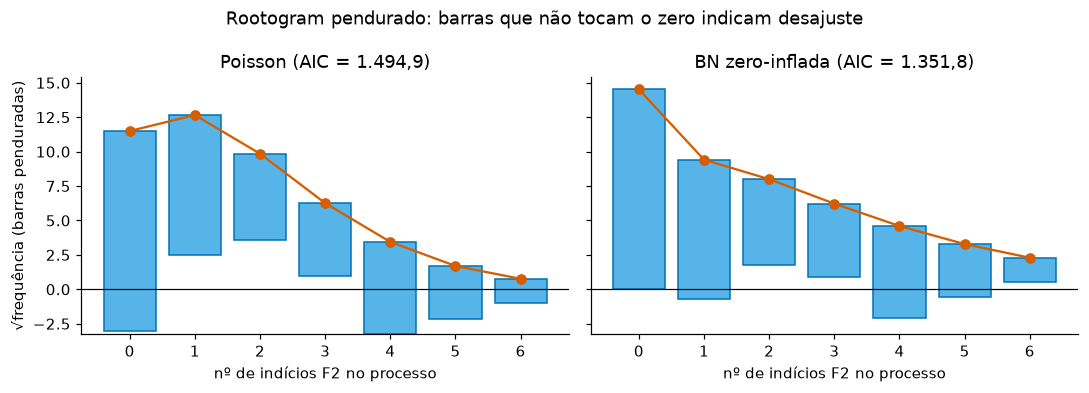

In [29]:
# 4.3 Modelos de contagem para n_F2 (444 elegíveis) e rootogram
import statsmodels.api as sm
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP, ZeroInflatedPoisson
cont = am.loc[~am.excluido_f1, 'n_F2'].astype(int).to_numpy()
media, var = cont.mean(), cont.var(ddof=1)
um = np.ones((len(cont), 1))
with C.capturar_avisos('modelos de contagem', AVISOS) as av_cont:
    ajustes = {'Poisson': sm.Poisson(cont, um).fit(disp=0),
               'Binomial negativa': sm.NegativeBinomial(cont, um).fit(disp=0, maxiter=500),
               'Poisson zero-inflado': ZeroInflatedPoisson(cont, um, exog_infl=um).fit(disp=0, maxiter=500),
               'BN zero-inflada': ZeroInflatedNegativeBinomialP(cont, um, exog_infl=um).fit(disp=0, maxiter=1000, method='bfgs')}
kmax = cont.max()
obs = np.bincount(cont, minlength=kmax + 1)
# probabilidades por fórmula fechada (o predict(which='prob') do statsmodels 0.14.6 quebra com o scipy 1.18)
x_ = np.arange(kmax + 1)
def _nb(mu, alfa):
    return stats.nbinom.pmf(x_, 1 / alfa, 1 / (1 + alfa * mu))
pr = ajustes['Poisson'].params; nb = ajustes['Binomial negativa'].params
zp = ajustes['Poisson zero-inflado'].params; zn = ajustes['BN zero-inflada'].params
w_zp, w_zn = 1 / (1 + np.exp(-zp[0])), 1 / (1 + np.exp(-zn[0]))
probs = {'Poisson': stats.poisson.pmf(x_, np.exp(pr[0])),
         'Binomial negativa': _nb(np.exp(nb[0]), nb[1]),
         'Poisson zero-inflado': (1 - w_zp) * stats.poisson.pmf(x_, np.exp(zp[1])) + w_zp * (x_ == 0),
         'BN zero-inflada': (1 - w_zn) * _nb(np.exp(zn[1]), zn[2]) + w_zn * (x_ == 0)}
# conferência: a soma das log-probabilidades reproduz a log-verossimilhança de cada ajuste
assert math.isclose(np.log(stats.poisson.pmf(cont, np.exp(pr[0]))).sum(), ajustes['Poisson'].llf, rel_tol=1e-8)
assert math.isclose(np.log(_nb(np.exp(nb[0]), nb[1])[cont]).sum(), ajustes['Binomial negativa'].llf, rel_tol=1e-6)
for nome in ('Poisson zero-inflado', 'BN zero-inflada'):
    assert math.isclose(np.log(probs[nome][cont]).sum(), ajustes[nome].llf, rel_tol=1e-5), nome
esperados = {nome: pp * len(cont) for nome, pp in probs.items()}
COMP_CONT = pd.DataFrame({'logL': {k: m.llf for k, m in ajustes.items()}, 'parâmetros': {k: len(m.params) for k, m in ajustes.items()},
                          'AIC': {k: m.aic for k, m in ajustes.items()}, 'BIC': {k: m.bic for k, m in ajustes.items()}})
COMP_CONT['zeros esperados'] = {k: e[0] for k, e in esperados.items()}
display(tabela_ptbr(COMP_CONT.reset_index().rename(columns={'index': 'modelo'})))
melhor_cont = COMP_CONT.AIC.idxmin()
lr_nb = 2 * (ajustes['Binomial negativa'].llf - ajustes['Poisson'].llf)
p_lr_nb = 0.5 * stats.chi2.sf(lr_nb, 1)          # parâmetro na fronteira: mistura 50:50 de χ²₀ e χ²₁

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, nome in zip(axs, ['Poisson', melhor_cont]):
    e = esperados[nome]
    x = np.arange(kmax + 1)
    ax.bar(x, np.sqrt(obs), bottom=np.sqrt(e) - np.sqrt(obs), color='#56B4E9', edgecolor='#0072B2', width=0.8)
    ax.plot(x, np.sqrt(e), 'o-', color='#D55E00')
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(f'{nome} (AIC = {fnum(ajustes[nome].aic, 1)})')
    ax.set_xlabel('nº de indícios F2 no processo')
axs[0].set_ylabel('√frequência (barras penduradas)')
fig.suptitle('Rootogram pendurado: barras que não tocam o zero indicam desajuste')
fig.tight_layout(); fig.savefig(FIGURAS / 'rootogram_nF2.png', dpi=150); plt.show()
V.update(cont_media=fnum(media, 2), cont_var=fnum(var, 2), cont_disp=fnum(var / media, 2), cont_zeros=fint(obs[0]),
         cont_zeros_p=fpct(obs[0] / len(cont), 1), cont_zeros_pois=fnum(esperados['Poisson'][0], 1),
         cont_melhor=melhor_cont, cont_lr_nb=fnum(lr_nb, 2), cont_p_nb=fp(p_lr_nb), cont_n=fint(len(cont)),
         cont_avisos='; '.join(av_cont.lista) or 'nenhum')

In [30]:
exibir('ds_contagem', r'''
**Leitura: os sinais vêm em blocos, e não ao acaso.** Nos {{cont_n}} elegíveis, o número de F2 por processo tem média {{cont_media}} e variância {{cont_var}}: o índice de dispersão é {{cont_disp}}. Num Poisson, ele seria próximo de um.

- **Excesso de zeros.** Há {{cont_zeros}} processos sem nenhum sinal ({{cont_zeros_p}}). O Poisson esperaria {{cont_zeros_pois}}.
- **Sobredispersão.** O teste de razão de verossimilhança Poisson × binomial negativa dá LR = {{cont_lr_nb}} ({{cont_p_nb}}, com a correção para parâmetro na fronteira).
- **Melhor ajuste.** Pelo AIC, é o modelo **{{cont_melhor}}**. Avisos de ajuste: {{cont_avisos}}.
- **No *rootogram*,** as barras do Poisson ficam penduradas longe do zero nos extremos: ele erra justamente nos zeros e nos processos com muitos sinais.

**Leitura jurídica.** O padrão confirma o que a MCA (Seção 7) e a LCA (Seção 10) vão mostrar: os sinais não são defeitos independentes que se somam. São **pacotes**, sobretudo o bloco documental F2_01/F2_02. Parece haver dois regimes, petições sem sinal e petições com um conjunto de sinais. É o que justifica tratar a classificação como mistura de classes latentes.
''')


**Leitura: os sinais vêm em blocos, e não ao acaso.** Nos 444 elegíveis, o número de F2 por processo tem média 1,21 e variância 2,40: o índice de dispersão é 1,98. Num Poisson, ele seria próximo de um.

- **Excesso de zeros.** Há 211 processos sem nenhum sinal (47,5%). O Poisson esperaria 132,2.
- **Sobredispersão.** O teste de razão de verossimilhança Poisson × binomial negativa dá LR = 140,99 (p < 0,001, com a correção para parâmetro na fronteira).
- **Melhor ajuste.** Pelo AIC, é o modelo **BN zero-inflada**. Avisos de ajuste: nenhum.
- **No *rootogram*,** as barras do Poisson ficam penduradas longe do zero nos extremos: ele erra justamente nos zeros e nos processos com muitos sinais.

**Leitura jurídica.** O padrão confirma o que a MCA (Seção 7) e a LCA (Seção 10) vão mostrar: os sinais não são defeitos independentes que se somam. São **pacotes**, sobretudo o bloco documental F2_01/F2_02. Parece haver dois regimes, petições sem sinal e petições com um conjunto de sinais. É o que justifica tratar a classificação como mistura de classes latentes.


### 4.4 Tempo até o desfecho: normalidade, Kaplan-Meier e log-rank

O tempo do ajuizamento ao desfecho da fase de conhecimento é uma **duração com censura**: o processo ainda em tramitação tem o tempo conhecido só até a data da coleta. Descartar os censurados encurta a distribuição. Por isso, a curva de sobrevivência é estimada por Kaplan-Meier e os grupos são comparados pelo log-rank. O efeito é a razão de riscos de Cox. A normalidade é testada só para mostrar que não se sustenta e que, por isso, comparar médias com o teste t seria inadequado.

**Família B** (1 teste): o tempo até o desfecho difere entre as classes? Teste: log-rank com 2 gl.

O tempo observado depende de encerramento e censura. A análise de sobrevivência separa quem teve desfecho de quem ainda estava em observação; por isso uma média simples dos tempos encerrados responderia a outra pergunta e poderia introduzir viés.

,index,estatística,p
0,Shapiro-Wilk,"0,715","p < 0,001"
1,D'Agostino-Pearson,"436,301","p < 0,001"
2,Anderson-Darling (p interpolado),"37,821","p = 0,0100"
3,Shapiro-Wilk em log(t),"0,850","p < 0,001"


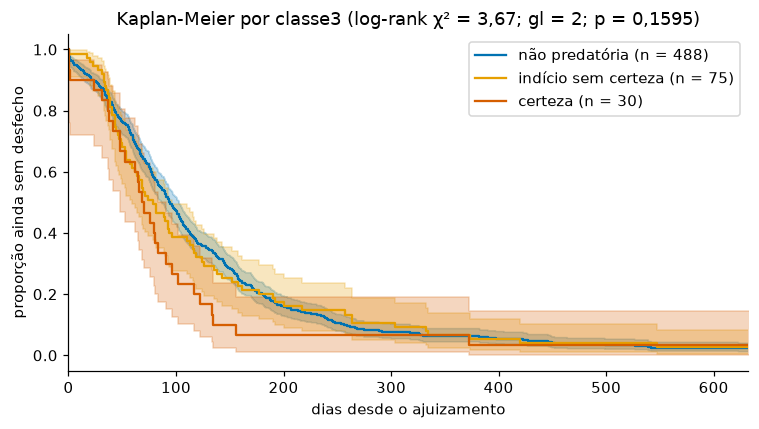

⚠ aviso [Cox tempo × classe3] DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datet


,covariate,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
0,classe3_indício sem certeza,"1,053","0,824","1,346","p = 0,6794"
1,classe3_certeza,"1,437","0,987","2,093","p = 0,0587"


In [31]:
# 4.4 Normalidade, Kaplan-Meier por classe3 e log-rank
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
td = dj[dj.t_desfecho.notna()].copy()
td['t'] = td['t_desfecho'].astype(float).clip(lower=0.5)       # desfecho no dia do ajuizamento → meio dia
td['e'] = td['e_desfecho'].astype(int)
obs_t = td.loc[td.e == 1, 't']
sw = stats.shapiro(obs_t); da = stats.normaltest(obs_t); ad = stats.anderson(obs_t, dist='norm', method='interpolate')
sw_log = stats.shapiro(np.log(obs_t))
NORM = pd.DataFrame({'estatística': [sw.statistic, da.statistic, ad.statistic, sw_log.statistic],
                     'p': [sw.pvalue, da.pvalue, ad.pvalue, sw_log.pvalue]},
                    index=['Shapiro-Wilk', "D'Agostino-Pearson", 'Anderson-Darling (p interpolado)',
                           'Shapiro-Wilk em log(t)'])
display(tabela_ptbr(NORM.reset_index(), casas=3, p=['p']))

fig, ax = plt.subplots(figsize=(7, 4))
medianas = {}
for nivel in NIVEIS_CLASSE3:
    g = td[td.classe3 == nivel]
    km = KaplanMeierFitter().fit(g.t, g.e, label=f'{nivel} (n = {len(g)})')
    km.plot_survival_function(ax=ax, ci_show=True, color=CORES_CLASSE3[nivel])
    from lifelines.utils import median_survival_times
    ic = median_survival_times(km.confidence_interval_)
    medianas[nivel] = (km.median_survival_time_, float(ic.iloc[0, 0]), float(ic.iloc[0, 1]))
lr = multivariate_logrank_test(td.t, td.classe3.astype(str), td.e)
ax.set_xlabel('dias desde o ajuizamento'); ax.set_ylabel('proporção ainda sem desfecho')
ax.set_title(f'Kaplan-Meier por classe3 (log-rank χ² = {fnum(lr.test_statistic, 2)}; gl = 2; {fp(lr.p_value)})')
ax.set_xlim(0, np.percentile(td.t, 98))
fig.tight_layout(); fig.savefig(FIGURAS / 'km_classe3.png', dpi=150); plt.show()

cox_df = pd.get_dummies(td[['t', 'e', 'classe3']], columns=['classe3'], drop_first=True, dtype=float)
with C.capturar_avisos('Cox tempo × classe3', AVISOS):
    cox = CoxPHFitter().fit(cox_df, 't', 'e')
hr = cox.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
display(tabela_ptbr(hr.reset_index(), casas=3, p=['p']))
V.update(t_n=fint(len(td)), t_eventos=fint(td.e.sum()), t_cens=fint((td.e == 0).sum()),
         sw_W=fnum(sw.statistic, 3), sw_p=fp(sw.pvalue), sw_log_p=fp(sw_log.pvalue),
         t_med_obs=fnum(obs_t.median(), 0), t_media_obs=fnum(obs_t.mean(), 0),
         lr_chi2=fnum(lr.test_statistic, 2), lr_p=fp(lr.p_value), lr_gl=str(lr.degrees_of_freedom),
         **{f'km_med_{i}': f'{fnum(m[0], 0)} dias (IC {fnum(m[1], 0)}–{fnum(m[2], 0)})' for i, m in enumerate(medianas.values())},
         **{f'hr_{i}': f'{fnum(r["exp(coef)"], 2)} (IC {fnum(r["exp(coef) lower 95%"], 2)}–{fnum(r["exp(coef) upper 95%"], 2)})'
            for i, (_, r) in enumerate(hr.iterrows(), start=1)})

In [32]:
exibir('ds_tempo', r'''
**Leitura: o tempo não é normal, e a classe não muda de forma demonstrável o ritmo do processo.** Dos {{t_n}} processos, {{t_eventos}} têm desfecho registrado e {{t_cens}} são censurados.

- **Normalidade.** A normalidade é rejeitada pelo Shapiro-Wilk (W = {{sw_W}}; {{sw_p}}) e também na escala logarítmica ({{sw_log_p}}). A média dos tempos observados ({{t_media_obs}} dias) fica longe da mediana ({{t_med_obs}} dias). Por isso, a comparação usa métodos de duração, e não o teste t.
- **Kaplan-Meier.** As medianas são:
  - não predatória: {{km_med_0}};
  - indício sem certeza: {{km_med_1}};
  - certeza: {{km_med_2}}.
- **Log-rank (família B).** χ² = {{lr_chi2}}; gl = {{lr_gl}}; {{lr_p}}.
- **Razões de risco de Cox**, contra "não predatória": indício sem certeza {{hr_1}}; certeza {{hr_2}}. Uma HR acima de um indica desfecho mais rápido.

**Consequência.** O tempo até o desfecho é um candidato fraco a variável discriminante para o classificador da população (Seção 10). Ele entra na LCA, mas não se espera que separe as classes.
''')


**Leitura: o tempo não é normal, e a classe não muda de forma demonstrável o ritmo do processo.** Dos 593 processos, 584 têm desfecho registrado e 9 são censurados.

- **Normalidade.** A normalidade é rejeitada pelo Shapiro-Wilk (W = 0,715; p < 0,001) e também na escala logarítmica (p < 0,001). A média dos tempos observados (122 dias) fica longe da mediana (90 dias). Por isso, a comparação usa métodos de duração, e não o teste t.
- **Kaplan-Meier.** As medianas são:
  - não predatória: 94 dias (IC 87–103);
  - indício sem certeza: 78 dias (IC 59–96);
  - certeza: 69 dias (IC 48–91).
- **Log-rank (família B).** χ² = 3,67; gl = 2; p = 0,1595.
- **Razões de risco de Cox**, contra "não predatória": indício sem certeza 1,05 (IC 0,82–1,35); certeza 1,44 (IC 0,99–2,09). Uma HR acima de um indica desfecho mais rápido.

**Consequência.** O tempo até o desfecho é um candidato fraco a variável discriminante para o classificador da população (Seção 10). Ele entra na LCA, mas não se espera que separe as classes.


## 5. Probabilidade Condicional (R1, R2)

### 5.1 O conceito

P(A | B) é a probabilidade de A **dado** B. É como dar um *zoom*: em vez de olhar todos os processos, olho só os que têm B e pergunto que fração deles também tem A. O espaço amostral passa a ser B (DEVORE, 2006, p. 67; DONOVAN; MICKEY, 2019, cap. 2, p. 22–23; FINKELSTEIN; LEVIN, 2015, p. 65):

$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad P(B)>0.$$

Toda a pesquisa da Hadja é uma cadeia de condicionais. A Fase III só é observada **dado** que o processo passou pelas Fases I e II. Por isso o **denominador** muda a resposta.

Uma probabilidade condicional exige nomear o evento e o grupo usado como denominador. As tabelas por linha e por coluna usam as mesmas contagens, mas respondem a perguntas diferentes: risco de indício entre expostos e frequência da exposição entre os classificados.

In [33]:
# 5.1 Tabelas 2×2 entre os 233 da Fase III: zoom por linha e por coluna
f3 = am[am.alguma_f2.astype(bool)].copy()
def tab2(df, x, y='indicio'):
    return pd.crosstab(df[x].astype(bool), df[y].astype(bool)).reindex(index=[True, False], columns=[True, False], fill_value=0)
CONDS = {}
for x in ('F2_02', 'F2_11'):
    t = tab2(f3, x)
    assert t.values.tolist() == GAB['cond'][f'tab_{x}_x_indicio_233']
    t_exib = t.rename(index={True: f'{x} = Sim', False: f'{x} = Não'}, columns={True: 'indício', False: 'não indício'})
    t_exib['total'] = t_exib.sum(axis=1); t_exib.loc['total'] = t_exib.sum(axis=0)
    display(t_exib)
    rr = (t.loc[True, True] / t.loc[True].sum()) / (t.loc[False, True] / t.loc[False].sum())
    se_lrr = math.sqrt(1 / t.loc[True, True] - 1 / t.loc[True].sum() + 1 / t.loc[False, True] - 1 / t.loc[False].sum())
    o = C.or_woolf(t.values)
    CONDS[x] = dict(lin_sim=t.loc[True, True] / t.loc[True].sum(), lin_nao=t.loc[False, True] / t.loc[False].sum(),
                    col_ind=t.loc[True, True] / t[True].sum(), col_nao=t.loc[True, False] / t[False].sum(),
                    RR=rr, RR_ic=(math.exp(math.log(rr) - C.Z95 * se_lrr), math.exp(math.log(rr) + C.Z95 * se_lrr)), **o)
C.confere('P(indício|F2_02)', CONDS['F2_02']['lin_sim'], GAB['cond']['P_ind_dado_F2_02'], registro=CONFERENCIAS)
C.confere('P(F2_02|indício)', CONDS['F2_02']['col_ind'], GAB['cond']['P_F2_02_dado_ind'], registro=CONFERENCIAS)
for x, d in CONDS.items():
    V.update({f'{x}_lin_sim': fnum(d['lin_sim'], 3), f'{x}_lin_nao': fnum(d['lin_nao'], 3),
              f'{x}_col_ind': fnum(d['col_ind'], 3), f'{x}_col_nao': fnum(d['col_nao'], 3),
              f'{x}_RR': fnum(d['RR'], 2), f'{x}_RR_ic': fic(*d['RR_ic']), f'{x}_OR': fnum(d['OR'], 1),
              f'{x}_OR_ic': fic(*d['ic'], casas=1)})

indicio,indício,não indício,total
F2_02,,,
F2_02 = Sim,85,11,96
F2_02 = Não,20,117,137
total,105,128,233


indicio,indício,não indício,total
F2_11,,,
F2_11 = Sim,63,36,99
F2_11 = Não,42,92,134
total,105,128,233


In [34]:
exibir('pc_tabelas', r'''
**Leitura: o zoom muda conforme a direção.** Entre os {{funil_fase3}} da Fase III:

| | Lendo por linha: P(indício \| sinal) | Lendo por coluna: P(sinal \| indício) |
|---|---|---|
| F2_02 (sem documentos essenciais) | com o sinal: {{F2_02_lin_sim}}; sem o sinal: {{F2_02_lin_nao}} | entre indícios: {{F2_02_col_ind}}; entre não indícios: {{F2_02_col_nao}} |
| F2_11 (advogado de fora da comarca) | com o sinal: {{F2_11_lin_sim}}; sem o sinal: {{F2_11_lin_nao}} | entre indícios: {{F2_11_col_ind}}; entre não indícios: {{F2_11_col_nao}} |

- **Por linha** é a pergunta do juiz na triagem: "vejo F2_02; quão provável é a predação?".
- **Por coluna** é uma medida de sensibilidade do sinal: "entre os predatórios, quantos têm F2_02?".
- **Efeito.** Com F2_02, o risco de indício é {{F2_02_RR}} vezes maior (RR, IC 95% {{F2_02_RR_ic}}). Em chances, o OR é {{F2_02_OR}} {{F2_02_OR_ic}}. Para F2_11: RR = {{F2_11_RR}} {{F2_11_RR_ic}}; OR = {{F2_11_OR}} {{F2_11_OR_ic}}.
- **OR não é risco relativo.** Como o indício é frequente na Fase III, o OR exagera muito o RR. "OR = {{F2_02_OR}}" **não** quer dizer "{{F2_02_OR}} vezes mais provável".

**Não é causa.** "Dado F2_02" não quer dizer que a falta de documentos *cause* a predação. Os dois podem ser marcas do mesmo modo de produção em série das petições.
''')


**Leitura: o zoom muda conforme a direção.** Entre os 233 da Fase III:

| | Lendo por linha: P(indício \| sinal) | Lendo por coluna: P(sinal \| indício) |
|---|---|---|
| F2_02 (sem documentos essenciais) | com o sinal: 0,885; sem o sinal: 0,146 | entre indícios: 0,810; entre não indícios: 0,086 |
| F2_11 (advogado de fora da comarca) | com o sinal: 0,636; sem o sinal: 0,313 | entre indícios: 0,600; entre não indícios: 0,281 |

- **Por linha** é a pergunta do juiz na triagem: "vejo F2_02; quão provável é a predação?".
- **Por coluna** é uma medida de sensibilidade do sinal: "entre os predatórios, quantos têm F2_02?".
- **Efeito.** Com F2_02, o risco de indício é 6,07 vezes maior (RR, IC 95% [4,02; 9,15]). Em chances, o OR é 45,2 [20,6; 99,3]. Para F2_11: RR = 2,03 [1,52; 2,72]; OR = 3,8 [2,2; 6,6].
- **OR não é risco relativo.** Como o indício é frequente na Fase III, o OR exagera muito o RR. "OR = 45,2" **não** quer dizer "45,2 vezes mais provável".

**Não é causa.** "Dado F2_02" não quer dizer que a falta de documentos *cause* a predação. Os dois podem ser marcas do mesmo modo de produção em série das petições.


O mesmo número de indícios produz proporções diferentes entre sorteados, elegíveis e casos que alcançaram a Fase III. O cálculo torna visível esse efeito de seleção e ajuda a evitar a troca indevida entre P(A dado B) e P(B dado A).

,pergunta,k,n,probabilidade,IC Wilson inf.,IC Wilson sup.
0,P(indício) entre todos os sorteados,105,595,"0,1765","0,1479","0,2091"
1,P(indício | elegível),105,444,"0,2365","0,1993","0,2782"
2,P(indício | chegou à Fase III),105,233,"0,4506","0,3881","0,5148"
3,P(certeza | indício),30,105,"0,2857","0,2081","0,3785"
4,P(indício | certeza),30,30,"1,0000","0,8865","1,0000"


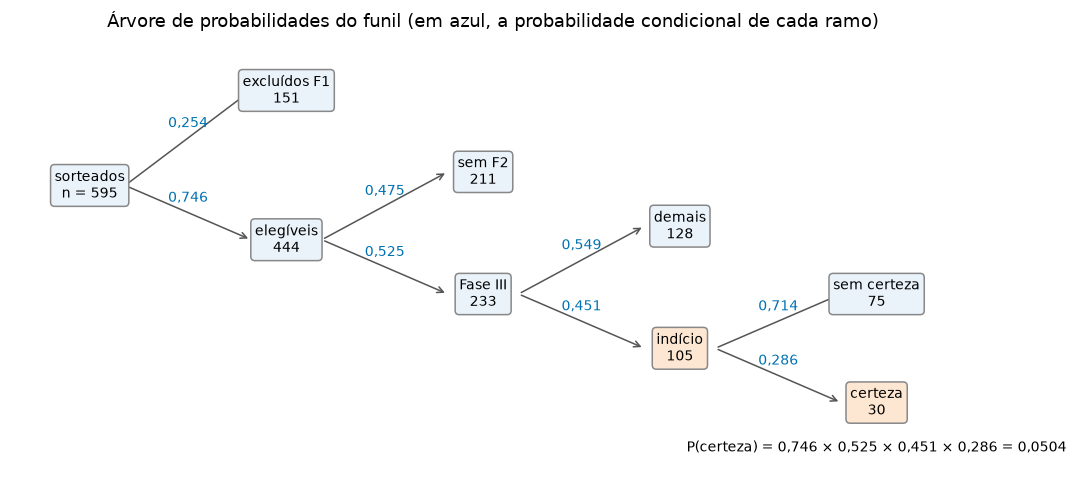

In [35]:
# 5.2 O mesmo evento com quatro denominadores; P(A|B) ≠ P(B|A); independência
n_el, n_f3 = int((~am.excluido_f1).sum()), int(am.alguma_f2.sum())
DENOM = pd.DataFrame([
    ('P(indício) entre todos os sorteados', funil['indicio'], funil['n']),
    ('P(indício | elegível)', funil['indicio'], n_el),
    ('P(indício | chegou à Fase III)', funil['indicio'], n_f3),
    ('P(certeza | indício)', funil['certeza'], funil['indicio']),
    ('P(indício | certeza)', funil['certeza'], funil['certeza'])], columns=['pergunta', 'k', 'n'])
DENOM['probabilidade'] = DENOM.k / DENOM.n
DENOM[['IC Wilson inf.', 'IC Wilson sup.']] = [C.wilson(k, n) for k, n in zip(DENOM.k, DENOM.n)]
display(tabela_ptbr(DENOM, casas=4))
for chave, val in [('P_ind_595', DENOM.probabilidade[0]), ('P_ind_dado_elegivel', DENOM.probabilidade[1]),
                   ('P_ind_dado_f3', DENOM.probabilidade[2]), ('P_cert_dado_ind', DENOM.probabilidade[3])]:
    C.confere(chave, val, GAB['cond'][chave], registro=CONFERENCIAS)
p_f2_02 = am['F2_02'].fillna(False).astype(bool).mean()
p_inter = (am['F2_02'].fillna(False).astype(bool) & am.indicio.astype(bool)).mean()
C.confere('P(F2_02 ∩ indício)', p_inter, GAB['cond']['P_F2_02_e_ind_595'], registro=CONFERENCIAS)
V.update(den_595=fnum(DENOM.probabilidade[0], 4), den_444=fnum(DENOM.probabilidade[1], 4),
         den_233=fnum(DENOM.probabilidade[2], 4), cert_ind=fnum(DENOM.probabilidade[3], 4),
         n_elegiveis=fint(n_el), p_f2_02_595=fnum(p_f2_02, 4), p_produto=fnum(p_f2_02 * DENOM.probabilidade[0], 4),
         p_inter=fnum(p_inter, 4), razao_indep=fnum(p_inter / (p_f2_02 * DENOM.probabilidade[0]), 1))

# árvore de probabilidades do funil
fig, ax = plt.subplots(figsize=(10, 4.6)); ax.axis('off')
nos = {'raiz': (0, 0.5, f"sorteados\nn = {funil['n']}"),
       'exc': (1, 0.85, f"excluídos F1\n{funil['excluidos_f1']}"), 'el': (1, 0.3, f"elegíveis\n{funil['fase2']}"),
       'sem': (2, 0.55, f"sem F2\n{funil['sem_f2']}"), 'f3': (2, 0.1, f"Fase III\n{funil['fase3']}"),
       'dem': (3, 0.35, f"demais\n{funil['demais_f3']}"), 'ind': (3, -0.1, f"indício\n{funil['indicio']}"),
       'so': (4, 0.1, f"sem certeza\n{funil['so_indicio']}"), 'cer': (4, -0.3, f"certeza\n{funil['certeza']}")}
arestas = [('raiz', 'exc', funil['excluidos_f1'] / funil['n']), ('raiz', 'el', funil['fase2'] / funil['n']),
           ('el', 'sem', funil['sem_f2'] / funil['fase2']), ('el', 'f3', funil['fase3'] / funil['fase2']),
           ('f3', 'dem', funil['demais_f3'] / funil['fase3']), ('f3', 'ind', funil['indicio'] / funil['fase3']),
           ('ind', 'so', funil['so_indicio'] / funil['indicio']), ('ind', 'cer', funil['certeza'] / funil['indicio'])]
for a_, b_, pr_ in arestas:
    (x0, y0, _), (x1, y1, _) = nos[a_], nos[b_]
    ax.annotate('', (x1 - 0.18, y1), (x0 + 0.18, y0), arrowprops=dict(arrowstyle='->', color='#555'))
    ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.04, fnum(pr_, 3), ha='center', fontsize=9, color='#0072B2')
for k_, (x, y, t) in nos.items():
    ax.text(x, y, t, ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round', fc='#FDE7D3' if k_ in ('ind', 'cer') else '#EAF2FA', ec='#888'))
ax.text(4.0, -0.48, f"P(certeza) = {' × '.join(fnum(p, 3) for _, _, p in [arestas[1], arestas[3], arestas[5], arestas[7]])}"
        f" = {fnum(funil['certeza'] / funil['n'], 4)}", ha='center', fontsize=9)
ax.set_xlim(-0.4, 4.5); ax.set_ylim(-0.6, 1.05)
ax.set_title('Árvore de probabilidades do funil (em azul, a probabilidade condicional de cada ramo)')
fig.tight_layout(); fig.savefig(FIGURAS / 'arvore_funil.png', dpi=150); plt.show()

In [36]:
exibir('pc_denominadores', r'''
**Leitura: o mesmo evento, quatro respostas.** A probabilidade de indício é:

- {{den_595}} entre todos os sorteados;
- {{den_444}} entre os {{n_elegiveis}} elegíveis;
- {{den_233}} entre os que chegaram à Fase III.

Toda afirmação sobre "a proporção de lides predatórias" precisa dizer **qual** denominador usa. A Seção 10 do notebook do professor compara o terceiro número com os 30% da NT CIJMG, que se referem a todo o fluxo de dois assuntos (A-23). É uma comparação de denominadores diferentes.

- **P(A | B) ≠ P(B | A).** P(indício | certeza) vale um, porque toda certeza é indício. P(certeza | indício) = {{cert_ind}}. Confundir as duas é a condicional transposta (Seção 6.4).
- **Independência.** Nos {{funil_n}}, P(F2_02) = {{p_f2_02_595}} e P(indício) = {{den_595}}. Se fossem independentes, P(F2_02 ∩ indício) seria o produto, {{p_produto}}. O observado é {{p_inter}}, {{razao_indep}} vezes mais: os eventos são fortemente **dependentes**.
- **A árvore** mostra a regra do produto: a probabilidade de uma folha é o produto das condicionais do caminho.
''')


**Leitura: o mesmo evento, quatro respostas.** A probabilidade de indício é:

- 0,1765 entre todos os sorteados;
- 0,2365 entre os 444 elegíveis;
- 0,4506 entre os que chegaram à Fase III.

Toda afirmação sobre "a proporção de lides predatórias" precisa dizer **qual** denominador usa. A Seção 10 do notebook do professor compara o terceiro número com os 30% da NT CIJMG, que se referem a todo o fluxo de dois assuntos (A-23). É uma comparação de denominadores diferentes.

- **P(A | B) ≠ P(B | A).** P(indício | certeza) vale um, porque toda certeza é indício. P(certeza | indício) = 0,2857. Confundir as duas é a condicional transposta (Seção 6.4).
- **Independência.** Nos 595, P(F2_02) = 0,1613 e P(indício) = 0,1765. Se fossem independentes, P(F2_02 ∩ indício) seria o produto, 0,0285. O observado é 0,1429, 5,0 vezes mais: os eventos são fortemente **dependentes**.
- **A árvore** mostra a regra do produto: a probabilidade de uma folha é o produto das condicionais do caminho.


### 5.2 Testes de associação dos sinais F2 com o indício

**Família C**, declarada antes de testar: cada F2 com pelo menos um "Sim" na Fase III está associada ao indício? Universo: os 233 da Fase III, onde o indício foi de fato avaliado. O teste é o **Fisher exato**: há caselas com esperado menor que 5, e o mesmo teste vale para toda a família. O efeito é o OR, com IC de Woolf (Haldane quando há zero). A correção é de Holm. Ver FRIENDLY; MEYER (2016, p. 124) e FÁVERO; BELFIORE (2017, p. 441–442).

Os sinais F2 são comparados com o indício apenas onde foram avaliados. A correção para múltiplas comparações reduz falsas descobertas quando se examinam muitos sinais; comparações escolhidas após observar os dados são identificadas como exploratórias.

In [37]:
# 5.3 Família C (F2 × indício nos 233) e o 7º JEC × demais (comparação escolhida depois de ver os dados)
lin = []
for c in F2:
    t = tab2(f3, c)
    if t.loc[True].sum() == 0:
        continue
    o = C.or_woolf(t.values)
    lin.append(dict(variavel=c, rotulo=ROTULOS[c], n_sim=int(t.loc[True].sum()), indicio_entre_sim=int(t.loc[True, True]),
                    OR=o['OR'], ic_inf=o['ic'][0], ic_sup=o['ic'][1], haldane=o['haldane'], p=stats.fisher_exact(t.values)[1]))
FAM_C = pd.DataFrame(lin)
FAM_C['p (Holm)'] = C.holm(FAM_C.p)
FAM_C = FAM_C.sort_values('p')
display(tabela_ptbr(FAM_C, p=['p', 'p (Holm)']))
for g in GAB['familia_F2']:
    lin_ = FAM_C.set_index('variavel').loc[g['var']]
    C.confere(f"OR {g['var']}", lin_.OR, g['OR'], registro=CONFERENCIAS)
    C.confere(f"Holm {g['var']}", lin_['p (Holm)'], g['p_holm'], registro=CONFERENCIAS)
sig = FAM_C[FAM_C['p (Holm)'] < ALFA]
# números publicados por terceiros, citados para conferência (A-20, A-21)
PUBLICADOS = dict(or_f2_01=39.8, or_f2_11=11.4, chi2_f2_14=23.44)
k7, n7 = int(am.loc[am.jec == 7, 'indicio'].sum()), int((am.jec == 7).sum())
ko, no = int(am.loc[am.jec != 7, 'indicio'].sum()), int((am.jec != 7).sum())
dif7 = k7 / n7 - ko / no
se7 = math.sqrt(k7 / n7 * (1 - k7 / n7) / n7 + ko / no * (1 - ko / no) / no)
p7 = stats.fisher_exact([[k7, n7 - k7], [ko, no - ko]])[1]
V.update(C_n_testes=fint(len(FAM_C)), C_n_sig=fint(len(sig)), C_sig=', '.join(sig.variavel),
         **{f'C_{r.variavel}_OR': fnum(r.OR, 2) for r in FAM_C.itertuples()},
         **{f'C_{r.variavel}_ic': fic(r.ic_inf, r.ic_sup) for r in FAM_C.itertuples()},
         **{f'C_{r.variavel}_p': fp(r.p_holm) for r in FAM_C.rename(columns={'p (Holm)': 'p_holm'}).itertuples()},
         jec7_k=fint(k7), jec7_n=fint(n7), jec7_p=fpct(k7 / n7, 1), demais_p=fpct(ko / no, 1),
         jec7_dif=fnum(100 * dif7, 1), jec7_dif_ic=fic(100 * (dif7 - C.Z95 * se7), 100 * (dif7 + C.Z95 * se7), 1),
         jec7_fisher=fp(p7), prof_or=f"{fnum(PUBLICADOS['or_f2_01'], 1)} e {fnum(PUBLICADOS['or_f2_11'], 1)}",
         prof_chi2_f214=fnum(PUBLICADOS['chi2_f2_14'], 2), jec7_bonf=fp(min(1, 14 * p7)), jec_global_p=V['A_jec_p'])

,variavel,rotulo,n_sim,indicio_entre_sim,OR,ic_inf,ic_sup,haldane,p,p (Holm)
1,F2_02,Ausência de documentos essenciais,96,85,"45,20","20,58","99,30",False,"p < 0,001","p < 0,001"
0,F2_01,Petição vaga/genérica,98,85,"37,60","17,72","79,79",False,"p < 0,001","p < 0,001"
9,F2_11,Advogado fora da comarca,99,63,"3,83","2,21","6,63",False,"p < 0,001","p < 0,001"
5,F2_06,Documentos incompletos/ilegíveis,101,53,"1,70","1,01","2,87",False,"p = 0,0626","p = 0,6265"
11,F2_14,Desistência/abandono após indeferimento de lim...,17,11,"2,38","0,85","6,67",False,"p = 0,1278",p = 1
3,F2_04,Pedido de dispensa de audiência,18,10,"1,58","0,60","4,16",False,"p = 0,4607",p = 1
12,F2_17,Contrato de honorários abusivo,3,2,"2,47","0,22","27,58",False,"p = 0,5899",p = 1
8,F2_10,Procuração irregular (assinatura digital),78,36,"1,07","0,62","1,84",False,"p = 0,8892",p = 1
7,F2_09,Procuração incompleta,15,7,"1,07","0,38","3,06",False,p = 1,p = 1
6,F2_08,Demanda idêntica não declarada,2,1,"1,22","0,08","19,76",False,p = 1,p = 1


In [38]:
exibir('pc_familia_f2', r'''
**Leitura: só três sinais se associam ao indício depois da correção.** Na família C ({{C_n_testes}} testes), {{C_n_sig}} sobrevivem ao Holm: {{C_sig}}.

| Sinal | OR [IC 95%] | p (Holm) |
|---|---|---|
| F2_02 sem documentos essenciais | {{C_F2_02_OR}} {{C_F2_02_ic}} | {{C_F2_02_p}} |
| F2_01 petição genérica | {{C_F2_01_OR}} {{C_F2_01_ic}} | {{C_F2_01_p}} |
| F2_11 advogado de fora | {{C_F2_11_OR}} {{C_F2_11_ic}} | {{C_F2_11_p}} |
| F2_06 documentos ilegíveis | {{C_F2_06_OR}} {{C_F2_06_ic}} | {{C_F2_06_p}} |
| F2_14 desistência após liminar | {{C_F2_14_OR}} {{C_F2_14_ic}} | {{C_F2_14_p}} |

- **Divergências com a publicação.** Os OR divergentes ({{prof_or}}) estão só no plano do professor, e não na monografia (A-21). O χ² "{{prof_chi2_f214}}" da F2_14 é o χ² com correção de Yates calculado sobre os {{funil_n}}. Nessa base, a associação é **artefato do funil**: quem tem F2_14 entra na Fase III por construção (A-20, B-15). Nos {{funil_fase3}}, a F2_14 não se associa ao indício.
- **O 7º JEC.** Tem {{jec7_k}} indícios em {{jec7_n}} processos ({{jec7_p}}), contra {{demais_p}} nos demais: diferença de {{jec7_dif}} p.p. (IC 95% {{jec7_dif_ic}}); Fisher {{jec7_fisher}}. Mas o 7º foi escolhido **depois** de olhar os dados. Com Bonferroni pelos 14 JEC, o p vira {{jec7_bonf}}, e o teste global da família A não rejeita a homogeneidade ({{jec_global_p}}). **Conclusão:** é um sinal que merece investigação, e não uma diferença demonstrada.
''')


**Leitura: só três sinais se associam ao indício depois da correção.** Na família C (13 testes), 3 sobrevivem ao Holm: F2_02, F2_01, F2_11.

| Sinal | OR [IC 95%] | p (Holm) |
|---|---|---|
| F2_02 sem documentos essenciais | 45,20 [20,58; 99,30] | p < 0,001 |
| F2_01 petição genérica | 37,60 [17,72; 79,79] | p < 0,001 |
| F2_11 advogado de fora | 3,83 [2,21; 6,63] | p < 0,001 |
| F2_06 documentos ilegíveis | 1,70 [1,01; 2,87] | p = 0,6265 |
| F2_14 desistência após liminar | 2,38 [0,85; 6,67] | p = 1 |

- **Divergências com a publicação.** Os OR divergentes (39,8 e 11,4) estão só no plano do professor, e não na monografia (A-21). O χ² "23,44" da F2_14 é o χ² com correção de Yates calculado sobre os 595. Nessa base, a associação é **artefato do funil**: quem tem F2_14 entra na Fase III por construção (A-20, B-15). Nos 233, a F2_14 não se associa ao indício.
- **O 7º JEC.** Tem 14 indícios em 39 processos (35,9%), contra 16,4% nos demais: diferença de 19,5 p.p. (IC 95% [4,2; 34,9]); Fisher p = 0,0041. Mas o 7º foi escolhido **depois** de olhar os dados. Com Bonferroni pelos 14 JEC, o p vira p = 0,0580, e o teste global da família A não rejeita a homogeneidade (p = 0,2248). **Conclusão:** é um sinal que merece investigação, e não uma diferença demonstrada.


## 6. Teorema de Bayes, Termo a Termo (R3–R9)

### 6.1 Enunciado na notação do professor (R3, R4)

Seja 𝑆 o espaço amostral e 𝐴₁, …, 𝐴ₙ hipóteses que formam uma **partição** de 𝑆, isto é, são mutuamente exclusivas e exaustivas. Dada a evidência 𝐵 (NEVES, 2023, cap. 5, p. 92–101):

$$P(A_k\mid B)=\frac{P(A_k)\,P(B\mid A_k)}{\sum_{i=1}^{n}P(A_i)\,P(B\mid A_i)}.$$

| Termo | Nome | Pergunta | Neste caso |
|---|---|---|---|
| P(𝐴ₖ) | **priori** | o que eu acreditava antes dos dados novos? | estado da arte (R5, R9) |
| P(𝐵 \| 𝐴ₖ) | **verossimilhança** | se 𝐴ₖ fosse verdadeira, quão provável seria observar 𝐵? | proporção do desfecho entre os processos de cada hipótese (R6) |
| Σ P(𝐴ᵢ)P(𝐵 \| 𝐴ᵢ) | **probabilidade total**, o "fator de normalização" | quão provável é observar 𝐵, somando todas as hipóteses? | R7 |
| P(𝐴ₖ \| 𝐵) | **posteriori** | o que devo acreditar depois dos dados? | R8 |

É a figura 5.4 de Donovan & Mickey (2019, cap. 5, p. 55) que o professor reproduz (NEVES, 2023, p. 101). A partição mais simples é 𝐻₀ = 𝐴 e 𝐻ₐ = ∼𝐴 (NEVES, 2023, p. 100). Ela é necessária porque o denominador **soma** as hipóteses: se elas se sobrepusessem, a soma contaria duas vezes; se não cobrissem 𝑆, as posterioris não somariam 1 (DONOVAN; MICKEY, 2019, p. 47).

**Dois pares H₀ × Hₐ (decisão D2).**

| | Nível do **processo** (principal) | Nível da **prevalência** (complemento) |
|---|---|---|
| espaço particionado | o espaço amostral (os processos) | o espaço dos valores de θ, isto é, [0, 1] |
| Hₐ | este processo é predatório (indício, classe3 ≥ 1) | θ < 0,30 |
| H₀ | este processo não é predatório | θ ≥ 0,30 (NT CIJMG 01/2022) |
| dado | o desfecho do processo no DataJud (Seção 3) | as ocorrências de indício na amostra |
| ferramenta | Bayes discreto | Beta-Binomial |

### 6.2 A priori (R5, R9): de onde vem

A revisão de escopo da Hadja (6 bases, out/2024–out/2025, 12 achados) é **conceitual**: mapeia o conceito de litigância predatória e não traz nenhum percentual (B-1). Os números que podem virar priori vêm do **levantamento documental** que acompanha a revisão. Eles são a *relevant background information* (*I*) no sentido de Bozza, Taroni e Biedermann (2022, p. 5–6). Taroni et al. (2010, p. 35) admitem frequências conhecidas como base de uma priori subjetiva.

| Fonte | O que diz | Uso (D1) |
|---|---|---|
| NT CIJMG 01/2022 | "pelo menos 30%" da distribuição de **dois assuntos**, em MG, com dados de 2020 | priori principal 0,30 |
| TJPE, 1ª Vara de Araripina | 30% das demandas, de um único advogado | reforça 0,30 |
| TJPE, Vara de Ipubi | 50% das ações extintas | cenário extremo: mede extinção, não predação |
| princípio da indiferença | nenhum conhecimento | 0,50 (sensibilidade) |
| cenário baixo | — | 0,10 (sensibilidade) |

A própria amostra (17,65%) aparece só como **referência**, e não como priori: usar os mesmos dados na priori e na verossimilhança seria contá-los duas vezes (DONOVAN; MICKEY, 2019, p. 47).

Bayes combina uma crença inicial com a frequência de um desfecho sob hipóteses concorrentes. As verossimilhanças vêm da amostra e o denominador normaliza as possibilidades. A posteriori apresentada é um exemplo condicionado à priori escolhida, não um diagnóstico validado para um processo individual.

,dado,kA,nA,k0,n0,lik_Ha,lik_H0,RV,RV_ic_inf,RV_ic_sup,p_fisher,p (Holm)
0,extinção sem mérito,31,105,111,488,"0,2952","0,2275","1,2980","0,9260","1,8195","p = 0,1651","p = 0,6603"
1,acordo,7,105,58,488,"0,0667","0,1189","0,5609","0,2635","1,1938","p = 0,1666","p = 0,6603"
2,sentença de mérito,65,105,312,488,"0,6190","0,6393","0,9683","0,8217","1,1410","p = 0,7376","p = 0,9833"
3,"extinção por iniciativa do autor (desistência,...",4,105,31,488,"0,0381","0,0635","0,5997","0,2163","1,6626","p = 0,4917","p = 0,9833"


,dado,priori,P_Ha,prob_total,posteriori,chance_priori,chance_post,razao_chances
0,extinção sem mérito,"baixa (0,10)","0,1000","0,2342","0,1260","0,1111","0,1442","1,2980"
1,extinção sem mérito,"amostra, só referência (0,1765)","0,1765","0,2394","0,2176","0,2143","0,2781","1,2980"
2,extinção sem mérito,"CIJMG/Araripina (0,30): principal","0,3000","0,2478","0,3574","0,4286","0,5563","1,2980"
3,extinção sem mérito,"indiferença (0,50)","0,5000","0,2613","0,5648","1,0000","1,2980","1,2980"
4,acordo,"baixa (0,10)","0,1000","0,1136","0,0587","0,1111","0,0623","0,5609"
5,acordo,"amostra, só referência (0,1765)","0,1765","0,1096","0,1073","0,2143","0,1202","0,5609"
6,acordo,"CIJMG/Araripina (0,30): principal","0,3000","0,1032","0,1938","0,4286","0,2404","0,5609"
7,acordo,"indiferença (0,50)","0,5000","0,0928","0,3594","1,0000","0,5609","0,5609"
8,sentença de mérito,"baixa (0,10)","0,1000","0,6373","0,0971","0,1111","0,1076","0,9683"
9,sentença de mérito,"amostra, só referência (0,1765)","0,1765","0,6358","0,1718","0,2143","0,2075","0,9683"


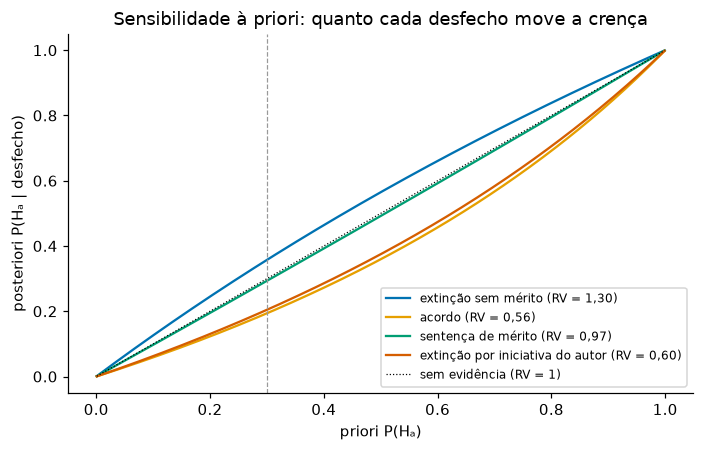

In [39]:
# 6.1 Bayes no nível do processo: verossimilhanças pelo desfecho completo (Seção 3), probabilidade total, posteriori
bay = dj[dj.desfecho.notna()].copy()
bay['Ha'] = bay.classe3_cod.astype(int) >= 1
nA, n0 = int(bay.Ha.sum()), int((~bay.Ha).sum())
DADOS_D = {'extinção sem mérito': bay.desfecho == 'extinção sem mérito', 'acordo': bay.desfecho == 'acordo',
           'sentença de mérito': bay.desfecho == 'mérito',
           'extinção por iniciativa do autor (desistência, abandono, ausência)': bay.extincao_iniciativa_autor.astype(bool)}
PRIORIS = {'baixa (0,10)': 0.10, 'amostra, só referência (0,1765)': funil['indicio'] / funil['n'],
           'CIJMG/Araripina (0,30): principal': 0.30, 'indiferença (0,50)': 0.50}
VER, POST = [], []
for nome, e in DADOS_D.items():
    kA, k0 = int(e[bay.Ha].sum()), int(e[~bay.Ha].sum())
    lA, l0 = kA / nA, k0 / n0
    rv = lA / l0
    se_lrv = math.sqrt(1 / kA - 1 / nA + 1 / k0 - 1 / n0) if kA and k0 else np.nan
    VER.append(dict(dado=nome, kA=kA, nA=nA, k0=k0, n0=n0, lik_Ha=lA, lik_H0=l0, RV=rv,
                    RV_ic_inf=math.exp(math.log(rv) - C.Z95 * se_lrv), RV_ic_sup=math.exp(math.log(rv) + C.Z95 * se_lrv),
                    p_fisher=stats.fisher_exact([[kA, nA - kA], [k0, n0 - k0]])[1]))
    for pn, pri in PRIORIS.items():
        tot = lA * pri + l0 * (1 - pri)
        post = lA * pri / tot
        POST.append(dict(dado=nome, priori=pn, P_Ha=pri, prob_total=tot, posteriori=post,
                         chance_priori=pri / (1 - pri), chance_post=post / (1 - post),
                         razao_chances=(post / (1 - post)) / (pri / (1 - pri))))
VER, POST = pd.DataFrame(VER), pd.DataFrame(POST)
VER['p (Holm)'] = C.holm(VER.p_fisher)          # família D: os 4 desfechos como evidência
display(tabela_ptbr(VER, casas=4, p=['p_fisher', 'p (Holm)']))
display(tabela_ptbr(POST, casas=4))
# a forma de chances: a razão chance posteriori / chance priori é a RV, qualquer que seja a priori
assert np.allclose(POST.groupby('dado').razao_chances.agg(['min', 'max']).pipe(lambda d: d['max'] - d['min']), 0)
# conferência com a apostila (o desfecho completo coincide no nível do grupo; Seção 3)
vs = VER.set_index('dado')
C.confere('RV extinção', vs.loc['extinção sem mérito', 'RV'], GAB['datajud']['bayes_sem_merito']['RV'], registro=CONFERENCIAS)
C.confere('RV acordo', vs.loc['acordo', 'RV'], GAB['datajud']['bayes_acordo']['RV'], registro=CONFERENCIAS)
ps = POST.set_index(['dado', 'priori'])
C.confere('posteriori 0,30 | extinção', ps.loc[('extinção sem mérito', 'CIJMG/Araripina (0,30): principal'), 'posteriori'],
          GAB['datajud']['bayes_sem_merito']['post']['cijmg_30']['posteriori'], registro=CONFERENCIAS)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
grade = np.linspace(0.001, 0.999, 300)
for (nome, r), cor in zip(vs.iterrows(), OKABE):
    ax.plot(grade, r.lik_Ha * grade / (r.lik_Ha * grade + r.lik_H0 * (1 - grade)), color=cor,
            label=f"{nome.split(' (')[0]} (RV = {fnum(r.RV, 2)})")
ax.plot(grade, grade, 'k:', lw=0.8, label='sem evidência (RV = 1)')
ax.axvline(0.30, color='#999', lw=0.8, ls='--')
ax.set_xlabel('priori P(Hₐ)'); ax.set_ylabel('posteriori P(Hₐ | desfecho)'); ax.legend(fontsize=8)
ax.set_title('Sensibilidade à priori: quanto cada desfecho move a crença')
fig.tight_layout(); fig.savefig(FIGURAS / 'bayes_sensibilidade_priori.png', dpi=150); plt.show()

def _v(dado, pri, col):
    return ps.loc[(dado, pri), col]
P03 = 'CIJMG/Araripina (0,30): principal'
V.update(bay_nA=fint(nA), bay_n0=fint(n0),
         **{f'bay_{i}_{c}': fnum(vs.iloc[i][c], 4) for i in range(len(vs)) for c in ('lik_Ha', 'lik_H0')},
         **{f'bay_{i}_k': f'{fint(vs.iloc[i].kA)}/{fint(nA)} e {fint(vs.iloc[i].k0)}/{fint(n0)}' for i in range(len(vs))},
         **{f'bay_{i}_RV': fnum(vs.iloc[i].RV, 2) for i in range(len(vs))},
         **{f'bay_{i}_RVic': fic(vs.iloc[i].RV_ic_inf, vs.iloc[i].RV_ic_sup) for i in range(len(vs))},
         **{f'bay_{i}_holm': fp(vs.iloc[i]['p (Holm)']) for i in range(len(vs))},
         **{f'bay_{i}_tot03': fnum(_v(vs.index[i], P03, 'prob_total'), 4) for i in range(len(vs))},
         **{f'bay_{i}_post03': fnum(_v(vs.index[i], P03, 'posteriori'), 3) for i in range(len(vs))},
         **{f'bay_{i}_post01': fnum(_v(vs.index[i], 'baixa (0,10)', 'posteriori'), 3) for i in range(len(vs))},
         **{f'bay_{i}_post05': fnum(_v(vs.index[i], 'indiferença (0,50)', 'posteriori'), 3) for i in range(len(vs))},
         chance_pri03=fnum(0.3 / 0.7, 3), chance_post03=fnum(_v(vs.index[0], P03, 'chance_post'), 3))

In [40]:
exibir('by_processo', r'''
**Leitura (R6–R8): o desfecho é evidência fraca.** Hₐ = indício ({{bay_nA}} processos); H₀ = não indício ({{bay_n0}}).

| Dado D | P(D \| Hₐ) | P(D \| H₀) | RV [IC 95%] | p (Holm) | P(D) com priori 0,30 | Posteriori com priori 0,10 / 0,30 / 0,50 |
|---|---|---|---|---|---|---|
| extinção sem mérito | {{bay_0_lik_Ha}} | {{bay_0_lik_H0}} | {{bay_0_RV}} {{bay_0_RVic}} | {{bay_0_holm}} | {{bay_0_tot03}} | {{bay_0_post01}} / **{{bay_0_post03}}** / {{bay_0_post05}} |
| acordo | {{bay_1_lik_Ha}} | {{bay_1_lik_H0}} | {{bay_1_RV}} {{bay_1_RVic}} | {{bay_1_holm}} | {{bay_1_tot03}} | {{bay_1_post01}} / **{{bay_1_post03}}** / {{bay_1_post05}} |
| sentença de mérito | {{bay_2_lik_Ha}} | {{bay_2_lik_H0}} | {{bay_2_RV}} {{bay_2_RVic}} | {{bay_2_holm}} | {{bay_2_tot03}} | {{bay_2_post01}} / **{{bay_2_post03}}** / {{bay_2_post05}} |
| extinção por iniciativa do autor | {{bay_3_lik_Ha}} | {{bay_3_lik_H0}} | {{bay_3_RV}} {{bay_3_RVic}} | {{bay_3_holm}} | {{bay_3_tot03}} | {{bay_3_post01}} / **{{bay_3_post03}}** / {{bay_3_post05}} |

- **As verossimilhanças não somam um.** Cada uma é a probabilidade do **dado** sob uma hipótese diferente (DONOVAN; MICKEY, 2019, p. 58).
- **A probabilidade total** é a média das verossimilhanças ponderada pelas prioris. É o fator de normalização que faz as posterioris de Hₐ e H₀ somarem um (R7).
- **Forma de chances.** Com priori 0,30 e D = extinção sem mérito, a chance passa de {{chance_pri03}} para {{chance_post03}}. A razão entre as duas é sempre a RV, qualquer que seja a priori (FINKELSTEIN; LEVIN, 2015, p. 80). Por isso a RV mede a **força da evidência**. Com hipóteses simples, ela é o próprio fator de Bayes.
- **Força da evidência.** Os IC da RV contêm o valor neutro (RV = um), ou ficam muito perto dele, e nenhum teste sobrevive à correção (família D). O desfecho **move pouco** a crença: com priori 0,30, a posteriori fica entre {{bay_1_post03}} (acordo) e {{bay_0_post03}} (extinção). O acordo pesa ligeiramente *contra* a predação.
- **Extinção por iniciativa do autor.** Desistência, abandono e ausência à audiência são as extinções juridicamente ligadas à litigância predatória (o advogado "testa" o juízo e desiste). Mesmo separadas, têm RV = {{bay_3_RV}} {{bay_3_RVic}}. É um número pequeno de eventos, e o IC é largo.

**Endogeneidade.** Se o juiz extinguiu a ação *porque* percebeu a predação, o desfecho é em parte consequência da classificação, e não evidência independente dela. Isso viesaria a RV para cima. Como ela já é fraca, a endogeneidade não muda a leitura.

**Leitura jurídica.** A predação aparece na **forma** da petição (Seção 5) e no **assunto** (Seções 24 e 32), e não no resultado do processo. A Seção 32 refaz esta conta com as verossimilhanças incertas.
''')


**Leitura (R6–R8): o desfecho é evidência fraca.** Hₐ = indício (105 processos); H₀ = não indício (488).

| Dado D | P(D \| Hₐ) | P(D \| H₀) | RV [IC 95%] | p (Holm) | P(D) com priori 0,30 | Posteriori com priori 0,10 / 0,30 / 0,50 |
|---|---|---|---|---|---|---|
| extinção sem mérito | 0,2952 | 0,2275 | 1,30 [0,93; 1,82] | p = 0,6603 | 0,2478 | 0,126 / **0,357** / 0,565 |
| acordo | 0,0667 | 0,1189 | 0,56 [0,26; 1,19] | p = 0,6603 | 0,1032 | 0,059 / **0,194** / 0,359 |
| sentença de mérito | 0,6190 | 0,6393 | 0,97 [0,82; 1,14] | p = 0,9833 | 0,6333 | 0,097 / **0,293** / 0,492 |
| extinção por iniciativa do autor | 0,0381 | 0,0635 | 0,60 [0,22; 1,66] | p = 0,9833 | 0,0559 | 0,062 / **0,204** / 0,375 |

- **As verossimilhanças não somam um.** Cada uma é a probabilidade do **dado** sob uma hipótese diferente (DONOVAN; MICKEY, 2019, p. 58).
- **A probabilidade total** é a média das verossimilhanças ponderada pelas prioris. É o fator de normalização que faz as posterioris de Hₐ e H₀ somarem um (R7).
- **Forma de chances.** Com priori 0,30 e D = extinção sem mérito, a chance passa de 0,429 para 0,556. A razão entre as duas é sempre a RV, qualquer que seja a priori (FINKELSTEIN; LEVIN, 2015, p. 80). Por isso a RV mede a **força da evidência**. Com hipóteses simples, ela é o próprio fator de Bayes.
- **Força da evidência.** Os IC da RV contêm o valor neutro (RV = um), ou ficam muito perto dele, e nenhum teste sobrevive à correção (família D). O desfecho **move pouco** a crença: com priori 0,30, a posteriori fica entre 0,194 (acordo) e 0,357 (extinção). O acordo pesa ligeiramente *contra* a predação.
- **Extinção por iniciativa do autor.** Desistência, abandono e ausência à audiência são as extinções juridicamente ligadas à litigância predatória (o advogado "testa" o juízo e desiste). Mesmo separadas, têm RV = 0,60 [0,22; 1,66]. É um número pequeno de eventos, e o IC é largo.

**Endogeneidade.** Se o juiz extinguiu a ação *porque* percebeu a predação, o desfecho é em parte consequência da classificação, e não evidência independente dela. Isso viesaria a RV para cima. Como ela já é fraca, a endogeneidade não muda a leitura.

**Leitura jurídica.** A predação aparece na **forma** da petição (Seção 5) e no **assunto** (Seções 24 e 32), e não no resultado do processo. A Seção 32 refaz esta conta com as verossimilhanças incertas.


### 6.3 Bayes na prevalência: priori Beta e posteriori Beta

Se a crença prévia sobre a prevalência θ é uma Beta(α, β), depois de observar k casos em n a posteriori é Beta(α + k, β + n − k). Os dados entram como "pseudocontagens" que se somam às da priori (MURPHY, 2012, p. 75; BOZZA; TARONI; BIEDERMANN, 2022, p. 43). Pela decisão D1, a priori principal é a **Beta(6, 14)**: média 0,30, mas com o peso de só 20 processos, porque a NT CIJMG é de outro estado, de dois assuntos e de 2020. Pela D3, o denominador principal do teste de H₀: θ ≥ 0,30 são os **444 elegíveis**, o cenário mais favorável a H₀. O **fator de Bayes** Hₐ:H₀ é a razão entre as chances posteriores e as chances anteriores: mede quanto os dados mudaram a balança, e não a probabilidade final (BOZZA; TARONI; BIEDERMANN, 2022, p. 7 e 28).

No nível da prevalência, a hipótese se refere a uma proporção desconhecida da população, e não ao rótulo de um processo. As diferentes distribuições Beta mostram quanto a conclusão depende da força e da média atribuídas à informação anterior.

,priori,denominador,P_H0_priori,media_post,ic_inf,ic_sup,P_H0_post,BF_a0
0,"Beta(6, 14): principal (CIJMG, peso 20)",444,"0,474","0,239","0,202","0,279","0,001659","542,0"
1,"Beta(6, 14): principal (CIJMG, peso 20)",595,"0,474","0,180","0,151","0,212","0,000000","181.332.116.157,6"
2,"Beta(1, 1) uniforme",444,"0,700","0,238","0,199","0,278","0,001563","1.490,2"
3,"Beta(1, 1) uniforme",595,"0,700","0,178","0,148","0,209","0,000000","793.591.693.154,9"
4,"Beta(30, 70) (CIJMG, peso 100)",444,"0,488","0,248","0,213","0,285","0,003445","276,1"
5,"Beta(30, 70) (CIJMG, peso 100)",595,"0,488","0,194","0,166","0,224","0,000000","9.395.388.567,3"
6,"Beta(10, 10) pessimista (média 0,50)",444,"0,967","0,248","0,210","0,288","0,005978","4.941,6"
7,"Beta(10, 10) pessimista (média 0,50)",595,"0,967","0,187","0,157","0,219","0,000000","425.703.470.247,7"


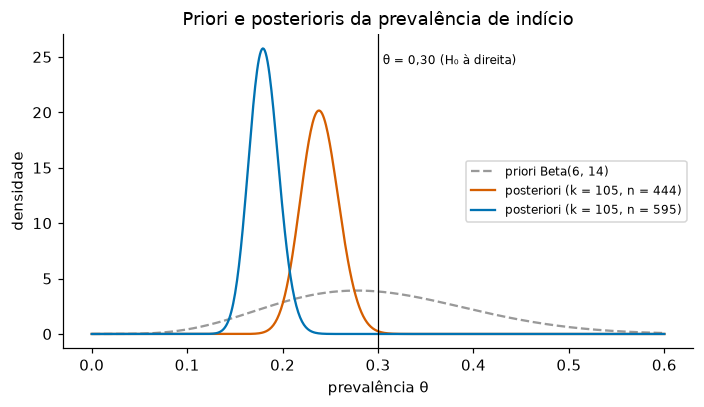

In [41]:
# 6.2 Beta-Binomial: H0: θ ≥ 0,30 × Ha: θ < 0,30, quatro prioris × dois denominadores
PRIORIS_BETA = {'Beta(6, 14): principal (CIJMG, peso 20)': (6, 14), 'Beta(1, 1) uniforme': (1, 1),
                'Beta(30, 70) (CIJMG, peso 100)': (30, 70), 'Beta(10, 10) pessimista (média 0,50)': (10, 10)}
GAB_BETA = {(6, 14): 'cijmg_media30_n20', (1, 1): 'uniforme_1_1', (30, 70): 'cijmg_media30_n100', (10, 10): 'pessimista_media50_n20'}
linhas = []
k_ind = funil['indicio']
for nome, (a0, b0) in PRIORIS_BETA.items():
    for den in (n_el, funil['n']):
        post = stats.beta(a0 + k_ind, b0 + den - k_ind)
        pri = stats.beta(a0, b0)
        h0_pri, h0_post = pri.sf(0.30), post.sf(0.30)
        bf = ((1 - h0_post) / h0_post) / ((1 - h0_pri) / h0_pri)
        linhas.append(dict(priori=nome, denominador=den, P_H0_priori=h0_pri, media_post=post.mean(),
                           ic_inf=post.ppf(0.025), ic_sup=post.ppf(0.975), P_H0_post=h0_post, BF_a0=bf))
        g = GAB['beta'][f'{GAB_BETA[(a0, b0)]}|{den}']
        C.confere(f'Beta {nome} {den} média', post.mean(), g['media'], registro=CONFERENCIAS)
        C.confere(f'Beta {nome} {den} P(H0)', h0_post, g['P_H0_post'], tol=1e-4, registro=CONFERENCIAS)
BETA = pd.DataFrame(linhas)
display(tabela_ptbr(BETA, casas={'P_H0_priori': 3, 'media_post': 3, 'ic_inf': 3, 'ic_sup': 3, 'P_H0_post': 6, 'BF_a0': 1}))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.linspace(0, 0.6, 600)
ax.plot(x, stats.beta(6, 14).pdf(x), color='#999', ls='--', label='priori Beta(6, 14)')
ax.plot(x, stats.beta(6 + k_ind, 14 + n_el - k_ind).pdf(x), color='#D55E00', label=f'posteriori (k = {k_ind}, n = {n_el})')
ax.plot(x, stats.beta(6 + k_ind, 14 + funil["n"] - k_ind).pdf(x), color='#0072B2', label=f'posteriori (k = {k_ind}, n = {funil["n"]})')
ax.axvline(0.30, color='black', lw=0.8); ax.text(0.305, ax.get_ylim()[1] * 0.9, 'θ = 0,30 (H₀ à direita)', fontsize=8)
ax.set_xlabel('prevalência θ'); ax.set_ylabel('densidade'); ax.legend(fontsize=8)
ax.set_title('Priori e posterioris da prevalência de indício')
fig.tight_layout(); fig.savefig(FIGURAS / 'beta_prevalencia.png', dpi=150); plt.show()

# frequentista, para contraste: razão estratificada entre elegíveis e teste de θ = 0,30
Nh_ano = {int(a): int(n) for a, n in estratos['N_h'].items()}
raz = C.razao_estratificada(am.indicio.astype(float), (~am.excluido_f1).astype(float), am.ano.astype(int), Nh_ano)
z30 = (raz['R'] - 0.30) / raz['ep']
bp = BETA.set_index(['priori', 'denominador'])
PB = 'Beta(6, 14): principal (CIJMG, peso 20)'
V.update(beta_media_444=fnum(bp.loc[(PB, n_el), 'media_post'], 3), beta_ic_444=fic(bp.loc[(PB, n_el), 'ic_inf'], bp.loc[(PB, n_el), 'ic_sup'], 3),
         beta_h0pri=fnum(bp.loc[(PB, n_el), 'P_H0_priori'], 3), beta_h0_444=fnum(bp.loc[(PB, n_el), 'P_H0_post'], 4),
         beta_bf_444=fnum(bp.loc[(PB, n_el), 'BF_a0'], 0), beta_media_595=fnum(bp.loc[(PB, funil['n']), 'media_post'], 3),
         beta_h0_595=f"{bp.loc[(PB, funil['n']), 'P_H0_post']:.1e}".replace('.', ','),
         beta_h0_max=fnum(BETA.loc[BETA.denominador == n_el, 'P_H0_post'].max(), 4),
         beta_medias_444=f"{fnum(BETA.loc[BETA.denominador == n_el, 'media_post'].min(), 3)} a {fnum(BETA.loc[BETA.denominador == n_el, 'media_post'].max(), 3)}",
         beta_medias_595=f"{fnum(BETA.loc[BETA.denominador == funil['n'], 'media_post'].min(), 3)} a {fnum(BETA.loc[BETA.denominador == funil['n'], 'media_post'].max(), 3)}",
         raz_R=fpct(raz['R']), raz_ic=fic(*raz['ic'], pct=True), raz_z=fnum(z30, 2), raz_p=fp(stats.norm.cdf(z30)),
         raz_dif=fnum(100 * (raz['R'] - 0.30), 1))

In [42]:
exibir('by_prevalencia', r'''
**Leitura: θ < 0,30 resiste a todas as prioris; o denominador pesa mais que a priori.**

- **Priori principal Beta(6, 14), com {{n_elegiveis}} elegíveis.**
  - P(H₀) cai de {{beta_h0pri}} (antes) para {{beta_h0_444}} (depois).
  - A posteriori tem média {{beta_media_444}} e intervalo de credibilidade (IC 95%) {{beta_ic_444}}.
  - O fator de Bayes Hₐ:H₀ é {{beta_bf_444}}: os dados multiplicam por esse valor as chances de θ < 0,30.
- **Com {{funil_n}},** a média posteriori é {{beta_media_595}} e P(H₀ | dados) ≈ {{beta_h0_595}}.
- **Sensibilidade.** Entre as quatro prioris, com {{n_elegiveis}}, a média posteriori vai de {{beta_medias_444}} e a maior P(H₀ | dados) é {{beta_h0_max}}. Com {{funil_n}}, a média vai de {{beta_medias_595}}. Mudar a priori mexe na terceira casa; mudar o denominador mexe na primeira.
- **Contraste frequentista.** O estimador de razão estratificado entre os elegíveis dá {{raz_R}} (IC 95% {{raz_ic}}). O teste de θ = 0,30 contra θ < 0,30 dá z = {{raz_z}} ({{raz_p}}). A diferença é de {{raz_dif}} p.p.

**Como ler.** O intervalo de credibilidade **é** uma afirmação de probabilidade sobre θ, dado o modelo e a priori. O IC frequentista não é: ele fala do método (FINKELSTEIN; LEVIN, 2015, p. 171–173). A "H2" atribuída à Hadja (prevalência acima de 30%) está só no notebook do professor (B-5). Com qualquer denominador e qualquer priori testada, os dados a contradizem **para a moldura inteira**.

**Ressalva de comensurabilidade.** Os 30% da NT CIJMG referem-se ao fluxo de **dois assuntos**, e θ aqui é a prevalência em todos os assuntos da moldura. É o mesmo problema de denominador apontado na Seção 5.2 (A-23). A comparação compatível é por assunto: a Seção 31 mostra que, no assunto 6226, a prevalência é muito superior a 30%.
''')


**Leitura: θ < 0,30 resiste a todas as prioris; o denominador pesa mais que a priori.**

- **Priori principal Beta(6, 14), com 444 elegíveis.**
  - P(H₀) cai de 0,474 (antes) para 0,0017 (depois).
  - A posteriori tem média 0,239 e intervalo de credibilidade (IC 95%) [0,202; 0,279].
  - O fator de Bayes Hₐ:H₀ é 542: os dados multiplicam por esse valor as chances de θ < 0,30.
- **Com 595,** a média posteriori é 0,180 e P(H₀ | dados) ≈ 5,0e-12.
- **Sensibilidade.** Entre as quatro prioris, com 444, a média posteriori vai de 0,238 a 0,248 e a maior P(H₀ | dados) é 0,0060. Com 595, a média vai de 0,178 a 0,194. Mudar a priori mexe na terceira casa; mudar o denominador mexe na primeira.
- **Contraste frequentista.** O estimador de razão estratificado entre os elegíveis dá 23,65% (IC 95% [19,72; 27,58]%). O teste de θ = 0,30 contra θ < 0,30 dá z = -3,17 (p < 0,001). A diferença é de -6,3 p.p.

**Como ler.** O intervalo de credibilidade **é** uma afirmação de probabilidade sobre θ, dado o modelo e a priori. O IC frequentista não é: ele fala do método (FINKELSTEIN; LEVIN, 2015, p. 171–173). A "H2" atribuída à Hadja (prevalência acima de 30%) está só no notebook do professor (B-5). Com qualquer denominador e qualquer priori testada, os dados a contradizem **para a moldura inteira**.

**Ressalva de comensurabilidade.** Os 30% da NT CIJMG referem-se ao fluxo de **dois assuntos**, e θ aqui é a prevalência em todos os assuntos da moldura. É o mesmo problema de denominador apontado na Seção 5.2 (A-23). A comparação compatível é por assunto: a Seção 31 mostra que, no assunto 6226, a prevalência é muito superior a 30%.


### 6.4 Falácia do promotor e negligência da taxa-base

**Falácia do promotor (condicional transposta).** É confundir P(dado | Hₐ) com P(Hₐ | dado) (FINKELSTEIN; LEVIN, 2015, p. 85; TARONI et al., 2010, p. 203).

**Negligência da taxa-base.** O valor preditivo de um sinal depende da prevalência onde ele é aplicado (FINKELSTEIN; LEVIN, 2015, p. 87; DEVORE, 2006, p. 72). Para mostrar isso, tomo a logística da Hadja (indício ~ F2_01 + F2_02 + F2_11, corte 0,5; reajustada na Seção 8) e aplico a mesma sensibilidade e especificidade a populações com prevalências diferentes. Kahneman, Sibony e Sunstein (2021) chamam de "visão de fora" o hábito de começar sempre pela taxa-base.

Uma AUC pode permanecer igual quando a prevalência muda, mas o valor preditivo positivo não. Esta conta traduz a taxa-base para a leitura prática de uma classificação e mostra por que o desempenho na Fase III não pode ser transportado diretamente à população.

In [43]:
# 6.3 Valor preditivo do modelo da Hadja conforme a prevalência
X_HADJA = ['F2_01', 'F2_02', 'F2_11']
d233 = f3.copy()
for c in F2:
    d233[c] = d233[c].fillna(False).astype(int)
y_ind = d233.indicio.astype(int).to_numpy()
with C.capturar_avisos('logística da Hadja', AVISOS):
    MOD_HADJA = sm.Logit(y_ind, sm.add_constant(d233[X_HADJA].astype(float))).fit(disp=0)
p_hadja = np.asarray(MOD_HADJA.predict())
prev_ = (p_hadja >= 0.5).astype(int)
VP, FP_, FN, VN = (int(((prev_ == 1) & (y_ind == 1)).sum()), int(((prev_ == 1) & (y_ind == 0)).sum()),
                   int(((prev_ == 0) & (y_ind == 1)).sum()), int(((prev_ == 0) & (y_ind == 0)).sum()))
assert (VP, FP_, FN, VN) == (GAB['hadja']['VP'], GAB['hadja']['FP'], GAB['hadja']['FN'], GAB['hadja']['VN'])
SENS_H, ESP_H = VP / (VP + FN), VN / (VN + FP_)
TB = []
for nome, prev in [('233 da Fase III', funil['indicio'] / funil['fase3']), ('444 elegíveis', funil['indicio'] / n_el),
                   ('595 sorteados', funil['indicio'] / funil['n']), ('juizado com prevalência de 5%', 0.05)]:
    vpp = SENS_H * prev / (SENS_H * prev + (1 - ESP_H) * (1 - prev))
    vpn = ESP_H * (1 - prev) / (ESP_H * (1 - prev) + (1 - SENS_H) * prev)
    TB.append(dict(onde=nome, prevalencia=prev, VPP=vpp, VPN=vpn))
TB = pd.DataFrame(TB)
for i, k_ in enumerate(['fase3_45', 'elegiveis_23_65', 'amostra_17_65', 'rara_5']):
    C.confere(f'VPP {k_}', TB.VPP[i], GAB['taxa_base_modelo_hadja'][k_]['VPP'], registro=CONFERENCIAS)
display(tabela_ptbr(TB, casas=3))
V.update(p_f2_dado_ind=fpct(CONDS['F2_02']['col_ind'], 0), sens_h=fnum(SENS_H, 3), esp_h=fnum(ESP_H, 3), **{f'vpp_{i}': fnum(v, 3) for i, v in enumerate(TB.VPP)},
         prev_rara=fpct(0.05, 0), erro_alertas_rara=fnum(1 - TB.VPP[3], 2))

,onde,prevalencia,VPP,VPN
0,233 da Fase III,"0,451","0,885","0,854"
1,444 elegíveis,"0,236","0,745","0,939"
2,595 sorteados,"0,176","0,669","0,957"
3,juizado com prevalência de 5%,"0,050","0,331","0,989"


In [44]:
exibir('by_taxa_base', r'''
**Leitura: o mesmo modelo, outro lugar, outro acerto.** O modelo da Hadja tem sensibilidade {{sens_h}} e especificidade {{esp_h}} entre os {{funil_fase3}}. Aplicado a outras prevalências, o VPP, isto é, a chance de acertar quando aponta "predatório", muda muito:

- na Fase III: {{vpp_0}};
- entre os elegíveis: {{vpp_1}};
- entre todos os sorteados: {{vpp_2}};
- num juizado com prevalência de {{prev_rara}}: {{vpp_3}}.

Nesse último cenário, o mesmo classificador erraria {{erro_alertas_rara}} dos alertas.

**Falácia do promotor no caso.** "Como {{p_f2_dado_ind}} dos predatórios têm F2_02, um processo com F2_02 tem {{p_f2_dado_ind}} de chance de ser predatório" confunde P(F2_02 | indício) com P(indício | F2_02). Na Fase III, os dois números são parecidos só porque os grupos têm tamanhos próximos. Com prevalência baixa, eles se afastam, e é a taxa-base que manda.
''')


**Leitura: o mesmo modelo, outro lugar, outro acerto.** O modelo da Hadja tem sensibilidade 0,810 e especificidade 0,914 entre os 233. Aplicado a outras prevalências, o VPP, isto é, a chance de acertar quando aponta "predatório", muda muito:

- na Fase III: 0,885;
- entre os elegíveis: 0,745;
- entre todos os sorteados: 0,669;
- num juizado com prevalência de 5%: 0,331.

Nesse último cenário, o mesmo classificador erraria 0,67 dos alertas.

**Falácia do promotor no caso.** "Como 81% dos predatórios têm F2_02, um processo com F2_02 tem 81% de chance de ser predatório" confunde P(F2_02 | indício) com P(indício | F2_02). Na Fase III, os dois números são parecidos só porque os grupos têm tamanhos próximos. Com prevalência baixa, eles se afastam, e é a taxa-base que manda.


## 7. Análise de Correspondência e Biplots (P1)

### 7.1 O que é e por que entra

A **análise de correspondência (CA)** desenha uma tabela de contingência como um mapa. Linhas e colunas viram pontos, e a proximidade entre eles reflete perfis parecidos (FRIENDLY; MEYER, 2016, cap. 6, p. 221–224). É um pedido expresso do professor: a CA mostra **onde** está a associação sem precisar de um modelo.

| Conceito | Definição |
|---|---|
| perfil | a linha (ou coluna) em proporções |
| massa | o peso da linha ou coluna (FÁVERO; BELFIORE, 2017, p. 443) |
| inércia total | χ²/n: quanto a tabela se afasta da independência; a origem do mapa é o perfil médio |
| autovalor | a parte da inércia em cada eixo |
| contribuição | quais pontos **definem** o eixo |
| cos² | quão bem um ponto está representado no plano (KASSAMBARA, 2017, p. 57–67) |
| biplot simétrico | linhas e colunas em coordenadas principais; **não** se lê distância linha-coluna |
| biplot assimétrico | um conjunto em coordenadas padrão: a **direção** de uma linha em relação a uma coluna tem leitura |
| biplot de contribuição | pontos fracos perto do centro (FRIENDLY; MEYER, 2016, p. 248–254) |

A implementação é por SVD própria, dos resíduos padronizados (`comum.ca_svd`), e é conferida com o `prince`. Os biplots são desenhados à mão em matplotlib.

A análise de correspondência resume diferenças entre perfis de categorias em poucos eixos. A proximidade no mapa é descritiva e depende das massas marginais; por isso os gráficos devem ser lidos junto com a tabela de contingência e a inércia.

,tabela,inercia,chi2_sobre_n,eixo1,eixo2,chi2,p
0,JEC × classe3,"0,0523","0,0523","67,0%","33,0%","31,12","p = 0,2237"
1,ano × classe3,"0,0121","0,0121","74,2%","25,8%","7,22","p = 0,1249"
2,desfecho × classe3,"0,0102","0,0102","94,9%","5,1%","6,05","p = 0,4173"


,massa,eixo 1,eixo 2,contrib. eixo 1,cos² (plano)
1º JEC,"0,0720","-0,2090","0,0090","0,0900","1,0000"
2º JEC,"0,0920","-0,1190","0,2280","0,0370","1,0000"
3º JEC,"0,0720","0,0360","0,0020","0,0030","1,0000"
4º JEC,"0,0660","-0,0080","-0,0000","0,0000","1,0000"
5º JEC,"0,0550","-0,0120","-0,0460","0,0000","1,0000"
6º JEC,"0,0810","0,0340","-0,1870","0,0030","1,0000"
7º JEC,"0,0660","-0,4730","-0,1550","0,4180","1,0000"
8º JEC,"0,0710","-0,1710","0,2260","0,0590","1,0000"
9º JEC,"0,0740","0,1680","-0,0610","0,0590","1,0000"
10º JEC,"0,0760","0,2290","0,0260","0,1130","1,0000"


,massa,eixo 1,eixo 2,contrib. eixo 1,contrib. eixo 2
não predatória,"0,8240","0,0870","0,0030","0,1760","0,0000"
indício sem certeza,"0,1260","-0,4160","0,1860","0,6220","0,2520"
certeza,"0,0500","-0,3740","-0,5060","0,2020","0,7480"


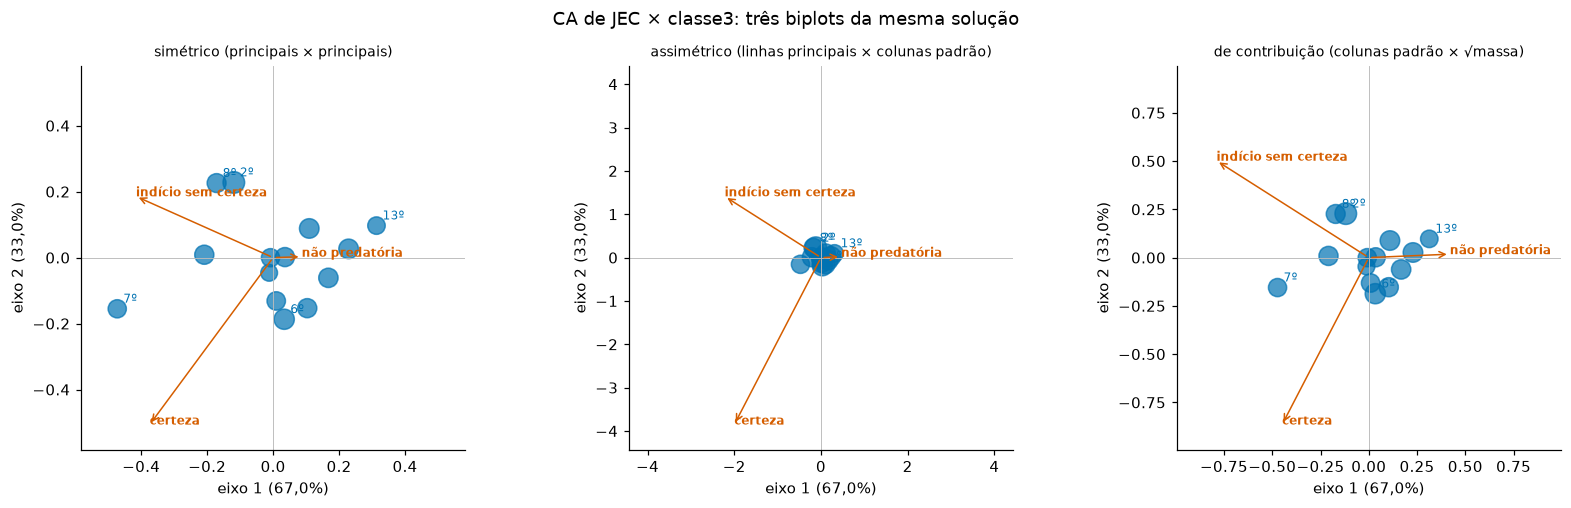

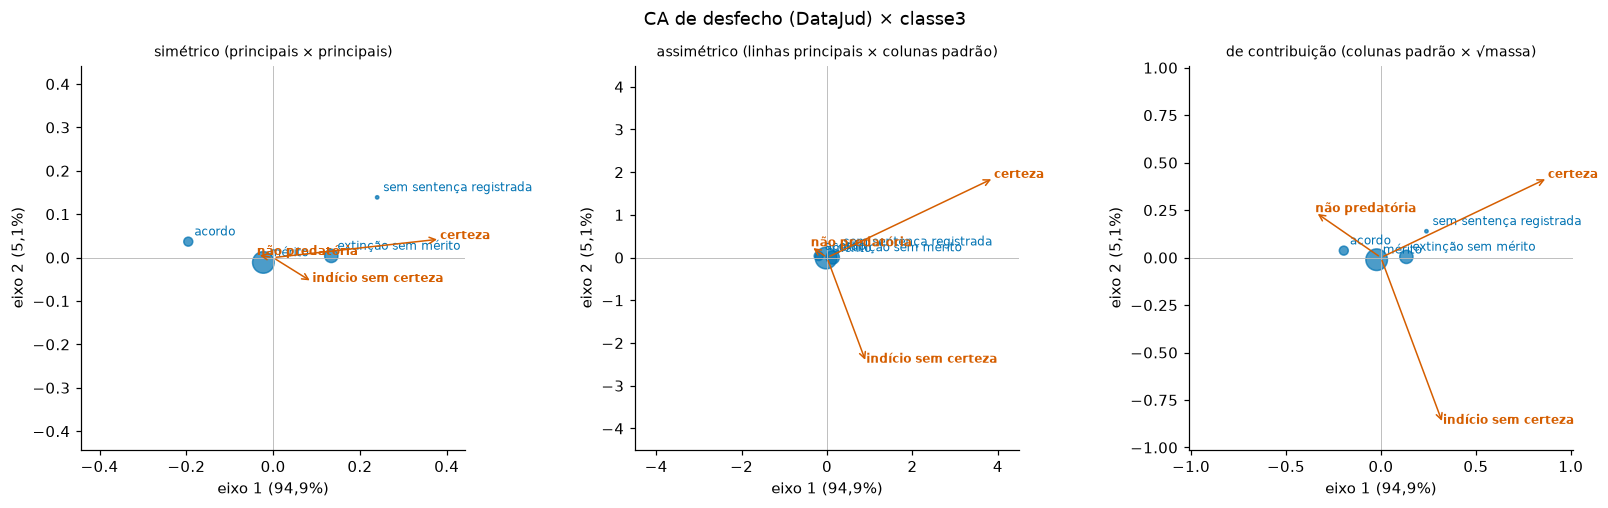

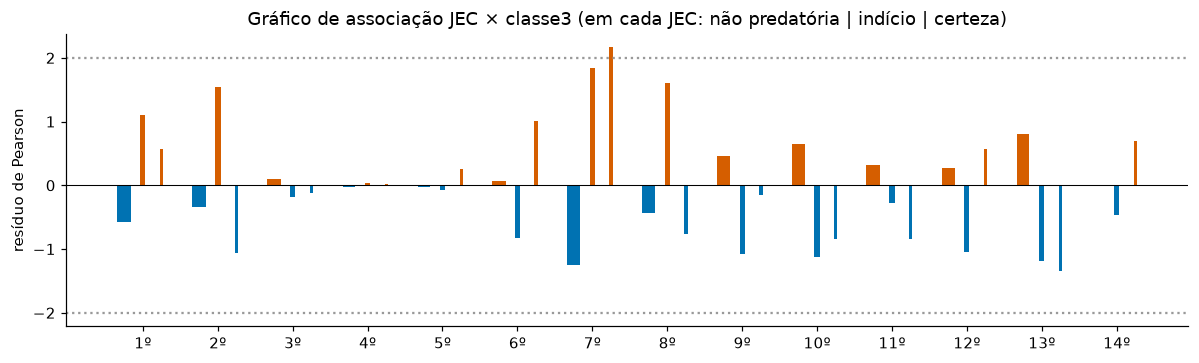

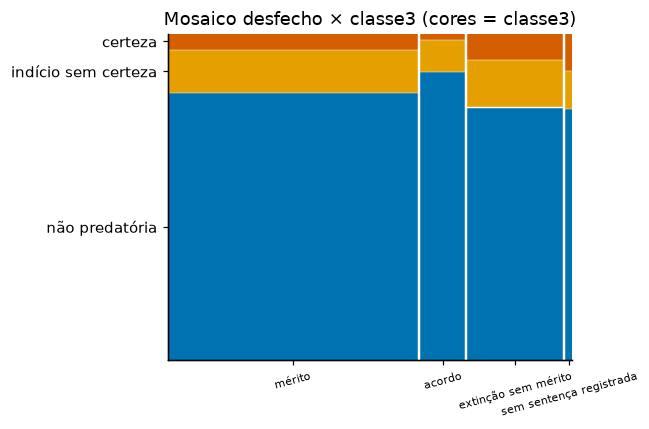

In [45]:
# 7.1 CA simples: JEC × classe3, ano × classe3 e desfecho × classe3
import prince
TABS_CA = {'JEC × classe3': pd.crosstab(am.jec, am.classe3),
           'ano × classe3': pd.crosstab(am.ano, am.classe3),
           'desfecho × classe3': pd.crosstab(dj.loc[dj.desfecho.notna(), 'desfecho'], dj.loc[dj.desfecho.notna(), 'classe3'])}
CA = {k: C.ca_svd(t) for k, t in TABS_CA.items()}
resumo_ca = pd.DataFrame({k: dict(inercia=c['inercia'], chi2_sobre_n=c['chi2_sobre_n'], eixo1=c['pct'][0], eixo2=c['pct'][1] if len(c['pct']) > 1 else np.nan,
                                  chi2=stats.chi2_contingency(TABS_CA[k].values, correction=False)[0],
                                  p=stats.chi2_contingency(TABS_CA[k].values, correction=False)[1]) for k, c in CA.items()}).T
display(tabela_ptbr(resumo_ca.reset_index().rename(columns={'index': 'tabela'}), casas={'inercia': 4, 'chi2_sobre_n': 4, 'eixo1': 1, 'eixo2': 1, 'chi2': 2}, pct=['eixo1', 'eixo2'], p=['p']))
cj = CA['JEC × classe3']
C.confere('inércia JEC × classe3', cj['inercia'], GAB['ca_jec_classe3']['inercia'], registro=CONFERENCIAS)
assert math.isclose(cj['inercia'], cj['chi2_sobre_n'])
pr_ca = prince.CA(n_components=2).fit(TABS_CA['JEC × classe3'])
assert np.allclose(np.asarray(pr_ca.eigenvalues_), cj['autovalores'][:2], rtol=1e-6), 'prince ≠ SVD próprio'
lin = pd.DataFrame({'massa': cj['massa_lin'], 'eixo 1': cj['F'][:, 0], 'eixo 2': cj['F'][:, 1],
                    'contrib. eixo 1': cj['ctr_lin'][:, 0], 'cos² (plano)': cj['cos2_lin'].sum(1)}, index=[f'{j}º JEC' for j in cj['lin']])
col = pd.DataFrame({'massa': cj['massa_col'], 'eixo 1': cj['G'][:, 0], 'eixo 2': cj['G'][:, 1],
                    'contrib. eixo 1': cj['ctr_col'][:, 0], 'contrib. eixo 2': cj['ctr_col'][:, 1]}, index=cj['col'])
display(lin.round(3)); display(col.round(3))

def biplots(ca, rot_lin, rot_col, titulo, arquivo):
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
    modos = [('simétrico (principais × principais)', ca['F'], ca['G']),
             ('assimétrico (linhas principais × colunas padrão)', ca['F'], ca['Gs']),
             ('de contribuição (colunas padrão × √massa)', ca['F'], ca['Gs'] * np.sqrt(ca['massa_col'])[:, None])]
    for ax, (nome, Fp, Gp) in zip(axs, modos):
        ax.axhline(0, color='#bbb', lw=0.6); ax.axvline(0, color='#bbb', lw=0.6)
        ax.scatter(Fp[:, 0], Fp[:, 1], s=200 * ca['massa_lin'] / ca['massa_lin'].max(), color='#0072B2', alpha=0.7)
        for i, r in enumerate(rot_lin):
            # Rotular só os pontos que mais definem o plano; todas as coordenadas estão na tabela.
            if i not in np.argsort(ca['ctr_lin'][:, :2].sum(1))[-5:]:
                continue
            ax.annotate(r, Fp[i], fontsize=8, color='#0072B2', xytext=(4, 4), textcoords='offset points')
        for j, r in enumerate(rot_col):
            ax.annotate('', Gp[j], (0, 0), arrowprops=dict(arrowstyle='->', color='#D55E00'))
            ax.text(*Gp[j], r, fontsize=8, color='#D55E00', fontweight='bold')
        ax.set_title(nome, fontsize=9)
        ax.set_xlabel(f"eixo 1 ({fpct(ca['pct'][0], 1)})"); ax.set_ylabel(f"eixo 2 ({fpct(ca['pct'][1], 1)})")
        lim = np.abs(np.vstack([Fp, Gp])).max() * 1.15
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    fig.suptitle(titulo); fig.tight_layout(); fig.savefig(FIGURAS / arquivo, dpi=150); plt.show()

biplots(cj, [f'{j}º' for j in cj['lin']], cj['col'], 'CA de JEC × classe3: três biplots da mesma solução', 'ca_jec_classe3_biplots.png')
cd_ = CA['desfecho × classe3']
biplots(cd_, cd_['lin'], cd_['col'], 'CA de desfecho (DataJud) × classe3', 'ca_desfecho_classe3_biplots.png')

# gráfico de associação (Friendly & Meyer, cap. 5): barras com altura = resíduo de Pearson, largura ∝ √esperado
t = TABS_CA['JEC × classe3'].values.astype(float)
esp = np.outer(t.sum(1), t.sum(0)) / t.sum()
res = (t - esp) / np.sqrt(esp)
fig, ax = plt.subplots(figsize=(11, 3.4))
for j in range(3):
    for i in range(t.shape[0]):
        w = 0.8 * np.sqrt(esp[i, j]) / np.sqrt(esp).max()
        ax.bar(i * 4 + j, res[i, j], width=w, color='#D55E00' if res[i, j] > 0 else '#0072B2')
ax.set_xticks([i * 4 + 1 for i in range(t.shape[0])]); ax.set_xticklabels([f'{j}º' for j in cj['lin']])
ax.axhline(0, color='black', lw=0.7); ax.axhline(2, color='#999', ls=':'); ax.axhline(-2, color='#999', ls=':')
ax.set_ylabel('resíduo de Pearson'); ax.set_title('Gráfico de associação JEC × classe3 (em cada JEC: não predatória | indício | certeza)')
fig.tight_layout(); fig.savefig(FIGURAS / 'assoc_jec_classe3.png', dpi=150); plt.show()

from statsmodels.graphics.mosaicplot import mosaic
fig, ax = plt.subplots(figsize=(6, 4))
mosaic(dj[dj.desfecho.notna()].assign(c3=lambda d: d.classe3.astype(str), de=lambda d: d.desfecho.astype(str)), ['de', 'c3'],
       ax=ax, labelizer=lambda k: '', gap=0.01, properties=lambda k: {'color': CORES_CLASSE3.get(k[1], '#ccc')})
ax.set_title('Mosaico desfecho × classe3 (cores = classe3)'); plt.setp(ax.get_xticklabels(), fontsize=7, rotation=15)
fig.tight_layout(); fig.savefig(FIGURAS / 'mosaico_desfecho_classe3.png', dpi=150); plt.show()

g_ = pd.DataFrame(cj['G'], index=cj['col'])
V.update(ca_inercia=fnum(cj['inercia'], 4), ca_chi2n=fnum(cj['chi2_sobre_n'], 4), ca_e1=fpct(cj['pct'][0], 1), ca_e2=fpct(cj['pct'][1], 1),
         ca_p=fp(resumo_ca.loc['JEC × classe3', 'p']), ca_jec_top=lin['contrib. eixo 1'].idxmax(),
         ca_jec_top_ctr=fpct(lin['contrib. eixo 1'].max(), 1), ca_jec_cos2_min=lin['cos² (plano)'].idxmin(),
         ca_ano_in=fnum(CA['ano × classe3']['inercia'], 4), ca_ano_p=fp(resumo_ca.loc['ano × classe3', 'p']),
         ca_des_in=fnum(cd_['inercia'], 4), ca_des_e1=fpct(cd_['pct'][0], 1), ca_des_p=fp(resumo_ca.loc['desfecho × classe3', 'p']),
         ca_esp5=fpct(familia_A['JEC']['pct_esp_menor5'], 0))

In [46]:
exibir('ca_simples', r'''
**Leitura (P1): o mapa mostra onde estaria a associação, mas não há associação demonstrada.**

- **JEC × classe3.** A inércia é {{ca_inercia}}, exatamente o χ²/n da tabela ({{ca_chi2n}}). Com três colunas, dois eixos guardam toda a inércia: {{ca_e1}} e {{ca_e2}} (FÁVERO; BELFIORE, 2017, p. 480). O SVD próprio e o `prince` dão os mesmos autovalores.
  - **Eixo 1:** opõe "não predatória" às duas formas de predação.
  - **Eixo 2:** separa indício (positivo) de certeza (negativo).
  - **O JEC que mais define o eixo 1** é o {{ca_jec_top}} ({{ca_jec_top_ctr}} da inércia do eixo), do lado da predação.
- **Ressalva decisiva.** O χ² da tabela não é significativo ({{ca_p}}) e {{ca_esp5}} das caselas têm esperado menor que cinco. O mapa é **exploratório**: descreve a forma da (pouca) associação, sem provar que ela existe na população.
- **Ano × classe3** (inércia {{ca_ano_in}}; {{ca_ano_p}}) e **desfecho × classe3** (inércia {{ca_des_in}}; {{ca_des_p}}) têm associação ainda menor. No mapa do desfecho, o eixo 1 ({{ca_des_e1}}) aproxima "extinção sem mérito" e "certeza", o mesmo sinal fraco da RV da Seção 6.

**Como ler os três biplots.**
- **Simétrico:** compare linhas entre si e colunas entre si. **Não** leia a distância entre um JEC e uma classe (KASSAMBARA, 2017, p. 60 e 71–73).
- **Assimétrico:** um JEC na direção da seta "certeza" tem perfil com mais certeza que a média.
- **De contribuição:** os pontos colados ao centro não definem os eixos.

O sinal dos eixos é arbitrário: programas diferentes espelham o mapa (FÁVERO; BELFIORE, 2017, p. 478). A CA não é teste: a inferência fica com o χ² (Seção 4) ou com modelos como o RC de Goodman (FRIENDLY; MEYER, 2016, p. 382–383).
''')


**Leitura (P1): o mapa mostra onde estaria a associação, mas não há associação demonstrada.**

- **JEC × classe3.** A inércia é 0,0523, exatamente o χ²/n da tabela (0,0523). Com três colunas, dois eixos guardam toda a inércia: 67,0% e 33,0% (FÁVERO; BELFIORE, 2017, p. 480). O SVD próprio e o `prince` dão os mesmos autovalores.
  - **Eixo 1:** opõe "não predatória" às duas formas de predação.
  - **Eixo 2:** separa indício (positivo) de certeza (negativo).
  - **O JEC que mais define o eixo 1** é o 7º JEC (41,8% da inércia do eixo), do lado da predação.
- **Ressalva decisiva.** O χ² da tabela não é significativo (p = 0,2237) e 43% das caselas têm esperado menor que cinco. O mapa é **exploratório**: descreve a forma da (pouca) associação, sem provar que ela existe na população.
- **Ano × classe3** (inércia 0,0121; p = 0,1249) e **desfecho × classe3** (inércia 0,0102; p = 0,4173) têm associação ainda menor. No mapa do desfecho, o eixo 1 (94,9%) aproxima "extinção sem mérito" e "certeza", o mesmo sinal fraco da RV da Seção 6.

**Como ler os três biplots.**
- **Simétrico:** compare linhas entre si e colunas entre si. **Não** leia a distância entre um JEC e uma classe (KASSAMBARA, 2017, p. 60 e 71–73).
- **Assimétrico:** um JEC na direção da seta "certeza" tem perfil com mais certeza que a média.
- **De contribuição:** os pontos colados ao centro não definem os eixos.

O sinal dos eixos é arbitrário: programas diferentes espelham o mapa (FÁVERO; BELFIORE, 2017, p. 478). A CA não é teste: a inferência fica com o χ² (Seção 4) ou com modelos como o RC de Goodman (FRIENDLY; MEYER, 2016, p. 382–383).


### 7.2 MCA dos sinais F2 e variáveis suplementares

A **análise de correspondência múltipla (MCA)** aplica a CA à matriz indicadora (uma coluna por categoria). Entram como **ativas** as F2 com pelo menos 5% de "Sim" na Fase III (Seção 4). A inércia da matriz indicadora é "inflada" por dimensões artificiais. Por isso, os autovalores acima de 1/Q são corrigidos por **Benzécri** e expressos também sobre a inércia ajustada de **Greenacre** (FRIENDLY; MEYER, 2016, p. 243–246).

**As F3 nunca entram como ativas**, porque definem a classe3: o mapa seria circular. Classe3, ano, JEC e desfecho entram como **suplementares**. Elas são projetadas no mapa, mas não o definem. A coordenada principal de uma categoria suplementar é a média das coordenadas padrão dos processos que a têm.

A correspondência múltipla estende a ideia aos vários sinais F2. A correção das inércias ajuda a não superinterpretar eixos fracos, e as variáveis suplementares são projetadas sem determinar o ajuste. O biplot é um mapa de padrões, não um teste de predação.

,index,autovalor bruto,% bruto,% Benzécri,% Greenacre (ajustada)
0,eixo 1,"0,2674","26,7%","90,8%","55,5%"
1,eixo 2,"0,1603","16,0%","5,6%","3,4%"
2,eixo 3,"0,1514","15,1%","3,1%","1,9%"
3,eixo 4,"0,1349","13,5%","0,4%","0,3%"
4,eixo 5,"0,1220","12,2%","0,0%","0,0%"
5,eixo 6,"0,0993","9,9%","0,0%","0,0%"


,contribuição ao eixo 1
F2_02=1,"0,2560"
F2_01=1,"0,2530"
F2_01=0,"0,1830"
F2_02=0,"0,1790"
F2_14=1,"0,0500"
F2_11=1,"0,0210"


,eixo 1,eixo 2
classe3=não predatória,"-0,6600","-0,1130"
classe3=indício sem certeza,"0,8290","0,1760"
classe3=certeza,"0,7440","0,0420"
ano=2022,"0,2120","-0,2600"
ano=2023,"0,1460","0,0710"
ano=2024,"-0,3170","0,1390"
desfecho=mérito,"-0,1130","0,0810"
desfecho=acordo,"-0,1850","-0,0640"
desfecho=extinção sem mérito,"0,3630","-0,1930"
desfecho=sem sentença registrada,"1,5010","-0,6350"


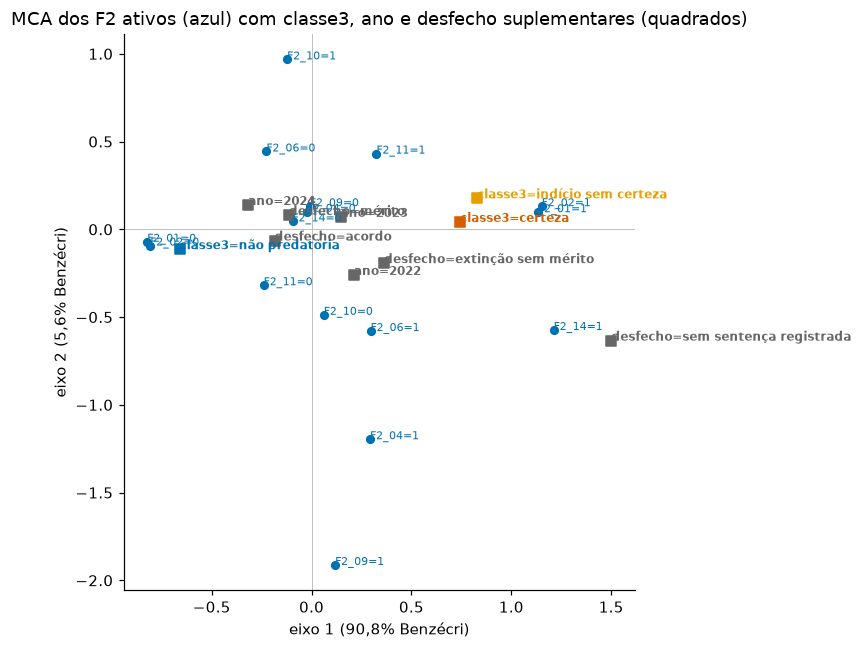

In [47]:
# 7.2 MCA por SVD da matriz indicadora; Benzécri/Greenacre; suplementares; conferência com o prince
Zdf = pd.get_dummies(d233[F2_ATIVOS].astype(int).astype(str), prefix_sep='=').astype(float)
Q, J = len(F2_ATIVOS), Zdf.shape[1]
mca = C.ca_svd(Zdf, k=2)
corr = C.mca_correcoes(mca['autovalores'], Q, J)
C.confere('Benzécri eixo 1', 100 * corr['pct_benzecri'][0], GAB['mca_f2']['benzecri_pct'][0], tol=1e-3, registro=CONFERENCIAS)
autov = pd.DataFrame({'autovalor bruto': mca['autovalores'][:6], '% bruto': mca['pct'][:6],
                      '% Benzécri': corr['pct_benzecri'][:6], '% Greenacre (ajustada)': corr['pct_greenacre'][:6]},
                     index=[f'eixo {i + 1}' for i in range(6)])
display(tabela_ptbr(autov.reset_index(), casas={'autovalor bruto': 4, '% bruto': 1, '% Benzécri': 1, '% Greenacre (ajustada)': 1}, pct=['% bruto', '% Benzécri', '% Greenacre (ajustada)']))
pr_mca = prince.MCA(n_components=J - Q, correction=None).fit(d233[F2_ATIVOS].astype(int).astype(str))
assert np.allclose(np.asarray(pr_mca.eigenvalues_)[:3], mca['autovalores'][:3], rtol=1e-6), 'prince MCA ≠ SVD próprio'

# suplementares: média das coordenadas padrão das linhas
Fs = mca['Fs']
sup = {}
for var, serie in [('classe3', d233.classe3.astype(str)), ('ano', d233.ano.astype(str)),
                   ('desfecho', dj.set_index('numero').loc[d233.numero, 'desfecho'].astype(str).to_numpy())]:
    for cat in pd.unique(serie):
        m_ = (np.asarray(serie) == cat)
        sup[f'{var}={cat}'] = Fs[m_].mean(0)          # coordenada principal da categoria suplementar
SUP = pd.DataFrame(sup, index=['eixo 1', 'eixo 2']).T
Gm = pd.DataFrame(mca['G'], index=Zdf.columns, columns=['eixo 1', 'eixo 2'])
ctr_m = pd.Series(mca['ctr_col'][:, 0], index=Zdf.columns).sort_values(ascending=False)
display(ctr_m.head(6).rename('contribuição ao eixo 1').to_frame().round(3)); display(SUP.round(3))
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.axhline(0, color='#bbb', lw=0.6); ax.axvline(0, color='#bbb', lw=0.6)
ax.scatter(Gm['eixo 1'], Gm['eixo 2'], color='#0072B2', s=25)
for nome, r in Gm.iterrows():
    ax.annotate(nome, r, fontsize=7, color='#0072B2')
for nome, r in SUP.iterrows():
    cor = CORES_CLASSE3.get(nome.split('=')[1], '#666') if nome.startswith('classe3') else '#666'
    ax.scatter(*r, marker='s', color=cor, s=50); ax.annotate(nome, r, fontsize=8, color=cor, fontweight='bold')
ax.set_xlabel(f"eixo 1 ({fpct(corr['pct_benzecri'][0], 1)} Benzécri)"); ax.set_ylabel(f"eixo 2 ({fpct(corr['pct_benzecri'][1], 1)} Benzécri)")
ax.set_title('MCA dos F2 ativos (azul) com classe3, ano e desfecho suplementares (quadrados)')
fig.tight_layout(); fig.savefig(FIGURAS / 'mca_f2.png', dpi=150); plt.show()
MCA_COORD = mca['F']                          # coordenadas dos processos (insumo de agrupamento na Seção 10)
V.update(mca_Q=fint(Q), mca_1Q=fnum(1 / Q, 3), mca_l1=fnum(mca['autovalores'][0], 3), mca_b1=fpct(corr['pct_benzecri'][0], 1),
         mca_g1=fpct(corr['pct_greenacre'][0], 1), mca_bruto1=fpct(mca['pct'][0], 1), mca_n_acima=fint((mca['autovalores'] > 1 / Q).sum()),
         mca_top=', '.join(ctr_m.index[:4]), mca_cert=fnum(SUP.loc['classe3=certeza', 'eixo 1'], 2),
         mca_ind=fnum(SUP.loc['classe3=indício sem certeza', 'eixo 1'], 2), mca_nao=fnum(SUP.loc['classe3=não predatória', 'eixo 1'], 2))

In [48]:
exibir('ca_mca', r'''
**Leitura: há uma dimensão dominante nos sinais formais, a documental, e ela separa a predação, mas não a certeza.**

- **Autovalores.** Com Q = {{mca_Q}} variáveis ativas, só {{mca_n_acima}} autovalores ficam acima de 1/Q ({{mca_1Q}}). O eixo 1 tem autovalor bruto {{mca_l1}}, que corresponde a {{mca_bruto1}} da inércia bruta, {{mca_b1}} pela correção de Benzécri e {{mca_g1}} pela inércia ajustada de Greenacre. Sem correção, a importância do eixo 1 seria muito subestimada, porque a codificação indicadora cria dimensões artificiais.
- **O eixo 1 é o bloco documental.** As categorias que mais o definem são {{mca_top}}: petição genérica e ausência de documentos essenciais, presentes ou ausentes juntas.
- **Suplementares.** No eixo 1, a classe3 se distribui assim: não predatória {{mca_nao}}, indício sem certeza {{mca_ind}}, certeza {{mca_cert}}. Indício e certeza ficam **no mesmo lugar** do eixo documental. É a versão geométrica do achado da razão contínua: os F2 separam predação de não predação, mas não a certeza.
- **Software.** O `prince` (versão na Seção 1) confere os autovalores brutos. A correção de Greenacre dele exige `n_components = J − K`; com dois componentes, ela devolve uma porcentagem negativa. Por isso, as correções aqui são calculadas à parte (`comum.mca_correcoes`).
''')


**Leitura: há uma dimensão dominante nos sinais formais, a documental, e ela separa a predação, mas não a certeza.**

- **Autovalores.** Com Q = 8 variáveis ativas, só 4 autovalores ficam acima de 1/Q (0,125). O eixo 1 tem autovalor bruto 0,267, que corresponde a 26,7% da inércia bruta, 90,8% pela correção de Benzécri e 55,5% pela inércia ajustada de Greenacre. Sem correção, a importância do eixo 1 seria muito subestimada, porque a codificação indicadora cria dimensões artificiais.
- **O eixo 1 é o bloco documental.** As categorias que mais o definem são F2_02=1, F2_01=1, F2_01=0, F2_02=0: petição genérica e ausência de documentos essenciais, presentes ou ausentes juntas.
- **Suplementares.** No eixo 1, a classe3 se distribui assim: não predatória -0,66, indício sem certeza 0,83, certeza 0,74. Indício e certeza ficam **no mesmo lugar** do eixo documental. É a versão geométrica do achado da razão contínua: os F2 separam predação de não predação, mas não a certeza.
- **Software.** O `prince` (versão na Seção 1) confere os autovalores brutos. A correção de Greenacre dele exige `n_components = J − K`; com dois componentes, ela devolve uma porcentagem negativa. Por isso, as correções aqui são calculadas à parte (`comum.mca_correcoes`).


---

# PARTE III: MODELOS E CLASSIFICAÇÃO

## 8. Logito Multinomial, Ordinal e Condicional (R10–R12)

### 8.1 Pergunta, universo e escolha dos modelos

**Resposta.** A classe3, com três níveis ordenados: 0 = demais da Fase III, 1 = indício sem certeza, 2 = certeza. **Universo principal:** os 233 da Fase III, o mesmo da logística da Hadja; a sensibilidade usa os 444 elegíveis. **Preditores:** os três da logística reduzida da Hadja (F2_01, F2_02, F2_11), para que a comparação com ela (R13) seja de **modelo** e não de variáveis.

| Modelo | Ideia | Por que entra | Fonte |
|---|---|---|---|
| **Multinomial** (categoria de referência) | um logito por categoria contra a referência; ignora a ordem | R10 | GIOLO, 2017, p. 167; GIOLO, 2006, p. 110–113 |
| **Cumulativo de chances proporcionais (PO)** | logitos de P(Y ≥ j) com **o mesmo β** em todos os cortes | R11; exige testar a proporcionalidade | GIOLO, 2017, p. 176; FRIENDLY; MEYER, 2016, p. 325–327 |
| **Não proporcional (NPO) e parcialmente proporcional (PPO)** | β diferente por corte, para todas ou parte das variáveis | teste formal da suposição PO | GIOLO, 2017, §8.3 |
| **Categorias adjacentes** | logitos de 1 contra 0 e de 2 contra 1, com β comum | a página do roteiro | GIOLO, 2017, p. 188 |
| **Razão contínua** | passo 1: P(Y ≥ 1); passo 2: P(Y = 2 \| Y ≥ 1) | **imita o funil**: só chega a certeza quem já é indício. É o modelo principal | GIOLO, 2017, p. 195; FRIENDLY; MEYER, 2016, p. 335 |
| **Logística condicional** | intercepto próprio por estrato, eliminado pela verossimilhança condicional | R12; controle de heterogeneidade JEC × ano (não é o desenho, que estratificou só por ano) | GIOLO, 2006, p. 117–120; GIOLO, 2017, p. 207; ROSENBAUM, 2010 |

A edição de 2017 do Giolo não está no acervo, só o sumário: as páginas citadas vêm dele (C-5). O conteúdo técnico vem da apostila de 2006 e de Friendly & Meyer, cap. 8.

As três categorias jurídicas são exclusivas, mas têm ordem. O multinomial não impõe ordem; o logito ordinal a utiliza e precisa do pressuposto de chances proporcionais. O confronto entre formas permite decidir qual restrição é sustentada pelos dados.

In [49]:
# 8.1 Multinomial (RRR) e cumulativo PO; teste da proporcionalidade (LR contra NPO, Brant por bootstrap) e PPO
from statsmodels.miscmodels.ordinal_model import OrderedModel
y3 = d233.classe3_cod.astype(int).to_numpy()
X3 = d233[X_HADJA].astype(float)
n233 = len(y3)
llnull3 = float(sum(c * math.log(c / n233) for c in np.bincount(y3)))
with C.capturar_avisos('multinomial e ordinais', AVISOS) as av_mod:
    MN = sm.MNLogit(y3, sm.add_constant(X3)).fit(disp=0, method='bfgs', maxiter=2000)
    OM = OrderedModel(y3, X3, distr='logit').fit(method='bfgs', disp=0, maxiter=2000)
    PO = C.logit_cumulativo(X3, y3)
    NPO = C.logit_cumulativo(X3, y3, nao_prop=X_HADJA)
    PPO = C.logit_cumulativo(X3, y3, nao_prop=['F2_02'])
    ACL = C.logit_adjacentes(X3, y3)
assert math.isclose(PO['llf'], OM.llf, rel_tol=1e-5)             # PO próprio = statsmodels
C.confere('AIC multinomial', MN.aic, GAB['modelos3']['multinomial']['aic'], tol=1e-4, registro=CONFERENCIAS)
C.confere('AIC ordinal PO', -2 * OM.llf + 2 * len(OM.params), GAB['modelos3']['ordinal_PO']['aic'], tol=1e-4, registro=CONFERENCIAS)

rrr = pd.concat({f'{NIVEIS_CLASSE3[j + 1]} × não predatória':
                 pd.DataFrame({'β': MN.params.iloc[:, j], 'RRR': np.exp(MN.params.iloc[:, j]),
                               'IC inf.': np.exp(MN.params.iloc[:, j] - C.Z95 * MN.bse.iloc[:, j]),
                               'IC sup.': np.exp(MN.params.iloc[:, j] + C.Z95 * MN.bse.iloc[:, j]),
                               'p': MN.pvalues.iloc[:, j]}) for j in range(2)})
display(tabela_ptbr(rrr.reset_index().rename(columns={'level_0': 'logito', 'level_1': 'termo'}), casas=3, p=['p']))
po_tab = pd.DataFrame({'β': PO['params'], 'EP': PO['ep']})
po_tab['OR'] = np.exp(po_tab['β'])
po_tab['IC inf.'] = np.exp(po_tab['β'] - C.Z95 * po_tab['EP']); po_tab['IC sup.'] = np.exp(po_tab['β'] + C.Z95 * po_tab['EP'])
po_tab['p'] = 2 * stats.norm.sf(np.abs(po_tab['β'] / po_tab['EP']))
display(tabela_ptbr(po_tab.reset_index().rename(columns={'index': 'termo'}), casas=3, p=['p']))

# teste da proporcionalidade: (i) LR PO × NPO (aninhados, gl = 3); (ii) Brant: Wald da igualdade das inclinações
lr_po = 2 * (NPO['llf'] - PO['llf']); gl_po = NPO['k'] - PO['k']
lr_ppo = 2 * (NPO['llf'] - PPO['llf']); gl_ppo = NPO['k'] - PPO['k']
lr_po_ppo = 2 * (PPO['llf'] - PO['llf'])
cortes = [sm.Logit((y3 >= j).astype(int), sm.add_constant(X3)).fit(disp=0, method='bfgs', maxiter=2000) for j in (1, 2)]
rng_b = np.random.default_rng(SEMENTES['bootstrap'])
difs = []
_av_boot = C.capturar_avisos('bootstrap do teste de Brant (reamostras quase separadas)', AVISOS)
_av_boot.__enter__()
for _ in range(500):
    i = rng_b.integers(0, n233, n233)
    try:
        b1 = sm.Logit((y3[i] >= 1).astype(int), sm.add_constant(X3.iloc[i], has_constant='add')).fit(disp=0, method='bfgs', maxiter=500).params[X_HADJA]
        b2 = sm.Logit((y3[i] >= 2).astype(int), sm.add_constant(X3.iloc[i], has_constant='add')).fit(disp=0, method='bfgs', maxiter=500).params[X_HADJA]
        difs.append((b1 - b2).to_numpy())
    except (np.linalg.LinAlgError, ValueError):   # reamostras com separação completa: descartadas e contadas
        difs.append(np.full(3, np.nan))
_av_boot.__exit__(None, None, None)
difs = np.array(difs); validas = ~np.isnan(difs).any(1)
dif_obs = (cortes[0].params[X_HADJA] - cortes[1].params[X_HADJA]).to_numpy()
W_brant = float(dif_obs @ np.linalg.pinv(np.cov(difs[validas].T)) @ dif_obs)
brant_ind = {v: (dif_obs[k] ** 2 / np.var(difs[validas, k], ddof=1)) for k, v in enumerate(X_HADJA)}
TESTE_PO = pd.DataFrame({'estatística': [lr_po, W_brant, lr_ppo, lr_po_ppo], 'gl': [gl_po, 3, gl_ppo, PPO['k'] - PO['k']]},
                        index=['LR: PO × NPO', 'Brant (Wald, cov. por bootstrap)', 'LR: PPO (só F2_02 livre) × NPO', 'LR: PO × PPO'])
TESTE_PO['p'] = stats.chi2.sf(TESTE_PO['estatística'], TESTE_PO['gl'])
display(tabela_ptbr(TESTE_PO.reset_index(), casas=2, p=['p']))
display(pd.DataFrame({'corte ≥ indício': cortes[0].params[X_HADJA], 'corte = certeza': cortes[1].params[X_HADJA],
                      'Wald individual (gl = 1)': pd.Series(brant_ind)}).round(3))
lr_mn = 2 * (MN.llf - OM.llf)
C.confere('LR PO × multinomial', lr_mn, GAB['modelos3']['LR_PO_vs_multinomial']['LR'], tol=1e-4, registro=CONFERENCIAS)
V.update(mn_rrr_cert_02=fnum(np.exp(MN.params.loc['F2_02'].iloc[1]), 2), mn_rrr_ind_02=fnum(np.exp(MN.params.loc['F2_02'].iloc[0]), 2),
         mn_rrr_cert_11=fnum(np.exp(MN.params.loc['F2_11'].iloc[1]), 2), mn_rrr_ind_11=fnum(np.exp(MN.params.loc['F2_11'].iloc[0]), 2),
         po_or_02=fnum(po_tab.loc['F2_02', 'OR'], 2), po_or_11=fnum(po_tab.loc['F2_11', 'OR'], 2),
         po_or_02_ic=fic(po_tab.loc['F2_02', 'IC inf.'], po_tab.loc['F2_02', 'IC sup.']),
         lr_po=fnum(lr_po, 2), gl_po=str(gl_po), p_po=fp(TESTE_PO.p.iloc[0]), w_brant=fnum(W_brant, 2), p_brant=fp(TESTE_PO.p.iloc[1]),
         brant_validas=fint(validas.sum()), lr_ppo=fnum(lr_ppo, 2), p_ppo=fp(TESTE_PO.p.iloc[2]), lr_po_ppo=fnum(lr_po_ppo, 2),
         p_po_ppo=fp(TESTE_PO.p.iloc[3]), npo_pmin=fnum(NPO['p_min'], 4), lr_mn=fnum(lr_mn, 2),
         b02_c1=fnum(cortes[0].params['F2_02'], 2), b02_c2=fnum(cortes[1].params['F2_02'], 2),
         b11_c1=fnum(cortes[0].params['F2_11'], 2), b11_c2=fnum(cortes[1].params['F2_11'], 2),
         acl_llf=fnum(ACL['llf'], 2), mod_avisos='; '.join(av_mod.lista) or 'nenhum')

,logito,termo,β,RRR,IC inf.,IC sup.,p
0,indício sem certeza × não predatória,const,"-2,989","0,050","0,022","0,113","p < 0,001"
1,indício sem certeza × não predatória,F2_01,"0,608","1,836","0,130","26,035","p = 0,6533"
2,indício sem certeza × não predatória,F2_02,"3,482","32,511","2,185","483,832","p = 0,0115"
3,indício sem certeza × não predatória,F2_11,"1,616","5,033","2,074","12,213","p < 0,001"
4,certeza × não predatória,const,"-3,583","0,028","0,010","0,077","p < 0,001"
5,certeza × não predatória,F2_01,"0,413","1,511","0,056","40,763","p = 0,8061"
6,certeza × não predatória,F2_02,"3,291","26,869","0,953","757,342","p = 0,0534"
7,certeza × não predatória,F2_11,"1,592","4,915","1,766","13,674","p = 0,0023"


,termo,β,EP,OR,IC inf.,IC sup.,p
0,α1,"-2,119","0,291","0,120","0,068","0,212","p < 0,001"
1,α2,"-4,812","0,424","0,008","0,004","0,019","p < 0,001"
2,F2_01,"0,728","1,016","2,071","0,283","15,165","p = 0,4737"
3,F2_02,"2,578","1,023","13,177","1,773","97,930","p = 0,0118"
4,F2_11,"0,932","0,312","2,538","1,377","4,679","p = 0,0028"


⚠ aviso [bootstrap do teste de Brant (reamostras quase separadas)] HessianInversionWarning: Inverting hessian failed, no bse or cov_params available


,index,estatística,gl,p
0,LR: PO × NPO,"17,56",3,"p < 0,001"
1,"Brant (Wald, cov. por bootstrap)","17,09",3,"p < 0,001"
2,LR: PPO (só F2_02 livre) × NPO,"2,92",2,"p = 0,2327"
3,LR: PO × PPO,"14,65",1,"p < 0,001"


,corte ≥ indício,corte = certeza,Wald individual (gl = 1)
F2_01,"0,5450","0,2760","0,0010"
F2_02,"3,4240","1,4060","0,0580"
F2_11,"1,6080","0,5400","4,1530"


In [50]:
exibir('md_multinomial_ordinal', r'''
**Leitura (R10, R11): a ordem existe, mas a suposição de chances proporcionais não se sustenta.**

- **Multinomial (R10).** e^β é a **razão de riscos relativos** (RRR), por exemplo P(certeza)/P(não predatória) com F2_02 presente contra ausente. Não é o OR de "subir de nível".
  - Com F2_02, a RRR é {{mn_rrr_ind_02}} para indício sem certeza e {{mn_rrr_cert_02}} para certeza.
  - Com F2_11, é {{mn_rrr_ind_11}} e {{mn_rrr_cert_11}}.
  - Os intervalos são muito largos, sobretudo na certeza: há só {{funil_certeza}} casos, e F2_01/F2_02 andam juntas.
- **Cumulativo de chances proporcionais (R11).** O OR comum de "estar acima de qualquer corte" é {{po_or_02}} {{po_or_02_ic}} para F2_02 e {{po_or_11}} para F2_11. Mas esse OR só tem sentido se a suposição PO valer.
- **A suposição PO é rejeitada.**
  - LR PO × NPO = {{lr_po}} (gl = {{gl_po}}; {{p_po}}).
  - Brant (Wald com covariância por bootstrap, {{brant_validas}} reamostras válidas): {{w_brant}} ({{p_brant}}).
  - Nos logitos cumulativos separados, F2_02 tem β = {{b02_c1}} no corte "≥ indício" e {{b02_c2}} no corte "certeza"; F2_11 tem {{b11_c1}} e {{b11_c2}}. **Os sinais pesam muito para entrar na predação e pouco para chegar à certeza.**
  - O NPO não cruza probabilidades: a menor probabilidade ajustada é {{npo_pmin}}.
- **Modelo parcialmente proporcional (PPO).** Libertar só a F2_02 basta. O PPO não difere do NPO (LR = {{lr_ppo}}; {{p_ppo}}) e supera o PO (LR = {{lr_po_ppo}}; {{p_po_ppo}}). Os Wald individuais do Brant apontam outra variável porque a quase separação da F2_02 infla a variância bootstrap. O teste de razão de verossimilhança é o confiável aqui.
- **Categorias adjacentes (p. 188 do roteiro).** Com inclinação comum, logL = {{acl_llf}}. Com inclinações livres, o modelo coincide com o multinomial (mesma verossimilhança).
- **Comparação aproximada.** O LR PO × multinomial ({{lr_mn}}) confere com a apostila. É só aproximado, porque os modelos não são aninhados; o teste formal é o PO × NPO.

Avisos de ajuste: {{mod_avisos}}.

**Não diga** "o ordinal é melhor porque respeita a ordem" sem testar a suposição PO (FRIENDLY; MEYER, 2016, p. 327–333).
''')


**Leitura (R10, R11): a ordem existe, mas a suposição de chances proporcionais não se sustenta.**

- **Multinomial (R10).** e^β é a **razão de riscos relativos** (RRR), por exemplo P(certeza)/P(não predatória) com F2_02 presente contra ausente. Não é o OR de "subir de nível".
  - Com F2_02, a RRR é 32,51 para indício sem certeza e 26,87 para certeza.
  - Com F2_11, é 5,03 e 4,91.
  - Os intervalos são muito largos, sobretudo na certeza: há só 30 casos, e F2_01/F2_02 andam juntas.
- **Cumulativo de chances proporcionais (R11).** O OR comum de "estar acima de qualquer corte" é 13,18 [1,77; 97,93] para F2_02 e 2,54 para F2_11. Mas esse OR só tem sentido se a suposição PO valer.
- **A suposição PO é rejeitada.**
  - LR PO × NPO = 17,56 (gl = 3; p < 0,001).
  - Brant (Wald com covariância por bootstrap, 500 reamostras válidas): 17,09 (p < 0,001).
  - Nos logitos cumulativos separados, F2_02 tem β = 3,42 no corte "≥ indício" e 1,41 no corte "certeza"; F2_11 tem 1,61 e 0,54. **Os sinais pesam muito para entrar na predação e pouco para chegar à certeza.**
  - O NPO não cruza probabilidades: a menor probabilidade ajustada é 0,0392.
- **Modelo parcialmente proporcional (PPO).** Libertar só a F2_02 basta. O PPO não difere do NPO (LR = 2,92; p = 0,2327) e supera o PO (LR = 14,65; p < 0,001). Os Wald individuais do Brant apontam outra variável porque a quase separação da F2_02 infla a variância bootstrap. O teste de razão de verossimilhança é o confiável aqui.
- **Categorias adjacentes (p. 188 do roteiro).** Com inclinação comum, logL = -162,07. Com inclinações livres, o modelo coincide com o multinomial (mesma verossimilhança).
- **Comparação aproximada.** O LR PO × multinomial (20,51) confere com a apostila. É só aproximado, porque os modelos não são aninhados; o teste formal é o PO × NPO.

Avisos de ajuste: nenhum.

**Não diga** "o ordinal é melhor porque respeita a ordem" sem testar a suposição PO (FRIENDLY; MEYER, 2016, p. 327–333).


A razão contínua decompõe a pergunta em duas: primeiro, há indício? Depois, entre os indícios, há certeza? O segundo passo usa menos processos e pode sofrer separação; a incerteza dos coeficientes deve pesar mais que a aparência de um valor pontual.

In [51]:
# 8.2 Razão contínua (modelo principal): passo 1 = logística da Hadja; passo 2 = certeza | indício
RC1 = MOD_HADJA
sub = y3 >= 1
y_rc2 = (y3[sub] == 2).astype(int)
X_rc2 = X3[sub]
phi_bloco_ind = np.corrcoef(X_rc2['F2_01'], X_rc2['F2_02'])[0, 1]
n_diverge = int((X_rc2['F2_01'] != X_rc2['F2_02']).sum())
with C.capturar_avisos('razão contínua, passo 2', AVISOS) as av_rc2:
    RC2 = sm.Logit(y_rc2, sm.add_constant(X_rc2)).fit(disp=0, method='bfgs', maxiter=2000)
    RC2_red = sm.Logit(y_rc2, sm.add_constant(X_rc2[['F2_02', 'F2_11']])).fit(disp=0)   # sem o termo redundante
    RC2_nulo = sm.Logit(y_rc2, np.ones((len(y_rc2), 1))).fit(disp=0)
lr_rc2 = 2 * (RC2_red.llf - RC2_nulo.llf)
FIRTH_RC2 = C.firth_logit(sm.add_constant(X_rc2[['F2_02', 'F2_11']]), y_rc2)
display(tabela_ptbr(FIRTH_RC2.reset_index(), casas=3, p=['p']))
llf_rc = RC1.llf + RC2.llf
C.confere('logL razão contínua', llf_rc, GAB['modelos3']['razao_continua']['llf'], tol=1e-4, registro=CONFERENCIAS)
V.update(rc2_n=fint(sub.sum()), rc2_ev=fint(y_rc2.sum()), rc2_diverge=fint(n_diverge), rc2_phi=fnum(phi_bloco_ind, 3),
         rc2_lr=fnum(lr_rc2, 2), rc2_p=fp(stats.chi2.sf(lr_rc2, 2)), rc2_gl='2',
         rc2_or02=fnum(FIRTH_RC2.loc['F2_02', 'OR'], 2), rc2_or02_ic=fic(FIRTH_RC2.loc['F2_02', 'ic_lo'], FIRTH_RC2.loc['F2_02', 'ic_hi']),
         rc2_or11=fnum(FIRTH_RC2.loc['F2_11', 'OR'], 2), rc2_or11_ic=fic(FIRTH_RC2.loc['F2_11', 'ic_lo'], FIRTH_RC2.loc['F2_11', 'ic_hi']),
         rc2_avisos='; '.join(av_rc2.lista) or 'nenhum', rc2_bse=fnum(RC2.bse['F2_01'], 0) if np.isfinite(RC2.bse['F2_01']) else 'indefinido')

,termo,beta,OR,ic_lo,ic_hi,LR,p
0,const,"-0,567","0,567","0,190","1,577","1,168","p = 0,2799"
1,F2_02,"-0,387","0,679","0,252","1,933","0,555","p = 0,4563"
2,F2_11,"-0,023","0,978","0,419","2,323","0,003","p = 0,9586"


In [52]:
exibir('md_razao_continua', r'''
**Leitura (modelo principal): os F2 separam "predatória × não", mas não separam "certeza × indício".**

- **Primeiro passo.** É exatamente a logística da Hadja (Seção 9).
- **Segundo passo: certeza dado indício** ({{rc2_n}} processos, {{rc2_ev}} certezas). F2_01 e F2_02 só divergem em {{rc2_diverge}} processos (φ = {{rc2_phi}}). A matriz de informação fica quase singular, e o erro-padrão por máxima verossimilhança sai {{rc2_bse}}. Avisos: {{rc2_avisos}}. **Por isso, os p do segundo passo publicados na apostila não são confiáveis** (C-16).
- **Reestimativa.** Retirando o termo redundante e usando Firth com IC perfilado:
  - F2_02: OR = {{rc2_or02}} {{rc2_or02_ic}};
  - F2_11: OR = {{rc2_or11}} {{rc2_or11_ic}};
  - teste conjunto (LR, gl = {{rc2_gl}}): {{rc2_lr}} ({{rc2_p}}).
- **A conclusão da apostila se mantém, com o fundamento correto.** Os sinais formais da petição não discriminam a certeza. Isso faz sentido: a certeza depende de F3_18 (multiplicidade de ações da *parte*), que não aparece na petição.

**Por que a razão contínua é o modelo principal.** Ela tem a mesma estrutura do funil. O primeiro passo responde à pergunta da triagem e o segundo, à da certeza. Cada passo tem interpretação própria, e a falha do segundo passo aparece de forma explícita, em vez de se diluir num OR comum.
''')


**Leitura (modelo principal): os F2 separam "predatória × não", mas não separam "certeza × indício".**

- **Primeiro passo.** É exatamente a logística da Hadja (Seção 9).
- **Segundo passo: certeza dado indício** (105 processos, 30 certezas). F2_01 e F2_02 só divergem em 2 processos (φ = 0,938). A matriz de informação fica quase singular, e o erro-padrão por máxima verossimilhança sai 2. Avisos: nenhum. **Por isso, os p do segundo passo publicados na apostila não são confiáveis** (C-16).
- **Reestimativa.** Retirando o termo redundante e usando Firth com IC perfilado:
  - F2_02: OR = 0,68 [0,25; 1,93];
  - F2_11: OR = 0,98 [0,42; 2,32];
  - teste conjunto (LR, gl = 2): 0,49 (p = 0,7840).
- **A conclusão da apostila se mantém, com o fundamento correto.** Os sinais formais da petição não discriminam a certeza. Isso faz sentido: a certeza depende de F3_18 (multiplicidade de ações da *parte*), que não aparece na petição.

**Por que a razão contínua é o modelo principal.** Ela tem a mesma estrutura do funil. O primeiro passo responde à pergunta da triagem e o segundo, à da certeza. Cada passo tem interpretação própria, e a falha do segundo passo aparece de forma explícita, em vez de se diluir num OR comum.


A logística condicional compara processos dentro de grupos JEC por ano e descarta estratos sem variação do desfecho. Os resultados valem para esse conjunto informativo. A análise de Firth e a auditoria de colinearidade verificam a estabilidade de estimativas em células raras.

In [53]:
# 8.3 Logística condicional (estratos JEC × ano) e Firth para a quase separação; colinearidade e Berkson
from statsmodels.discrete.conditional_models import ConditionalLogit
grupos = (d233.jec.astype(str) + '_' + d233.ano.astype(str)).to_numpy()
var_estrato = pd.Series(y_ind).groupby(grupos).agg(['min', 'max'])
estratos_uteis = (var_estrato['min'] != var_estrato['max'])
n_obs_uteis = int(pd.Series(grupos).isin(var_estrato.index[estratos_uteis]).sum())
with C.capturar_avisos('logística condicional', AVISOS) as av_cl:
    CL = ConditionalLogit(y_ind, X3, groups=grupos).fit(disp=0, method='bfgs', maxiter=2000)
cl_tab = pd.DataFrame({'β': CL.params, 'OR': np.exp(CL.params), 'IC inf.': np.exp(CL.params - C.Z95 * CL.bse),
                       'IC sup.': np.exp(CL.params + C.Z95 * CL.bse), 'p': CL.pvalues})
display(tabela_ptbr(cl_tab.reset_index().rename(columns={'index': 'termo'}), casas=3, p=['p']))
C.confere('OR condicional F2_11', cl_tab.loc['F2_11', 'OR'], GAB['modelos3']['condicional']['OR']['F2_11'], tol=1e-3, registro=CONFERENCIAS)

FIRTH_H = C.firth_logit(sm.add_constant(d233[X_HADJA].astype(float)), y_ind)
mle = pd.DataFrame({'OR (MV)': np.exp(MOD_HADJA.params), 'IC MV inf.': np.exp(MOD_HADJA.conf_int()[0]),
                    'IC MV sup.': np.exp(MOD_HADJA.conf_int()[1])})
cmp_firth = mle.join(FIRTH_H[['OR', 'ic_lo', 'ic_hi', 'p']].rename(columns={'OR': 'OR (Firth)', 'ic_lo': 'IC perfil inf.', 'ic_hi': 'IC perfil sup.', 'p': 'p (LR penalizado)'}))
display(tabela_ptbr(cmp_firth.reset_index().rename(columns={'index': 'termo'}), casas=2, p=['p (LR penalizado)']))

from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = sm.add_constant(d233[X_HADJA].astype(float)).to_numpy()
vif = {X_HADJA[k]: variance_inflation_factor(Xv, k + 1) for k in range(3)}
el = am[~am.excluido_f1.astype(bool)]
phi = lambda a_, b_: np.corrcoef(a_.astype(float), b_.astype(float))[0, 1]  # noqa: E731
berk = pd.DataFrame({'φ entre os 444 elegíveis': [phi(el.F2_02, el.F2_11), phi(el.F2_01, el.F2_11), phi(el.F2_01, el.F2_02)],
                     'φ entre os 233 (com algum F2)': [phi(d233.F2_02, d233.F2_11), phi(d233.F2_01, d233.F2_11), phi(d233.F2_01, d233.F2_02)]},
                    index=['F2_02 × F2_11', 'F2_01 × F2_11', 'F2_01 × F2_02'])
display(berk.round(3)); display(pd.Series(vif, name='VIF').round(1).to_frame())
V.update(cl_estratos=fint(len(var_estrato)), cl_uteis=fint(estratos_uteis.sum()), cl_obs=fint(n_obs_uteis),
         cl_or02=fnum(cl_tab.loc['F2_02', 'OR'], 1), cl_or02_ic=fic(cl_tab.loc['F2_02', 'IC inf.'], cl_tab.loc['F2_02', 'IC sup.'], 1),
         cl_or11=fnum(cl_tab.loc['F2_11', 'OR'], 1), cl_or11_ic=fic(cl_tab.loc['F2_11', 'IC inf.'], cl_tab.loc['F2_11', 'IC sup.'], 1),
         cl_p11=fp(cl_tab.loc['F2_11', 'p']), h_or11=fnum(np.exp(MOD_HADJA.params['F2_11']), 1),
         h_or02=fnum(np.exp(MOD_HADJA.params['F2_02']), 1), h_or02_ic=fic(mle.loc['F2_02', 'IC MV inf.'], mle.loc['F2_02', 'IC MV sup.'], 1),
         f_or02=fnum(FIRTH_H.loc['F2_02', 'OR'], 1), f_or02_ic=fic(FIRTH_H.loc['F2_02', 'ic_lo'], FIRTH_H.loc['F2_02', 'ic_hi'], 1),
         f_or01=fnum(FIRTH_H.loc['F2_01', 'OR'], 2), f_or01_ic=fic(FIRTH_H.loc['F2_01', 'ic_lo'], FIRTH_H.loc['F2_01', 'ic_hi'], 2),
         vif01=fnum(vif['F2_01'], 1), vif02=fnum(vif['F2_02'], 1), phi_0102=fnum(berk.iloc[2, 1], 3),
         berk_444=fnum(berk.iloc[0, 0], 3), berk_233=fnum(berk.iloc[0, 1], 3), cl_avisos='; '.join(av_cl.lista) or 'nenhum')

⚠ aviso [logística condicional] UserWarning: Dropped 8 groups and 23 observations for having no within-group variance


,termo,β,OR,IC inf.,IC sup.,p
0,F2_01,"0,576","1,778","0,088","35,741","p = 0,7070"
1,F2_02,"3,823","45,750","1,810","1.156,529","p = 0,0203"
2,F2_11,"2,453","11,622","3,176","42,524","p < 0,001"


,termo,OR (MV),IC MV inf.,IC MV sup.,OR (Firth),IC perfil inf.,IC perfil sup.,p (LR penalizado)
0,const,"0,08","0,04","0,16","0,08","0,04","0,16","p < 0,001"
1,F2_01,"1,72","0,15","20,24","2,11","0,18","16,77","p = 0,5100"
2,F2_02,"30,71","2,48","380,70","22,59","2,78","287,00","p = 0,0035"
3,F2_11,"4,99","2,16","11,56","4,72","2,14","11,19","p < 0,001"


,φ entre os 444 elegíveis,φ entre os 233 (com algum F2)
F2_02 × F2_11,"0,4020","0,1980"
F2_01 × F2_11,"0,4060","0,2000"
F2_01 × F2_02,"0,9740","0,9650"


,VIF
F2_01,"14,5000"
F2_02,"14,5000"
F2_11,"1,0000"


In [54]:
exibir('md_condicional_firth', r'''
**Leitura (R12): dentro do mesmo juizado e ano, o OR da F2_11 é maior, mas a diferença em relação à logística sem estratos não é demonstrada.**

- **Logística condicional** (estratos JEC × ano). Dos {{cl_estratos}} estratos, só {{cl_uteis}} têm variação no desfecho e entram na verossimilhança condicional ({{cl_obs}} processos). Aviso: {{cl_avisos}}.
  - F2_02: OR = {{cl_or02}} {{cl_or02_ic}}.
  - F2_11: OR = {{cl_or11}} {{cl_or11_ic}} ({{cl_p11}}), contra {{h_or11}} na logística sem estratos.
  - **Leitura:** o OR condicional é maior que o marginal, mas os intervalos se sobrepõem bastante. Parte da diferença é esperada mesmo sem confundimento: o OR **não é colapsável**, e o OR dentro do estrato tende a se afastar mais de um que o OR marginal quando os estratos diferem na taxa-base (GREENLAND; ROBINS; PEARL, 1999). Não se conclui que o efeito "dobre" nem que a variação entre juizados o mascarasse.
  - **Cautela:** os estratos não são o desenho (o sorteio estratificou só por ano). Entram como controle de heterogeneidade, para comparar processos dentro do mesmo juizado sem estimar um parâmetro por estrato (ROSENBAUM, 2010). A ferramenta não dá AIC.
- **Quase separação e Firth.** Na logística da Hadja, F2_02 tem OR = {{h_or02}}, com IC de Wald {{h_or02_ic}}. Com Firth (verossimilhança penalizada) e IC perfilado: {{f_or02}} {{f_or02_ic}}. O efeito continua grande e positivo, mas a estimativa por máxima verossimilhança é inflada pela quase separação (FRIENDLY; MEYER, 2016, p. 276). Para F2_01, Firth dá {{f_or01}} {{f_or01_ic}}.
- **Colinearidade.** φ(F2_01, F2_02) = {{phi_0102}}; VIF = {{vif01}} e {{vif02}}. O modelo não consegue separar as duas: a informação está no **par**, e "F2_01 não importa" é uma leitura errada.
- **Viés de Berkson.** A correlação entre F2_02 e F2_11 é {{berk_444}} entre os elegíveis e cai para {{berk_233}} entre os que têm algum F2. Condicionar no filtro do funil muda as correlações entre os sinais (EVERITT; SKRONDAL, 2010, p. 41). É mais um motivo para não ler os coeficientes da Fase III como se valessem para todos os processos.
''')


**Leitura (R12): dentro do mesmo juizado e ano, o OR da F2_11 é maior, mas a diferença em relação à logística sem estratos não é demonstrada.**

- **Logística condicional** (estratos JEC × ano). Dos 42 estratos, só 34 têm variação no desfecho e entram na verossimilhança condicional (210 processos). Aviso: UserWarning: Dropped 8 groups and 23 observations for having no within-group variance.
  - F2_02: OR = 45,7 [1,8; 1.156,5].
  - F2_11: OR = 11,6 [3,2; 42,5] (p < 0,001), contra 5,0 na logística sem estratos.
  - **Leitura:** o OR condicional é maior que o marginal, mas os intervalos se sobrepõem bastante. Parte da diferença é esperada mesmo sem confundimento: o OR **não é colapsável**, e o OR dentro do estrato tende a se afastar mais de um que o OR marginal quando os estratos diferem na taxa-base (GREENLAND; ROBINS; PEARL, 1999). Não se conclui que o efeito "dobre" nem que a variação entre juizados o mascarasse.
  - **Cautela:** os estratos não são o desenho (o sorteio estratificou só por ano). Entram como controle de heterogeneidade, para comparar processos dentro do mesmo juizado sem estimar um parâmetro por estrato (ROSENBAUM, 2010). A ferramenta não dá AIC.
- **Quase separação e Firth.** Na logística da Hadja, F2_02 tem OR = 30,7, com IC de Wald [2,5; 380,7]. Com Firth (verossimilhança penalizada) e IC perfilado: 22,6 [2,8; 287,0]. O efeito continua grande e positivo, mas a estimativa por máxima verossimilhança é inflada pela quase separação (FRIENDLY; MEYER, 2016, p. 276). Para F2_01, Firth dá 2,11 [0,18; 16,77].
- **Colinearidade.** φ(F2_01, F2_02) = 0,965; VIF = 14,5 e 14,5. O modelo não consegue separar as duas: a informação está no **par**, e "F2_01 não importa" é uma leitura errada.
- **Viés de Berkson.** A correlação entre F2_02 e F2_11 é 0,402 entre os elegíveis e cai para 0,198 entre os que têm algum F2. Condicionar no filtro do funil muda as correlações entre os sinais (EVERITT; SKRONDAL, 2010, p. 41). É mais um motivo para não ler os coeficientes da Fase III como se valessem para todos os processos.


Repetir os modelos nos 444 elegíveis mostra o efeito de mudar o universo analítico. A recodificação dos processos sem F2 decorre da regra de classificação do estudo; ela não é uma observação independente de que a lide seja juridicamente não predatória.

In [55]:
# 8.4 Sensibilidade: os mesmos modelos nos 444 elegíveis (sem F2 → não predatória observada como 0)
d444 = am[~am.excluido_f1.astype(bool)].copy()
for c in X_HADJA:
    d444[c] = d444[c].fillna(False).astype(float)
y444 = d444.classe3_cod.astype(int).to_numpy()
with C.capturar_avisos('sensibilidade 444', AVISOS):
    MN444 = sm.MNLogit(y444, sm.add_constant(d444[X_HADJA])).fit(disp=0, method='bfgs', maxiter=2000)
    PO444 = C.logit_cumulativo(d444[X_HADJA], y444)
    NPO444 = C.logit_cumulativo(d444[X_HADJA], y444, nao_prop=X_HADJA)
lr444 = 2 * (NPO444['llf'] - PO444['llf'])
sens = pd.DataFrame({'AIC multinomial': [MN.aic, MN444.aic], 'AIC PO': [-2 * PO['llf'] + 2 * PO['k'], -2 * PO444['llf'] + 2 * PO444['k']],
                     'LR PO × NPO': [lr_po, lr444], 'p': [TESTE_PO.p.iloc[0], stats.chi2.sf(lr444, 3)]}, index=['233', '444'])
display(tabela_ptbr(sens.reset_index().rename(columns={'index': 'universo'}), p=['p']))
V.update(s444_lr=fnum(lr444, 2), s444_p=fp(stats.chi2.sf(lr444, 3)))

,universo,AIC multinomial,AIC PO,LR PO × NPO,p
0,233,"307,26","321,77","17,56","p < 0,001"
1,444,"325,04","349,78","23,63","p < 0,001"


In [56]:
exibir('md_sensibilidade', r'''
**Leitura.** Nos {{n_elegiveis}} elegíveis, a não proporcionalidade se repete (LR PO × NPO = {{s444_lr}}; {{s444_p}}), e o multinomial continua com AIC menor que o PO. As conclusões não dependem de restringir o universo à Fase III.
''')


**Leitura.** Nos 444 elegíveis, a não proporcionalidade se repete (LR PO × NPO = 23,63; p < 0,001), e o multinomial continua com AIC menor que o PO. As conclusões não dependem de restringir o universo à Fase III.


## 9. Comparação dos Modelos (R13, R14)

### 9.1 Critérios

| Critério | O que mede | Regra |
|---|---|---|
| AIC = −2 logL + 2k; BIC = −2 logL + k ln n | ajuste penalizado pela complexidade; o BIC pune mais | menor é melhor; só se compara **com a mesma resposta e os mesmos casos** |
| TRV | modelos **aninhados** | χ² com gl = diferença de parâmetros |
| Pseudo-R² de McFadden e de Nagelkerke | ganho de log-verossimilhança sobre o modelo nulo | **não** é "% da variância explicada" (FÁVERO; BELFIORE, 2017, p. 621) |
| ROC, AUC e Gini = 2·AUC − 1 | capacidade de **ordenar** casos positivos acima dos negativos, em todos os cortes | AUC é a probabilidade de um predatório sorteado receber escore maior que um não predatório (HASTIE; TIBSHIRANI; FRIEDMAN, 2009, p. 317); Gini como em ARTES; BARROSO (2023, cap. 10) |
| DeLong | diferença entre AUCs medidas **nos mesmos casos** | z; IC da diferença |
| Validação cruzada estratificada repetida | desempenho **fora da amostra** (corrige o otimismo) | HASTIE; TIBSHIRANI; FRIEDMAN, 2009, p. 241–249 |

**Família E**, declarada antes: as AUCs dos modelos novos diferem da AUC da Hadja (DeLong, correção de Holm)? Os modelos de 3 classes são comparados na dicotomia comum (indício ou certeza × não) pelo escore P(Y ≥ 1).

AIC e BIC só comparam modelos ajustados à mesma resposta e aos mesmos casos. A tabela de três classes identifica o compromisso entre ajuste e complexidade; o modelo binário original é mostrado separadamente, pois responde a outra variável-alvo.

In [57]:
# 9.1 Ajuste: AIC, BIC, pseudo-R² (3 classes e dicotomia)
ll_rc = RC1.llf + RC2.llf
AJ3 = pd.DataFrame({
    'multinomial': (MN.llf, len(MN.params.values.ravel())), 'cumulativo PO': (PO['llf'], PO['k']),
    'cumulativo PPO (F2_02 livre)': (PPO['llf'], PPO['k']), 'cumulativo NPO': (NPO['llf'], NPO['k']),
    'categorias adjacentes (β comum)': (ACL['llf'], ACL['k']), 'razão contínua': (ll_rc, len(RC1.params) + len(RC2.params))},
    index=['logL', 'k']).T
AJ3['AIC'] = -2 * AJ3.logL + 2 * AJ3.k
AJ3['BIC'] = -2 * AJ3.logL + AJ3.k * math.log(n233)
for nome in AJ3.index:
    pr2 = C.pseudo_r2(AJ3.loc[nome, 'logL'], llnull3, n233)
    AJ3.loc[nome, 'McFadden'], AJ3.loc[nome, 'Nagelkerke'] = pr2['mcfadden'], pr2['nagelkerke']
AJ3 = AJ3.sort_values('AIC')
display(tabela_ptbr(AJ3.reset_index().rename(columns={'index': 'modelo (3 classes, 233)'}).astype({'k': int}), casas=2))
C.confere('AIC razão contínua', AJ3.loc['razão contínua', 'AIC'], GAB['modelos3']['razao_continua']['aic'], tol=1e-4, registro=CONFERENCIAS)
pr_h = C.pseudo_r2(MOD_HADJA.llf, MOD_HADJA.llnull, n233)
C.confere('AIC Hadja', MOD_HADJA.aic, GAB['hadja']['aic'], tol=1e-6, registro=CONFERENCIAS)
C.confere('McFadden Hadja', pr_h['mcfadden'], GAB['hadja']['mcfadden'], registro=CONFERENCIAS)
lr_h = 2 * (MOD_HADJA.llf - MOD_HADJA.llnull)
V.update(aj_melhor=AJ3.index[0], aj_aic_mn=fnum(AJ3.loc['multinomial', 'AIC'], 2), aj_aic_rc=fnum(AJ3.loc['razão contínua', 'AIC'], 2),
         aj_aic_po=fnum(AJ3.loc['cumulativo PO', 'AIC'], 2), aj_aic_ppo=fnum(AJ3.loc['cumulativo PPO (F2_02 livre)', 'AIC'], 2),
         aj_bic_ppo=fnum(AJ3.loc['cumulativo PPO (F2_02 livre)', 'BIC'], 2), aj_bic_mn=fnum(AJ3.loc['multinomial', 'BIC'], 2),
         aj_bic_melhor=AJ3.BIC.idxmin(), h_aic=fnum(MOD_HADJA.aic, 2), h_bic=fnum(MOD_HADJA.bic, 2),
         h_mcf=fnum(pr_h['mcfadden'], 3), h_nag=fnum(pr_h['nagelkerke'], 3), h_lr=fnum(lr_h, 1), h_lr_p=fp(stats.chi2.sf(lr_h, 3)),
         mcf_mn=fnum(AJ3.loc['multinomial', 'McFadden'], 3))

,"modelo (3 classes, 233)",logL,k,AIC,BIC,McFadden,Nagelkerke
0,multinomial,"-145,63",8,"307,26","334,87","0,35","0,57"
1,razão contínua,"-145,63",8,"307,26","334,87","0,35","0,57"
2,cumulativo PPO (F2_02 livre),"-148,56",6,"309,13","329,83","0,33","0,55"
3,cumulativo NPO,"-147,11",8,"310,21","337,82","0,34","0,56"
4,cumulativo PO,"-155,89",5,"321,77","339,03","0,30","0,51"
5,categorias adjacentes (β comum),"-162,07",5,"334,14","351,39","0,27","0,48"


In [58]:
exibir('cp_ajuste', r'''
**Leitura: entre os modelos de três classes, o ajuste penalizado favorece o multinomial, a razão contínua e o PPO, e não o PO.**

- **AIC.** O melhor é o {{aj_melhor}}. O multinomial e a razão contínua empatam ({{aj_aic_mn}} e {{aj_aic_rc}}): com preditores binários e inclinações livres nos dois logitos, os dois têm a mesma verossimilhança. O PPO vem logo atrás ({{aj_aic_ppo}}) e o PO bem depois ({{aj_aic_po}}).
- **BIC.** Ele pune mais os parâmetros e escolhe o **{{aj_bic_melhor}}** ({{aj_bic_ppo}}, contra {{aj_bic_mn}} do multinomial). Ou seja, a ordem conta, desde que a F2_02 tenha efeito próprio em cada corte.
- **Logística da Hadja** (dicotomia; não é comparável por AIC com os modelos de três classes, porque a resposta é outra): AIC = {{h_aic}}, BIC = {{h_bic}}, TRV contra o nulo = {{h_lr}} ({{h_lr_p}}), McFadden = {{h_mcf}}, Nagelkerke = {{h_nag}}.
- **Pseudo-R².** O McFadden de {{h_mcf}} **não** significa que o modelo "explica quase metade da variância" (A-14). Ele é a fração da log-verossimilhança do modelo nulo que o modelo recupera. Valores bem abaixo dos de um R² linear já indicam ajuste muito bom (FÁVERO; BELFIORE, 2017, p. 621). O McFadden do multinomial ({{mcf_mn}}) não se compara com o da Hadja, porque as respostas são diferentes.
''')


**Leitura: entre os modelos de três classes, o ajuste penalizado favorece o multinomial, a razão contínua e o PPO, e não o PO.**

- **AIC.** O melhor é o multinomial. O multinomial e a razão contínua empatam (307,26 e 307,26): com preditores binários e inclinações livres nos dois logitos, os dois têm a mesma verossimilhança. O PPO vem logo atrás (309,13) e o PO bem depois (321,77).
- **BIC.** Ele pune mais os parâmetros e escolhe o **cumulativo PPO (F2_02 livre)** (329,83, contra 334,87 do multinomial). Ou seja, a ordem conta, desde que a F2_02 tenha efeito próprio em cada corte.
- **Logística da Hadja** (dicotomia; não é comparável por AIC com os modelos de três classes, porque a resposta é outra): AIC = 174,13, BIC = 187,93, TRV contra o nulo = 154,6 (p < 0,001), McFadden = 0,482, Nagelkerke = 0,649.
- **Pseudo-R².** O McFadden de 0,482 **não** significa que o modelo "explica quase metade da variância" (A-14). Ele é a fração da log-verossimilhança do modelo nulo que o modelo recupera. Valores bem abaixo dos de um R² linear já indicam ajuste muito bom (FÁVERO; BELFIORE, 2017, p. 621). O McFadden do multinomial (0,347) não se compara com o da Hadja, porque as respostas são diferentes.


ROC e Gini avaliam a ordenação dos casos na mesma dicotomia usada pela pesquisa. Aqui todos os modelos recebem os mesmos três sinais F2 e há poucos padrões distintos; AUC igual mostra empate na ordenação, não equivalência geral de ajuste ou calibração.

,modelo,AUC,ic_delong,ic_boot,Gini,dif_vs_hadja,z,p,escores_distintos,p (Holm)
0,Hadja (logística),"0,9077","[0,869; 0,947]","[0,867; 0,944]","0,8153","0,0000",—,p = —,7,p = —
1,multinomial,"0,9077","[0,869; 0,947]","[0,865; 0,944]","0,8153","0,0000","0,0000",p = 1,7,p = 1
2,cumulativo PO,"0,9077","[0,869; 0,947]","[0,868; 0,945]","0,8153","0,0000","0,0000",p = 1,7,p = 1
3,cumulativo PPO,"0,9077","[0,869; 0,947]","[0,868; 0,943]","0,8153","0,0000","0,0000",p = 1,7,p = 1
4,categorias adjacentes,"0,9077","[0,869; 0,947]","[0,868; 0,944]","0,8153","0,0000","0,0000",p = 1,7,p = 1
5,razão contínua,"0,9077","[0,869; 0,947]","[0,865; 0,944]","0,8153","0,0000","0,0000",p = 1,7,p = 1


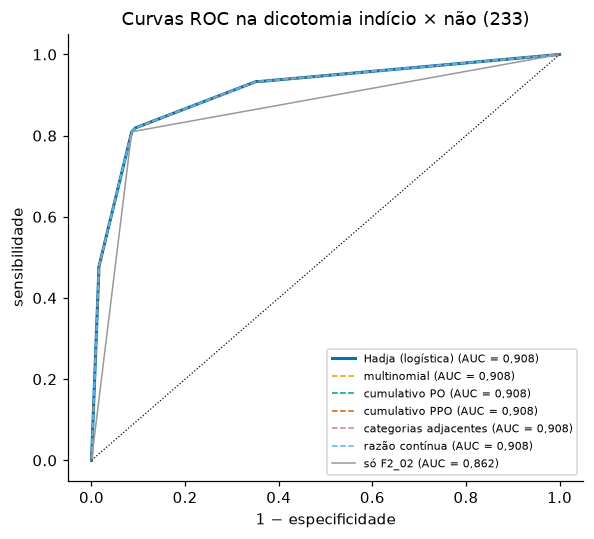

,F2_01,F2_02,F2_11,n,indicios,Hadja (logística),multinomial,cumulativo PO,cumulativo PPO,categorias adjacentes,razão contínua
0,0,0,0,89,7,"0,072","0,072","0,107","0,098","0,140","0,072"
1,0,0,1,45,12,"0,281","0,281","0,234","0,231","0,277","0,281"
2,0,1,1,1,1,"0,923","0,923","0,801","0,871","0,813","0,923"
3,1,0,0,1,0,"0,119","0,119","0,199","0,174","0,213","0,119"
4,1,0,1,2,1,"0,402","0,402","0,387","0,369","0,393","0,402"
5,1,1,0,44,35,"0,805","0,805","0,766","0,826","0,740","0,805"
6,1,1,1,51,49,"0,954","0,954","0,893","0,929","0,896","0,954"


In [59]:
# 9.2 ROC, AUC (DeLong e bootstrap), Gini e DeLong contra a Hadja (família E)
def p_ge1_cumul(r):
    return r['probs'][:, 1:].sum(1)
ESCORES = {'Hadja (logística)': p_hadja,
           'multinomial': np.asarray(MN.predict())[:, 1:].sum(1),
           'cumulativo PO': p_ge1_cumul(PO), 'cumulativo PPO': p_ge1_cumul(PPO),
           'categorias adjacentes': ACL['probs'][:, 1:].sum(1), 'razão contínua': np.asarray(RC1.predict())}
rng_auc = np.random.default_rng(SEMENTES['bootstrap'])
ROC = []
for nome, s in ESCORES.items():
    dl = C.delong(y_ind, s, p_hadja) if nome != 'Hadja (logística)' else C.delong(y_ind, s)
    boot = []
    for _ in range(2000):
        i = rng_auc.integers(0, n233, n233)
        if 0 < y_ind[i].sum() < n233:
            boot.append(C.delong(y_ind[i], s[i])['auc1'])
    ROC.append(dict(modelo=nome, AUC=dl['auc1'], ic_delong=fic(*dl['ic1'], casas=3), ic_boot=fic(*np.percentile(boot, [2.5, 97.5]), casas=3),
                    Gini=2 * dl['auc1'] - 1, dif_vs_hadja=dl.get('dif', 0.0), z=dl.get('z', np.nan), p=dl.get('p', np.nan),
                    escores_distintos=len(np.unique(np.round(s, 10)))))
ROC = pd.DataFrame(ROC)
ROC.loc[1:, 'p (Holm)'] = C.holm(ROC.p.iloc[1:])
display(tabela_ptbr(ROC, casas=4, p=['p', 'p (Holm)']))
for nome, s in ESCORES.items():
    C.confere(f'AUC {nome}', ROC.set_index('modelo').loc[nome, 'AUC'], GAB['auc_dicotomia']['hadja'], tol=1e-6, registro=CONFERENCIAS)
dl_02 = C.delong(y_ind, p_hadja, d233['F2_02'].astype(float).to_numpy())
C.confere('DeLong Hadja × só F2_02', dl_02['z'], GAB['delong_hadja_vs_so_F2_02']['z'], tol=1e-6, registro=CONFERENCIAS)
se_dif = abs(dl_02['dif'] / dl_02['z'])

from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(5.5, 5))
for (nome, s), cor in zip(ESCORES.items(), OKABE):
    fpr, tpr, _ = roc_curve(y_ind, s)
    ax.plot(fpr, tpr, color=cor, lw=2 if nome.startswith('Hadja') else 1, ls='-' if nome.startswith('Hadja') else '--',
            label=f'{nome} (AUC = {fnum(C.delong(y_ind, s)["auc1"], 3)})')
fpr, tpr, _ = roc_curve(y_ind, d233['F2_02'])
ax.plot(fpr, tpr, color='#999', lw=1, label=f'só F2_02 (AUC = {fnum(dl_02["auc2"], 3)})')
ax.plot([0, 1], [0, 1], 'k:', lw=0.8)
ax.set_xlabel('1 − especificidade'); ax.set_ylabel('sensibilidade'); ax.legend(fontsize=7.5, loc='lower right')
ax.set_title('Curvas ROC na dicotomia indício × não (233)')
fig.tight_layout(); fig.savefig(FIGURAS / 'roc_modelos.png', dpi=150); plt.show()

# os 7 padrões de preditores e a ordem dos escores em cada modelo
pad = d233.assign(**{k: v for k, v in ESCORES.items()}).groupby(X_HADJA).agg(n=('indicio', 'size'), indicios=('indicio', 'sum'),
                                                                               **{k: (k, 'first') for k in ESCORES}).reset_index()
display(tabela_ptbr(pad, casas=3))
ordem_igual = all(stats.spearmanr(pad['Hadja (logística)'], pad[k]).statistic > 0.999 for k in ESCORES)
assert len(pad) == GAB['hadja']['padroes_distintos'] and ordem_igual
rh = ROC.set_index('modelo').loc['Hadja (logística)']
V.update(auc_h=fnum(rh.AUC, 4), auc_h_ic=rh.ic_delong, auc_h_boot=rh.ic_boot, gini_h=fnum(rh.Gini, 3), n_padroes=fint(len(pad)),
         auc_02=fnum(dl_02['auc2'], 3), dl02_dif=fnum(dl_02['dif'], 3), dl02_ic=fic(dl_02['dif'] - C.Z95 * se_dif, dl_02['dif'] + C.Z95 * se_dif, 3),
         dl02_z=fnum(dl_02['z'], 2), dl02_p=fp(dl_02['p']), roc_max_dif=fnum(ROC.dif_vs_hadja.abs().max(), 6))

In [60]:
exibir('cp_roc', r'''
**Leitura (R14): na dicotomia, todos os modelos empatam, e isso tem uma razão matemática.**

- **AUC da Hadja:** {{auc_h}} (IC 95% de DeLong {{auc_h_ic}}; bootstrap {{auc_h_boot}}); Gini = {{gini_h}}.
- **Todos os modelos novos** têm exatamente a mesma AUC (maior diferença: {{roc_max_dif}}). O DeLong contra a Hadja dá z nulo e p igual a um em todos (família E).
- **Por que o empate.** Com três preditores binários, só existem {{n_padroes}} combinações observadas, e cada modelo dá um único escore a cada uma. A AUC depende só da **ordem** dos escores. A tabela dos padrões mostra que todos os modelos ordenam as combinações da mesma forma, embora as probabilidades difiram. A ROC não serve, portanto, para escolher entre eles: a escolha vem do AIC/BIC, do teste da suposição PO e da validação cruzada.
- **A F2_11 acrescenta discriminação real.** Contra o modelo só com F2_02 (AUC = {{auc_02}}), a diferença é de {{dl02_dif}} (IC 95% {{dl02_ic}}; DeLong z = {{dl02_z}}; {{dl02_p}}).
- **Cautela.** "AUC de {{auc_h}} = excelente" só vale **dentro dos {{funil_fase3}}**. O modelo pressupõe que o processo já tenha passado pela Fase II, e por isso não se aplica aos {{funil_n}}. O "Gini" daqui não é o "Gini de impureza" das árvores de decisão (HASTIE; TIBSHIRANI; FRIEDMAN, 2009, p. 310).
''')


**Leitura (R14): na dicotomia, todos os modelos empatam, e isso tem uma razão matemática.**

- **AUC da Hadja:** 0,9077 (IC 95% de DeLong [0,869; 0,947]; bootstrap [0,867; 0,944]); Gini = 0,815.
- **Todos os modelos novos** têm exatamente a mesma AUC (maior diferença: 0,000000). O DeLong contra a Hadja dá z nulo e p igual a um em todos (família E).
- **Por que o empate.** Com três preditores binários, só existem 7 combinações observadas, e cada modelo dá um único escore a cada uma. A AUC depende só da **ordem** dos escores. A tabela dos padrões mostra que todos os modelos ordenam as combinações da mesma forma, embora as probabilidades difiram. A ROC não serve, portanto, para escolher entre eles: a escolha vem do AIC/BIC, do teste da suposição PO e da validação cruzada.
- **A F2_11 acrescenta discriminação real.** Contra o modelo só com F2_02 (AUC = 0,862), a diferença é de 0,046 (IC 95% [0,020; 0,071]; DeLong z = 3,53; p < 0,001).
- **Cautela.** "AUC de 0,9077 = excelente" só vale **dentro dos 233**. O modelo pressupõe que o processo já tenha passado pela Fase II, e por isso não se aplica aos 595. O "Gini" daqui não é o "Gini de impureza" das árvores de decisão (HASTIE; TIBSHIRANI; FRIEDMAN, 2009, p. 310).


A validação cruzada reserva casos para avaliação e reajusta os modelos nos demais. Ela reduz o otimismo da AUC calculada nos dados de treino. Como as divisões se repetem sobre a mesma amostra, a dispersão entre repetições não deve ser lida como um novo intervalo populacional.

In [61]:
# 9.3 Validação cruzada estratificada repetida (5 × 20): AUC da Hadja e desempenho dos modelos de 3 classes
from sklearn.metrics import cohen_kappa_score, confusion_matrix, log_loss
from sklearn.model_selection import RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=C.inteiro_semente(SEMENTES['validacao_cruzada']))
Xh_c = sm.add_constant(d233[X_HADJA].astype(float))
auc_cv, res3 = [], {'multinomial': [], 'cumulativo PO': [], 'razão contínua': []}
with C.capturar_avisos('validação cruzada', AVISOS) as av_cv:
    for tr, te in cv.split(Xh_c, y_ind):
        m_ = sm.Logit(y_ind[tr], Xh_c.iloc[tr]).fit(disp=0, method='bfgs', maxiter=500)
        auc_cv.append(C.delong(y_ind[te], np.asarray(m_.predict(Xh_c.iloc[te])))['auc1'])
        mn_ = sm.MNLogit(y3[tr], Xh_c.iloc[tr]).fit(disp=0, method='bfgs', maxiter=1000)
        om_ = OrderedModel(y3[tr], X3.iloc[tr], distr='logit').fit(method='bfgs', disp=0, maxiter=1000)
        s1 = y3[tr] >= 1
        r2_ = sm.Logit((y3[tr][s1] == 2).astype(int), Xh_c.iloc[tr][s1][['const', 'F2_02', 'F2_11']]).fit(disp=0, method='bfgs', maxiter=500)
        p1, p2 = np.asarray(m_.predict(Xh_c.iloc[te])), np.asarray(r2_.predict(Xh_c.iloc[te][['const', 'F2_02', 'F2_11']]))
        probs_te = {'multinomial': np.asarray(mn_.predict(Xh_c.iloc[te])), 'cumulativo PO': np.asarray(om_.predict(X3.iloc[te])),
                    'razão contínua': np.column_stack([1 - p1, p1 * (1 - p2), p1 * p2])}
        for k_, pr_ in probs_te.items():
            res3[k_].append((log_loss(y3[te], pr_, labels=[0, 1, 2]), cohen_kappa_score(y3[te], pr_.argmax(1), weights='linear')))
C.confere('AUC CV Hadja', np.mean(auc_cv), GAB['cv_hadja']['auc_media'], tol=1e-6, registro=CONFERENCIAS)
CV3 = pd.DataFrame({k: {'log-loss médio': np.mean([a for a, _ in v]), 'kappa ponderado médio': np.mean([b for _, b in v]),
                        'DP do kappa': np.std([b for _, b in v])} for k, v in res3.items()}).T
display(tabela_ptbr(CV3.reset_index().rename(columns={'index': 'modelo'}), casas=3))
V.update(cv_auc=fnum(np.mean(auc_cv), 3), cv_dp=fnum(np.std(auc_cv), 3), cv_reps=fint(len(auc_cv)),
         cv_melhor=CV3['log-loss médio'].idxmin(), cv_ll_mn=fnum(CV3.loc['multinomial', 'log-loss médio'], 3),
         cv_ll_po=fnum(CV3.loc['cumulativo PO', 'log-loss médio'], 3), cv_ll_rc=fnum(CV3.loc['razão contínua', 'log-loss médio'], 3),
         cv_kp=fnum(CV3['kappa ponderado médio'].max(), 2), cv_avisos=fint(len(av_cv.lista)))

⚠ aviso [validação cruzada] HessianInversionWarning: Inverting hessian failed, no bse or cov_params available


,modelo,log-loss médio,kappa ponderado médio,DP do kappa
0,multinomial,"0,814","0,571","0,084"
1,cumulativo PO,"0,696","0,577","0,083"
2,razão contínua,"0,701","0,576","0,084"


In [62]:
exibir('cp_validacao', r'''
**Leitura: o desempenho se mantém fora da amostra, e a validação cruzada desempata os modelos de três classes.**

- **Hadja.** A AUC média fora da amostra é {{cv_auc}} (DP {{cv_dp}}; {{cv_reps}} partições). O otimismo da AUC na própria amostra é pequeno.
- **Três classes** (log-loss: menor é melhor):
  - multinomial: {{cv_ll_mn}};
  - cumulativo PO: {{cv_ll_po}};
  - razão contínua: {{cv_ll_rc}}.

  O melhor fora da amostra é o **{{cv_melhor}}**. O multinomial, que empatava no AIC, é o **pior** fora da amostra: os parâmetros livres da classe certeza ({{funil_certeza}} casos) se ajustam ao ruído. O kappa ponderado médio fica perto de {{cv_kp}} em todos.
- **Avisos.** Houve {{cv_avisos}} tipo(s) de aviso de ajuste nas partições, por quase separação em algumas reamostras.
''')


**Leitura: o desempenho se mantém fora da amostra, e a validação cruzada desempata os modelos de três classes.**

- **Hadja.** A AUC média fora da amostra é 0,899 (DP 0,043; 100 partições). O otimismo da AUC na própria amostra é pequeno.
- **Três classes** (log-loss: menor é melhor):
  - multinomial: 0,814;
  - cumulativo PO: 0,696;
  - razão contínua: 0,701.

  O melhor fora da amostra é o **cumulativo PO**. O multinomial, que empatava no AIC, é o **pior** fora da amostra: os parâmetros livres da classe certeza (30 casos) se ajustam ao ruído. O kappa ponderado médio fica perto de 0,58 em todos.
- **Avisos.** Houve 1 tipo(s) de aviso de ajuste nas partições, por quase separação em algumas reamostras.


A matriz de confusão traduz escores em decisões num corte explícito. Sensibilidade, especificidade e valor preditivo respondem a perguntas distintas; a classe de certeza merece atenção própria porque erros nela têm significado substantivo diferente.

In [63]:
# 9.4 Matrizes de confusão: 2 × 2 no corte 0,5 (D5) e no de Youden (sensibilidade); 3 × 3 com kappa ponderado
def m2(y, s, corte):
    pr = (s >= corte).astype(int)
    vn, fp_, fn, vp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return dict(corte=corte, VP=vp, FP=fp_, FN=fn, VN=vn, sens=vp / (vp + fn), esp=vn / (vn + fp_), VPP=vp / (vp + fp_),
                VPN=vn / (vn + fn), acuracia=(vp + vn) / len(y), kappa=cohen_kappa_score(y, pr))
fpr, tpr, cortes_roc = roc_curve(y_ind, p_hadja)
youden = float(cortes_roc[np.argmax(tpr - fpr)])
M2 = pd.DataFrame([m2(y_ind, p_hadja, 0.5), m2(y_ind, p_hadja, youden)], index=['0,5 (D5, principal)', 'Youden (sensibilidade)'])
display(tabela_ptbr(M2.reset_index().astype({c: int for c in ('VP', 'FP', 'FN', 'VN')}), casas=3))
M3 = {}
p_rc1 = np.asarray(RC1.predict())
p_rc2 = np.asarray(RC2_red.predict(sm.add_constant(X3[['F2_02', 'F2_11']])))   # passo 2 sem o termo redundante
for nome, pr in [('multinomial', np.asarray(MN.predict())), ('cumulativo PO', PO['probs']),
                 ('razão contínua', np.column_stack([1 - p_rc1, p_rc1 * (1 - p_rc2), p_rc1 * p_rc2]))]:
    cm = confusion_matrix(y3, pr.argmax(1), labels=[0, 1, 2])
    M3[nome] = dict(matriz=cm, kappa_pond=cohen_kappa_score(y3, pr.argmax(1), weights='linear'),
                    acerto_certeza=cm[2, 2] / cm[2].sum())
    display(pd.DataFrame(cm, index=[f'real: {n}' for n in NIVEIS_CLASSE3], columns=[f'previsto: {n}' for n in NIVEIS_CLASSE3]).rename_axis(nome))
assert M3['cumulativo PO']['matriz'].tolist() == GAB['ordinal_3classes']['matriz_3x3']
V.update(m2_sens=fnum(M2.sens.iloc[0], 3), m2_esp=fnum(M2.esp.iloc[0], 3), m2_vpp=fnum(M2.VPP.iloc[0], 3), m2_vpn=fnum(M2.VPN.iloc[0], 3),
         m2_kappa=fnum(M2.kappa.iloc[0], 3), m2_acur=fnum(M2.acuracia.iloc[0], 3), youden=fnum(youden, 3),
         y_sens=fnum(M2.sens.iloc[1], 3), y_esp=fnum(M2.esp.iloc[1], 3),
         **{f'k3_{i}': fnum(v['kappa_pond'], 2) for i, v in enumerate(M3.values())},
         cert_prevista=fint(sum(v['matriz'][:, 2].sum() for v in M3.values())))

,index,corte,VP,FP,FN,VN,sens,esp,VPP,VPN,acuracia,kappa
0,"0,5 (D5, principal)","0,500",85,11,20,117,"0,810","0,914","0,885","0,854","0,867","0,729"
1,Youden (sensibilidade),"0,402",86,12,19,116,"0,819","0,906","0,878","0,859","0,867","0,730"


,previsto: não predatória,previsto: indício sem certeza,previsto: certeza
multinomial,,,
real: não predatória,117,11,0
real: indício sem certeza,13,62,0
real: certeza,7,23,0


,previsto: não predatória,previsto: indício sem certeza,previsto: certeza
cumulativo PO,,,
real: não predatória,117,11,0
real: indício sem certeza,13,62,0
real: certeza,7,23,0


,previsto: não predatória,previsto: indício sem certeza,previsto: certeza
razão contínua,,,
real: não predatória,117,11,0
real: indício sem certeza,13,62,0
real: certeza,7,23,0


In [64]:
exibir('cp_confusao', r'''
**Leitura (R13): nenhum modelo novo supera a Hadja na tarefa que ela resolve, e nenhum resolve a tarefa que ela não resolve.**

- **No corte 0,5** (decidido antes, D5): sensibilidade {{m2_sens}}, especificidade {{m2_esp}}, VPP {{m2_vpp}}, VPN {{m2_vpn}}, acurácia {{m2_acur}}, kappa {{m2_kappa}}.
- **No corte de Youden** ({{youden}}): sensibilidade {{y_sens}} e especificidade {{y_esp}}. Com só {{n_padroes}} escores possíveis, os cortes efetivos são poucos, e a escolha quase não muda nada.
- **Nas três classes**, os três modelos dão a **mesma** matriz. A certeza é prevista {{cert_prevista}} vezes: os {{funil_certeza}} casos de certeza caem em "não predatória" ou em "indício". O kappa ponderado é {{k3_0}} (multinomial), {{k3_1}} (PO) e {{k3_2}} (razão contínua).

**Resposta ao R13 e ao R14.**
1. **Melhor ajuste entre os novos:** o PPO pelo BIC e a razão contínua ou o PO fora da amostra. O PO puro é rejeitado pelo teste de proporcionalidade.
2. **Superam a Hadja?** Na dicotomia, **não**: a ROC, o Gini e o DeLong dão empate exato. O ganho dos modelos novos é **descritivo**. Eles mostram que os sinais pesam diferente em cada degrau do funil.
3. **Certeza.** Nenhum modelo baseado nos F2 distingue a certeza do indício, porque a informação que a define (F3_18) não está na petição.
''')


**Leitura (R13): nenhum modelo novo supera a Hadja na tarefa que ela resolve, e nenhum resolve a tarefa que ela não resolve.**

- **No corte 0,5** (decidido antes, D5): sensibilidade 0,810, especificidade 0,914, VPP 0,885, VPN 0,854, acurácia 0,867, kappa 0,729.
- **No corte de Youden** (0,402): sensibilidade 0,819 e especificidade 0,906. Com só 7 escores possíveis, os cortes efetivos são poucos, e a escolha quase não muda nada.
- **Nas três classes**, os três modelos dão a **mesma** matriz. A certeza é prevista 0 vezes: os 30 casos de certeza caem em "não predatória" ou em "indício". O kappa ponderado é 0,58 (multinomial), 0,58 (PO) e 0,58 (razão contínua).

**Resposta ao R13 e ao R14.**
1. **Melhor ajuste entre os novos:** o PPO pelo BIC e a razão contínua ou o PO fora da amostra. O PO puro é rejeitado pelo teste de proporcionalidade.
2. **Superam a Hadja?** Na dicotomia, **não**: a ROC, o Gini e o DeLong dão empate exato. O ganho dos modelos novos é **descritivo**. Eles mostram que os sinais pesam diferente em cada degrau do funil.
3. **Certeza.** Nenhum modelo baseado nos F2 distingue a certeza do indício, porque a informação que a define (F3_18) não está na petição.


## 10. Classificador Não Supervisionado Ordinal (R15, R16)

### 10.1 O que o roteiro pede e como se resolve

O roteiro pede um classificador **não supervisionado**, treinado **a partir dos dados novos coletados, com os desfechos**, que separe **em ordem** as lides não predatórias, os indícios e as certezas. Esse classificador deve depois ser aplicado aos dados do DataJud (R15–R18).

- **Supervisionado** aprende com rótulos. **Não supervisionado** procura grupos sem rótulos e não tem medida direta de acerto (HASTIE; TIBSHIRANI; FRIEDMAN, 2009, p. 485–487).
- **O modelo é a análise de classes latentes (LCA).** Ela supõe que cada processo pertence a uma classe **não observada** e que, dentro de cada classe, os indicadores são independentes. É uma mistura de distribuições categóricas, estimada pelo algoritmo EM (EVERITT; SKRONDAL, 2010, p. 243; MURPHY, 2012, cap. 11). O EM está implementado em `comum.lca_categorica` (vários inícios, semente própria) e conferido com a `stepmix` nos testes.
- **Os indicadores (dados novos)** vêm do DataJud para os processos com documento:
  - desfecho em cinco categorias;
  - recurso à Turma Recursal;
  - evolução para cumprimento;
  - redistribuição;
  - tercis do tempo até o desfecho;
  - tercis do número de movimentos;
  - assunto principal.

  Nenhum F2 ou F3 entra no treino: eles não existem no DataJud.
- **Três classes, por desenho.** O roteiro pede três níveis, e por isso K = 3 é fixado. O BIC de K = 1 a 5 é relatado para mostrar quantas classes os dados sustentam.
- **Regra de ordenação, fixada antes da matriz de confusão.** As classes saem sem ordem (*label switching*). Elas são ordenadas por um escore analítico: P(extinção sem mérito ou sem sentença | classe) − P(acordo | classe). O sentido vem das razões de verossimilhança da Seção 6: extinção > 1 e acordo < 1. A regra usa a **direção** daquele resultado, mas não os rótulos de cada processo.
- **Validação externa.** A rotulagem da Hadja é uma referência substantiva: entra na matriz, mas os mesmos processos participaram do ajuste da mistura; a avaliação é exploratória.

**Comparações** (mesmos 233 da Fase III, sobre os F2):
1. a LCA dos F2 ativos, que mostra o teto do que os sinais da petição separam;
2. a mesma LCA com as F3, que mostra a **circularidade**: as F3 definem a classe3;
3. o k-modes;
4. o k-means sobre as coordenadas da MCA.

Um estudo de **recuperação por simulação** vem antes da interpretação.

Para aplicar o modelo à moldura, categorias e cortes numéricos devem ser idênticos nos dados de treino e nos novos processos. O código guarda essa codificação. Ela representa trajetória administrativa, não contém os sinais da petição nem a massificação que definem o rótulo jurídico.

In [65]:
# 10.1 Codificação dos indicadores do DataJud (os pontos de corte e as categorias ficam guardados para a população)
l10 = dj[dj.desfecho.notna()].reset_index(drop=True).copy()
DESF5 = {'acordo': 'acordo', 'procedencia': 'procedência', 'procedencia_parcial': 'procedência',
         'improcedencia': 'improcedência/outro mérito', 'prescricao_decadencia': 'improcedência/outro mérito',
         'homologacao_pedido': 'improcedência/outro mérito', 'renuncia_ao_direito': 'improcedência/outro mérito',
         'sentenca_juiz_leigo_sem_resultado': 'improcedência/outro mérito'}
def desfecho5(cat, grupo):
    return DESF5.get(cat, 'extinção sem mérito' if grupo == 'extinção sem mérito' else 'sem sentença registrada')
NIV_DESF5 = ['acordo', 'procedência', 'improcedência/outro mérito', 'extinção sem mérito', 'sem sentença registrada']
ASSUNTOS_TOP = l10['assunto_principal'].value_counts().index[:4].tolist()
CORTES_T = np.quantile(l10['t_desfecho'].astype(float), [1 / 3, 2 / 3])
CORTES_M = np.quantile(l10['n_movimentos'].astype(float), [1 / 3, 2 / 3])
CODIF = dict(desf5=NIV_DESF5, assuntos=ASSUNTOS_TOP, cortes_t=CORTES_T.tolist(), cortes_m=CORTES_M.tolist())
IND_DJ = ['desfecho5', 'houve_recurso', 'evoluiu_cumprimento', 'redistribuido', 'tempo_tercil', 'movimentos_tercil', 'assunto']

def codificar_dj(df):
    """Mesma codificação para amostra e população; −1 = ausente."""
    out = pd.DataFrame(index=df.index)
    out['desfecho5'] = [NIV_DESF5.index(desfecho5(c, str(g))) for c, g in zip(df.desfecho_categoria, df.desfecho)]
    for c in ('houve_recurso', 'evoluiu_cumprimento', 'redistribuido'):
        out[c] = df[c].astype(bool).astype(int)
    t = df['t_desfecho'].astype(float); m_ = df['n_movimentos'].astype(float)
    out['tempo_tercil'] = np.where(t.isna(), -1, np.digitize(t, CORTES_T))
    out['movimentos_tercil'] = np.where(m_.isna(), -1, np.digitize(m_, CORTES_M))
    out['assunto'] = [ASSUNTOS_TOP.index(a) if a in ASSUNTOS_TOP else len(ASSUNTOS_TOP) for a in df['assunto_principal']]
    return out.astype(int)
XDJ = codificar_dj(l10)
assert (XDJ >= 0).all().all() and len(XDJ) == len(proc)
display(pd.DataFrame({c: XDJ[c].value_counts().sort_index().to_dict() for c in IND_DJ}).T.fillna(0).astype(int))
V.update(dj_assuntos=', '.join(ASSUNTOS_TOP), dj_cortes_t=' e '.join(fnum(c, 0) for c in CORTES_T))

,0,1,2,3,4
desfecho5,65,289,88,142,9
houve_recurso,439,154,0,0,0
evoluiu_cumprimento,368,225,0,0,0
redistribuido,577,16,0,0,0
tempo_tercil,198,197,198,0,0
movimentos_tercil,190,202,201,0,0
assunto,127,107,44,40,275


A análise de classes latentes procura perfis de coocorrência sem usar a classificação da pesquisa no ajuste. Fixar três grupos permite cumprir o exercício; BIC e testes de sensibilidade mostram se os próprios registros sustentam essa escolha. A ordenação por desfecho é uma hipótese interpretativa.

In [66]:
# 10.2 LCA nos dados do DataJud: K = 1..5 (BIC, entropia), BLRT, K = 3 ordenado pela regra fixada
rng_lca = np.random.default_rng(SEMENTES['lca'])
LCA_DJ = {K: C.lca_categorica(XDJ.to_numpy(), K, rng_lca, n_init=30) for K in range(1, 6)}
SEL_DJ = pd.DataFrame({K: dict(logL=m['ll'], parametros=m['n_par'], BIC=m['bic'], AIC=m['aic'], entropia=m['entropia'])
                       for K, m in LCA_DJ.items()}).T
display(tabela_ptbr(SEL_DJ.reset_index().rename(columns={'index': 'K'}).astype({'K': int, 'parametros': int}), casas=3))
BLRT_DJ = {K: C.blrt(XDJ.to_numpy(), K, rng_lca, B=39, n_init=5) for K in (2, 3)}
from stepmix.stepmix import StepMix
sm3 = StepMix(n_components=3, measurement='categorical', n_init=20, verbose=0, progress_bar=0,
              random_state=C.inteiro_semente(SEMENTES['lca'])).fit(XDJ.to_numpy())
assert sm3.score(XDJ.to_numpy()) * len(XDJ) <= LCA_DJ[3]['ll'] + 1e-3, 'stepmix achou verossimilhança maior que o EM próprio'

def escore_ordem(m):
    th = m['theta'][IND_DJ.index('desfecho5')]
    return th[:, [NIV_DESF5.index('extinção sem mérito'), NIV_DESF5.index('sem sentença registrada')]].sum(1) - th[:, 0]
M_DJ = C.lca_reordenar(LCA_DJ[3], np.argsort(escore_ordem(LCA_DJ[3])))
perfil = pd.DataFrame({f'classe latente {k}': np.r_[M_DJ['pi'][k], M_DJ['theta'][0][k]] for k in range(3)},
                      index=['peso π'] + [f'P(desfecho = {n})' for n in NIV_DESF5])
for nome, j in [('P(recurso)', 1), ('P(evoluiu p/ cumprimento)', 2), ('P(redistribuído)', 3), ('P(tempo no 1º tercil)', 4)]:
    perfil.loc[nome] = [M_DJ['theta'][j][k, 1 if j < 4 else 0] for k in range(3)]
display(perfil.round(3))
V.update(lcadj_bic_min=str(int(SEL_DJ.BIC.idxmin())), lcadj_bic3=fnum(SEL_DJ.loc[3, 'BIC'], 1), lcadj_ent3=fnum(SEL_DJ.loc[3, 'entropia'], 3),
         lcadj_blrt2=fp(BLRT_DJ[2]['p']), blrt_pmin=fnum(1 / (BLRT_DJ[2]['B'] + 1), 3), lcadj_blrt3=fp(BLRT_DJ[3]['p']), lcadj_B=fint(BLRT_DJ[2]['B']),
         **{f'lcadj_pi{k}': fpct(M_DJ['pi'][k], 1) for k in range(3)},
         **{f'lcadj_ext{k}': fpct(M_DJ['theta'][0][k, 3], 1) for k in range(3)},
         **{f'lcadj_aco{k}': fpct(M_DJ['theta'][0][k, 0], 1) for k in range(3)},
         **{f'lcadj_rec{k}': fpct(M_DJ['theta'][1][k, 1], 1) for k in range(3)})

,K,logL,parametros,BIC,AIC,entropia
0,1,"-3.682,092",15,"7.459,962","7.394,184","1,000"
1,2,"-3.342,133",31,"6.882,207","6.746,266","0,863"
2,3,"-3.264,687",47,"6.829,478","6.623,374","0,873"
3,4,"-3.212,765",63,"6.827,797","6.551,530","0,848"
4,5,"-3.168,682",79,"6.841,795","6.495,364","0,868"


,classe latente 0,classe latente 1,classe latente 2
peso π,"0,3960","0,3510","0,2530"
P(desfecho = acordo),"0,0440","0,0930","0,2360"
P(desfecho = procedência),"0,8600","0,3930","0,0340"
P(desfecho = improcedência/outro mérito),"0,0870","0,2550","0,0970"
P(desfecho = extinção sem mérito),"0,0040","0,2210","0,6330"
P(desfecho = sem sentença registrada),"0,0040","0,0380","0,0000"
P(recurso),"0,3540","0,3380","0,0030"
P(evoluiu p/ cumprimento),"0,9580","0,0000","0,0000"
P(redistribuído),"0,0180","0,0420","0,0200"
P(tempo no 1º tercil),"0,2380","0,1550","0,7330"


In [67]:
exibir('ns_lca_datajud', r'''
**Leitura (R15): as classes latentes do DataJud são trajetórias processuais.**

- **Número de classes.** O BIC é mínimo em K = {{lcadj_bic_min}}; com K = 3, o BIC é {{lcadj_bic3}} e a entropia relativa é {{lcadj_ent3}}. O BLRT ({{lcadj_B}} réplicas paramétricas) dá {{lcadj_blrt2}} para uma classe contra duas e {{lcadj_blrt3}} para duas contra três (com {{lcadj_B}} réplicas, o menor p possível é {{blrt_pmin}}). Os dados sustentam pelo menos três grupos.
- **As três classes, na ordem fixada a priori:**

| | L-baixa | L-média | L-alta |
|---|---|---|---|
| peso | {{lcadj_pi0}} | {{lcadj_pi1}} | {{lcadj_pi2}} |
| P(extinção sem mérito) | {{lcadj_ext0}} | {{lcadj_ext1}} | {{lcadj_ext2}} |
| P(acordo) | {{lcadj_aco0}} | {{lcadj_aco1}} | {{lcadj_aco2}} |
| P(recurso) | {{lcadj_rec0}} | {{lcadj_rec1}} | {{lcadj_rec2}} |

  Na tabela de perfis acima, a L-baixa reúne as procedências que viram cumprimento de sentença. A L-média mistura mérito e extinção, sem cumprimento. A L-alta concentra extinções e acordos.
- **A classe latente não é a classe jurídica.** É um padrão de co-ocorrência dos registros processuais (JAMES et al., 2013, p. 400–401). Todo algoritmo de agrupamento encontra grupos, existam eles ou não. Só a validação externa diz se os grupos significam algo para a pergunta.

Assuntos codificados: {{dj_assuntos}} e "outros". Tercis do tempo cortados em {{dj_cortes_t}} dias.
''')


**Leitura (R15): as classes latentes do DataJud são trajetórias processuais.**

- **Número de classes.** O BIC é mínimo em K = 4; com K = 3, o BIC é 6.829,5 e a entropia relativa é 0,873. O BLRT (39 réplicas paramétricas) dá p = 0,0250 para uma classe contra duas e p = 0,0250 para duas contra três (com 39 réplicas, o menor p possível é 0,025). Os dados sustentam pelo menos três grupos.
- **As três classes, na ordem fixada a priori:**

| | L-baixa | L-média | L-alta |
|---|---|---|---|
| peso | 39,6% | 35,1% | 25,3% |
| P(extinção sem mérito) | 0,4% | 22,1% | 63,3% |
| P(acordo) | 4,4% | 9,3% | 23,6% |
| P(recurso) | 35,4% | 33,8% | 0,3% |

  Na tabela de perfis acima, a L-baixa reúne as procedências que viram cumprimento de sentença. A L-média mistura mérito e extinção, sem cumprimento. A L-alta concentra extinções e acordos.
- **A classe latente não é a classe jurídica.** É um padrão de co-ocorrência dos registros processuais (JAMES et al., 2013, p. 400–401). Todo algoritmo de agrupamento encontra grupos, existam eles ou não. Só a validação externa diz se os grupos significam algo para a pergunta.

Assuntos codificados: Indenização por Dano Moral, Inclusão Indevida em Cadastro de Inadimplentes, Indenização por Dano Material, Obrigação de Fazer / Não Fazer e "outros". Tercis do tempo cortados em 64 e 129 dias.


A matriz confronta grupos de trajetória com os rótulos atribuídos na pesquisa. É uma checagem de significado, mas usa os mesmos processos que ajustaram a mistura e orientaram a regra de ordenação. Portanto, não é uma estimativa independente de desempenho em casos futuros.

In [68]:
# 10.3 Matriz de confusão 3 × 3 contra a rotulagem da Hadja (padrão-ouro externo) e indicadores de eficiência
from sklearn.metrics import classification_report
def avaliar(real, prev):
    cm = confusion_matrix(real, prev, labels=[0, 1, 2])
    rel = classification_report(real, prev, labels=[0, 1, 2], output_dict=True, zero_division=0)
    esp_ = [(cm.sum() - cm[k].sum() - cm[:, k].sum() + cm[k, k]) / (cm.sum() - cm[k].sum()) for k in range(3)]
    dic = dict(matriz=cm, kappa=cohen_kappa_score(real, prev), kappa_pond=cohen_kappa_score(real, prev, weights='linear'),
               acuracia=(np.trace(cm)) / cm.sum(), sens=[rel[str(k)]['recall'] for k in range(3)], esp=esp_,
               f1=[rel[str(k)]['f1-score'] for k in range(3)], f1_macro=rel['macro avg']['f1-score'])
    rb, pb = (np.asarray(real) >= 1), (np.asarray(prev) >= 1)          # dicotomia indício (≥ 1) × não
    dic.update(sens_bin=(rb & pb).sum() / rb.sum(), esp_bin=(~rb & ~pb).sum() / (~rb).sum())
    rc_, pc_ = (np.asarray(real) == 2), (np.asarray(prev) == 2)
    dic.update(sens_cert=(rc_ & pc_).sum() / rc_.sum(), esp_cert=(~rc_ & ~pc_).sum() / (~rc_).sum())
    return dic

def mostrar_matriz(cm, titulo):
    display(pd.DataFrame(cm, index=[f'Hadja: {n}' for n in NIVEIS_CLASSE3], columns=['L-baixa', 'L-média', 'L-alta']).rename_axis(titulo))

AV_DJ = avaliar(l10.classe3_cod.astype(int), M_DJ['classe'])
mostrar_matriz(AV_DJ['matriz'], 'LCA DataJud (593)')
ind_tab = pd.DataFrame({'sensibilidade': AV_DJ['sens'], 'especificidade': AV_DJ['esp'], 'F1': AV_DJ['f1']}, index=NIVEIS_CLASSE3)
display(ind_tab.round(3))
J_DJ = AV_DJ['sens_bin'] + AV_DJ['esp_bin'] - 1
V.update(av_kappa=fnum(AV_DJ['kappa'], 3), av_kpond=fnum(AV_DJ['kappa_pond'], 3), av_acur=fnum(AV_DJ['acuracia'], 3),
         av_f1=fnum(AV_DJ['f1_macro'], 3), av_sens_bin=fnum(AV_DJ['sens_bin'], 3), av_esp_bin=fnum(AV_DJ['esp_bin'], 3),
         av_J=fnum(J_DJ, 3), av_sens_cert=fnum(AV_DJ['sens_cert'], 3), av_esp_cert=fnum(AV_DJ['esp_cert'], 3))

,L-baixa,L-média,L-alta
LCA DataJud (593),,,
Hadja: não predatória,193,170,125
Hadja: indício sem certeza,23,29,23
Hadja: certeza,9,14,7


,sensibilidade,especificidade,F1
não predatória,"0,3950","0,6950","0,5410"
indício sem certeza,"0,3870","0,6450","0,2010"
certeza,"0,2330","0,7370","0,0760"


In [69]:
exibir('ns_confusao_datajud', r'''
**Leitura (R16): os perfis do DataJud praticamente não concordam com a rotulagem da Hadja.**

- **Concordância.** Kappa = {{av_kappa}}; kappa ponderado = {{av_kpond}}; acurácia = {{av_acur}}; F1 médio = {{av_f1}}.
- **Na dicotomia indício × não** (classe ≥ L-média contra L-baixa), a sensibilidade é {{av_sens_bin}} e a especificidade {{av_esp_bin}}. O índice de Youden (J = sens + esp − um) é **{{av_J}}**: perto de zero, que é o acaso.
- **Para a certeza** (L-alta), a sensibilidade é {{av_sens_cert}} e a especificidade {{av_esp_cert}}.

**Por que isso acontece, e por que era esperado.** A Seção 6 mostrou que o desfecho é evidência fraca (RV perto de um). As outras variáveis do DataJud (recurso, cumprimento, tempo) descrevem a **trajetória do processo depois do ajuizamento**. O assunto é a exceção, mas na LCA ele pesa pouco diante dos indicadores de trajetória. A predação, pela definição da pesquisa, está na **petição** (F2) e na **massificação** (F3), e nenhuma dessas leituras está no DataJud. A análise cobre o exercício do roteiro (não supervisionado, ordinal, treinado nos dados novos com os desfechos), mas a **trajetória** processual, que domina a variação desses registros, não carrega a informação necessária para separar as classes. O sinal que existe no DataJud está no assunto, e só aparece com supervisão (Seção 10.6). A matriz é calculada nos mesmos processos usados para ajustar os grupos; não é validação independente.
''')


**Leitura (R16): os perfis do DataJud praticamente não concordam com a rotulagem da Hadja.**

- **Concordância.** Kappa = 0,024; kappa ponderado = 0,027; acurácia = 0,386; F1 médio = 0,273.
- **Na dicotomia indício × não** (classe ≥ L-média contra L-baixa), a sensibilidade é 0,695 e a especificidade 0,395. O índice de Youden (J = sens + esp − um) é **0,091**: perto de zero, que é o acaso.
- **Para a certeza** (L-alta), a sensibilidade é 0,233 e a especificidade 0,737.

**Por que isso acontece, e por que era esperado.** A Seção 6 mostrou que o desfecho é evidência fraca (RV perto de um). As outras variáveis do DataJud (recurso, cumprimento, tempo) descrevem a **trajetória do processo depois do ajuizamento**. O assunto é a exceção, mas na LCA ele pesa pouco diante dos indicadores de trajetória. A predação, pela definição da pesquisa, está na **petição** (F2) e na **massificação** (F3), e nenhuma dessas leituras está no DataJud. A análise cobre o exercício do roteiro (não supervisionado, ordinal, treinado nos dados novos com os desfechos), mas a **trajetória** processual, que domina a variação desses registros, não carrega a informação necessária para separar as classes. O sinal que existe no DataJud está no assunto, e só aparece com supervisão (Seção 10.6). A matriz é calculada nos mesmos processos usados para ajustar os grupos; não é validação independente.


### Verificação temporal fora do ajuste

A matriz anterior usa os mesmos processos que serviram para ajustar a mistura. Para examinar se a correspondência entre perfis e rótulos se mantém em casos não vistos, o modelo abaixo é ajustado apenas com processos de 2022 e 2023. Cortes de tempo e assuntos frequentes também são definidos nesse grupo de treino. Os processos de 2024 entram somente na atribuição de perfil e no confronto final com a classificação da pesquisa. A regra de ordenar os perfis continua a mesma, sem usar os rótulos de 2024.

Uma baixa concordância nessa avaliação reforça a limitação de informação do DataJud. Mesmo uma concordância alta ainda precisaria de validação dos desfechos nos autos e de outra amostra para sustentar uso individual.


In [70]:
# LCA ajustada em 2022–2023 e examinada nos processos de 2024
from sklearn.metrics import cohen_kappa_score, confusion_matrix
treino = (l10.ano.astype(int).to_numpy() < 2024)
teste = ~treino
X_T = XDJ.copy()
for bruto, codificado in [('t_desfecho', 'tempo_tercil'), ('n_movimentos', 'movimentos_tercil')]:
    cortes = np.quantile(l10.loc[treino, bruto].astype(float), [1 / 3, 2 / 3])
    valores = l10[bruto].astype(float)
    X_T[codificado] = np.where(valores.isna(), -1, np.digitize(valores, cortes))
top_assuntos = l10.loc[treino, 'assunto_principal'].value_counts().index[:4].tolist()
X_T['assunto'] = [top_assuntos.index(a) if a in top_assuntos else 4 for a in l10.assunto_principal]
rng_hold = np.random.default_rng(SEMENTES['lca'])
modelo_hold = C.lca_categorica(X_T.loc[treino, IND_DJ].to_numpy(), 3, rng_hold, n_init=20)
modelo_hold = C.lca_reordenar(modelo_hold, np.argsort(escore_ordem(modelo_hold)))
X_2024 = X_T.loc[teste, IND_DJ].to_numpy().copy()
for j, nc in enumerate(modelo_hold['ncat']):
    X_2024[X_2024[:, j] >= nc, j] = -1  # categoria não vista no treino: marginalizar
prev_2024 = C.lca_posteriori(modelo_hold, X_2024).argmax(1)
real_2024 = l10.loc[teste, 'classe3_cod'].astype(int).to_numpy()
cm_2024 = confusion_matrix(real_2024, prev_2024, labels=[0, 1, 2])
rb, pb = real_2024 >= 1, prev_2024 >= 1
se_2024 = (rb & pb).sum() / rb.sum()
es_2024 = (~rb & ~pb).sum() / (~rb).sum()
j_2024 = se_2024 + es_2024 - 1
kp_2024 = cohen_kappa_score(real_2024, prev_2024, weights='linear')
display(pd.DataFrame(cm_2024, index=[f'pesquisa: {n}' for n in NIVEIS_CLASSE3],
                     columns=[f'perfil {i}' for i in (1, 2, 3)]))
display(pd.Series({'treino 2022–2023': int(treino.sum()), 'avaliação 2024': int(teste.sum()),
                   'kappa ponderado 2024': kp_2024, 'sensibilidade indício 2024': se_2024,
                   'especificidade indício 2024': es_2024, 'J de Youden 2024': j_2024},
                  name='avaliação temporal').to_frame())
display(Markdown(f'**Leitura.** Nos {int(teste.sum())} processos de 2024, mantidos fora do ajuste, '
                 f'o kappa ponderado foi {fnum(kp_2024, 3)} e o índice J de Youden foi {fnum(j_2024, 3)}. '
                 'Essa avaliação mede correspondência com a rotulagem da pesquisa em outro ano, '
                 'não valida o desfecho inferido da TPU nem autoriza triagem individual.'))


,perfil 1,perfil 2,perfil 3
pesquisa: não predatória,69,49,44
pesquisa: indício sem certeza,4,7,7
pesquisa: certeza,4,3,3


,avaliação temporal
treino 2022–2023,"403,0000"
avaliação 2024,"190,0000"
kappa ponderado 2024,"0,0422"
sensibilidade indício 2024,"0,7143"
especificidade indício 2024,"0,4259"
J de Youden 2024,"0,1402"


**Leitura.** Nos 190 processos de 2024, mantidos fora do ajuste, o kappa ponderado foi 0,042 e o índice J de Youden foi 0,140. Essa avaliação mede correspondência com a rotulagem da pesquisa em outro ano, não valida o desfecho inferido da TPU nem autoriza triagem individual.

Comparar agrupamentos nos mesmos 233 processos separa duas questões: os F2 contêm sinais da petição; o DataJud contém a trajetória posterior. Incluir F3 eleva a concordância por construção, pois F3 participa diretamente da definição da classe jurídica.

In [71]:
# 10.4 Comparações nos 233: LCA dos F2 (com e sem F3), k-modes e k-means sobre a MCA
from kmodes.kmodes import KModes
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
XF2 = d233[F2_ATIVOS].astype(int).to_numpy()
XF23 = np.column_stack([XF2, d233[F3].fillna(False).astype(int).to_numpy()])
nF2 = XF2.sum(1)
def ordenar_por_nF2(classes):
    medias = [nF2[classes == g].mean() if (classes == g).any() else -1 for g in range(3)]
    mapa = {g: i for i, g in enumerate(np.argsort(medias))}
    return np.vectorize(mapa.get)(classes), np.sort(medias)
LCA_F2 = {K: C.lca_categorica(XF2, K, rng_lca, n_init=30) for K in range(1, 6)}
SEL_F2 = pd.DataFrame({K: dict(BIC=m['bic'], entropia=m['entropia']) for K, m in LCA_F2.items()}).T
C.confere('BIC LCA F2 K = 2', SEL_F2.loc[2, 'BIC'], GAB['lca_f2']['2']['bic'], tol=1e-3, registro=CONFERENCIAS)
BLRT_F2 = C.blrt(XF2, 3, rng_lca, B=39, n_init=5)
LCA_F23 = C.lca_categorica(XF23, 3, rng_lca, n_init=30)
km = KModes(n_clusters=3, init='Huang', n_init=20, random_state=C.inteiro_semente(SEMENTES['kmodes'])).fit(XF2)
kmeans = KMeans(n_clusters=3, n_init=20, random_state=C.inteiro_semente(SEMENTES['kmodes'])).fit(MCA_COORD)
y233 = d233.classe3_cod.astype(int).to_numpy()
COMP = {}
for nome, cl in [('LCA F2 (8 ativos)', LCA_F2[3]['classe']), ('LCA F2 + F3 (circular)', LCA_F23['classe']),
                 ('k-modes (init Huang)', km.labels_), ('k-means sobre a MCA', kmeans.labels_)]:
    ordem_, medias_ = ordenar_por_nF2(np.asarray(cl))
    COMP[nome] = avaliar(y233, ordem_) | dict(medias=medias_, ari=adjusted_rand_score(y233, ordem_))
COMP['LCA DataJud (os mesmos 233)'] = avaliar(y233, pd.Series(M_DJ['classe'], index=l10.numero.to_numpy()).loc[d233.numero.to_numpy()].to_numpy())
TAB_COMP = pd.DataFrame({k: dict(kappa_ponderado=v['kappa_pond'], acuracia=v['acuracia'], F1_macro=v['f1_macro'],
                                 sens_indicio_bin=v['sens_bin'], esp_bin=v['esp_bin'], sens_certeza=v['sens_cert'])
                         for k, v in COMP.items()}).T
display(tabela_ptbr(TAB_COMP.reset_index().rename(columns={'index': 'classificador'}), casas=3))
mostrar_matriz(COMP['LCA F2 (8 ativos)']['matriz'], 'LCA F2, K = 3 (233)')
display(tabela_ptbr(SEL_F2.reset_index().rename(columns={'index': 'K'}), casas=3))
V.update(f2_bic2=fnum(SEL_F2.loc[2, 'BIC'], 1), f2_bic3=fnum(SEL_F2.loc[3, 'BIC'], 1), f2_blrt=fp(BLRT_F2['p']),
         f2_kp=fnum(COMP['LCA F2 (8 ativos)']['kappa_pond'], 2), f2_sensbin=fnum(COMP['LCA F2 (8 ativos)']['sens_bin'], 2),
         f2_senscert=fnum(COMP['LCA F2 (8 ativos)']['sens_cert'], 2), f23_kp=fnum(COMP['LCA F2 + F3 (circular)']['kappa_pond'], 2),
         km_kp=fnum(COMP['k-modes (init Huang)']['kappa_pond'], 2), kmeans_kp=fnum(COMP['k-means sobre a MCA']['kappa_pond'], 2),
         dj233_kp=fnum(COMP['LCA DataJud (os mesmos 233)']['kappa_pond'], 2),
         f2_medias=' < '.join(fnum(m, 2) for m in COMP['LCA F2 (8 ativos)']['medias']))

,classificador,kappa_ponderado,acuracia,F1_macro,sens_indicio_bin,esp_bin,sens_certeza
0,LCA F2 (8 ativos),"0,330","0,433","0,375","0,886","0,570","0,767"
1,LCA F2 + F3 (circular),"0,661","0,700","0,555","1,000","0,992","0,767"
2,k-modes (init Huang),"0,477","0,678","0,559","0,819","0,859","0,300"
3,k-means sobre a MCA,"0,308","0,408","0,369","0,905","0,508","0,767"
4,LCA DataJud (os mesmos 233),"0,072","0,395","0,346","0,695","0,438","0,233"


,L-baixa,L-média,L-alta
"LCA F2, K = 3 (233)",,,
Hadja: não predatória,73,43,12
Hadja: indício sem certeza,7,5,63
Hadja: certeza,5,2,23


,K,BIC,entropia
0,1,"1.969,936","1,000"
1,2,"1.715,478","0,998"
2,3,"1.715,932","0,995"
3,4,"1.730,320","1,000"
4,5,"1.756,663","0,986"


In [72]:
exibir('ns_comparacoes', r'''
**Leitura: os sinais da petição separam melhor, e as F3 separam "por construção".**

- **LCA dos F2** ({{funil_fase3}} processos). O BIC empata entre duas e três classes ({{f2_bic2}} e {{f2_bic3}}); o BLRT de duas contra três dá {{f2_blrt}}. Com K = 3 ordenado pela média de F2 ({{f2_medias}}), o kappa ponderado contra a Hadja é {{f2_kp}}. A matriz reproduz a da apostila (§11.3). A sensibilidade para o indício é alta ({{f2_sensbin}}), mas a classe alta mistura indício e certeza.
- **LCA com as F3** (circular). O kappa sobe para {{f23_kp}}. Isso mede coerência entre regras, e não validade: a classe3 é uma função das F3.
- **k-modes** (início de Huang, explícito): kappa ponderado {{km_kp}}. **k-means sobre as coordenadas da MCA:** {{kmeans_kp}}.
- **A LCA do DataJud nos mesmos {{funil_fase3}}:** {{dj233_kp}}.

**Resumo.** Os sinais formais separam a predação (classe "alta" ou "baixa"), mas não a certeza. A certeza exige F3_18, a multiplicidade de ações da parte. A trajetória processual do DataJud, agrupada sem rótulos, não separa nenhuma das duas. O assunto separa o indício quando usado com os rótulos (Seções 10.6, 24 e 31).
''')


**Leitura: os sinais da petição separam melhor, e as F3 separam "por construção".**

- **LCA dos F2** (233 processos). O BIC empata entre duas e três classes (1.715,5 e 1.715,9); o BLRT de duas contra três dá p = 0,0250. Com K = 3 ordenado pela média de F2 (1,07 < 1,40 < 3,68), o kappa ponderado contra a Hadja é 0,33. A matriz reproduz a da apostila (§11.3). A sensibilidade para o indício é alta (0,89), mas a classe alta mistura indício e certeza.
- **LCA com as F3** (circular). O kappa sobe para 0,66. Isso mede coerência entre regras, e não validade: a classe3 é uma função das F3.
- **k-modes** (início de Huang, explícito): kappa ponderado 0,48. **k-means sobre as coordenadas da MCA:** 0,31.
- **A LCA do DataJud nos mesmos 233:** 0,07.

**Resumo.** Os sinais formais separam a predação (classe "alta" ou "baixa"), mas não a certeza. A certeza exige F3_18, a multiplicidade de ações da parte. A trajetória processual do DataJud, agrupada sem rótulos, não separa nenhuma das duas. O assunto separa o indício quando usado com os rótulos (Seções 10.6, 24 e 31).


Simular a partir de um modelo ajustado verifica se o algoritmo consegue recuperar classes quando suas próprias hipóteses são verdadeiras. Esse ensaio não valida a existência de três classes jurídicas no mundo real nem elimina a necessidade de conferência externa.

In [73]:
# 10.5 Recuperação por simulação: o método acha as classes quando elas existem?
rng_sim = np.random.default_rng(SEMENTES['simulacao'])
REC = []
for nome, modelo, n_ in [('LCA F2 (K = 3)', LCA_F2[3], len(XF2)), ('LCA DataJud (K = 3)', LCA_DJ[3], len(XDJ))]:
    aris = []
    for _ in range(30):
        z, Xs = C.lca_simular(modelo, n_, rng_sim)
        aris.append(adjusted_rand_score(z, C.lca_categorica(Xs, 3, rng_sim, n_init=5)['classe']))
    REC.append(dict(modelo=nome, n=n_, ARI_mediana=np.median(aris), ARI_p10=np.percentile(aris, 10), ARI_p90=np.percentile(aris, 90),
                    entropia_ajuste=modelo['entropia']))
REC = pd.DataFrame(REC)
display(tabela_ptbr(REC, casas=3))
V.update(rec_f2=fnum(REC.ARI_mediana[0], 2), rec_dj=fnum(REC.ARI_mediana[1], 2), rec_reps=fint(30))

,modelo,n,ARI_mediana,ARI_p10,ARI_p90,entropia_ajuste
0,LCA F2 (K = 3),233,"0,975","0,932","1,000","0,995"
1,LCA DataJud (K = 3),593,"0,853","0,822","0,881","0,873"


In [74]:
exibir('ns_recuperacao', r'''
**Leitura: o método funciona quando as classes existem.** Em {{rec_reps}} conjuntos simulados a partir dos próprios modelos ajustados, a LCA recupera a partição verdadeira com ARI mediano de {{rec_f2}} (F2) e {{rec_dj}} (DataJud). A recuperação mostra apenas que o algoritmo reencontra grupos gerados pelas hipóteses que ele próprio assume. Ela não prova que o tamanho da amostra seja suficiente em outros cenários. A baixa concordância observada indica que as trajetórias do DataJud **não correspondem**, nesta amostra, às classes jurídicas.
''')


**Leitura: o método funciona quando as classes existem.** Em 30 conjuntos simulados a partir dos próprios modelos ajustados, a LCA recupera a partição verdadeira com ARI mediano de 0,97 (F2) e 0,85 (DataJud). A recuperação mostra apenas que o algoritmo reencontra grupos gerados pelas hipóteses que ele próprio assume. Ela não prova que o tamanho da amostra seja suficiente em outros cenários. A baixa concordância observada indica que as trajetórias do DataJud **não correspondem**, nesta amostra, às classes jurídicas.


Um modelo supervisionado com os mesmos campos do DataJud serve como comparação exploratória: ele pode usar os rótulos no treino, mas continua limitado pela informação disponível. Seu desempenho cruzado não é um teto matemático para todos os modelos possíveis.

In [75]:
# 10.6 Sensibilidade: classificador SUPERVISIONADO sobre as mesmas variáveis do DataJud (teto de discriminação)
Xsup = pd.get_dummies(XDJ.astype(str), drop_first=True).astype(float)
ysup = (l10.classe3_cod.astype(int) >= 1).astype(int).to_numpy()
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
cv10 = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=C.inteiro_semente(SEMENTES['validacao_cruzada']))
auc_sup = cross_val_score(LogisticRegression(C=1.0, max_iter=2000)   # L2 (padrão do sklearn), declarado: regulariza as dummies raras
                          , Xsup, ysup, scoring='roc_auc', cv=cv10)
V.update(sup_auc=fnum(auc_sup.mean(), 3), sup_dp=fnum(auc_sup.std(), 3))
# decomposição do sinal: a mesma logística sem o assunto e só com o assunto
X_sem_assunto = pd.get_dummies(XDJ.drop(columns=['assunto']).astype(str), drop_first=True).astype(float)
X_so_assunto = pd.get_dummies(XDJ[['assunto']].astype(str), drop_first=True).astype(float)
auc_sup_sem = cross_val_score(LogisticRegression(C=1.0, max_iter=2000), X_sem_assunto, ysup, scoring='roc_auc', cv=cv10)
auc_sup_ass = cross_val_score(LogisticRegression(C=1.0, max_iter=2000), X_so_assunto, ysup, scoring='roc_auc', cv=cv10)
display(pd.DataFrame({'AUC média (CV 5 × 10)': [auc_sup.mean(), auc_sup_sem.mean(), auc_sup_ass.mean()],
                      'DP': [auc_sup.std(), auc_sup_sem.std(), auc_sup_ass.std()]},
                     index=['sete variáveis do DataJud', 'sem o assunto (só trajetória)', 'só o assunto']).round(3))
V.update(sup_auc_sem=fnum(auc_sup_sem.mean(), 3), sup_dp_sem=fnum(auc_sup_sem.std(), 3),
         sup_auc_ass=fnum(auc_sup_ass.mean(), 3), sup_dp_ass=fnum(auc_sup_ass.std(), 3),
         sup_n=fint(len(ysup)), sup_prev=fpct(ysup.mean(), 1))

,AUC média (CV 5 × 10),DP
sete variáveis do DataJud,"0,8520","0,0420"
sem o assunto (só trajetória),"0,7090","0,0480"
só o assunto,"0,8100","0,0460"


In [76]:
exibir('ns_supervisionado', r'''
**Leitura (sensibilidade): com os rótulos, as variáveis do DataJud discriminam o indício, e o sinal está no assunto.** Uma logística regularizada treinada **com** os rótulos da Hadja, sobre as mesmas sete variáveis do DataJud, tem AUC fora da amostra de **{{sup_auc}}** (DP {{sup_dp}}; validação cruzada estratificada repetida) nos {{sup_n}} processos com documento, com prevalência de {{sup_prev}}.

- **Sem o assunto**, só com a trajetória (desfecho, recurso, cumprimento, redistribuição, tempo e movimentos), a AUC cai para {{sup_auc_sem}} (DP {{sup_dp_sem}}).
- **Só com o assunto**, em cinco categorias, a AUC é {{sup_auc_ass}} (DP {{sup_dp_ass}}).

**Consequência.** A LCA não supervisionada (Seção 10.2) não encontra o sinal porque agrupa os processos pela trajetória, que domina a variação dos registros. O sinal existe, mas está no **assunto**, e só aparece quando se usam os rótulos. A AUC desta seção **não é comparável** com a da logística sobre os F2 (Seção 9): aquela foi calculada nos 233 da Fase III, e esta nos 593 processos com documento, com outra prevalência. As Seções 24 a 31 retomam a pergunta com o assunto detalhado, com divisão temporal e como informação auxiliar para a prevalência.
''')


**Leitura (sensibilidade): com os rótulos, as variáveis do DataJud discriminam o indício, e o sinal está no assunto.** Uma logística regularizada treinada **com** os rótulos da Hadja, sobre as mesmas sete variáveis do DataJud, tem AUC fora da amostra de **0,852** (DP 0,042; validação cruzada estratificada repetida) nos 593 processos com documento, com prevalência de 17,7%.

- **Sem o assunto**, só com a trajetória (desfecho, recurso, cumprimento, redistribuição, tempo e movimentos), a AUC cai para 0,709 (DP 0,048).
- **Só com o assunto**, em cinco categorias, a AUC é 0,810 (DP 0,046).

**Consequência.** A LCA não supervisionada (Seção 10.2) não encontra o sinal porque agrupa os processos pela trajetória, que domina a variação dos registros. O sinal existe, mas está no **assunto**, e só aparece quando se usam os rótulos. A AUC desta seção **não é comparável** com a da logística sobre os F2 (Seção 9): aquela foi calculada nos 233 da Fase III, e esta nos 593 processos com documento, com outra prevalência. As Seções 24 a 31 retomam a pergunta com o assunto detalhado, com divisão temporal e como informação auxiliar para a prevalência.


## 11. Aplicação do Classificador à População (R17, R18)

### 11.1 O universo (decisão D6)

A população a que o R19 se refere é a **moldura** de onde a amostra foi sorteada: a `Base consolidada` reconstruída na Seção 2. Cada número da moldura é enriquecido **por número** com o cache do DataJud, unindo a coleta pelos 14 JEC (órgão atual) e o complemento buscado pela lista oficial do TJRN. A via de cada processo fica registrada. Os processos da moldura sem documento no DataJud entram numa quarta lista, sem classe (D7: nada foi recoletado).

**O classificador é o da Seção 10, sem reajuste.** Usa a mesma codificação (pontos de corte e categorias da amostra) e os mesmos parâmetros. A probabilidade de pertença é a posteriori da LCA, P(classe | indicadores). Um indicador ausente é marginalizado, e não imputado.

**Dados pessoais.** A moldura tem colunas de partes e advogados. Elas **não** são lidas para as listas: as listas têm só número CNJ, JEC, ano, classe, assunto, desfecho e probabilidades. A decisão D9 (usar volumes pseudonimizados por parte e advogado) segue pendente e, por isso, não foi aplicada.

A aplicação à população parte da moldura de 50.320 números e marca separadamente os registros sem documento. Comparar o desfecho na amostra e no restante da moldura verifica uma variável observável; não demonstra que a amostra e a população sejam equivalentes quanto à predação.

In [77]:
# 11.1 População (cache do DataJud consolidado por número) × moldura
with C.capturar_avisos('DataJud: população', AVISOS):
    POP, MAN_POP = DJ.populacao(DATAJUD, PROCESSADO / 'populacao_datajud.parquet', MANIFESTO['populacao']['fim_utc'][:10])
mold = pd.DataFrame({'numero': base['NÚMERO PROCESSO'].astype('string').to_numpy(), 'jec': base['jec'].to_numpy(),
                     'ano': base['ano_inicio'].to_numpy(), 'classe_moldura': base['CLASSE'].to_numpy()})
UNIV = mold.merge(POP.drop(columns=[c for c in ('jec', 'ano') if c in POP.columns]), on='numero', how='left', validate='1:1')
C.conferir_cnj(UNIV['numero'], 'moldura × população DataJud')
UNIV['via_coleta'] = UNIV['via_coleta'].fillna('sem documento no DataJud')
com_doc = UNIV.desfecho.notna().to_numpy()
assert set(am.numero) <= set(UNIV.numero)
display(UNIV.via_coleta.value_counts().rename('processos').to_frame())

# a amostra representa a moldura no que o DataJud mede? (homogeneidade do desfecho: amostra × resto da moldura)
resto = UNIV[com_doc & ~UNIV.numero.isin(am.numero)]
cmp_desf = C.teste_associacao(pd.concat([pd.Series(['amostra'] * len(proc)), pd.Series(['resto da moldura'] * len(resto))], ignore_index=True),
                              pd.concat([proc.desfecho.astype(str), resto.desfecho.astype(str)], ignore_index=True),
                              np.random.default_rng(SEMENTES['permutacao']))
display(pd.crosstab(pd.concat([pd.Series(['amostra'] * len(proc)), pd.Series(['resto da moldura'] * len(resto))], ignore_index=True),
                    pd.concat([proc.desfecho.astype(str), resto.desfecho.astype(str)], ignore_index=True), normalize='index').round(3))
V.update(pop_cache=fint(MAN_POP['processos']), pop_N=fint(len(UNIV)), pop_doc=fint(com_doc.sum()), pop_doc_p=fpct(com_doc.mean(), 2),
         pop_sem=fint((~com_doc).sum()), pop_compl=fint((UNIV.via_coleta == 'complemento_moldura').sum()),
         rep_chi2=fnum(cmp_desf['chi2'], 2), rep_gl=str(cmp_desf['gl']), rep_p=fp(cmp_desf['p']), rep_V=fnum(cmp_desf['V'], 3))

,processos
via_coleta,
orgao_atual,49297
complemento_moldura,805
sem documento no DataJud,218


desfecho,acordo,extinção sem mérito,mérito,sem sentença registrada
row_0,,,,
amostra,"0,1100","0,2390","0,6360","0,0150"
resto da moldura,"0,1280","0,2330","0,6230","0,0160"


In [78]:
exibir('pop_universo', r'''
**Leitura: a moldura está quase inteira no DataJud, e a amostra a representa no que o DataJud mede.**

- **Cobertura.** Dos {{pop_N}} processos da moldura, {{pop_doc}} ({{pop_doc_p}}) têm documento no juizado ou na vara. {{pop_compl}} deles só foram achados pela busca por número na lista oficial do TJRN, e não pela coleta por órgão: são redistribuídos ou mudaram de órgão. Ficam {{pop_sem}} sem documento: parte deles pode estar entre os redistribuídos da via "órgão de passagem", que não foi coletada (D7). O cache consolidado tem {{pop_cache}} processos dos 14 JEC.
- **Representatividade.** A distribuição do desfecho na amostra e no resto da moldura é praticamente a mesma (χ² = {{rep_chi2}}; gl = {{rep_gl}}; {{rep_p}}; V = {{rep_V}}). É o que se espera de uma amostra probabilística da moldura. A diferença que a `VALIDACAO.md` registrava (mais mérito na amostra) vinha da comparação com a população **por órgão atual**, que inclui execuções e processos sem advogado. A moldura não os inclui.
''')


**Leitura: a moldura está quase inteira no DataJud, e a amostra a representa no que o DataJud mede.**

- **Cobertura.** Dos 50.320 processos da moldura, 50.102 (99,57%) têm documento no juizado ou na vara. 805 deles só foram achados pela busca por número na lista oficial do TJRN, e não pela coleta por órgão: são redistribuídos ou mudaram de órgão. Ficam 218 sem documento: parte deles pode estar entre os redistribuídos da via "órgão de passagem", que não foi coletada (D7). O cache consolidado tem 73.501 processos dos 14 JEC.
- **Representatividade.** A distribuição do desfecho na amostra e no resto da moldura é praticamente a mesma (χ² = 1,92; gl = 3; p = 0,5885; V = 0,006). É o que se espera de uma amostra probabilística da moldura. A diferença que a `VALIDACAO.md` registrava (mais mérito na amostra) vinha da comparação com a população **por órgão atual**, que inclui execuções e processos sem advogado. A moldura não os inclui.


### 11.2 A mesma comparação entre os processos encontrados no DataJud

O DataJud traz registros de processos além da moldura e informa o **órgão atual**, que pode mudar por redistribuição. Para manter a pergunta sobre representatividade do sorteio, ligamos o cache à Base consolidada pelo número do processo e conservamos o **JEC de origem da moldura**. O teste abaixo usa somente os processos da moldura com documento encontrado no DataJud e os sorteados pertencentes a esse subconjunto. A coluna de cobertura mostra quanto da moldura de cada juizado ficou observável nessa fonte; o teste principal continua sendo o da moldura integral, acima.

In [79]:
_doc_jec = UNIV.desfecho.notna()
_mold_jec_dj = UNIV.loc[_doc_jec, ['numero', 'ano', 'jec']].copy()
_am_jec_dj = am[['numero', 'ano', 'jec']].merge(
    _mold_jec_dj[['numero']], on='numero', how='inner', validate='one_to_one')
TAB_JEC_DJ, ANOS_JEC_DJ, RES_JEC_DJ = diagnosticar_juizados(_mold_jec_dj, _am_jec_dj)
assert (RES_JEC_DJ['N'], RES_JEC_DJ['n']) == (50102, 593)
_cobertura_jec = TAB_JEC_DJ[['JEC', 'N da referência']].rename(columns={'N da referência': 'n no DataJud'})
_cobertura_jec = TAB_JEC[['JEC', 'N da referência']].rename(columns={'N da referência': 'N na moldura'}).merge(
    _cobertura_jec, on='JEC', validate='one_to_one')
_cobertura_jec['cobertura DataJud'] = _cobertura_jec['n no DataJud'] / _cobertura_jec['N na moldura']
_cobertura_jec['% moldura'] = TAB_JEC['% referência'].to_numpy()
_cobertura_jec['% DataJud localizado'] = TAB_JEC_DJ['% referência'].to_numpy()
_cobertura_jec['% amostra localizada'] = TAB_JEC_DJ['% amostra'].to_numpy()
display(tabela_ptbr(_cobertura_jec, casas=3,
                    pct=['cobertura DataJud', '% moldura', '% DataJud localizado', '% amostra localizada']))
display(pd.Series(RES_JEC_DJ, name='subconjunto encontrado no DataJud').to_frame())

,JEC,N na moldura,n no DataJud,cobertura DataJud,% moldura,% DataJud localizado,% amostra localizada
0,1,3.649,3.638,"99,699%","7,252%","7,261%","7,251%"
1,2,3.555,3.537,"99,494%","7,065%","7,060%","9,106%"
2,3,3.593,3.578,"99,583%","7,140%","7,141%","7,251%"
3,4,3.535,3.510,"99,293%","7,025%","7,006%","6,577%"
4,5,3.544,3.530,"99,605%","7,043%","7,046%","5,565%"
5,6,3.635,3.617,"99,505%","7,224%","7,219%","8,094%"
6,7,3.680,3.670,"99,728%","7,313%","7,325%","6,577%"
7,8,3.647,3.643,"99,890%","7,248%","7,271%","7,083%"
8,9,3.630,3.611,"99,477%","7,214%","7,207%","7,420%"
9,10,3.559,3.543,"99,550%","7,073%","7,072%","7,589%"


,subconjunto encontrado no DataJud
N,"50.102,0000"
n,"593,0000"
estatística global,"8,5990"
p global,"0,7990"
estatística ano × JEC,"24,3536"
p ano × JEC,"0,9676"


**Leitura do DataJud.** Encontramos documentos para **50.102 dos 50.320** processos da moldura (**99,57%**) e para **593 dos 595** sorteados. A cobertura por juizado vai de aproximadamente **99,29% a 99,89%**. Entre os processos encontrados, a distribuição por JEC permanece quase igual à da moldura integral; o teste global condicionado ao ano dá **p ≈ 0,80**. Assim, a pequena perda no DataJud não muda a conclusão sobre o equilíbrio do sorteio.

Esta comparação usa o JEC de origem. Reclassificar os processos pelo órgão **atual** do DataJud responderia a outra pergunta: redistribuições mudam o órgão, e alguns processos hoje estão fora dos 14 JEC. Por fim, uma amostra proporcional em quantidade não garante que as taxas de indício sejam iguais em todos os juizados; isso exige análise do desfecho com a incerteza apropriada.

### 11.3 E se a referência for a íntegra dos processos coletados nos 14 JEC pelo DataJud?

A coleta por órgão do DataJud abrange **todos os 65.472 registros recuperados** nos 14 JEC para ajuizamentos de 2022 a 2024. O cache consolidado possui **73.501** processos porque inclui também 8.029 registros obtidos na busca complementar pela moldura, muitos deles de anos anteriores ou atualmente em outros órgãos. Portanto, 73.501 não é o denominador correto para uma proporção entre os 14 JEC no triênio.

Nesta segunda referência, identificamos o JEC pelo código de **órgão atual** registrado no DataJud e conferimos os totais com o manifesto da coleta. Colocamos lado a lado a composição dessa coleta integral, a moldura depurada do TJRN e a amostra. A coleta por órgão não aplicou todas as exclusões da moldura, como processos repetidos, classes excluídas e ausência de advogado. Também pode diferir pelo órgão após redistribuição. Por isso, esta é uma **comparação descritiva entre universos diferentes**; o teste formal do sorteio deve continuar condicionado à moldura de onde os 595 foram selecionados.

,JEC,N moldura TJRN,% moldura,n Hadja,% Hadja,N DataJud completo,% DataJud completo,Hadja − DataJud (p.p.),n esperado se DataJud fosse moldura
0,1,3.649,"7,252%",43,"7,227%",4.669,"7,131%","0,096","42,431"
1,2,3.555,"7,065%",55,"9,244%",4.676,"7,142%","2,102","42,495"
2,3,3.593,"7,140%",43,"7,227%",4.679,"7,147%","0,080","42,522"
3,4,3.535,"7,025%",39,"6,555%",4.672,"7,136%","-0,581","42,458"
4,5,3.544,"7,043%",33,"5,546%",4.675,"7,140%","-1,594","42,486"
5,6,3.635,"7,224%",48,"8,067%",4.661,"7,119%","0,948","42,358"
6,7,3.680,"7,313%",39,"6,555%",4.679,"7,147%","-0,592","42,522"
7,8,3.647,"7,248%",42,"7,059%",4.703,"7,183%","-0,124","42,740"
8,9,3.630,"7,214%",44,"7,395%",4.704,"7,185%","0,210","42,749"
9,10,3.559,"7,073%",45,"7,563%",4.656,"7,111%","0,452","42,313"


,universos e interseções
cache DataJud total,73501
"coleta integral 14 JEC, 2022–2024",65472
da coleta integral também na moldura depurada,49297
da coleta integral fora da moldura depurada,16175
sorteados presentes na coleta integral,581


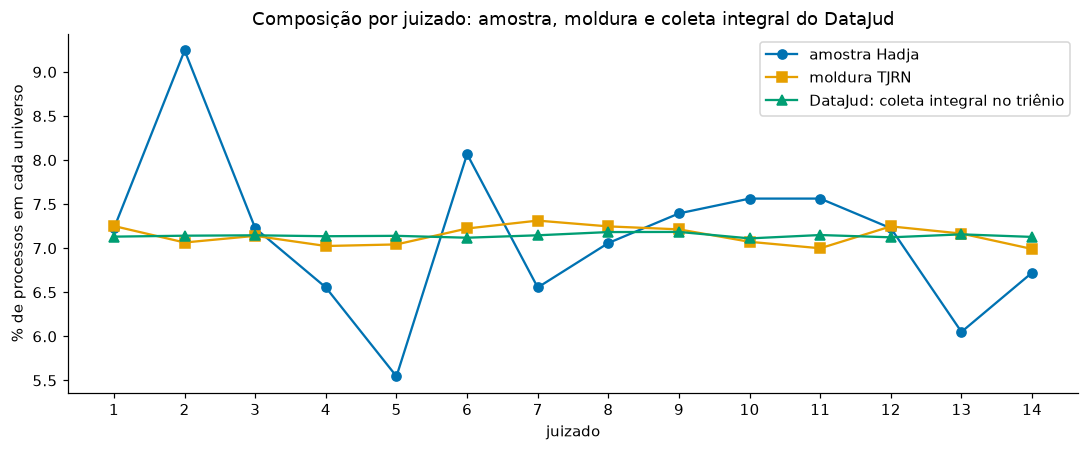

In [80]:
_orgaos_je = {int(codigo): int(rotulo.split('º')[0])
              for codigo, rotulo in MANIFESTO['populacao']['escopo']['orgaos'].items()}
_dj_integral = POP.loc[POP.via_coleta.eq('orgao_atual')].copy()
_dj_integral['jec_atual'] = pd.to_numeric(_dj_integral.orgao_atual, errors='coerce').map(_orgaos_je)
assert len(_dj_integral) == 65472 and _dj_integral.jec_atual.notna().all()
assert _dj_integral.data_ajuizamento.dt.year.between(2022, 2024).all()
_totais_manifesto = {int(rotulo.split('º')[0]): int(info['n'])
                    for rotulo, info in MANIFESTO['populacao']['resumo'].items()}
_contagem_dj = _dj_integral.jec_atual.value_counts().reindex(range(1, 15), fill_value=0).sort_index()
assert _contagem_dj.to_dict() == _totais_manifesto

TAB_JEC_INTEGRAL = TAB_JEC[['JEC', 'N da referência', '% referência', 'n da amostra', '% amostra']].copy()
TAB_JEC_INTEGRAL = TAB_JEC_INTEGRAL.rename(columns={
    'N da referência': 'N moldura TJRN', '% referência': '% moldura',
    'n da amostra': 'n Hadja', '% amostra': '% Hadja'})
TAB_JEC_INTEGRAL['N DataJud completo'] = _contagem_dj.to_numpy()
TAB_JEC_INTEGRAL['% DataJud completo'] = _contagem_dj.to_numpy() / len(_dj_integral)
TAB_JEC_INTEGRAL['Hadja − DataJud (p.p.)'] = 100 * (
    TAB_JEC_INTEGRAL['% Hadja'] - TAB_JEC_INTEGRAL['% DataJud completo'])
TAB_JEC_INTEGRAL['n esperado se DataJud fosse moldura'] = (
    len(am) * TAB_JEC_INTEGRAL['% DataJud completo'])
display(tabela_ptbr(TAB_JEC_INTEGRAL, casas=3,
                    pct=['% moldura', '% Hadja', '% DataJud completo']))

_intersecao_dj = _dj_integral.numero.isin(base['NÚMERO PROCESSO'])
_amostra_dj = am.numero.isin(_dj_integral.numero)
display(pd.Series({'cache DataJud total': len(POP),
                   'coleta integral 14 JEC, 2022–2024': len(_dj_integral),
                   'da coleta integral também na moldura depurada': int(_intersecao_dj.sum()),
                   'da coleta integral fora da moldura depurada': int((~_intersecao_dj).sum()),
                   'sorteados presentes na coleta integral': int(_amostra_dj.sum())},
                  name='universos e interseções').to_frame())

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(TAB_JEC_INTEGRAL.JEC, 100 * TAB_JEC_INTEGRAL['% Hadja'], 'o-', label='amostra Hadja')
ax.plot(TAB_JEC_INTEGRAL.JEC, 100 * TAB_JEC_INTEGRAL['% moldura'], 's-', label='moldura TJRN')
ax.plot(TAB_JEC_INTEGRAL.JEC, 100 * TAB_JEC_INTEGRAL['% DataJud completo'], '^-', label='DataJud: coleta integral no triênio')
ax.set(xlabel='juizado', ylabel='% de processos em cada universo', xticks=TAB_JEC_INTEGRAL.JEC,
       title='Composição por juizado: amostra, moldura e coleta integral do DataJud')
ax.legend(); fig.tight_layout()
fig.savefig(FIGURAS / 'amostra_juizados_datajud_integral.png', dpi=150)
plt.show()

**Leitura da coleta integral.** Os 65.472 processos do DataJud estão distribuídos quase uniformemente entre os 14 JEC, com aproximadamente 4.656 a 4.704 processos por unidade. A moldura depurada também é próxima da uniformidade. O maior excesso da amostra continua no 2º JEC, com 9,24% dos sorteados contra cerca de 7,14% na coleta integral; o 5º tem 5,55% contra cerca de 7,14%. A proximidade entre as duas referências populacionais reforça a conclusão descritiva de que a amostra não está fortemente deslocada por juizado.

Dos 65.472 processos da coleta integral, **16.175 não estão na moldura depurada** e **49.297 estão nela**; 581 dos 595 sorteados aparecem nessa via direta de coleta. A comparação com o DataJud inteiro não substitui o teste de representatividade do sorteio, porque esses 16.175 processos adicionais não tinham a mesma regra de elegibilidade e o órgão atual não é necessariamente o de origem. Ela mostra, de forma transparente, como a composição da amostra se compara à distribuição geral dos registros disponíveis no triênio.

O modelo atribui perfis de trajetória aos processos com documento. A planilha desta edição usa nomes neutros e probabilidades de pertença à mistura. Como a concordância com os rótulos da pesquisa é baixa, esses grupos não podem ser apresentados como listas de indício ou certeza.

In [81]:
# 11.2 Aplicação do classificador e as três listas (sem dados pessoais)
XPOP = codificar_dj(UNIV[com_doc].reset_index(drop=True))
POST_POP = C.lca_posteriori(M_DJ, XPOP.to_numpy())
assert np.allclose(C.lca_posteriori(M_DJ, XDJ.to_numpy()), M_DJ['post'], atol=1e-6)   # mesma função na amostra
UNIV.loc[com_doc, 'classe_pred'] = POST_POP.argmax(1)
for k, nome in enumerate(NIVEIS_CLASSE3):
    UNIV.loc[com_doc, f'P({nome})'] = POST_POP[:, k]
UNIV.loc[com_doc, 'prob_pertenca'] = POST_POP.max(1)
NOMES_LISTA = {0: 'trajetória 1', 1: 'trajetória 2', 2: 'trajetória 3'}
for k, nome in enumerate(NIVEIS_CLASSE3):
    UNIV[f'P(trajetória {k + 1})'] = UNIV[f'P({nome})']
COLS_LISTA = ['processo', 'jec', 'ano', 'classe_moldura', 'classe_origem', 'assunto_principal', 'desfecho_rotulo',
              'P(trajetória 1)', 'P(trajetória 2)', 'P(trajetória 3)', 'prob_pertenca', 'via_coleta']
UNIV['processo'] = UNIV['numero'].map(C.formatar_cnj)
PROIBIDAS = {'PARTES ATIVAS', 'ADVOGADO', 'Tipo de parte'}
assert not PROIBIDAS & set(COLS_LISTA) and not PROIBIDAS & set(UNIV.columns), 'dado pessoal nas listas'
ARQ_LISTAS = TABELAS / 'trajetorias_processuais.xlsx'
with pd.ExcelWriter(ARQ_LISTAS) as xw:
    pd.DataFrame({'LEIA-ME': [
        'Grupos exploratórios de trajetórias processuais da LCA (K = 3). Não são rótulos jurídicos de predação.',
        f"Concordância com a rotulagem manual na amostra: kappa ponderado = {V['av_kpond']}; Youden J = {V['av_J']}.",
        'Uso individual e inferência de litigância predatória são inadequados; ver Seções 10 e 12.',
        'Número CNJ em texto (DV conferido). Sem nomes de partes ou advogados.',
        'Classe e órgão no DataJud são os ATUAIS; classe_origem é a reconstruída pelo movimento de evolução.']}).to_excel(xw, sheet_name='LEIA-ME', index=False)
    for k, nome in NOMES_LISTA.items():
        UNIV.loc[UNIV.classe_pred == k, COLS_LISTA].sort_values('prob_pertenca', ascending=False).to_excel(xw, sheet_name=nome[:31], index=False)
    UNIV.loc[~com_doc, ['processo', 'jec', 'ano', 'classe_moldura', 'via_coleta']].to_excel(xw, sheet_name='sem documento no DataJud', index=False)
relidas = pd.read_excel(ARQ_LISTAS, sheet_name=None, dtype=str)
for nome, df in relidas.items():
    if 'processo' in df:
        C.conferir_cnj(df['processo'].str.replace(r'\D', '', regex=True), f'lista {nome}')
assert sum(len(df) for n, df in relidas.items() if n != 'LEIA-ME') == len(UNIV)
LISTAS = UNIV.loc[com_doc, 'classe_pred'].map(NOMES_LISTA).value_counts().reindex(NOMES_LISTA.values())
display(LISTAS.rename('processos').to_frame())
V.update(**{f'lista_{k}': fint(LISTAS.iloc[k]) for k in range(3)}, **{f'lista_{k}_p': fpct(LISTAS.iloc[k] / com_doc.sum(), 1) for k in range(3)},
         prob_media=fnum(UNIV.loc[com_doc, 'prob_pertenca'].mean(), 3))

,processos
classe_pred,
trajetória 1,18576
trajetória 2,16396
trajetória 3,15130


In [82]:
exibir('pop_listas', r'''
**A aplicação produz três perfis de trajetória processual.** Entre os {{pop_doc}} processos com documento, os tamanhos são {{lista_0}}, {{lista_1}} e {{lista_2}}. As porcentagens correspondentes são {{lista_0_p}}, {{lista_1_p}} e {{lista_2_p}}. A probabilidade média de pertença ao perfil atribuído é {{prob_media}}.

A planilha `estcaso3_revisado/tabelas/trajetorias_processuais.xlsx` conserva o número CNJ, as variáveis processuais e as probabilidades dos três perfis. Há uma aba adicional para números sem documento. Os nomes neutros são deliberados: a matriz da Seção 10 não sustenta chamar os grupos de “não predatória”, “indício” e “certeza”. A planilha serve para examinar padrões administrativos; **não serve para triagem ou decisão sobre processos individuais**.
''')


**A aplicação produz três perfis de trajetória processual.** Entre os 50.102 processos com documento, os tamanhos são 18.576, 16.396 e 15.130. As porcentagens correspondentes são 37,1%, 32,7% e 30,2%. A probabilidade média de pertença ao perfil atribuído é 0,938.

A planilha `estcaso3_revisado/tabelas/trajetorias_processuais.xlsx` conserva o número CNJ, as variáveis processuais e as probabilidades dos três perfis. Há uma aba adicional para números sem documento. Os nomes neutros são deliberados: a matriz da Seção 10 não sustenta chamar os grupos de “não predatória”, “indício” e “certeza”. A planilha serve para examinar padrões administrativos; **não serve para triagem ou decisão sobre processos individuais**.


## 12. O resultado cai no intervalo de 17,65%? (R19)

O intervalo [14,59%; 20,70%] citado no roteiro reproduz Wald com correção de população finita para N = 83.139, apesar do nome Wilson empregado ali. O Wilson simples e a aproximação por tamanho efetivo do desenho são mostrados para comparação. O apêndice final acrescenta um intervalo na escala logito com o erro-padrão estratificado.

A proporção dos perfis de trajetória na moldura não mede a prevalência de indício da pesquisa. A fórmula de Rogan–Gladen é apresentada apenas como diagnóstico: divide pela soma sensibilidade + especificidade − 1, que aqui fica próxima de zero ou negativa. Como os grupos não validaram a classificação jurídica, **não se calcula teste de igualdade nem de equivalência** entre essa correção e a estimativa amostral. A resposta sustentada pelo desenho vem da amostra sorteada.


A proporção de perfis na população não mede a prevalência de litigância predatória. A inversão de Rogan–Gladen é exibida apenas como diagnóstico de sensibilidade: quando o índice de Youden se aproxima de zero, pequenas mudanças nos erros dos grupos produzem enormes mudanças na conta. Nenhum teste de equivalência é calculado nesta edição.

,indício,certeza
Se (amostra),"0,6952","0,2333"
Es (amostra),"0,3955","0,7371"
J de Youden,"0,0907","-0,0295"
prevalência aparente (população),"0,6292","0,3020"
Rogan-Gladen (sem truncar),"0,2725",NaN
"Rogan-Gladen (em [0, 1])","0,2725",NaN
IC 95% inf. (bootstrap),"0,0000","0,1112"
IC 95% sup. (bootstrap),"1,0000","1,0000"
fração de réplicas com J ≤ 0,"0,0350","0,6665"
fração de réplicas truncadas em 0 ou 1,"0,1680","0,1620"


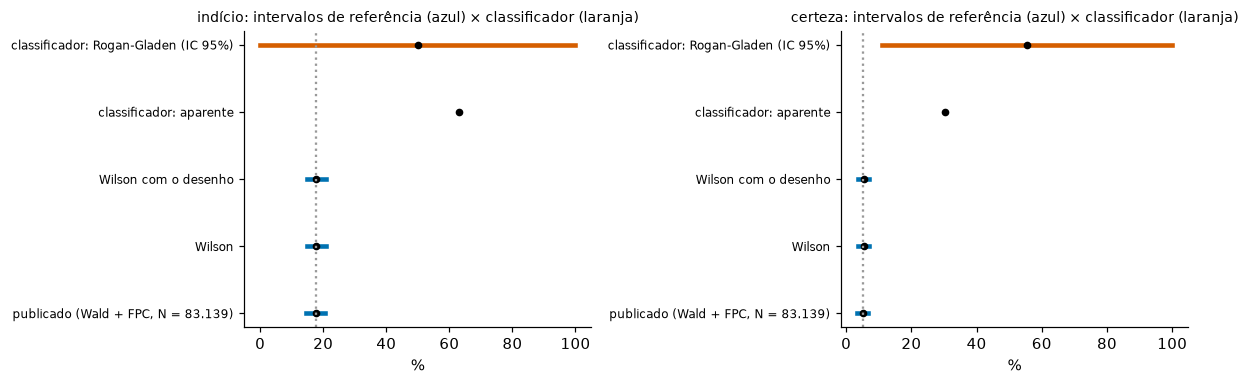

In [83]:
# 12.1 Diagnóstico exploratório de não identificação: as estimativas corrigidas não são prevalências validadas
est_ind = C.estratificado({a: am.loc[am.ano == a, 'indicio'].mean() for a in (2022, 2023, 2024)},
                          {a: int((am.ano == a).sum()) for a in (2022, 2023, 2024)}, Nh_ano)
est_cer = C.estratificado({a: am.loc[am.ano == a, 'certeza'].mean() for a in (2022, 2023, 2024)},
                          {a: int((am.ano == a).sum()) for a in (2022, 2023, 2024)}, Nh_ano)
C.confere('Wilson-desenho inf.', est_ind['wilson_desenho'][0], GAB['estratificado']['indicio']['wilson_desenho'][0], registro=CONFERENCIAS)
IC_REF = {'indício': {'publicado (Wald + FPC, N = 83.139)': C.wald_fpc(105, 595, 83139), 'Wilson': C.wilson(105, 595),
                      'Wilson com o desenho': est_ind['wilson_desenho'], 'p_amostra': funil['indicio'] / funil['n'], 'ep': est_ind['ep']},
          'certeza': {'publicado (Wald + FPC, N = 83.139)': C.wald_fpc(30, 595, 83139), 'Wilson': C.wilson(30, 595),
                      'Wilson com o desenho': est_cer['wilson_desenho'], 'p_amostra': funil['certeza'] / funil['n'], 'ep': est_cer['ep']}}
assert [round(100 * v, 2) for v in IC_REF['indício']['publicado (Wald + FPC, N = 83.139)']] == [14.59, 20.70]

real = l10.classe3_cod.astype(int).to_numpy()
pred = M_DJ['classe']
pred_pop = UNIV.loc[com_doc, 'classe_pred'].astype(int).to_numpy()
rng_rg = np.random.default_rng(SEMENTES['bootstrap'])
B_RG = 2000
R19 = {}
for alvo, f_real, f_pred in [('indício', lambda r: r >= 1, lambda p: p >= 1), ('certeza', lambda r: r == 2, lambda p: p == 2)]:
    rb, pb = f_real(real), f_pred(pred)
    se, es = (rb & pb).sum() / rb.sum(), (~rb & ~pb).sum() / (~rb).sum()
    pap = f_pred(pred_pop).mean()
    J_pt = se + es - 1
    rg = C.rogan_gladen(pap, se, es, truncar=False) if J_pt > 0 else np.nan   # J ≤ 0: correção indefinida
    boot, j_neg = [], 0
    for _ in range(B_RG):
        i = rng_rg.integers(0, len(real), len(real))
        se_b = (rb[i] & pb[i]).sum() / max(rb[i].sum(), 1); es_b = (~rb[i] & ~pb[i]).sum() / max((~rb[i]).sum(), 1)
        pap_b = pap  # moldura observada quase integralmente: fixar proporção aparente neste diagnóstico
        if se_b + es_b - 1 <= 0:
            j_neg += 1; boot.append(np.nan); continue
        boot.append(C.rogan_gladen(pap_b, se_b, es_b, truncar=True))
    boot = np.array(boot)
    ok_b = ~np.isnan(boot)
    ic95 = np.nanpercentile(boot, [2.5, 97.5]) if ok_b.any() else np.array([np.nan, np.nan])
    ic90 = np.nanpercentile(boot, [5, 95]) if ok_b.any() else np.array([np.nan, np.nan])
    ref = IC_REF[alvo]
    R19[alvo] = dict(sens=se, esp=es, J=J_pt, p_aparente=pap, rg_bruto=rg, rg=min(max(rg, 0), 1) if np.isfinite(rg) else np.nan,
                     ic95=ic95, ic90=ic90,
                     frac_J_nao_positivo=j_neg / B_RG, frac_truncado=np.nanmean((boot <= 0) | (boot >= 1)),
                     dentro={k: ref[k][0] <= pap <= ref[k][1] for k in list(ref)[:3]})
TAB19 = pd.DataFrame({a: {'Se (amostra)': r['sens'], 'Es (amostra)': r['esp'], 'J de Youden': r['J'], 'prevalência aparente (população)': r['p_aparente'],
                          'Rogan-Gladen (sem truncar)': r['rg_bruto'], 'Rogan-Gladen (em [0, 1])': r['rg'], 'IC 95% inf. (bootstrap)': r['ic95'][0],
                          'IC 95% sup. (bootstrap)': r['ic95'][1], 'fração de réplicas com J ≤ 0': r['frac_J_nao_positivo'],
                          'fração de réplicas truncadas em 0 ou 1': r['frac_truncado']} for a, r in R19.items()})
display(TAB19.round(4))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, alvo in zip(axs, ['indício', 'certeza']):
    ref, r = IC_REF[alvo], R19[alvo]
    linhas = [(k, v) for k, v in ref.items() if isinstance(v, tuple)] + [('classificador: aparente', (r['p_aparente'],) * 2),
                                                                         ('classificador: Rogan-Gladen (IC 95%)', tuple(r['ic95']))]
    for y_, (nome, (lo, hi)) in enumerate(linhas):
        if not (np.isfinite(lo) and np.isfinite(hi)):
            ax.text(1, y_, 'indefinido (J ≤ 0)', fontsize=8, va='center', color='#D55E00'); continue
        ax.plot([100 * lo, 100 * hi], [y_, y_], lw=3, color='#0072B2' if y_ < 3 else '#D55E00')
        ax.plot(100 * (lo + hi) / 2 if lo != hi else 100 * lo, y_, 'o', color='black', ms=4)
    ax.axvline(100 * ref['p_amostra'], color='#999', ls=':')
    ax.set_yticks(range(len(linhas))); ax.set_yticklabels([n for n, _ in linhas], fontsize=8)
    ax.set_xlabel('%'); ax.set_title(f'{alvo}: intervalos de referência (azul) × classificador (laranja)', fontsize=9)
fig.tight_layout(); fig.savefig(FIGURAS / 'r19_intervalos.png', dpi=150); plt.show()

ri, rc = R19['indício'], R19['certeza']
V.update(r19_se=fnum(ri['sens'], 3), r19_es=fnum(ri['esp'], 3), r19_J=fnum(ri['J'], 3), r19_pap=fpct(ri['p_aparente'], 2),
         r19_rg_bruto=fpct(ri['rg_bruto'], 1), r19_rg=fpct(ri['rg'], 1), r19_ic=fic(*ri['ic95'], pct=True, casas=1),
         r19_jneg=fpct(ri['frac_J_nao_positivo'], 1), r19_trunc=fpct(ri['frac_truncado'], 1),
         r19_dentro_pub='dentro' if ri['dentro']['publicado (Wald + FPC, N = 83.139)'] else 'fora',
         r19c_J=fnum(rc['J'], 3), r19c_pap=fpct(rc['p_aparente'], 2), r19c_rg=fpct(rc['rg'], 1), r19c_ic=fic(*rc['ic95'], pct=True, casas=1),
         ic_pub=fic(*IC_REF['indício']['publicado (Wald + FPC, N = 83.139)'], pct=True), ic_wil=fic(*IC_REF['indício']['Wilson'], pct=True),
         ic_des=fic(*IC_REF['indício']['Wilson com o desenho'], pct=True), ic_des_c=fic(*IC_REF['certeza']['Wilson com o desenho'], pct=True),
         total_des=f"{fint(est_ind['total'])} {fic(*[int(round(v)) for v in est_ind['total_ic']], casas=0)}",
         p_593=fpct(funil['indicio'] / (funil['n'] - len(nao_localizados)), 2),
         ic_593=fic(*C.wilson(funil['indicio'], funil['n'] - len(nao_localizados)), pct=True))
V.update(total_des_c=f"{fint(est_cer['total'])} {fic(*[int(round(v)) for v in est_cer['total_ic']], casas=0)}")


In [84]:
exibir('r19_resposta', r'''
**O exercício populacional não identifica a prevalência jurídica.** A proporção aparente de perfis que receberiam o antigo nome de indício é {{r19_pap}}, mas a concordância com a classificação da pesquisa é fraca (J de Youden = {{r19_J}}). A inversão de Rogan–Gladen produz {{r19_rg}}, com intervalo exploratório {{r19_ic}}; a amplitude mostra que esse número não tem precisão útil. Para a certeza, J = {{r19c_J}} e a correção é indefinida.

O bootstrap aqui mantém o modelo ajustado e suas atribuições fixos. Ele não incorpora toda a incerteza de ajuste e escolha dos grupos; por isso o intervalo não deve ser usado para afirmar igualdade ou equivalência com a pesquisa.

**O que a amostra probabilística sustenta.**

- **Indício:** {{p_indicio}}, com aproximação de Wilson por tamanho efetivo {{ic_des}}. Projetado na moldura de {{N_moldura}}, são **{{total_des}}** processos, a mesma ordem de grandeza dos "cerca de 8.880" do roteiro.
- **Certeza:** {{p_certeza}} {{ic_des_c}}, ou {{total_des_c}} processos.
- **Sensibilidade D4:** sem os {{n_nao_localizados}} processos não localizados no PJe, o indício seria {{p_593}} {{ic_593}}. A decisão de mantê-los no denominador não muda a conclusão.
- **O intervalo publicado** {{ic_pub}} foi calculado por Wald com correção de população finita (N = 83.139), apesar do nome usado no roteiro. A estimativa amostral cai dentro dele.

Os perfis do DataJud descrevem trajetórias, mas não refinam a prevalência. O que **refina** é o assunto, conhecido para todos os processos da moldura: a Seção 31 refaz esta estimativa por regressão hierárquica com pós-estratificação.
''')


**O exercício populacional não identifica a prevalência jurídica.** A proporção aparente de perfis que receberiam o antigo nome de indício é 62,92%, mas a concordância com a classificação da pesquisa é fraca (J de Youden = 0,091). A inversão de Rogan–Gladen produz 27,3%, com intervalo exploratório [0,0; 100,0]%; a amplitude mostra que esse número não tem precisão útil. Para a certeza, J = -0,030 e a correção é indefinida.

O bootstrap aqui mantém o modelo ajustado e suas atribuições fixos. Ele não incorpora toda a incerteza de ajuste e escolha dos grupos; por isso o intervalo não deve ser usado para afirmar igualdade ou equivalência com a pesquisa.

**O que a amostra probabilística sustenta.**

- **Indício:** 17,65%, com aproximação de Wilson por tamanho efetivo [14,81; 20,90]%. Projetado na moldura de 50.320, são **8.881 [7.452; 10.516]** processos, a mesma ordem de grandeza dos "cerca de 8.880" do roteiro.
- **Certeza:** 5,04% [3,56; 7,09]%, ou 2.538 [1.794; 3.569] processos.
- **Sensibilidade D4:** sem os 2 processos não localizados no PJe, o indício seria 17,71% [14,84; 20,98]%. A decisão de mantê-los no denominador não muda a conclusão.
- **O intervalo publicado** [14,59; 20,70]% foi calculado por Wald com correção de população finita (N = 83.139), apesar do nome usado no roteiro. A estimativa amostral cai dentro dele.

Os perfis do DataJud descrevem trajetórias, mas não refinam a prevalência. O que **refina** é o assunto, conhecido para todos os processos da moldura: a Seção 31 refaz esta estimativa por regressão hierárquica com pós-estratificação.


---

# PARTE IV: O MODELO PARA A TURMA

## 13. Simulação de Dados, Quadro de Variáveis e Dicionário (P2)

### 13.1 Por que simular

**Simular** é gerar dados artificiais a partir de um modelo com parâmetros **conhecidos** (TOSHKOV, 2016, p. 178 e 208). Serve a três coisas:
1. ensinar e replicar o método sem expor dados de processos reais;
2. testar se o método **recupera** a verdade quando ela é conhecida;
3. planejar o tamanho de amostra antes de ir a campo.

Dado simulado não é evidência sobre o mundo. Ele só mostra o que o **método** faria se o modelo fosse verdadeiro.

### 13.2 O modelo gerador (encadeado como o funil)

| Passo | Variável | Modelo gerador | Parâmetros (estimados na amostra real) |
|---|---|---|---|
| 1 | classe latente *z* | categórica | pesos π da LCA dos F2 (Seção 10) |
| 2 | F2 ativos | Bernoulli independentes dado *z* | probabilidades θ da LCA dos F2 |
| 2b | F2_01 | igual à F2_02, com troca rara | taxa real de discordância do bloco documental (a independência local da LCA não reproduz o φ quase unitário do par) |
| 3 | indício | logística sobre F2_01, F2_02, F2_11 | coeficientes da logística da Hadja (Seções 6.4 e 8) |
| 4 | certeza \| indício | Bernoulli | P(certeza \| indício) |
| 5 | desfecho \| indício | categórica | verossimilhanças da Seção 6 |
| 6 | tempo até o desfecho | lognormal | ajuste aos tempos observados |

A LCA é o gerador natural de **indicadores binários correlacionados**: a correlação entre os sinais vem da classe comum, como no bloco documental.

A simulação fornece dados artificiais com parâmetros conhecidos para que colegas possam executar o procedimento sem expor processos reais. A comparação entre valores geradores e reestimados mostra o que uma amostra deste tamanho consegue recuperar sob as hipóteses do gerador.

In [85]:
# 13.1 Gerador sintético, conferência das marginais e recuperação dos parâmetros
rng_g = np.random.default_rng(SEMENTES['simulacao'])
GER_LCA = C.lca_reordenar(LCA_F2[3], np.argsort([nF2[LCA_F2[3]['classe'] == g].mean() for g in range(3)]))
BETA_H = MOD_HADJA.params.to_numpy()
P_CERT_IND = funil['certeza'] / funil['indicio']
P_DISC = float((d233.F2_01 != d233.F2_02).mean())          # discordância real do bloco documental
NIV_D4 = ['acordo', 'mérito', 'extinção sem mérito', 'sem sentença registrada']
P_DESF = {h: bay.loc[bay.Ha == h, 'desfecho'].astype(str).value_counts(normalize=True).reindex(NIV_D4, fill_value=0).to_numpy() for h in (True, False)}
t_obs = td.loc[td.e == 1, 't']
LN_S, _, LN_ESC = stats.lognorm.fit(t_obs, floc=0)

def gerar(n, rng):
    z, Xf = C.lca_simular(GER_LCA, n, rng)
    df = pd.DataFrame(Xf, columns=F2_ATIVOS)
    df['F2_01'] = np.where(rng.random(n) < P_DISC, 1 - df['F2_02'], df['F2_02'])   # passo 2b: bloco documental
    eta = BETA_H[0] + df[X_HADJA].to_numpy() @ BETA_H[1:]
    df['indicio'] = rng.random(n) < 1 / (1 + np.exp(-eta))
    df['certeza'] = df['indicio'] & (rng.random(n) < P_CERT_IND)
    df['desfecho'] = [NIV_D4[rng.choice(4, p=P_DESF[bool(h)])] for h in df['indicio']]
    df['tempo_desfecho_dias'] = stats.lognorm.rvs(LN_S, scale=LN_ESC, size=n, random_state=rng).round(1)
    df.insert(0, 'classe_latente', z)
    return df

SINT = gerar(n233, rng_g)
marg = pd.DataFrame({'real (233)': d233[F2_ATIVOS + ['indicio', 'certeza']].astype(float).mean(),
                     'sintético (233)': SINT[F2_ATIVOS + ['indicio', 'certeza']].astype(float).mean()})
display(tabela_ptbr(marg.reset_index().rename(columns={'index': 'variável'}), pct=['real (233)', 'sintético (233)'], casas=1))

recs = []
_av_sim = C.capturar_avisos('recuperação por simulação (quase separação em réplicas)', AVISOS)
_av_sim.__enter__()
for _ in range(200):
    s_ = gerar(n233, rng_g)
    try:
        recs.append(sm.Logit(s_['indicio'].astype(int), sm.add_constant(s_[X_HADJA].astype(float), has_constant='add')).fit(disp=0, method='bfgs', maxiter=500).params.to_numpy())
    except (np.linalg.LinAlgError, ValueError):
        pass
_av_sim.__exit__(None, None, None)
recs = np.array(recs)
REC_SIM = pd.DataFrame({'verdadeiro': BETA_H, 'mediana reestimada': np.median(recs, 0), 'p10': np.percentile(recs, 10, 0),
                        'p90': np.percentile(recs, 90, 0)}, index=['constante'] + X_HADJA)
display(REC_SIM.round(3))
phi_sint = np.corrcoef(SINT.F2_01, SINT.F2_02)[0, 1]
V.update(sim_phi=fnum(phi_sint, 3), sim_phi_real=fnum(np.corrcoef(d233.F2_01, d233.F2_02)[0, 1], 3), sim_reps=fint(len(recs)), sim_med_02=fnum(REC_SIM.loc['F2_02', 'mediana reestimada'], 2), sim_true_02=fnum(BETA_H[2], 2),
         sim_med_11=fnum(REC_SIM.loc['F2_11', 'mediana reestimada'], 2), sim_true_11=fnum(BETA_H[3], 2),
         sim_p10_01=fnum(REC_SIM.loc['F2_01', 'p10'], 2), sim_p90_01=fnum(REC_SIM.loc['F2_01', 'p90'], 2),
         sim_ind_real=fpct(d233.indicio.mean(), 1), sim_ind_sint=fpct(SINT.indicio.mean(), 1),
         ln_mediana=fnum(LN_ESC, 0), ln_sigma=fnum(LN_S, 2))

,variável,real (233),sintético (233)
0,F2_01,"42,1%","38,6%"
1,F2_02,"41,2%","39,5%"
2,F2_04,"7,7%","3,9%"
3,F2_06,"43,3%","46,4%"
4,F2_09,"6,4%","6,0%"
5,F2_10,"33,5%","33,9%"
6,F2_11,"42,5%","38,6%"
7,F2_14,"7,3%","5,6%"
8,indicio,"45,1%","40,3%"
9,certeza,"12,9%","11,6%"


⚠ aviso [recuperação por simulação (quase separação em réplicas)] HessianInversionWarning: Inverting hessian failed, no bse or cov_params available


,verdadeiro,mediana reestimada,p10,p90
constante,"-2,5500","-2,5740","-3,1720","-2,1320"
F2_01,"0,5450","0,6440","-10,3600","2,2590"
F2_02,"3,4240","3,5340","1,6970","14,4860"
F2_11,"1,6080","1,5930","1,0650","2,2680"


In [86]:
exibir('sim_recuperacao', r'''
**Leitura: o gerador reproduz os dados, e a recuperação mostra o que a amostra permite e o que não permite estimar.**

- **Marginais.** As proporções sintéticas das F2 ativas e do indício acompanham as reais: indício {{sim_ind_real}} na amostra real e {{sim_ind_sint}} no conjunto sintético, a variação de um único sorteio. O bloco documental é reproduzido: φ(F2_01, F2_02) = {{sim_phi}} no sintético e {{sim_phi_real}} no real.
- **Recuperação.** Em {{sim_reps}} réplicas de mesmo tamanho:
  - o coeficiente de F2_11 é bem recuperado (mediana {{sim_med_11}}; verdadeiro {{sim_true_11}});
  - o de F2_02 sai com viés para cima (mediana {{sim_med_02}}; verdadeiro {{sim_true_02}}), o sinal típico da quase separação que justifica o Firth da Seção 8;
  - o de F2_01 varia enormemente (do 1º ao 9º decil, de {{sim_p10_01}} a {{sim_p90_01}}): com o par quase sempre igual, a amostra não separa os dois efeitos, nem quando a verdade é conhecida.
- **Lição para a turma.** A simulação não serve só para "confirmar" o método. Ela mostra **antes da coleta** quais parâmetros o desenho consegue estimar.
- **Tempos.** Lognormal com mediana de {{ln_mediana}} dias e σ = {{ln_sigma}} na escala log.
''')


**Leitura: o gerador reproduz os dados, e a recuperação mostra o que a amostra permite e o que não permite estimar.**

- **Marginais.** As proporções sintéticas das F2 ativas e do indício acompanham as reais: indício 45,1% na amostra real e 40,3% no conjunto sintético, a variação de um único sorteio. O bloco documental é reproduzido: φ(F2_01, F2_02) = 0,982 no sintético e 0,965 no real.
- **Recuperação.** Em 200 réplicas de mesmo tamanho:
  - o coeficiente de F2_11 é bem recuperado (mediana 1,59; verdadeiro 1,61);
  - o de F2_02 sai com viés para cima (mediana 3,53; verdadeiro 3,42), o sinal típico da quase separação que justifica o Firth da Seção 8;
  - o de F2_01 varia enormemente (do 1º ao 9º decil, de -10,36 a 2,26): com o par quase sempre igual, a amostra não separa os dois efeitos, nem quando a verdade é conhecida.
- **Lição para a turma.** A simulação não serve só para "confirmar" o método. Ela mostra **antes da coleta** quais parâmetros o desenho consegue estimar.
- **Tempos.** Lognormal com mediana de 75 dias e σ = 1,23 na escala log.


O quadro transforma cada variável em uma definição operacional: escala, unidade, categorias, ausência, validade e modelo gerador. Ele é um molde de documentação; antes de copiá-lo para outra pesquisa, é preciso redefinir cada linha segundo a pergunta e a fonte daquele projeto.

In [87]:
# 13.2 Quadro de Variáveis e Dicionário de Dados — gabarito para a turma (dados reais + DataJud + gerador sintético)
GERADOR = {**{c: 'Bernoulli dado a classe latente (LCA)' for c in F2_ATIVOS}, 'indicio': 'logística (F2_01, F2_02, F2_11)',
           'certeza': 'Bernoulli dado indício', 'classe3': 'função de indício e certeza'}
extra = pd.DataFrame([
    dict(nome='desfecho', descricao='resultado da fase de conhecimento (proxy TPU desfecho_conhecimento)', tipo='qualitativa',
         escala='nominal', unidade='—', faixa_categorias=' / '.join(NIV_D4), validade='proxy por códigos TPU; validade jurídica não aferida',
         confiabilidade='determinística dada a TPU', dtype='category', n_validos=int(dj.desfecho.notna().sum()), na_estrutural=int(dj.desfecho.isna().sum())),
    dict(nome='t_desfecho', descricao='dias do ajuizamento ao desfecho (censura na última atualização)', tipo='quantitativa',
         escala='razão (contínua, censurada)', unidade='dias', faixa_categorias=f"{fnum(dj.t_desfecho.min(), 0)}–{fnum(dj.t_desfecho.max(), 0)}",
         validade='datas do DataJud em horário local', confiabilidade='registro administrativo', dtype='Float64',
         n_validos=int(dj.t_desfecho.notna().sum()), na_estrutural=int(dj.t_desfecho.isna().sum())),
    dict(nome='houve_recurso', descricao='processo com documento na Turma Recursal', tipo='qualitativa', escala='nominal dicotômica',
         unidade='—', faixa_categorias='Sim/Não', validade='documento TR no DataJud', confiabilidade='registro administrativo',
         dtype='boolean', n_validos=int(dj.houve_recurso.notna().sum()), na_estrutural=int(dj.houve_recurso.isna().sum())),
    dict(nome='classe_origem', descricao='classe processual na distribuição (reconstruída pelo movimento de evolução)', tipo='qualitativa',
         escala='nominal', unidade='—', faixa_categorias='códigos TPU de classe', validade='inferida quando a classe atual é de cumprimento',
         confiabilidade='regra do proxy fases', dtype='Int32', n_validos=int(dj.classe_origem.notna().sum()), na_estrutural=int(dj.classe_origem.isna().sum()))])
QUADRO_TURMA = pd.concat([QUADRO, extra], ignore_index=True)
QUADRO_TURMA['modelo gerador na simulação'] = QUADRO_TURMA.nome.map(GERADOR).fillna('—')
QUADRO_TURMA.loc[QUADRO_TURMA.nome == 'desfecho', 'modelo gerador na simulação'] = 'categórica dado indício'
QUADRO_TURMA.loc[QUADRO_TURMA.nome == 't_desfecho', 'modelo gerador na simulação'] = 'lognormal'
with pd.ExcelWriter(TABELAS / 'quadro_variaveis_gabarito_turma.xlsx') as xw:
    QUADRO_TURMA.to_excel(xw, sheet_name='Quadro de Variáveis', index=False)
    SINT.to_excel(xw, sheet_name='dados sintéticos (233)', index=False)
    REC_SIM.reset_index().to_excel(xw, sheet_name='recuperação', index=False)
display(QUADRO_TURMA[['nome', 'tipo', 'escala', 'unidade', 'faixa_categorias', 'validade', 'confiabilidade', 'modelo gerador na simulação']])
V.update(qt_n=fint(len(QUADRO_TURMA)))

,nome,tipo,escala,unidade,faixa_categorias,validade,confiabilidade,modelo gerador na simulação
0,numero,identificador,—,—,20 dígitos; DV mod 97,DV conferido após cada transformação; 20 resta...,exata,—
1,ordem,identificador,—,—,1–50.320,confere com a moldura,exata,—
2,jec,qualitativa,nominal (14 níveis),—,1º a 14º JEC,da moldura,exata,—
3,ano,qualitativa,ordinal,ano,2022–2024,DATA INÍCIO da moldura,exata,—
4,classe_planilha,qualitativa,nominal,—,"CUMPRIMENTO DE SENTENÇA, CUMPRIMENTO PROVISÓRI...","classe atual, não a de distribuição",registro do PJe,—
5,F1_A,qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",—
6,F1_B,qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",—
7,F1_C,qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",—
8,F1_D,qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",—
9,F1_E,qualitativa,nominal dicotômica,—,Sim/Não; nenhum,Anexo A da Rec. CNJ 159/2024; leitura dos autos,"um codificador, sem segunda leitura (kappa ent...",—


In [88]:
exibir('sim_quadro', r'''
**Leitura (P2).** O gabarito do Quadro de Variáveis tem {{qt_n}} linhas: as variáveis da pesquisa, as derivadas e as do DataJud. Tem as oito colunas do Plano de Ensino e mais uma, o **modelo gerador** usado na simulação. É o formato que a turma pode copiar para o apêndice do próprio projeto: cada variável com definição, escala e regra de validade, e com o modelo que permite simulá-la.
''')


**Leitura (P2).** O gabarito do Quadro de Variáveis tem 41 linhas: as variáveis da pesquisa, as derivadas e as do DataJud. Tem as oito colunas do Plano de Ensino e mais uma, o **modelo gerador** usado na simulação. É o formato que a turma pode copiar para o apêndice do próprio projeto: cada variável com definição, escala e regra de validade, e com o modelo que permite simulá-la.


### 13.3 Roteiro replicável para os colegas

Para montar o apêndice do próprio projeto (Quadro de Variáveis, Dicionário e simulação):

1. **Liste as variáveis da pergunta**, uma por linha, com as oito colunas do Plano de Ensino: nome, descrição, tipo, escala, unidade, faixa ou categorias, validade e confiabilidade (TOSHKOV, 2016, cap. 8; EPSTEIN; KING, 2013, p. 108 e 134).
2. **Escreva a regra de codificação** de cada variável: o que conta como "Sim", o que é ausência estrutural (não avaliado) e o que é ausência de informação.
3. **Escolha um modelo gerador para cada variável**, coerente com a escala:
   - Bernoulli ou classes latentes para indicadores binários correlacionados;
   - logística para a resposta binária e multinomial ou ordinal para respostas com mais níveis;
   - Poisson ou binomial negativa para contagens (Seção 4.3);
   - lognormal, gama ou Weibull para durações, com censura.
4. **Fixe os parâmetros** por literatura ou por um estudo-piloto, e **declare a semente** (uma por finalidade).
5. **Gere os dados, reaplique a análise e confira a recuperação**: os parâmetros reestimados devem ficar perto dos verdadeiros, como na tabela acima.
6. **Use a simulação para planejar o n**: repita com vários tamanhos e veja a partir de quando a recuperação é aceitável.

Arquivo de partida: `tabelas/quadro_variaveis_gabarito_turma.xlsx`, com o quadro, um conjunto sintético e a tabela de recuperação.

---

## 14. Síntese: Resposta Item a Item

A síntese lista as verificações automáticas e os avisos de execução. Conferir com o gabarito detecta divergência numérica, mas não comprova a validade jurídica do desfecho nem a transportabilidade dos modelos; essas duas questões dependem das evidências e limitações discutidas acima.

In [89]:
# 14.1 Conferências contra o gabarito da apostila e avisos registrados ao longo da execução
TAB_CONF = pd.DataFrame(CONFERENCIAS, columns=['grandeza', 'calculado', 'gabarito (apostila)', 'confere'])
assert TAB_CONF.confere.all()
display(TAB_CONF.assign(calculado=lambda d: d.calculado.map(lambda v: fnum(v, 4)),
                        **{'gabarito (apostila)': lambda d: d['gabarito (apostila)'].map(lambda v: fnum(v, 4))}))
display(pd.DataFrame(AVISOS, columns=['bloco', 'aviso']) if AVISOS else Markdown('*Nenhum aviso registrado.*'))
V.update(n_conferencias=fint(len(TAB_CONF)), n_avisos=fint(len(AVISOS)))

,grandeza,calculado,gabarito (apostila),confere
0,números restaurados,"20,0000","20,0000",True
1,funil.n,"595,0000","595,0000",True
2,funil.excluidos_f1,"151,0000","151,0000",True
3,funil.fase2,"444,0000","444,0000",True
4,funil.sem_f2,"211,0000","211,0000",True
...,...,...,...,...
87,AUC razão contínua,"0,9077","0,9077",True
88,DeLong Hadja × só F2_02,"3,5276","3,5276",True
89,AUC CV Hadja,"0,8989","0,8989",True
90,BIC LCA F2 K = 2,"1.715,4779","1.715,4779",True


,bloco,aviso
0,Cox tempo × classe3,DeprecationWarning: datetime.datetime.utcnow()...
1,bootstrap do teste de Brant (reamostras quase ...,HessianInversionWarning: Inverting hessian fai...
2,logística condicional,UserWarning: Dropped 8 groups and 23 observati...
3,validação cruzada,HessianInversionWarning: Inverting hessian fai...
4,recuperação por simulação (quase separação em ...,HessianInversionWarning: Inverting hessian fai...


In [90]:
exibir('sintese', r'''
**Síntese provisória (Partes I a IV).** Todos os números abaixo vêm das seções indicadas. As {{n_conferencias}} conferências contra o gabarito da apostila passaram. Foram registrados {{n_avisos}} avisos, listados acima. **A resposta final, que incorpora as Partes V e VI, está na Seção 35.**

| Item | Resposta curta | Seção |
|---|---|---|
| R1–R2 | P(indício) muda com o denominador: {{den_595}} (sorteados), {{den_444}} (elegíveis), {{den_233}} (Fase III). P(indício \| F2_02) = {{F2_02_lin_sim}} ≠ P(F2_02 \| indício) = {{F2_02_col_ind}} | §5 |
| R3–R4 | Bayes na notação do professor; dois pares H₀ × Hₐ: processo (partição do espaço amostral) e prevalência (partição do espaço de θ) | §6 |
| R5, R9 | priori principal 0,30 (NT CIJMG/Araripina) e Beta(6, 14); sensibilidade com 0,10, 0,50 e três outras Beta. A revisão de escopo é conceitual: os números vêm das notas técnicas | §6 |
| R6 | desfecho pelo proxy completo do DataJud: RV(extinção) = {{bay_0_RV}} {{bay_0_RVic}}; RV(acordo) = {{bay_1_RV}}. Evidência **fraca** | §3, §6 |
| R7–R8 | com priori 0,30 e extinção: P(D) = {{bay_0_tot03}} e posteriori {{bay_0_post03}}. Na prevalência da moldura, P(θ ≥ 0,30 \| dados) = {{beta_h0_444}} ({{n_elegiveis}} elegíveis) | §6 |
| R10 | multinomial: RRR de F2_02 = {{mn_rrr_ind_02}} (indício) e {{mn_rrr_cert_02}} (certeza) | §8 |
| R11 | ordinal: chances proporcionais **rejeitadas** (LR = {{lr_po}}; {{p_po}}); o PPO com F2_02 livre é adequado; a razão contínua mostra que os F2 não separam a certeza (OR de F2_02 no segundo passo = {{rc2_or02}} {{rc2_or02_ic}}) | §8 |
| R12 | condicional (JEC × ano, {{cl_uteis}} estratos úteis): OR de F2_11 = {{cl_or11}} {{cl_or11_ic}} | §8 |
| R13 | melhor ajuste: {{aj_bic_melhor}} pelo BIC; {{cv_melhor}} fora da amostra. Contra a Hadja, **empate** na dicotomia | §9 |
| R14 | AUC = {{auc_h}} e Gini = {{gini_h}} em **todos** os modelos (DeLong p igual a um: há só {{n_padroes}} padrões de preditores); fora da amostra, AUC = {{cv_auc}} | §9 |
| R15–R16 | LCA não supervisionada nos dados do DataJud: três trajetórias processuais; kappa ponderado contra a Hadja = {{av_kpond}}, J = {{av_J}}. Com os rótulos, as mesmas variáveis chegam a AUC {{sup_auc}}, e {{sup_auc_sem}} sem o assunto: o sinal do DataJud está no **assunto**. Nos F2, kappa ponderado = {{f2_kp}}; com F3, {{f23_kp}} (circular) | §10 |
| R17–R18 | perfis de trajetória em `estcaso3_revisado/tabelas/trajetorias_processuais.xlsx`: {{lista_0}} / {{lista_1}} / {{lista_2}} processos; sem valor de triagem jurídica | §11 |
| R19 | os perfis não permitem responder: proporção aparente {{r19_pap}} e correção instável {{r19_rg}} (intervalo exploratório {{r19_ic}}). Pela amostra: {{p_indicio}}, Wilson aproximado por n efetivo {{ic_des}}, isto é, {{total_des}} processos na moldura; sem os {{n_nao_localizados}} não localizados, {{p_593}} {{ic_593}}. O intervalo publicado é Wald + FPC, e não Wilson. A estimativa com o assunto de toda a moldura está na Seção 31 | §12, §31 |
| P1 | CA de JEC × classe3 (inércia {{ca_inercia}} = χ²/n; {{ca_p}}); MCA com eixo documental dominante ({{mca_b1}} Benzécri); biplots simétrico, assimétrico e de contribuição | §7 |
| P2 | gerador encadeado (LCA → logística → desfecho → lognormal), recuperação dos parâmetros e Quadro de Variáveis ({{qt_n}} linhas) para a turma | §2, §13 |

**O que se pode afirmar até aqui.** Os sinais formais da petição (F2_01, F2_02, F2_11) separam bem a predação da não predação: AUC ≈ {{cv_auc}} fora da amostra. Eles **não** separam a certeza do indício. A **trajetória** registrada no DataJud (desfecho, recurso, tempo) quase não separa nenhuma das duas, mas o **assunto** do processo, que também está no DataJud, separa o indício (Seção 10.6, aprofundada nas Seções 24 e 31). A certeza depende da multiplicidade de ações da parte (F3_18), que não aparece em nenhuma das fontes automáticas.
''')


**Síntese provisória (Partes I a IV).** Todos os números abaixo vêm das seções indicadas. As 92 conferências contra o gabarito da apostila passaram. Foram registrados 5 avisos, listados acima. **A resposta final, que incorpora as Partes V e VI, está na Seção 35.**

| Item | Resposta curta | Seção |
|---|---|---|
| R1–R2 | P(indício) muda com o denominador: 0,1765 (sorteados), 0,2365 (elegíveis), 0,4506 (Fase III). P(indício \| F2_02) = 0,885 ≠ P(F2_02 \| indício) = 0,810 | §5 |
| R3–R4 | Bayes na notação do professor; dois pares H₀ × Hₐ: processo (partição do espaço amostral) e prevalência (partição do espaço de θ) | §6 |
| R5, R9 | priori principal 0,30 (NT CIJMG/Araripina) e Beta(6, 14); sensibilidade com 0,10, 0,50 e três outras Beta. A revisão de escopo é conceitual: os números vêm das notas técnicas | §6 |
| R6 | desfecho pelo proxy completo do DataJud: RV(extinção) = 1,30 [0,93; 1,82]; RV(acordo) = 0,56. Evidência **fraca** | §3, §6 |
| R7–R8 | com priori 0,30 e extinção: P(D) = 0,2478 e posteriori 0,357. Na prevalência da moldura, P(θ ≥ 0,30 \| dados) = 0,0017 (444 elegíveis) | §6 |
| R10 | multinomial: RRR de F2_02 = 32,51 (indício) e 26,87 (certeza) | §8 |
| R11 | ordinal: chances proporcionais **rejeitadas** (LR = 17,56; p < 0,001); o PPO com F2_02 livre é adequado; a razão contínua mostra que os F2 não separam a certeza (OR de F2_02 no segundo passo = 0,68 [0,25; 1,93]) | §8 |
| R12 | condicional (JEC × ano, 34 estratos úteis): OR de F2_11 = 11,6 [3,2; 42,5] | §8 |
| R13 | melhor ajuste: cumulativo PPO (F2_02 livre) pelo BIC; cumulativo PO fora da amostra. Contra a Hadja, **empate** na dicotomia | §9 |
| R14 | AUC = 0,9077 e Gini = 0,815 em **todos** os modelos (DeLong p igual a um: há só 7 padrões de preditores); fora da amostra, AUC = 0,899 | §9 |
| R15–R16 | LCA não supervisionada nos dados do DataJud: três trajetórias processuais; kappa ponderado contra a Hadja = 0,027, J = 0,091. Com os rótulos, as mesmas variáveis chegam a AUC 0,852, e 0,709 sem o assunto: o sinal do DataJud está no **assunto**. Nos F2, kappa ponderado = 0,33; com F3, 0,66 (circular) | §10 |
| R17–R18 | perfis de trajetória em `estcaso3_revisado/tabelas/trajetorias_processuais.xlsx`: 18.576 / 16.396 / 15.130 processos; sem valor de triagem jurídica | §11 |
| R19 | os perfis não permitem responder: proporção aparente 62,92% e correção instável 27,3% (intervalo exploratório [0,0; 100,0]%). Pela amostra: 17,65%, Wilson aproximado por n efetivo [14,81; 20,90]%, isto é, 8.881 [7.452; 10.516] processos na moldura; sem os 2 não localizados, 17,71% [14,84; 20,98]%. O intervalo publicado é Wald + FPC, e não Wilson. A estimativa com o assunto de toda a moldura está na Seção 31 | §12, §31 |
| P1 | CA de JEC × classe3 (inércia 0,0523 = χ²/n; p = 0,2237); MCA com eixo documental dominante (90,8% Benzécri); biplots simétrico, assimétrico e de contribuição | §7 |
| P2 | gerador encadeado (LCA → logística → desfecho → lognormal), recuperação dos parâmetros e Quadro de Variáveis (41 linhas) para a turma | §2, §13 |

**O que se pode afirmar até aqui.** Os sinais formais da petição (F2_01, F2_02, F2_11) separam bem a predação da não predação: AUC ≈ 0,899 fora da amostra. Eles **não** separam a certeza do indício. A **trajetória** registrada no DataJud (desfecho, recurso, tempo) quase não separa nenhuma das duas, mas o **assunto** do processo, que também está no DataJud, separa o indício (Seção 10.6, aprofundada nas Seções 24 e 31). A certeza depende da multiplicidade de ações da parte (F3_18), que não aparece em nenhuma das fontes automáticas.


### 14.2 Limitações

1. **Causalidade.** O estudo é observacional e descritivo. Os sinais F2 **acompanham** a predação, mas não a causam (EPSTEIN; KING, 2013, p. 36–38; TOSHKOV, 2016, p. 200).
2. **Seleção e funil.** A Fase III só observa quem tem F2, o que produz o viés de Berkson dentro dos 233. A moldura exclui processos sem advogado e execuções extrajudiciais.
3. **Medição.** Houve uma só codificadora, sem confiabilidade entre codificadores. O rótulo de F1_C é ambíguo (B-3). O desfecho é um proxy por códigos TPU, ainda **não conferido** no PJe (Seção 3.2).
4. **Mudança de conceito entre fontes.** "Predatória" na NT CIJMG (dois assuntos, MG, 2020) ≠ "indício" da Hadja (F3_19 ∧ F3_20) ≠ o que o DataJud registra (movimentos). A classe no DataJud é a atual (ENAP, 2021, cap. 1).
5. **Endogeneidade do desfecho.** O juiz pode extinguir a ação *porque* percebeu a predação.
6. **Poder.** Com cerca de 42 processos por JEC, "não significativo" é falta de evidência, e não prova de igualdade.
7. **Informação do DataJud.** A API não traz petição, partes nem advogados. O assunto, que ela traz, reproduz bem o rótulo de indício (Seções 24 e 31), mas nada nela informa a certeza (F3_18) nem a massificação em si. A trajetória processual acrescenta pouco ao assunto (Seções 22 e 28–30).
8. **Graus de liberdade do pesquisador.** Priori, denominador, corte e regra de ordenação das classes foram fixados como escolhas analíticas declaradas no notebook (Seção 1; GELMAN; LOKEN, 2013).
9. **Software.** Algumas versões de bibliotecas se mostraram incompatíveis entre si, e as contas afetadas foram refeitas por fórmula própria e conferidas:
   - o `predict(which='prob')` do statsmodels quebra com o scipy 1.18;
   - a correção de Greenacre do `prince` exige `n_components = J − K`;
   - o `OrderedModel` usa probit por padrão.
10. **Validade da regra de codificação.** O assunto 6226 concentra 74 dos 105 indícios. Se F3_19 e F3_20 foram avaliadas olhando a massa de ações do mesmo assunto, os modelos reproduzem em parte o próprio critério da codificação (Seções 32 e 33).

### 14.3 Próximos passos

1. **Manter o desfecho como proxy TPU** e conferir automaticamente cronologia, categorias residuais e diferenças entre regras em cada nova coleta.
2. **Decidir a D9.** Se for aprovada, construir na moldura, pseudonimizados por HMAC, o volume de ações por advogado e por parte. São *proxies* de F3_20 e F3_18, e com eles o R19 pode ser refeito com um classificador que tenha informação.
3. **Coletar a via `orgao_passagem`** (os redistribuídos) para fechar a cobertura da moldura (D7).
4. **Relatar o limite dos rótulos existentes**: foram atribuídos por uma codificadora; não há medida independente de concordância entre codificadores.
5. **Validar o modelo de assunto numa coorte posterior** (ajuizamentos de 2025), com rótulos atribuídos sem conhecer o modelo, antes de qualquer uso em triagem.


In [91]:
ESPERADAS = ['cur_leitura', 'cur_funil', 'cur_incoerencias', 'cur_moldura', 'cur_desenho', 'cur_quadro', 'dj_proxy', 'dj_comparacao', 'dj_validacao', 'ds_frequencias', 'ds_contingencias', 'ds_contagem', 'ds_tempo', 'pc_tabelas', 'pc_denominadores', 'pc_familia_f2', 'by_processo', 'by_prevalencia', 'by_taxa_base', 'ca_simples', 'ca_mca', 'md_multinomial_ordinal', 'md_razao_continua', 'md_condicional_firth', 'md_sensibilidade', 'cp_ajuste', 'cp_roc', 'cp_validacao', 'cp_confusao', 'ns_lca_datajud', 'ns_confusao_datajud', 'ns_comparacoes', 'ns_recuperacao', 'ns_supervisionado', 'pop_universo', 'pop_listas', 'r19_resposta', 'sim_recuperacao', 'sim_quadro', 'sintese']
assert INTERP_EXIBIDAS == ESPERADAS, set(ESPERADAS) ^ set(INTERP_EXIBIDAS)
print(f'{len(INTERP_EXIBIDAS)} interpretações exibidas, todas com marcadores preenchidos.')
print('Avisos registrados na execução:', len(AVISOS))

40 interpretações exibidas, todas com marcadores preenchidos.
Avisos registrados na execução: 5


---

# PARTE V — SENSIBILIDADE DOS MÉTODOS E LIMITES DA INFERÊNCIA

## 15. LCA, k-modes e k-means nos mesmos dados

O exercício do professor pede agrupamento não supervisionado em três níveis. Há mais de um algoritmo possível, mas eles respondem a perguntas matemáticas diferentes. **K-means** minimiza distâncias quadráticas a médias; códigos numéricos arbitrários para assunto ou desfecho criariam distâncias fictícias. Por isso, nesta comparação ele recebe uma codificação *one-hot* aprendida apenas nos processos de treino. **K-modes** conta diferenças entre categorias e descreve cada grupo por uma combinação modal. **LCA** estima probabilidades das categorias em cada classe e probabilidades de pertença, assumindo independência local dos indicadores dentro de cada grupo.

Todos recebem os mesmos sete indicadores do DataJud, a mesma divisão 2022–2023/2024 e **K = 3**, exigido pelo roteiro. K-means entra apenas como **controle de sensibilidade** após one-hot: não será o método principal para variáveis nominais. Os rótulos jurídicos existentes são usados somente depois do ajuste, como referência externa imperfeita. ARI e AMI dispensam ordenar os nomes dos grupos: por isso são mais apropriados para esta comparação do que atribuir a cada grupo o nome da classe jurídica que mais se parece com ele. A estabilidade e a interpretação substantiva também importam. Nenhum algoritmo pode inferir da trajetória processual um sinal que não foi observado.

In [92]:
from estcaso3_revisado.metodos import benchmark_agrupamentos, dependencia_local

BENCH, PARES_METODOS, ATRIB = benchmark_agrupamentos(
    X_T.loc[treino, IND_DJ].to_numpy(), X_T.loc[teste, IND_DJ].to_numpy(),
    real_2024, prev_2024, seed=C.inteiro_semente(SEMENTES['kmodes']))
display(BENCH.round(3))
display(PARES_METODOS.round(3))
for metodo, rotulos in ATRIB.items():
    display(pd.crosstab(pd.Series(real_2024, name='rótulo existente'),
                        pd.Series(rotulos, name=f'grupo: {metodo}')).rename_axis(metodo))

DEP_LOCAL = dependencia_local(XDJ.to_numpy(), LCA_DJ[3], IND_DJ)
display(DEP_LOCAL.head(10).round(2))
display(pd.DataFrame({'K': SEL_DJ.index.astype(int), 'BIC': SEL_DJ.BIC.to_numpy()}).round(2))
display(Markdown('O menor BIC nesta amostra é K = **' + str(int(SEL_DJ.BIC.idxmin())) +
                 '**. A diferença de BIC entre K = 3 e K = 4 é **' +
                 fnum(abs(SEL_DJ.loc[3, 'BIC'] - SEL_DJ.loc[4, 'BIC']), 2) +
                 '**; K = 3 é mantido como exercício didático. Resíduos bivariados grandes indicam '
                 'que a independência local da LCA deve ser tratada como hipótese aproximada.'))

,método,ARI com rótulos existentes,AMI com rótulos existentes,tamanhos dos grupos no teste,n teste
0,LCA categórica,"0,0100","-0,0040",54/59/77,190
1,k-modes categórico,"0,0030","0,0050",58/62/70,190
2,k-means em one-hot,"0,0100","-0,0030",52/61/77,190


,método A,método B,ARI entre métodos
0,LCA categórica,k-modes categórico,"0,6320"
1,LCA categórica,k-means em one-hot,"0,9080"
2,k-modes categórico,k-means em one-hot,"0,6230"


grupo: LCA categórica,0,1,2
LCA categórica,,,
0,69,49,44
1,4,7,7
2,4,3,3


grupo: k-modes categórico,0,1,2
k-modes categórico,,,
0,59,46,57
1,8,8,2
2,3,4,3


grupo: k-means em one-hot,0,1,2
k-means em one-hot,,,
0,43,69,50
1,7,4,7
2,2,4,4


,par,maior |resíduo|,célula,observado,esperado
0,houve_recurso × assunto,"4,1900",1/1,48,"26,4300"
1,tempo_tercil × movimentos_tercil,"3,5200",2/2,108,"77,1100"
2,desfecho5 × houve_recurso,"3,3400",2/1,42,"25,2200"
3,redistribuido × movimentos_tercil,"2,4800",1/2,10,"4,6500"
4,desfecho5 × assunto,"2,3900",2/1,27,"17,1000"
5,redistribuido × tempo_tercil,"2,3200",1/2,12,"6,2200"
6,desfecho5 × tempo_tercil,"2,1100",4/2,9,"4,5100"
7,desfecho5 × movimentos_tercil,"1,8800",4/0,4,"1,6100"
8,redistribuido × assunto,"1,7500",1/1,0,"3,0700"
9,houve_recurso × movimentos_tercil,"1,3600",1/0,10,"15,3400"


,K,BIC
0,1,"7.459,9600"
1,2,"6.882,2100"
2,3,"6.829,4800"
3,4,"6.827,8000"
4,5,"6.841,7900"


O menor BIC nesta amostra é K = **4**. A diferença de BIC entre K = 3 e K = 4 é **1,68**; K = 3 é mantido como exercício didático. Resíduos bivariados grandes indicam que a independência local da LCA deve ser tratada como hipótese aproximada.

**Como ler a comparação.** ARI e AMI próximos de zero indicam que a partição pouco coincide com os rótulos já disponíveis, independentemente da numeração dos grupos. A tabela entre métodos mostra se eles encontram trajetórias semelhantes entre si; concordância entre algoritmos não provaria validade jurídica. A LCA é a principal descrição probabilística e k-modes oferece uma referência categórica simples. K-means é mostrado apenas para verificar se essa escolha alteraria a conclusão. A interpretação da LCA depende também dos diagnósticos da independência local.

## 16. Prevalência com o desenho amostral

A estimativa principal de indício vem da amostra estratificada por ano. Um Wilson simples para 105/595 e a aproximação por tamanho efetivo são úteis como comparação, mas o segundo não é um Wilson exato para amostragem estratificada. Abaixo, o erro-padrão já calculado com pesos de estrato e correção de população finita é transformado na escala do logito. Esse intervalo respeita os limites de 0 a 1 e explicita o desenho. A diferença entre intervalos é informativa; nenhum deles corrige erro de classificação dos rótulos operacionais.

Para a pergunta sobre juizados, a permutação mantém cada ano separado. Assim, o teste verifica se a distribuição de indício por JEC poderia surgir ao acaso **condicionada ao ano de sorteio**, em vez de embaralhar os 595 processos como se fossem uma amostra simples indiferenciada.

In [93]:
from estcaso3_revisado.metodos import intervalo_logit_desenho

IC_LOGIT = intervalo_logit_desenho(est_ind['p_st'], est_ind['ep'])
TAB_IC = pd.DataFrame([
    {'método': 'publicado: Wald + FPC (N = 83.139)', 'inferior': IC_REF['indício']['publicado (Wald + FPC, N = 83.139)'][0],
     'superior': IC_REF['indício']['publicado (Wald + FPC, N = 83.139)'][1]},
    {'método': 'Wilson simples (595)', 'inferior': IC_REF['indício']['Wilson'][0],
     'superior': IC_REF['indício']['Wilson'][1]},
    {'método': 'Wilson aproximado por n efetivo', 'inferior': est_ind['wilson_desenho'][0],
     'superior': est_ind['wilson_desenho'][1]},
    {'método': 'logito com EP do desenho', 'inferior': IC_LOGIT[0], 'superior': IC_LOGIT[1]},
])
display(tabela_ptbr(TAB_IC, pct=['inferior', 'superior']))
display(Markdown(f'Pela estimativa estratificada, a proporção operacional é **{fpct(est_ind["p_st"])}**. '
                 f'O intervalo logito com o erro-padrão do desenho é **{fic(*IC_LOGIT, pct=True)}**; '
                 'é uma aproximação assintótica, não um intervalo exato.'))

def _chi_jec(indicadores, jecs):
    tab = np.zeros((14, 2), dtype=int)
    np.add.at(tab, (jecs - 1, indicadores.astype(int)), 1)
    return stats.chi2_contingency(tab, correction=False)[0]

_jec = am.jec.astype(int).to_numpy()
_ano = am.ano.astype(int).to_numpy()
_ind = am.indicio.astype(int).to_numpy()
_obs = _chi_jec(_ind, _jec)
_rng = np.random.default_rng(SEMENTES['permutacao'])
_B = 1999
_ge = 0
for _ in range(_B):
    _perm = _ind.copy()
    for _a in (2022, 2023, 2024):
        _m = np.flatnonzero(_ano == _a)
        _perm[_m] = _rng.permutation(_perm[_m])
    _ge += _chi_jec(_perm, _jec) >= _obs
_p_perm = (_ge + 1) / (_B + 1)
display(pd.DataFrame([{'pergunta': 'indício × JEC, condicionado ao ano',
                       'qui-quadrado observado': _obs, 'permutações': _B,
                       'p de permutação': _p_perm}]).round(4))

,método,inferior,superior
0,publicado: Wald + FPC (N = 83.139),"14,59%","20,70%"
1,Wilson simples (595),"14,79%","20,91%"
2,Wilson aproximado por n efetivo,"14,81%","20,90%"
3,logito com EP do desenho,"14,80%","20,91%"


Pela estimativa estratificada, a proporção operacional é **17,65%**. O intervalo logito com o erro-padrão do desenho é **[14,80; 20,91]%**; é uma aproximação assintótica, não um intervalo exato.

,pergunta,qui-quadrado observado,permutações,p de permutação
0,"indício × JEC, condicionado ao ano","20,8256",1999,"0,0790"


## 17. Comparação preditiva das três categorias

A ROC binária empata entre os modelos porque todos ordenam igualmente os sete padrões dos três sinais F2. Para comparar probabilidades das **três respostas** — demais, indício sem certeza e certeza — cada processo abaixo recebe uma previsão produzida por um modelo que não foi ajustado com ele. A perda logarítmica pune probabilidades muito confiantes e erradas; o Brier multiclasses mede a distância entre probabilidades e categorias observadas. Também se compara a frequência de certeza prevista à observada. São diagnósticos de calibração da **regra operacional da pesquisa**, não de verdade jurídica independente.

A escolha do modelo e dos três preditores ocorreu no estudo completo; esta validação cruzada mede desempenho interno e não é uma nova validação externa. Diferenças pequenas entre perdas devem ser tratadas como empate prático.

In [94]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss
from statsmodels.miscmodels.ordinal_model import OrderedModel

_folds = StratifiedKFold(n_splits=5, shuffle=True,
                         random_state=C.inteiro_semente(SEMENTES['validacao_cruzada']))
_probs = {k: np.zeros((n233, 3)) for k in ('multinomial', 'ordinal PO', 'razão contínua', 'frequência no treino')}
_xc = sm.add_constant(X3, has_constant='add')
with C.capturar_avisos('comparação preditiva fora do ajuste', AVISOS):
    for _tr, _te in _folds.split(X3, y3):
        _mn = sm.MNLogit(y3[_tr], _xc.iloc[_tr]).fit(disp=0, method='bfgs', maxiter=1000)
        _po = OrderedModel(y3[_tr], X3.iloc[_tr], distr='logit').fit(disp=0, method='bfgs', maxiter=1000)
        _b1 = sm.Logit((y3[_tr] >= 1).astype(int), _xc.iloc[_tr]).fit(disp=0, method='bfgs', maxiter=1000)
        _tr2 = _tr[y3[_tr] >= 1]
        _b2 = sm.Logit((y3[_tr2] == 2).astype(int),
                       _xc.iloc[_tr2][['const', 'F2_02', 'F2_11']]).fit(disp=0, method='bfgs', maxiter=1000)
        _p1 = np.asarray(_b1.predict(_xc.iloc[_te]))
        _p2 = np.asarray(_b2.predict(_xc.iloc[_te][['const', 'F2_02', 'F2_11']]))
        _probs['multinomial'][_te] = np.asarray(_mn.predict(_xc.iloc[_te]))
        _probs['ordinal PO'][_te] = np.asarray(_po.predict(X3.iloc[_te]))
        _probs['razão contínua'][_te] = np.column_stack([1 - _p1, _p1 * (1 - _p2), _p1 * _p2])
        _probs['frequência no treino'][_te] = np.bincount(y3[_tr], minlength=3) / len(_tr)
_yhot = np.eye(3)[y3]
_score = pd.DataFrame([
    {'modelo': k, 'log-loss': log_loss(y3, p, labels=[0, 1, 2]),
     'Brier multiclasses': np.mean(np.sum((p - _yhot) ** 2, axis=1)),
     'certeza prevista média': p[:, 2].mean(), 'certeza observada': (y3 == 2).mean()}
    for k, p in _probs.items()
])
display(tabela_ptbr(_score, casas=4, pct=['certeza prevista média', 'certeza observada']))

_loss = {k: -np.log(np.clip(p[np.arange(n233), y3], 1e-12, 1)) for k, p in _probs.items()}
_rng = np.random.default_rng(SEMENTES['bootstrap'])
_dif = _loss['ordinal PO'] - _loss['razão contínua']
_boot = np.array([_dif[_rng.integers(0, n233, n233)].mean() for _ in range(1000)])
display(Markdown('Diferença média de log-loss (PO − razão contínua): **' + fnum(_dif.mean(), 4) +
                 '**; faixa bootstrap condicional aos modelos ajustados: **' +
                 fic(*np.quantile(_boot, [0.025, 0.975]), casas=4) + '**.'))

,modelo,log-loss,Brier multiclasses,certeza prevista média,certeza observada
0,multinomial,"0,8197","0,3714","12,9019%","12,8755%"
1,ordinal PO,"0,6852","0,3725","11,9574%","12,8755%"
2,razão contínua,"0,6921","0,3637","12,5388%","12,8755%"
3,frequência no treino,"0,9579","0,5780","12,8760%","12,8755%"


Diferença média de log-loss (PO − razão contínua): **-0,0069**; faixa bootstrap condicional aos modelos ajustados: **[-0,1128; 0,0706]**.

## 18. Acordo, mérito e extinção como eventos distintos

Kaplan–Meier da Seção 4 responde pelo tempo até **qualquer** desfecho. Quando a pergunta muda para “qual a incidência de acordo?” ou “qual a incidência de extinção?”, mérito e os outros desfechos impedem que aquele primeiro desfecho ainda ocorra. Eles competem entre si. A incidência acumulada de Aalen–Johansen permite olhar essas categorias sem tratar as outras como simples perdas de acompanhamento. Continua sendo uma análise dos **eventos inferidos da TPU**, sujeita a seus erros e à diferença de tempo de observação entre coortes.

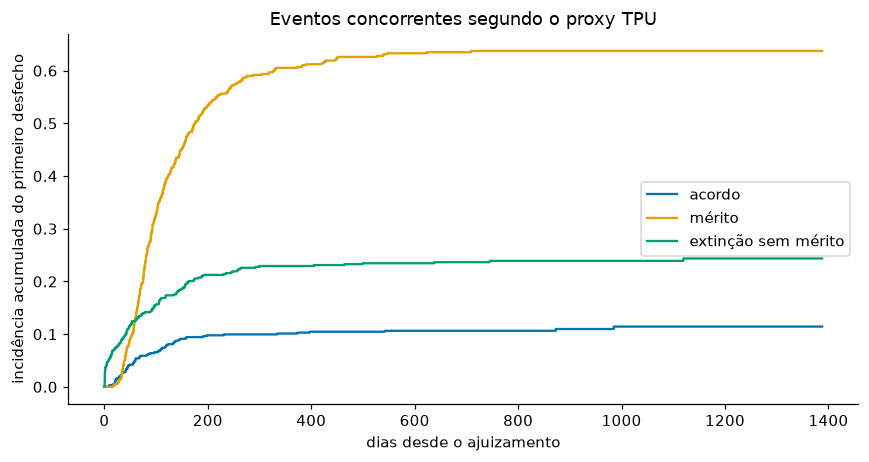

,desfecho,até 365 dias,até 730 dias
0,acordo,"10,12%","10,63%"
1,mérito,"60,54%","63,74%"
2,extinção sem mérito,"22,93%","23,66%"


In [95]:
from lifelines import AalenJohansenFitter
_evento = np.select([td.desfecho.astype(str) == 'acordo',
                      td.desfecho.astype(str) == 'mérito',
                      td.desfecho.astype(str) == 'extinção sem mérito'], [1, 2, 3], default=0)
assert np.array_equal((_evento > 0).astype(int), td.e.astype(int).to_numpy())
_aj = {}
fig, ax = plt.subplots(figsize=(8, 4.3))
for _k, _nome in [(1, 'acordo'), (2, 'mérito'), (3, 'extinção sem mérito')]:
    _f = AalenJohansenFitter(calculate_variance=False, seed=2026).fit(td.t, _evento,
                                                                        event_of_interest=_k, label=_nome)
    _aj[_nome] = _f
    _f.plot(ax=ax)
ax.set_xlabel('dias desde o ajuizamento')
ax.set_ylabel('incidência acumulada do primeiro desfecho')
ax.set_title('Eventos concorrentes segundo o proxy TPU')
fig.tight_layout()
fig.savefig(FIGURAS / 'incidencia_eventos_concorrentes.png', dpi=150)
plt.show()
_linhas = []
for _nome, _f in _aj.items():
    _tab = _f.cumulative_density_.iloc[:, 0]
    _linhas.append({'desfecho': _nome,
                    'até 365 dias': float(_tab.loc[_tab.index <= 365].iloc[-1]) if (_tab.index <= 365).any() else 0.0,
                    'até 730 dias': float(_tab.loc[_tab.index <= 730].iloc[-1]) if (_tab.index <= 730).any() else 0.0})
display(tabela_ptbr(pd.DataFrame(_linhas), pct=['até 365 dias', 'até 730 dias']))

## 19. Simulação de todo o funil

A simulação anterior cobre principalmente os 233 processos da Fase III e demonstra a recuperação de coeficientes sob um modelo gerador favorável. Para servir de exemplo de desenho de pesquisa, esta extensão simula uma **população finita por ano**, com exclusão na Fase I, passagem pela Fase II, indício na Fase III e certeza entre os indícios. Ela sorteia a mesma quantidade de processos por estrato que a amostra real. Os parâmetros são estimados do caso observado; os dados produzidos são artificiais.

Um segundo cenário introduz taxas **hipotéticas** de 1% de falso positivo e 10% de falso negativo no registro do indício. Esses valores não foram medidos na pesquisa. Eles mostram quanto a conclusão dependeria da confiabilidade da codificação, sem exigir nova leitura de processos nem fingir que a simulação valida o rótulo original.

In [96]:
from estcaso3_revisado.metodos import simulacao_funil
_taxas = {}
for _ano in (2022, 2023, 2024):
    _g = am.loc[am.ano == _ano]
    _e = _g.loc[~_g.excluido_f1.astype(bool)]
    _f = _e.loc[_e.alguma_f2.astype(bool)]
    _i = _f.loc[_f.indicio.astype(bool)]
    _taxas[_ano] = (float(_g.excluido_f1.mean()), float(_e.alguma_f2.mean()),
                    float(_f.indicio.mean()), float(_i.certeza.mean()))
_nh = estratos[['N_h', 'n_h']].copy()
_sim = simulacao_funil(_nh, _taxas, repeticoes=300,
                       seed=C.inteiro_semente(SEMENTES['simulacao']))
_sim['erro amostral'] = _sim['estimativa estratificada sem erro'] - _sim['prevalência na população simulada']
_sim['erro com codificação hipotética'] = _sim['estimativa com erro hipotético'] - _sim['prevalência na população simulada']
display(_sim[['erro amostral', 'erro com codificação hipotética']].agg(['mean', 'std',
                lambda x: x.quantile(0.025), lambda x: x.quantile(0.975)]).rename(index={'<lambda>': 'quantil'}).round(4))
display(Markdown('Em 300 populações artificiais, a simulação permite separar a variabilidade do sorteio '
                 'do deslocamento produzido pelo erro de codificação hipotético. Nenhuma taxa de erro '
                 'jurídico real foi estimada aqui.'))

,erro amostral,erro com codificação hipotética
mean,"-0,0016","-0,0108"
std,"0,0151","0,0148"
quantil,"-0,0307","-0,0401"
quantil,"0,0291","0,0183"


Em 300 populações artificiais, a simulação permite separar a variabilidade do sorteio do deslocamento produzido pelo erro de codificação hipotético. Nenhuma taxa de erro jurídico real foi estimada aqui.

## 20. O que estas análises permitem concluir

Os modelos multinomial, ordinal e condicional do roteiro continuam úteis para ensinar perguntas distintas sobre os mesmos dados. ROC e Gini cumprem o pedido do professor, mas empatam porque os escores preservam a mesma ordenação. A comparação de probabilidades fora do ajuste é mais informativa para os três níveis. O agrupamento descreve trajetórias administrativas; o confronto com rótulos existentes decide se essas trajetórias se aproximam da regra da pesquisa. A prevalência populacional operacional continua vindo do sorteio estratificado, não das proporções de grupos do DataJud.

Os testes já apresentados nas seções anteriores são lidos à luz de suas populações de referência e do desenho. Correções de Holm limitam erros de múltiplas comparações, mas uma hipótese escrita no notebook depois de ver os dados não vira, por isso, um pré-registro. A priori bayesiana de 30% também permanece um cenário transferido de outro contexto; as análises de sensibilidade são parte necessária da interpretação. As probabilidades da LCA são de **pertença a perfis estatísticos**, não de certeza jurídica.

## 21. O desenho de pesquisa e o lugar de cada variável

Toshkov (2016, cap. 8, pp. 200–205) descreve o desenho observacional *Large-N* como a comparação de distribuições de variáveis em muitos casos. Aqui, a unidade é o **processo**, a moldura contém 50.320 processos e a amostra sorteada por ano contém 595. O fato de haver muitos casos permite estimar frequências e associações com precisão limitada pelo desenho; não transforma uma associação em efeito causal. A seleção da moldura, a codificação dos sinais e a disponibilidade dos documentos são partes do desenho, não detalhes posteriores ao teste.

As referências aos capítulos 7 e 11 exigem precisão: o **capítulo 7** trata de experimentos, ausentes neste estudo; a simulação computacional do fim do caderno é um ensaio do método e não randomização de processos reais. O **capítulo 11** trata de desenhos mistos e aninhados. A leitura dos autos na pesquisa de origem e o cruzamento com o DataJud para os mesmos processos compõem duas fontes em casos aninhados, mas a auditoria automática de códigos não equivale a uma nova leitura independente dos autos. O quadro abaixo documenta esta separação antes de qualquer interpretação substantiva.

| Elemento | Definição nesta análise | Consequência |
|---|---|---|
| unidade e moldura | processo distribuído nos JEC de Natal, 2022–2024, depois das exclusões documentadas | estimativas valem para a moldura depurada |
| sorteio | estratos por ano; JEC é domínio de análise, não estrato de sorteio | usar pesos e erro-padrão do desenho para prevalência |
| rótulo de pesquisa | F1–F3, com indício e certeza definidos pela regra de codificação | alvo operacional, não padrão jurídico independente |
| novas variáveis | movimentos, desfecho e tempos do DataJud após distribuição | úteis para associação e trajetória; não para prever o risco na distribuição |
| simulação | população artificial com parâmetros declarados | verifica comportamento do procedimento sob hipóteses, sem gerar evidência empírica nova |

Os exemplos de probabilidade condicional e Bayes das Seções 5–6 usam a amostra tratada, e não a planilha de casos novos como se fosse outra amostra de 595. Uma priori de 30% foi **atribuída como cenário** a partir do levantamento documental citado na revisão de escopo da Hadja; a revisão conceitual não estimou essa prevalência para Natal. A verossimilhança de cada desfecho vem da frequência na amostra vinculada ao DataJud. A probabilidade total soma os dois produtos `priori × verossimilhança`, porque H₀ e Hₐ foram definidos como complementares. A posteriori é a proporção do produto de Hₐ nessa soma. Reaproveitar a prevalência 17,65% simultaneamente como priori e como dado da verossimilhança contaria a mesma amostra duas vezes.

Friendly e Meyer (2016, cap. 6) orientam a análise de correspondência como visualização dos desvios de independência em tabelas categóricas. Os mapas já calculados na Seção 7 incluem inércia, massas, contribuições e qualidade de representação; pontos de linhas e colunas em mapa simétrico não têm distância euclidiana diretamente interpretável entre si. Categorias raras e células com frequência esperada pequena tornam a posição instável. Os sinais F3 entram na MCA apenas como suplementares, pois participam da própria regra que define a resposta.

## 22. Quanto os desfechos novos conseguem distinguir as três categorias?

Os logitos multinomial, ordinal e de razão contínua da Seção 8 usam sinais F2 registrados pela pesquisa e, por isso, respondem principalmente como modelar **essa regra operacional**. Para medir a contribuição dos *dados novos*, ajustamos agora dois modelos simples com o desfecho TPU e três marcadores da trajetória administrativa. Os parâmetros são aprendidos em 2022–2023; as probabilidades são avaliadas nos processos de 2024, que não participaram do ajuste. A comparação inclui uma previsão que usa somente a frequência das classes no treino. A perda logarítmica e o Brier permitem ver se um modelo melhora sobre essa referência. A precisão global isolada seria enganosa, pois a classe majoritária domina a amostra.

Esses campos surgem depois do ajuizamento e não podem ser usados para alegar previsão no momento da distribuição. O desfecho TPU é proxy, e os rótulos da pesquisa são a referência disponível. Mesmo um ganho numérico neste confronto não estabeleceria acurácia jurídica nem autorizaria listas individuais de lides predatórias.

In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score

DJ_NOVO = dj.loc[dj.desfecho.notna()].copy()
_tr = DJ_NOVO.ano.astype(int).to_numpy() < 2024
_te = ~_tr
_cols = ['desfecho', 'houve_recurso', 'evoluiu_cumprimento', 'redistribuido']
_Z = DJ_NOVO[_cols].copy()
for _c in _cols:
    _Z[_c] = _Z[_c].astype(str)
_y = DJ_NOVO.classe3_cod.astype(int).to_numpy()
_enc = ColumnTransformer([('categorias', OneHotEncoder(handle_unknown='ignore'), _cols)])
_modelo = make_pipeline(_enc, LogisticRegression(max_iter=1000, C=1.0, random_state=2026))
_modelo.fit(_Z.loc[_tr], _y[_tr])
_pred = _modelo.predict_proba(_Z.loc[_te])
_base = np.tile(np.bincount(_y[_tr], minlength=3) / _tr.sum(), (_te.sum(), 1))
_linhas = []
for _nome, _p in [('frequência do treino', _base), ('logito multinomial, DataJud', _pred)]:
    _linhas.append({'modelo': _nome, 'n treino': int(_tr.sum()), 'n teste': int(_te.sum()),
                    'log-loss 2024': log_loss(_y[_te], _p, labels=[0, 1, 2]),
                    'Brier 2024': np.mean(np.sum((_p - np.eye(3)[_y[_te]]) ** 2, axis=1)),
                    'acurácia balanceada': balanced_accuracy_score(_y[_te], _p.argmax(1)),
                    'F1 macro': f1_score(_y[_te], _p.argmax(1), average='macro', zero_division=0)})
AVAL_DJ = pd.DataFrame(_linhas)
display(tabela_ptbr(AVAL_DJ, casas=4))
display(pd.crosstab(pd.Series(_y[_te], name='classe da pesquisa'),
                    pd.Series(_pred.argmax(1), name='classe prevista com DataJud')))
display(Markdown('A diferença de log-loss entre o modelo DataJud e a frequência do treino é **' +
                 fnum(AVAL_DJ.loc[1, 'log-loss 2024'] - AVAL_DJ.loc[0, 'log-loss 2024'], 4) +
                 '**. Valor negativo favorece o modelo com desfechos; a interpretação continua '
                 'limitada pela codificação dos rótulos e pela mudança de ano.'))
display(Markdown('No limiar da classe mais provável, o modelo atribuiu a categoria majoritária a **' +
                 str(int((_pred.argmax(1) == 0).sum())) + ' de ' + str(int(_te.sum())) +
                 '** casos. Assim, o pequeno ganho de log-loss não se traduz em distinção útil '
                 'das categorias minoritárias.'))

,modelo,n treino,n teste,log-loss 2024,Brier 2024,acurácia balanceada,F1 macro
0,frequência do treino,403,190,"0,5241","0,2654","0,3333","0,3068"
1,"logito multinomial, DataJud",403,190,"0,5080","0,2624","0,3333","0,3068"


classe prevista com DataJud,0
classe da pesquisa,
0,162
1,18
2,10


A diferença de log-loss entre o modelo DataJud e a frequência do treino é **-0,0162**. Valor negativo favorece o modelo com desfechos; a interpretação continua limitada pela codificação dos rótulos e pela mudança de ano.

No limiar da classe mais provável, o modelo atribuiu a categoria majoritária a **190 de 190** casos. Assim, o pequeno ganho de log-loss não se traduz em distinção útil das categorias minoritárias.

## 23. Quadro de variáveis e dicionário para reutilização

O quadro informa **qual conceito cada coluna pretende representar**; o dicionário acrescenta **onde e quando ela foi medida**, quem entrou no denominador, como foi codificada e como a ausência deve ser tratada. Essa distinção é essencial no funil: F2 ausente em um excluído na Fase I significa “não avaliado”, enquanto `indicio = 0` nesse mesmo registro é uma decisão da regra de classificação ampla. As duas colunas não são observações equivalentes. O desfecho do DataJud, por sua vez, é posterior à distribuição e depende de registro administrativo. O arquivo exportado conserva os nomes e contagens do quadro original e acrescenta campos para que os colegas possam adaptar o modelo aos próprios projetos.

In [98]:
_dic = QUADRO_TURMA.copy()
def _meta_variavel(nome):
    if nome in ('numero', 'ordem'):
        return ('moldura e vínculo', 'identificador', 'antes do sorteio', '595 processos da amostra',
                'não se aplica', 'não entra como preditor; serve à conferência do vínculo')
    if nome in ('jec', 'ano', 'classe_planilha'):
        return ('moldura / planilha', 'descrição ou domínio', 'na distribuição ou na coleta, conforme a coluna',
                '595 processos', 'ausência deve ser investigada na fonte', 'ano é estrato; JEC é domínio; classe da planilha pode ser posterior')
    if nome.startswith('F1_'):
        return ('planilha da pesquisa, leitura dos autos', 'critério de elegibilidade', 'fase I da pesquisa',
                '595 processos', 'NA: não informado; não converter automaticamente em Não', 'afeta quem pode alcançar F2')
    if nome.startswith('F2_'):
        return ('planilha da pesquisa, leitura dos autos', 'sinal de indício', 'fase II da pesquisa',
                '444 elegíveis', 'NA estrutural para os 151 excluídos na F1', 'não usar NA como ausência de sinal')
    if nome.startswith('F3_'):
        return ('planilha da pesquisa, leitura dos autos', 'critério de certeza', 'fase III da pesquisa',
                '233 que alcançaram F3', 'NA estrutural para quem não alcançou F3', 'participa da definição da classe3; não usar como preditor dela')
    if nome in ('desfecho', 't_desfecho', 'houve_recurso', 'classe_origem'):
        return ('DataJud / códigos TPU', 'trajetória ou desfecho operacional', 'após a distribuição',
                '593 com documento vinculado', 'sem documento para 2 da amostra; censura temporal é distinta de NA',
                'proxy administrativo; não usar para previsão no ajuizamento')
    return ('derivada da planilha F1–F3', 'resposta ou variável do funil', 'após codificação da pesquisa',
            '595 processos; conferir universo de origem das variáveis componentes',
            'zero pode ser efeito da regra do funil, não medição de F2/F3',
            'dependência mecânica com F1–F3; interpretar modelos como reprodução parcial da regra')

_meta = [_meta_variavel(x) for x in _dic.nome]
for _i, _col in enumerate(['fonte', 'papel analítico', 'momento', 'universo de medição',
                           'regra de ausência', 'restrição de interpretação']):
    _dic[_col] = [r[_i] for r in _meta]
_dic['regra operacional'] = _dic['descricao']
_dic['n_sem_medida'] = 595 - _dic.n_validos.astype(int)
assert (_dic.n_validos.astype(int) + _dic.n_sem_medida == 595).all()
_conceitos = pd.DataFrame([
    {'conceito': 'indício amplo', 'indicador': 'indicio', 'unidade': 'processo', 'fonte': 'F1–F3',
     'universo': '595 sorteados', 'limite': 'rótulo operacional da pesquisa'},
    {'conceito': 'certeza conforme regra', 'indicador': 'certeza', 'unidade': 'processo', 'fonte': 'F3',
     'universo': '595 sorteados; F3 observada em 233', 'limite': 'três sinais F3 simultâneos'},
    {'conceito': 'trajetória administrativa', 'indicador': 'desfecho, recurso, cumprimento, tempo',
     'unidade': 'processo', 'fonte': 'DataJud / TPU', 'universo': '593 vinculados',
     'limite': 'não identifica por si a predação jurídica'},
    {'conceito': 'prevalência na moldura', 'indicador': 'estimador estratificado de indicio',
     'unidade': 'processos da moldura', 'fonte': 'amostra + pesos por ano',
     'universo': '50.320 processos depurados', 'limite': 'estimativa, não contagem exata'},
])
with pd.ExcelWriter(TABELAS / 'quadro_dicionario_large_n.xlsx') as _xw:
    _conceitos.to_excel(_xw, sheet_name='Quadro conceitual', index=False)
    _dic.to_excel(_xw, sheet_name='Dicionário operacional', index=False)
    _sim[['prevalência na população simulada', 'estimativa estratificada sem erro',
          'estimativa com erro hipotético']].to_excel(_xw, sheet_name='Simulação do funil', index=False)
display(_conceitos)
display(_dic[['nome', 'fonte', 'papel analítico', 'universo de medição', 'regra de ausência',
              'restrição de interpretação']].head(12))
display(Markdown(f'O dicionário documenta **{len(_dic)} variáveis** e acompanha um exemplo '
                 'de simulação da população finita; as 300 réplicas são artificiais.'))

,conceito,indicador,unidade,fonte,universo,limite
0,indício amplo,indicio,processo,F1–F3,595 sorteados,rótulo operacional da pesquisa
1,certeza conforme regra,certeza,processo,F3,595 sorteados; F3 observada em 233,três sinais F3 simultâneos
2,trajetória administrativa,"desfecho, recurso, cumprimento, tempo",processo,DataJud / TPU,593 vinculados,não identifica por si a predação jurídica
3,prevalência na moldura,estimador estratificado de indicio,processos da moldura,amostra + pesos por ano,50.320 processos depurados,"estimativa, não contagem exata"


,nome,fonte,papel analítico,universo de medição,regra de ausência,restrição de interpretação
0,numero,moldura e vínculo,identificador,595 processos da amostra,não se aplica,não entra como preditor; serve à conferência d...
1,ordem,moldura e vínculo,identificador,595 processos da amostra,não se aplica,não entra como preditor; serve à conferência d...
2,jec,moldura / planilha,descrição ou domínio,595 processos,ausência deve ser investigada na fonte,ano é estrato; JEC é domínio; classe da planil...
3,ano,moldura / planilha,descrição ou domínio,595 processos,ausência deve ser investigada na fonte,ano é estrato; JEC é domínio; classe da planil...
4,classe_planilha,moldura / planilha,descrição ou domínio,595 processos,ausência deve ser investigada na fonte,ano é estrato; JEC é domínio; classe da planil...
5,F1_A,"planilha da pesquisa, leitura dos autos",critério de elegibilidade,595 processos,NA: não informado; não converter automaticamen...,afeta quem pode alcançar F2
6,F1_B,"planilha da pesquisa, leitura dos autos",critério de elegibilidade,595 processos,NA: não informado; não converter automaticamen...,afeta quem pode alcançar F2
7,F1_C,"planilha da pesquisa, leitura dos autos",critério de elegibilidade,595 processos,NA: não informado; não converter automaticamen...,afeta quem pode alcançar F2
8,F1_D,"planilha da pesquisa, leitura dos autos",critério de elegibilidade,595 processos,NA: não informado; não converter automaticamen...,afeta quem pode alcançar F2
9,F1_E,"planilha da pesquisa, leitura dos autos",critério de elegibilidade,595 processos,NA: não informado; não converter automaticamen...,afeta quem pode alcançar F2


O dicionário documenta **41 variáveis** e acompanha um exemplo de simulação da população finita; as 300 réplicas são artificiais.

## 24. Previsão de indício no ajuizamento

As análises anteriores descrevem sinais encontrados na leitura dos autos e trajetórias processuais. Aqui a pergunta muda: **quanto se consegue antecipar no ajuizamento, antes de conhecer o desfecho?** A resposta é o indício em sentido amplo, definido na pesquisa por F3_19 e F3_20 e incluindo os casos de certeza. O assunto, o juizado e o mês são os únicos preditores desta comparação. O assunto é lido da moldura do TJRN, vinculada aos mesmos processos da amostra. A classe não entra porque pode mudar. Desfecho, duração e movimentos posteriores também ficam fora.

Os 405 casos de 2022–2023 ajustam os modelos e os 190 de 2024 avaliam as probabilidades. Todas as linhas da tabela usam **a mesma resposta, as mesmas observações e a mesma divisão temporal**. AUC resume a ordenação, precisão média resume a curva precisão–revocação e perda logarítmica avalia as probabilidades. Menor perda é melhor; para as outras duas métricas, maior é melhor. A prevalência de indício no teste é 28/190, de modo que a precisão média precisa ser lida junto com essa frequência.

Esta comparação é exploratória: o ano de 2024 já foi examinado durante o desenvolvimento do estudo, e o rótulo representa a regra operacional da pesquisa, não um diagnóstico jurídico independente. Uma coorte futura, ainda não usada na escolha dos modelos, será necessária para validar o desempenho.

In [99]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, confusion_matrix

_entrada = am[['numero', 'ano', 'jec', 'indicio', 'certeza']].merge(
    base[['NÚMERO PROCESSO', 'CÓD ASSUNTO', 'DATA INÍCIO']].rename(columns={'NÚMERO PROCESSO': 'numero'}),
    on='numero', how='left', validate='one_to_one', indicator=True)
assert len(_entrada) == 595 and (_entrada['_merge'] == 'both').all()
_entrada['assunto'] = _entrada['CÓD ASSUNTO'].fillna('AUSENTE').astype(str)
_entrada['jec_txt'] = _entrada.jec.astype(str)
_entrada['mes'] = pd.to_datetime(_entrada['DATA INÍCIO'], format='%d-%m-%Y %H:%M:%S').dt.month.astype(str)
_entrada['assunto_6226'] = np.where(_entrada.assunto.eq('6226'), 'sim', 'não')
_tr_e = _entrada.ano.astype(int).to_numpy() < 2024
_te_e = ~_tr_e
_y_e = _entrada.indicio.astype(int).to_numpy()
assert (int(_tr_e.sum()), int(_te_e.sum()), int(_y_e.sum()), int(_y_e[_te_e].sum())) == (405, 190, 105, 28)

_alternativas = [
    ('frequência do treino', [], DummyClassifier(strategy='prior')),
    ('juizado + mês', ['jec_txt', 'mes'], LogisticRegression(C=0.3, max_iter=3000)),
    ('assunto 6226', ['assunto_6226'], LogisticRegression(C=0.3, max_iter=3000)),
    ('regressão logística com assunto', ['assunto'], LogisticRegression(C=0.3, max_iter=3000)),
    ('regressão logística com assunto + juizado + mês', ['assunto', 'jec_txt', 'mes'],
     LogisticRegression(C=0.3, max_iter=3000)),
    ('floresta aleatória com assunto', ['assunto'],
     RandomForestClassifier(n_estimators=300, min_samples_leaf=8, max_features=0.7,
                            random_state=43, n_jobs=1)),
]
_resultados_e, _prob_e = [], {}
for _nome, _campos, _estimador in _alternativas:
    if _campos:
        _x_e = _entrada[_campos]
        _modelo_e = make_pipeline(OneHotEncoder(handle_unknown='ignore'), _estimador)
        _modelo_e.fit(_x_e.loc[_tr_e], _y_e[_tr_e])
        _p_e = _modelo_e.predict_proba(_x_e.loc[_te_e])[:, 1]
    else:
        _modelo_e = _estimador.fit(np.zeros((_tr_e.sum(), 1)), _y_e[_tr_e])
        _p_e = _modelo_e.predict_proba(np.zeros((_te_e.sum(), 1)))[:, 1]
    _prob_e[_nome] = _p_e
    _resultados_e.append({'modelo': _nome, 'AUC 2024': roc_auc_score(_y_e[_te_e], _p_e),
                          'precisão média 2024': average_precision_score(_y_e[_te_e], _p_e),
                          'perda logarítmica 2024': log_loss(_y_e[_te_e], _p_e)})
_tabela_e = pd.DataFrame(_resultados_e)
display(tabela_ptbr(_tabela_e, casas=3))

_p_assunto = _prob_e['regressão logística com assunto']
_cm_e = confusion_matrix(_y_e[_te_e], _p_assunto >= 0.5, labels=[0, 1])
_top_e = np.argsort(-_p_assunto)[:38]
_cert_e = _entrada.certeza.astype(int).to_numpy()[_te_e]
display(pd.DataFrame(_cm_e, index=['sem indício na pesquisa', 'indício na pesquisa'],
                     columns=['escore < 0,5', 'escore ≥ 0,5']))
display(pd.DataFrame([{'recorte': '38 maiores escores de 2024',
                       'indícios encontrados': int(_y_e[_te_e][_top_e].sum()),
                       'indícios em 2024': int(_y_e[_te_e].sum()),
                       'certezas encontradas': int(_cert_e[_top_e].sum()),
                       'certezas em 2024': int(_cert_e.sum())}]))
assert (_cm_e == np.array([[153, 9], [11, 17]])).all()
assert int(_y_e[_te_e][_top_e].sum()) == 22

,modelo,AUC 2024,precisão média 2024,perda logarítmica 2024
0,frequência do treino,"0,500","0,147","0,424"
1,juizado + mês,"0,528","0,156","0,434"
2,assunto 6226,"0,776","0,455","0,301"
3,regressão logística com assunto,"0,859","0,563","0,293"
4,regressão logística com assunto + juizado + mês,"0,813","0,546","0,305"
5,floresta aleatória com assunto,"0,816","0,490","0,295"


,"escore < 0,5","escore ≥ 0,5"
sem indício na pesquisa,153,9
indício na pesquisa,11,17


,recorte,indícios encontrados,indícios em 2024,certezas encontradas,certezas em 2024
0,38 maiores escores de 2024,22,28,9,10


O resultado mais alto da tabela é da **regressão logística com assunto**: AUC 0,859, precisão média 0,563 e perda logarítmica 0,293. Entre os 38 maiores escores de 2024 estão 22 dos 28 indícios e 9 dos 10 casos classificados como certeza. No limiar 0,5, há 17 verdadeiros positivos, 9 falsos positivos, 11 falsos negativos e 153 verdadeiros negativos. Esses números descrevem a reprodução do rótulo da pesquisa; não significam que o modelo tenha examinado a petição ou demonstrado predação.

O ganho depende muito do **assunto 6226**, “Inclusão Indevida em Cadastro de Inadimplentes”: ele concentra 74 dos 105 indícios dos 595 processos. A regra simples baseada somente nesse assunto produz a mesma matriz no limiar 0,5. A regressão com todos os assuntos ordena melhor os casos, mas isso ainda precisa ser confirmado em novos processos. Juizado e mês não melhoraram o resultado de 2024; a floresta aleatória também ficou abaixo da regressão simples. Como havia apenas 20 certezas no treino e 10 em 2024, o bom ranqueamento de alguns desses casos não autoriza classificá-los como “certeza” no ajuizamento.

**Qual número citar.** A regularização C = 0,3 desta tabela foi fixada na exploração, e não escolhida nos dados de desenvolvimento. A Seção 26 refaz a escolha por validação cruzada aninhada apenas em 2022–2023 e congela o modelo antes de olhar 2024. **A AUC de referência do modelo de assunto é a da Seção 26.** A Seção 31 usa a mesma informação de outro modo: o assunto como informação auxiliar para estimar a prevalência na moldura.

## 25. A categoria “certeza” fora do ajuste

A comparação anterior resumiu a perda logarítmica e o Brier dos três modelos de resposta ordinal ou multinomial. Aqui examinamos as **previsões fora do ajuste** que produziram esses números. Cada um dos 233 processos da Fase III recebeu probabilidades de um modelo treinado nos outros quatro blocos da validação cruzada. A matriz mostra a categoria de maior probabilidade; a tabela separa sensibilidade e precisão por classe. Isso é importante porque uma AUC alta para *indício versus demais* não demonstra que a classe mais restrita, “certeza”, foi reconhecida.

Os três sinais F2 e as famílias de modelo foram escolhidos no estudo dos mesmos processos antes desta avaliação. Assim, a validação é **interna e retrospectiva**, mesmo que as probabilidades abaixo sejam fora do ajuste dos coeficientes. Os rótulos representam a regra operacional da pesquisa.

In [100]:
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from statsmodels.stats.proportion import proportion_confint

_linhas_3 = []
for _nome_3, _pr_3 in _probs.items():
    _cm_3 = confusion_matrix(y3, _pr_3.argmax(axis=1), labels=[0, 1, 2])
    display(pd.DataFrame(_cm_3, index=[f'pesquisa: {x}' for x in NIVEIS_CLASSE3],
                         columns=[f'previsto: {x}' for x in NIVEIS_CLASSE3]).rename_axis(_nome_3))
    for _k_3, _classe_3 in enumerate(NIVEIS_CLASSE3):
        _vp_3 = int(_cm_3[_k_3, _k_3])
        _n_real_3 = int(_cm_3[_k_3].sum())
        _n_prev_3 = int(_cm_3[:, _k_3].sum())
        _lo_3, _hi_3 = proportion_confint(_vp_3, _n_real_3, method='wilson')
        _linhas_3.append({'modelo': _nome_3, 'classe': _classe_3,
                          'n real': _n_real_3, 'n previsto': _n_prev_3,
                          'sensibilidade': _vp_3 / _n_real_3,
                          'IC Wilson inf.': _lo_3, 'IC Wilson sup.': _hi_3,
                          'precisão': _vp_3 / _n_prev_3 if _n_prev_3 else np.nan,
                          'kappa ponderado do modelo': cohen_kappa_score(y3, _pr_3.argmax(axis=1), weights='linear')})
TAB_VALIDACAO_3 = pd.DataFrame(_linhas_3)
display(tabela_ptbr(TAB_VALIDACAO_3, casas=3,
                    pct=['sensibilidade', 'IC Wilson inf.', 'IC Wilson sup.', 'precisão']))
assert set(TAB_VALIDACAO_3.loc[TAB_VALIDACAO_3.classe == 'certeza', 'n real']) == {30}

,previsto: não predatória,previsto: indício sem certeza,previsto: certeza
multinomial,,,
pesquisa: não predatória,116,12,0
pesquisa: indício sem certeza,13,61,1
pesquisa: certeza,7,23,0


,previsto: não predatória,previsto: indício sem certeza,previsto: certeza
ordinal PO,,,
pesquisa: não predatória,117,11,0
pesquisa: indício sem certeza,13,62,0
pesquisa: certeza,7,23,0


,previsto: não predatória,previsto: indício sem certeza,previsto: certeza
razão contínua,,,
pesquisa: não predatória,117,11,0
pesquisa: indício sem certeza,13,62,0
pesquisa: certeza,7,23,0


,previsto: não predatória,previsto: indício sem certeza,previsto: certeza
frequência no treino,,,
pesquisa: não predatória,128,0,0
pesquisa: indício sem certeza,75,0,0
pesquisa: certeza,30,0,0


,modelo,classe,n real,n previsto,sensibilidade,IC Wilson inf.,IC Wilson sup.,precisão,kappa ponderado do modelo
0,multinomial,não predatória,128,136,"90,625%","84,327%","94,556%","85,294%","0,566"
1,multinomial,indício sem certeza,75,96,"81,333%","71,071%","88,542%","63,542%","0,566"
2,multinomial,certeza,30,1,"0,000%","0,000%","11,351%","0,000%","0,566"
3,ordinal PO,não predatória,128,137,"91,406%","85,266%","95,134%","85,401%","0,578"
4,ordinal PO,indício sem certeza,75,96,"82,667%","72,569%","89,581%","64,583%","0,578"
5,ordinal PO,certeza,30,0,"0,000%","0,000%","11,351%",—,"0,578"
6,razão contínua,não predatória,128,137,"91,406%","85,266%","95,134%","85,401%","0,578"
7,razão contínua,indício sem certeza,75,96,"82,667%","72,569%","89,581%","64,583%","0,578"
8,razão contínua,certeza,30,0,"0,000%","0,000%","11,351%",—,"0,578"
9,frequência no treino,não predatória,128,233,"100,000%","97,086%","100,000%","54,936%","0,000"


**Leitura.** Nas previsões fora do ajuste, os três modelos acertam **0 dos 30 casos de certeza**. O multinomial atribui essa categoria a um único processo, que pertence ao grupo “indício sem certeza”; o ordinal PO e a razão contínua não a atribuem a ninguém. A sensibilidade observada de certeza é 0%, com limite superior de Wilson próximo de 11,35%. Esse limite expressa incerteza amostral, não resgata a ausência de acertos. A categoria de maior probabilidade é uma regra de decisão, não uma exigência matemática do modelo probabilístico. Um eventual corte alternativo para certeza teria de ser escolhido nos dados de treino de cada bloco e validado fora dele. A AUC binária de 0,908 não responde a essa pergunta de três classes.

## 26. Escolha do modelo de previsão no ajuizamento dentro do treino

Os 405 processos de 2022–2023 são o conjunto de desenvolvimento e os 190 de 2024 servem a uma verificação temporal **exploratória**. O ano de 2024 já influenciou a exploração registrada na Seção 24; repetir a análise com uma regra explícita de escolha não recupera um teste intocado. Ainda assim, podemos evitar um novo erro: escolher variáveis ou regularização depois de comparar as métricas de 2024.

Dentro de 2022–2023, uma validação cruzada **aninhada** avalia o procedimento completo de escolha. O bloco interno seleciona, pela perda logarítmica, entre frequência de treino, JEC + mês, assunto e assunto + JEC + mês, com três forças de regularização. O bloco externo avalia previsões de casos que não participaram dessa seleção. Em seguida, a escolha é refeita nos 405 e congelada antes da verificação em 2024. A codificação das categorias é ajustada somente em cada treino por meio de uma *pipeline*. O assunto 6226 isolado não é candidato aqui porque foi destacado após examinar o estudo inteiro.

O bootstrap de 2024 abaixo mede a dispersão das métricas **condicional ao modelo já ajustado** e preserva a quantidade observada de positivos e negativos. Ele não incorpora a incerteza da escolha do modelo, nem cria uma coorte externa. Perda logarítmica e Brier avaliam a qualidade das probabilidades como um todo; a média prevista comparada à frequência observada é uma checagem simples de calibração no agregado. Com apenas 28 positivos, uma curva flexível ou um coeficiente de calibração teria grande incerteza.

In [101]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

_cols_25 = {'JEC + mês': ['jec_txt', 'mes'], 'assunto': ['assunto'],
            'assunto + JEC + mês': ['assunto', 'jec_txt', 'mes']}
_candidatos_25 = [('frequência do treino', (), None)] + [
    (f'{nome}; C={c:g}', tuple(cols), c)
    for nome, cols in _cols_25.items() for c in (0.03, 0.3, 3.0)]
_X_25 = _entrada.reset_index(drop=True)
_y_25 = _y_e.copy()
_idx_dev_25 = np.flatnonzero(_tr_e)
_idx_2024_25 = np.flatnonzero(_te_e)

def _ajustar_25(nome, cols, c, treino, teste):
    if c is None:
        return np.full(len(teste), _y_25[treino].mean())
    modelo = make_pipeline(OneHotEncoder(handle_unknown='ignore'),
                          LogisticRegression(C=c, max_iter=3000))
    modelo.fit(_X_25.loc[treino, list(cols)], _y_25[treino])
    return modelo.predict_proba(_X_25.loc[teste, list(cols)])[:, 1]

def _escolher_25(indices, *, semente, partes=4):
    cv_interno = StratifiedKFold(n_splits=partes, shuffle=True, random_state=semente)
    resultados = []
    for nome, cols, c in _candidatos_25:
        pr = np.full(len(indices), np.nan)
        for tr_local, val_local in cv_interno.split(indices, _y_25[indices]):
            pr[val_local] = _ajustar_25(nome, cols, c, indices[tr_local], indices[val_local])
        assert np.isfinite(pr).all()
        resultados.append((log_loss(_y_25[indices], pr, labels=[0, 1]), nome, cols, c))
    return min(resultados, key=lambda r: (r[0], r[1])), resultados

_cv_externo_25 = StratifiedKFold(n_splits=5, shuffle=True, random_state=20261030)
_oof_25 = np.full(len(_idx_dev_25), np.nan)
_escolhas_25 = []
for _tr_l, _te_l in _cv_externo_25.split(_idx_dev_25, _y_25[_idx_dev_25]):
    _id_tr = _idx_dev_25[_tr_l]
    _id_te = _idx_dev_25[_te_l]
    _melhor, _ = _escolher_25(_id_tr, semente=20261030 + int(_te_l[0]))
    _escolhas_25.append(_melhor[1])
    _oof_25[_te_l] = _ajustar_25(*_melhor[1:], _id_tr, _id_te)
assert np.isfinite(_oof_25).all()
_melhor_25, _todos_25 = _escolher_25(_idx_dev_25, semente=20261031, partes=5)
_p_2024_25 = _ajustar_25(*_melhor_25[1:], _idx_dev_25, _idx_2024_25)
_y_2024_25 = _y_25[_idx_2024_25]
_p_base_25 = np.full(len(_idx_2024_25), _y_25[_idx_dev_25].mean())

def _metricas_25(y, p):
    return {'AUC': roc_auc_score(y, p), 'precisão média': average_precision_score(y, p),
            'log-loss': log_loss(y, p, labels=[0, 1]), 'Brier': brier_score_loss(y, p),
            'média prevista': float(np.mean(p)), 'frequência observada': float(np.mean(y))}

TAB_ESCOLHA_25 = pd.DataFrame([{'candidato': r[1], 'log-loss CV no desenvolvimento': r[0]}
                               for r in sorted(_todos_25, key=lambda r: (r[0], r[1]))])
display(tabela_ptbr(TAB_ESCOLHA_25, casas=4))
TAB_AVALIACAO_25 = pd.DataFrame([
    {'avaliação': 'procedimento completo: CV externa, 2022–2023',
     'modelo': 'escolha interna por bloco', **_metricas_25(_y_25[_idx_dev_25], _oof_25)},
    {'avaliação': 'frequência do treino em 2024', 'modelo': 'referência',
     **_metricas_25(_y_2024_25, _p_base_25)},
    {'avaliação': 'modelo congelado em 2024', 'modelo': _melhor_25[1],
     **_metricas_25(_y_2024_25, _p_2024_25)},
])
display(tabela_ptbr(TAB_AVALIACAO_25, casas=4,
                    pct=['média prevista', 'frequência observada']))
display(pd.Series(_escolhas_25).value_counts().rename('escolhas nos 5 blocos externos').to_frame())

_rng_25 = np.random.default_rng(20261031)
_pos_25, _neg_25 = np.flatnonzero(_y_2024_25 == 1), np.flatnonzero(_y_2024_25 == 0)
_boot_25 = []
for _ in range(2000):
    _ind_25 = np.r_[_rng_25.choice(_pos_25, len(_pos_25), replace=True),
                     _rng_25.choice(_neg_25, len(_neg_25), replace=True)]
    _m_25 = _metricas_25(_y_2024_25[_ind_25], _p_2024_25[_ind_25])
    _m_25['ganho log-loss versus frequência'] = (
        log_loss(_y_2024_25[_ind_25], _p_base_25[_ind_25], labels=[0, 1]) - _m_25['log-loss'])
    _boot_25.append(_m_25)
_boot_25 = pd.DataFrame(_boot_25)
display(tabela_ptbr(pd.DataFrame([{'métrica': c, 'estimativa 2024':
    (TAB_AVALIACAO_25.iloc[1]['log-loss'] - TAB_AVALIACAO_25.iloc[2]['log-loss'])
    if c == 'ganho log-loss versus frequência' else TAB_AVALIACAO_25.iloc[2][c],
    'limite inferior': _boot_25[c].quantile(.025), 'limite superior': _boot_25[c].quantile(.975)}
    for c in ('AUC', 'precisão média', 'log-loss', 'Brier', 'ganho log-loss versus frequência')]), casas=4))

,candidato,log-loss CV no desenvolvimento
0,assunto; C=3,"0,3049"
1,assunto + JEC + mês; C=0.3,"0,3083"
2,assunto + JEC + mês; C=3,"0,3117"
3,assunto; C=0.3,"0,3174"
4,assunto + JEC + mês; C=0.03,"0,4084"
5,assunto; C=0.03,"0,4104"
6,JEC + mês; C=0.03,"0,4843"
7,frequência do treino,"0,4865"
8,JEC + mês; C=0.3,"0,4866"
9,JEC + mês; C=3,"0,5117"


,avaliação,modelo,AUC,precisão média,log-loss,Brier,média prevista,frequência observada
0,"procedimento completo: CV externa, 2022–2023",escolha interna por bloco,"0,8481","0,5886","0,3083","0,0892","19,2113%","19,0123%"
1,frequência do treino em 2024,referência,"0,5000","0,1474","0,4244","0,1275","19,0123%","14,7368%"
2,modelo congelado em 2024,assunto; C=3,"0,8759","0,5721","0,2690","0,0788","15,5298%","14,7368%"


,escolhas nos 5 blocos externos
assunto; C=3,5


,métrica,estimativa 2024,limite inferior,limite superior
0,AUC,"0,8759","0,7881","0,9443"
1,precisão média,"0,5721","0,4335","0,7335"
2,log-loss,"0,2690","0,2079","0,3369"
3,Brier,"0,0788","0,0566","0,1028"
4,ganho log-loss versus frequência,"0,1554","0,0875","0,2165"


**Leitura.** A escolha interna em 2022–2023 foi **assunto, C = 3**, repetida nos cinco blocos externos. A validação aninhada nesse período obteve AUC **0,848** e log-loss **0,308** para o procedimento de escolha completo. Após ajuste nos 405 casos de desenvolvimento, o modelo alcançou em 2024 AUC **0,876**, precisão média **0,572**, log-loss **0,269** e Brier **0,079**; a frequência do treino teve log-loss **0,424**. O bootstrap condicional dá aproximadamente **[0,788; 0,944]** para a AUC e **[0,088; 0,217]** para o ganho de log-loss sobre a frequência. A probabilidade média prevista foi **15,53%**, perto dos **14,74%** observados; isso examina só a calibração média. As faixas não incluem a incerteza da escolha do modelo. A avaliação em 2024 continua exploratória porque os resultados desse ano já eram conhecidos no desenvolvimento do estudo.

## 27. A informação anterior em Bayes e a fonte correta dos rótulos

Uma atualização Bayesiana pode usar os **77 indícios nos 405 processos de 2022–2023** como evidência anterior para os **28 indícios nos 190 de 2024**: são processos distintos. No exemplo Beta-Binomial abaixo, a posteriori do primeiro período vira a priori do segundo. A conta supõe uma prevalência comum entre anos e ignora parte do desenho amostral; por isso é uma ilustração da lógica de atualização, não uma substituição da estimativa estratificada. Para uma regressão logística Bayesiana, a mesma lógica vale para a distribuição conjunta dos coeficientes, com a ressalva de que os efeitos de ano podem mudar.

Os **17,65%** publicados provêm dos mesmos 595 processos; empregá-los como priori e em seguida reapresentar esses 595 na verossimilhança contaria a amostra duas vezes. A priori de 30% da Seção 6 vem de levantamento documental em outra região e com outro recorte; permanece um cenário de sensibilidade. A lista ampla `casos_novos_JEC_Natal_...xlsx` serve à conferência da moldura, enquanto os rótulos dos 595 estão na aba `AMOSTRA` da planilha preenchida. O intervalo [14,59%; 20,70%] do roteiro, embora chamado Wilson, é reproduzido como Wald com correção de população finita; os Wilson e o intervalo aproximado pelo desenho aparecem na Seção 16.

In [102]:
_k_antigo = int(am.loc[am.ano.astype(int) < 2024, 'indicio'].sum())
_n_antigo = int((am.ano.astype(int) < 2024).sum())
_k_novo = int(am.loc[am.ano.astype(int) == 2024, 'indicio'].sum())
_n_novo = int((am.ano.astype(int) == 2024).sum())
assert (_k_antigo, _n_antigo, _k_novo, _n_novo) == (77, 405, 28, 190)
_a0, _b0 = 1, 1
_etapas_bayes = [
    ('antes dos dados', _a0, _b0),
    ('após 2022–2023', _a0 + _k_antigo, _b0 + _n_antigo - _k_antigo),
    ('após incorporar 2024', _a0 + _k_antigo + _k_novo,
     _b0 + _n_antigo - _k_antigo + _n_novo - _k_novo),
]
TAB_BAYES_SEQ = pd.DataFrame([{'etapa': nome, 'alfa': a, 'beta': b,
    'média posterior': a / (a + b), 'IC créd. 95% inf.': stats.beta.ppf(.025, a, b),
    'IC créd. 95% sup.': stats.beta.ppf(.975, a, b)} for nome, a, b in _etapas_bayes])
display(tabela_ptbr(TAB_BAYES_SEQ, casas=3,
                    pct=['média posterior', 'IC créd. 95% inf.', 'IC créd. 95% sup.']))

,etapa,alfa,beta,média posterior,IC créd. 95% inf.,IC créd. 95% sup.
0,antes dos dados,1,1,"50,000%","2,500%","97,500%"
1,após 2022–2023,78,329,"19,165%","15,493%","23,123%"
2,após incorporar 2024,106,491,"17,755%","14,797%","20,918%"


## 28. O DataJud acrescenta sinal ao assunto da moldura?

A Seção 26 examinou a informação disponível no ajuizamento. Aqui fazemos uma pergunta diferente: **depois de observar a trajetória do processo, os registros do DataJud ajudam a reproduzir o rótulo de indício atribuído pela pesquisa?** Vinculamos, pelo número CNJ, os processos rotulados da Hadja ao assunto da moldura do TJRN e aos dados administrativos do DataJud. Há documento para **593 dos 595**; a comparação usa os **mesmos 593 processos** nas três abordagens para que a ausência dos outros dois não favoreça um modelo.

Comparamos (1) assunto da moldura; (2) trajetória do DataJud — desfecho TPU, recurso, evolução a cumprimento, redistribuição, classe atual, quantidade de movimentos e tempo até desfecho ou censura; e (3) a união desses campos. São variáveis de momentos diferentes. **O segundo e o terceiro modelos são retrospectivos**: não servem para prever risco no ajuizamento, porque conhecem movimentos e situação posteriores. O desfecho TPU continua sendo um proxy administrativo, e o rótulo de indício continua sendo a regra operacional da pesquisa.

A regularização de cada regressão logística é escolhida por perda logarítmica em cinco blocos de **2022–2023**, usando codificação aprendida apenas no respectivo treino. O ano de 2024 recebe somente as previsões dos modelos ajustados no período anterior. As métricas são AUC, precisão média, perda logarítmica e Brier. Usar os mesmos casos permite calcular diferenças pareadas; o bootstrap mantém fixos os números de positivos e negativos de 2024. Essa avaliação é exploratória porque 2024 já foi examinado ao longo do estudo.

In [103]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

_vinculo_28 = l10.merge(
    base[['NÚMERO PROCESSO', 'CÓD ASSUNTO']].rename(columns={'NÚMERO PROCESSO': 'numero',
                                                             'CÓD ASSUNTO': 'assunto_moldura'}),
    on='numero', how='left', validate='one_to_one', indicator=True).reset_index(drop=True)
assert len(_vinculo_28) == 593 and (_vinculo_28['_merge'] == 'both').all()
assert _vinculo_28.numero.is_unique and _vinculo_28.assunto_moldura.notna().all()
_igual_assunto_28 = (_vinculo_28.assunto_moldura.astype(str) ==
                     _vinculo_28.assunto_codigo.astype(str))
assert int((~_igual_assunto_28).sum()) == 86

_X_28 = _vinculo_28.copy()
_cat_dj_28 = ['desfecho', 'houve_recurso', 'evoluiu_cumprimento', 'redistribuido', 'classe_atual']
for _col_28 in ['assunto_moldura'] + _cat_dj_28:
    _X_28[_col_28] = _X_28[_col_28].astype(str)
_X_28['log_movimentos'] = np.log1p(_X_28.n_movimentos.astype(float))
_X_28['log_tempo'] = np.log1p(_X_28.t_desfecho.astype(float))
assert _X_28[['log_movimentos', 'log_tempo']].notna().all().all()
_num_dj_28 = ['log_movimentos', 'log_tempo']
_grupos_28 = {
    'assunto da moldura': (['assunto_moldura'], []),
    'trajetória DataJud': (_cat_dj_28, _num_dj_28),
    'assunto + trajetória DataJud': (['assunto_moldura'] + _cat_dj_28, _num_dj_28),
}
_y_28 = _X_28.indicio.astype(int).to_numpy()
_tr_28 = np.flatnonzero(_X_28.ano.astype(int).to_numpy() < 2024)
_te_28 = np.flatnonzero(_X_28.ano.astype(int).to_numpy() == 2024)
assert (len(_tr_28), len(_te_28), int(_y_28[_tr_28].sum()), int(_y_28[_te_28].sum())) == (403, 190, 77, 28)

def _modelo_28(cat, num, c):
    etapas = [('categorias', OneHotEncoder(handle_unknown='ignore'), cat)]
    if num:
        etapas.append(('numericas', StandardScaler(), num))
    return make_pipeline(ColumnTransformer(etapas), LogisticRegression(C=c, max_iter=3000))

_predicoes_28 = {}
_resultados_28 = []
for _nome_28, (_cat_28, _num_28) in _grupos_28.items():
    _opcoes_28 = []
    for _c_28 in (0.03, 0.3, 3.0):
        _cv_28 = StratifiedKFold(n_splits=5, shuffle=True, random_state=20261030)
        _oof_28 = np.full(len(_tr_28), np.nan)
        for _aj_28, _val_28 in _cv_28.split(_tr_28, _y_28[_tr_28]):
            _m_28 = _modelo_28(_cat_28, _num_28, _c_28)
            _m_28.fit(_X_28.iloc[_tr_28[_aj_28]], _y_28[_tr_28[_aj_28]])
            _oof_28[_val_28] = _m_28.predict_proba(_X_28.iloc[_tr_28[_val_28]])[:, 1]
        _opcoes_28.append((log_loss(_y_28[_tr_28], _oof_28, labels=[0, 1]), _c_28))
    _cv_loss_28, _melhor_c_28 = min(_opcoes_28)
    _m_28 = _modelo_28(_cat_28, _num_28, _melhor_c_28)
    _m_28.fit(_X_28.iloc[_tr_28], _y_28[_tr_28])
    _p_28 = _m_28.predict_proba(_X_28.iloc[_te_28])[:, 1]
    _predicoes_28[_nome_28] = _p_28
    _resultados_28.append({'informação': _nome_28, 'C escolhido': _melhor_c_28,
                           'log-loss CV 2022–2023': _cv_loss_28,
                           'AUC 2024': roc_auc_score(_y_28[_te_28], _p_28),
                           'precisão média 2024': average_precision_score(_y_28[_te_28], _p_28),
                           'log-loss 2024': log_loss(_y_28[_te_28], _p_28, labels=[0, 1]),
                           'Brier 2024': brier_score_loss(_y_28[_te_28], _p_28)})
TAB_COMBINACAO_28 = pd.DataFrame(_resultados_28)
display(tabela_ptbr(TAB_COMBINACAO_28, casas=4))
display(pd.DataFrame([{'comparação de assunto': 'moldura TJRN × primeiro assunto do DataJud',
                       'códigos iguais': int(_igual_assunto_28.sum()),
                       'códigos diferentes': int((~_igual_assunto_28).sum()),
                       'processos vinculados': len(_vinculo_28)}]))

_rng_28 = np.random.default_rng(20261030)
_yb_28 = _y_28[_te_28]
_pos_28 = np.flatnonzero(_yb_28 == 1)
_neg_28 = np.flatnonzero(_yb_28 == 0)
_p_ass_28 = _predicoes_28['assunto da moldura']
_p_comb_28 = _predicoes_28['assunto + trajetória DataJud']
_dif_28 = []
for _ in range(2000):
    _b_28 = np.r_[_rng_28.choice(_pos_28, len(_pos_28), replace=True),
                  _rng_28.choice(_neg_28, len(_neg_28), replace=True)]
    _dif_28.append({
        'AUC combinado − assunto': roc_auc_score(_yb_28[_b_28], _p_comb_28[_b_28]) -
                                  roc_auc_score(_yb_28[_b_28], _p_ass_28[_b_28]),
        'precisão média combinado − assunto': average_precision_score(_yb_28[_b_28], _p_comb_28[_b_28]) -
                                               average_precision_score(_yb_28[_b_28], _p_ass_28[_b_28]),
        'log-loss combinado − assunto': log_loss(_yb_28[_b_28], _p_comb_28[_b_28], labels=[0, 1]) -
                                        log_loss(_yb_28[_b_28], _p_ass_28[_b_28], labels=[0, 1]),
        'Brier combinado − assunto': brier_score_loss(_yb_28[_b_28], _p_comb_28[_b_28]) -
                                     brier_score_loss(_yb_28[_b_28], _p_ass_28[_b_28]),
    })
_dif_28 = pd.DataFrame(_dif_28)
_metricas_dif_28 = [('AUC', 'AUC 2024'), ('precisão média', 'precisão média 2024'),
                    ('log-loss', 'log-loss 2024'), ('Brier', 'Brier 2024')]
TAB_DIF_28 = pd.DataFrame([{'métrica': m,
    'diferença combinado − assunto': float(TAB_COMBINACAO_28.set_index('informação').loc[
        'assunto + trajetória DataJud', coluna] - TAB_COMBINACAO_28.set_index('informação').loc[
        'assunto da moldura', coluna]),
    'limite inferior': _dif_28[f'{m} combinado − assunto'].quantile(.025),
    'limite superior': _dif_28[f'{m} combinado − assunto'].quantile(.975)}
    for m, coluna in _metricas_dif_28])
display(tabela_ptbr(TAB_DIF_28, casas=4))

,informação,C escolhido,log-loss CV 2022–2023,AUC 2024,precisão média 2024,log-loss 2024,Brier 2024
0,assunto da moldura,"3,0000","0,2966","0,8759","0,5721","0,2670","0,0780"
1,trajetória DataJud,"0,3000","0,4513","0,6784","0,2741","0,3992","0,1221"
2,assunto + trajetória DataJud,"0,3000","0,3115","0,8627","0,6362","0,2858","0,0819"


,comparação de assunto,códigos iguais,códigos diferentes,processos vinculados
0,moldura TJRN × primeiro assunto do DataJud,507,86,593


,métrica,diferença combinado − assunto,limite inferior,limite superior
0,AUC,"-0,0132","-0,0874","0,0593"
1,precisão média,"0,0642","-0,0512","0,1841"
2,log-loss,"0,0188","-0,0153","0,0508"
3,Brier,"0,0038","-0,0054","0,0126"


**Como interpretar.** A regressão com assunto da moldura, a regressão com trajetória e a combinação são avaliadas nos mesmos 190 casos de 2024, após escolha da regularização apenas em 2022–2023. A tabela de diferenças usa a convenção **combinado − assunto**: AUC e precisão média maiores favorecem a combinação; log-loss e Brier menores favorecem a combinação. As faixas bootstrap que cruzam zero indicam que os dados de 2024 não estabelecem uma vantagem estável naquela métrica. A precisão média pode melhorar mesmo quando a qualidade global das probabilidades piora; por isso não escolhemos o modelo olhando apenas uma coluna.

O código de assunto da moldura concorda com o primeiro assunto extraído do DataJud em 507 dos 593 processos vinculados e diverge em 86. Essa divergência pode vir da presença de vários assuntos, da regra de escolha do principal, de atualização cadastral ou de outro detalhe da extração. **Ela não prova, isoladamente, que o assunto tenha mudado depois do ajuizamento.** Para a previsão no ajuizamento, o assunto deve ser obtido de um registro comprovadamente disponível naquele momento; nesta comparação retrospectiva, usamos a moldura para manter a mesma definição nas três abordagens.

## 29. A trajetória detalhada ou suas interações acrescentam algo?

A categoria ampla de desfecho da seção anterior pode ocultar diferenças entre desistência, ausência do autor e outras decisões. Testamos três extensões **retrospectivas** sobre os mesmos 593 processos vinculados: (1) uma regressão com desfecho detalhado, resultado do recurso e indicadores adicionais; (2) a mesma regressão com uma interação entre o grupo de assunto 6226/outros e o desfecho amplo; e (3) uma floresta aleatória com as variáveis detalhadas. A interação verifica se um mesmo tipo de desfecho se associa de modo diferente ao indício conforme o assunto. O grupo 6226 já se destacou nas análises anteriores, então a escolha desta interação é exploratória.

As alternativas e suas regularizações são comparadas por validação cruzada **apenas em 2022–2023**, com perda logarítmica como critério único de escolha. Depois de escolher a melhor extensão, confrontamos suas previsões com o modelo de assunto da Seção 28 nos 190 casos de 2024. O ano de 2024 continua sendo uma avaliação exploratória, pois já foi consultado durante o desenvolvimento do estudo. O bootstrap pareado descreve a variabilidade do conjunto avaliado, mantendo os modelos treinados fixos; não mede toda a incerteza do processo de modelagem.

Os campos adicionais vêm dos registros administrativos e suas regras TPU. Há diferenças no tempo disponível para observar a trajetória de processos ajuizados em anos distintos; portanto, uma associação útil para reconstruir o rótulo da pesquisa não significa que o movimento cause litigância predatória ou que exista uma regra jurídica de classificação automática.

In [104]:
from sklearn.ensemble import RandomForestClassifier

_X_29 = _X_28.copy()
_cat_extra_29 = ['desfecho_categoria', 'resultado_recurso', 'classe_origem',
                 'extincao_iniciativa_autor', 'teve_acordo', 'classe_origem_inferida']
for _col_29 in _cat_extra_29:
    _X_29[_col_29] = _X_29[_col_29].astype('string').fillna('ausente').astype(str)
_X_29['assunto_grupo'] = np.where(_X_29['assunto_moldura'] == '6226', '6226', 'outros')
_X_29['assunto_grupo_x_desfecho'] = _X_29['assunto_grupo'] + ' | ' + _X_29['desfecho']
_cat_detalhe_29 = ['assunto_moldura'] + _cat_dj_28 + _cat_extra_29
_modelos_29 = {
    'logito detalhado': (_cat_detalhe_29, _num_dj_28, 'logito'),
    'logito com interação': (_cat_detalhe_29 + ['assunto_grupo_x_desfecho'], _num_dj_28, 'logito'),
    'floresta detalhada': (_cat_detalhe_29, _num_dj_28, 'floresta'),
}

def _fabrica_29(cat, num, familia, parametro):
    if familia == 'logito':
        return _modelo_28(cat, num, parametro)
    pre = ColumnTransformer([('categorias', OneHotEncoder(handle_unknown='ignore'), cat),
                             ('numericas', 'passthrough', num)])
    return make_pipeline(pre, RandomForestClassifier(n_estimators=200,
        min_samples_leaf=int(parametro), max_features='sqrt', random_state=20261030,
        n_jobs=1))

_previsoes_29 = {}
_linhas_29 = []
for _nome_29, (_cat_29, _num_29, _fam_29) in _modelos_29.items():
    _parametros_29 = (0.03, 0.3, 3.0) if _fam_29 == 'logito' else (5, 15, 30)
    _opcoes_29 = []
    for _param_29 in _parametros_29:
        _oof_29 = np.full(len(_tr_28), np.nan)
        _cv_29 = StratifiedKFold(n_splits=5, shuffle=True, random_state=20261030)
        for _aj_29, _val_29 in _cv_29.split(_tr_28, _y_28[_tr_28]):
            _m_29 = _fabrica_29(_cat_29, _num_29, _fam_29, _param_29)
            _m_29.fit(_X_29.iloc[_tr_28[_aj_29]], _y_28[_tr_28[_aj_29]])
            _oof_29[_val_29] = _m_29.predict_proba(_X_29.iloc[_tr_28[_val_29]])[:, 1]
        _opcoes_29.append((log_loss(_y_28[_tr_28], _oof_29, labels=[0, 1]), _param_29))
    _cv_loss_29, _melhor_29 = min(_opcoes_29)
    _m_29 = _fabrica_29(_cat_29, _num_29, _fam_29, _melhor_29)
    _m_29.fit(_X_29.iloc[_tr_28], _y_28[_tr_28])
    _p_29 = _m_29.predict_proba(_X_29.iloc[_te_28])[:, 1]
    _previsoes_29[_nome_29] = _p_29
    _linhas_29.append({'modelo': _nome_29, 'parâmetro escolhido': _melhor_29,
                       'log-loss CV 2022–2023': _cv_loss_29,
                       'AUC 2024': roc_auc_score(_yb_28, _p_29),
                       'precisão média 2024': average_precision_score(_yb_28, _p_29),
                       'log-loss 2024': log_loss(_yb_28, _p_29, labels=[0, 1]),
                       'Brier 2024': brier_score_loss(_yb_28, _p_29)})

TAB_DETALHE_29 = pd.concat([TAB_COMBINACAO_28.loc[
    TAB_COMBINACAO_28['informação'].eq('assunto da moldura'),
    ['informação', 'log-loss CV 2022–2023', 'AUC 2024', 'precisão média 2024',
     'log-loss 2024', 'Brier 2024']].rename(columns={'informação': 'modelo'}),
    pd.DataFrame(_linhas_29).drop(columns='parâmetro escolhido')], ignore_index=True)
display(tabela_ptbr(TAB_DETALHE_29, casas=4))

_escolhido_29 = min(_linhas_29, key=lambda d: d['log-loss CV 2022–2023'])['modelo']
_p_novo_29 = _previsoes_29[_escolhido_29]
_p_base_29 = _predicoes_28['assunto da moldura']
_rng_29 = np.random.default_rng(20261031)
_difs_29 = []
for _ in range(2000):
    _b_29 = np.r_[_rng_29.choice(_pos_28, len(_pos_28), replace=True),
                  _rng_29.choice(_neg_28, len(_neg_28), replace=True)]
    _difs_29.append({
        'AUC': roc_auc_score(_yb_28[_b_29], _p_novo_29[_b_29]) - roc_auc_score(_yb_28[_b_29], _p_base_29[_b_29]),
        'precisão média': average_precision_score(_yb_28[_b_29], _p_novo_29[_b_29]) - average_precision_score(_yb_28[_b_29], _p_base_29[_b_29]),
        'log-loss': log_loss(_yb_28[_b_29], _p_novo_29[_b_29], labels=[0, 1]) - log_loss(_yb_28[_b_29], _p_base_29[_b_29], labels=[0, 1]),
        'Brier': brier_score_loss(_yb_28[_b_29], _p_novo_29[_b_29]) - brier_score_loss(_yb_28[_b_29], _p_base_29[_b_29]),
    })
_difs_29 = pd.DataFrame(_difs_29)
_colunas_29 = {'AUC': 'AUC 2024', 'precisão média': 'precisão média 2024',
                'log-loss': 'log-loss 2024', 'Brier': 'Brier 2024'}
_tab_novo_29 = pd.DataFrame(_linhas_29).set_index('modelo')
_tab_base_29 = TAB_COMBINACAO_28.set_index('informação')
TAB_DIF_29 = pd.DataFrame([{'métrica': m,
    'diferença extensão − assunto': _tab_novo_29.loc[_escolhido_29, col] - _tab_base_29.loc['assunto da moldura', col],
    'limite inferior': _difs_29[m].quantile(.025), 'limite superior': _difs_29[m].quantile(.975)}
    for m, col in _colunas_29.items()])
print('Extensão escolhida apenas no desenvolvimento:', _escolhido_29)
display(tabela_ptbr(TAB_DIF_29, casas=4))

_sg_29 = _X_29.iloc[_te_28]['assunto_grupo'].to_numpy()
_subgrupos_29 = []
for _grupo_29 in ('6226', 'outros'):
    _idx_29 = np.flatnonzero(_sg_29 == _grupo_29)
    for _nome_29, _p_29 in [('assunto da moldura', _p_base_29), (_escolhido_29, _p_novo_29)]:
        _subgrupos_29.append({'assunto': _grupo_29, 'modelo': _nome_29,
            'processos': len(_idx_29), 'indícios': int(_yb_28[_idx_29].sum()),
            'log-loss': log_loss(_yb_28[_idx_29], _p_29[_idx_29], labels=[0, 1]),
            'Brier': brier_score_loss(_yb_28[_idx_29], _p_29[_idx_29])})
TAB_SUBGRUPOS_29 = pd.DataFrame(_subgrupos_29)
display(tabela_ptbr(TAB_SUBGRUPOS_29, casas=4))

,modelo,log-loss CV 2022–2023,AUC 2024,precisão média 2024,log-loss 2024,Brier 2024
0,assunto da moldura,"0,2966","0,8759","0,5721","0,2670","0,0780"
1,logito detalhado,"0,3078","0,8430","0,6343","0,2991","0,0873"
2,logito com interação,"0,3016","0,8490","0,6023","0,2948","0,0861"
3,floresta detalhada,"0,3404","0,8265","0,5893","0,3244","0,0953"


Extensão escolhida apenas no desenvolvimento: logito com interação


,métrica,diferença extensão − assunto,limite inferior,limite superior
0,AUC,"-0,0269","-0,1038","0,0561"
1,precisão média,"0,0303","-0,0865","0,1471"
2,log-loss,"0,0278","-0,0103","0,0621"
3,Brier,"0,0081","-0,0028","0,0184"


,assunto,modelo,processos,indícios,log-loss,Brier
0,6226,assunto da moldura,26,17,"0,6478","0,2275"
1,6226,logito com interação,26,17,"0,6557","0,2325"
2,outros,assunto da moldura,164,11,"0,2066","0,0543"
3,outros,logito com interação,164,11,"0,2375","0,0629"


**Leitura das tabelas.** O melhor resultado de validação cruzada em 2022–2023 escolhe apenas uma extensão antes de comparar com o assunto em 2024. Na tabela de diferenças, AUC e precisão média maiores favorecem a extensão; perda logarítmica e Brier menores a favorecem. O intervalo bootstrap que inclui zero indica que o conjunto de 2024 não sustenta uma direção estável para a diferença. A tabela por assunto mostra se o eventual ganho está concentrado no código 6226 ou aparece também nos demais; ela é descritiva e tem poucos positivos em cada parte.

Essas comparações procuram **associação retrospectiva com o rótulo operacional da pesquisa**, não um diagnóstico jurídico independente. Variáveis como quantidade de movimentos, desfecho e recurso também refletem o tempo de acompanhamento e práticas de registro. A escolha entre modelos deve considerar simultaneamente discriminação, probabilidades e estabilidade, sem interpretar uma melhoria pontual como validação para uso operacional.

In [105]:
# 29.1 Conclusão numérica da seção
_ref29 = TAB_DETALHE_29.set_index('modelo').loc['assunto da moldura']
_ext29 = TAB_DETALHE_29.set_index('modelo').loc[_escolhido_29]
_d29 = TAB_DIF_29.set_index('métrica')
_cruza29 = [m for m in _d29.index if _d29.loc[m, 'limite inferior'] < 0 < _d29.loc[m, 'limite superior']]
_melhor_cv29 = TAB_DETALHE_29.loc[TAB_DETALHE_29['log-loss CV 2022–2023'].idxmin(), 'modelo']
display(Markdown(
    f"**Conclusão.** No desenvolvimento (2022–2023), o menor log-loss de validação cruzada é o de **{_melhor_cv29}** "
    f"({fnum(TAB_DETALHE_29['log-loss CV 2022–2023'].min(), 4)}); a melhor extensão, **{_escolhido_29}**, tem "
    f"{fnum(_ext29['log-loss CV 2022–2023'], 4)}, contra {fnum(_ref29['log-loss CV 2022–2023'], 4)} do assunto sozinho. "
    f"Em 2024, a extensão tem AUC {fnum(_ext29['AUC 2024'], 3)} e log-loss {fnum(_ext29['log-loss 2024'], 4)}, "
    f"contra {fnum(_ref29['AUC 2024'], 3)} e {fnum(_ref29['log-loss 2024'], 4)} do assunto. "
    f"Os intervalos bootstrap pareados cruzam zero em {len(_cruza29)} de {len(_d29)} métricas ({', '.join(_cruza29) or 'nenhuma'}). "
    "**O desfecho detalhado, o recurso e a interação com o assunto não acrescentam informação estável ao assunto da moldura.**"))

**Conclusão.** No desenvolvimento (2022–2023), o menor log-loss de validação cruzada é o de **assunto da moldura** (0,2966); a melhor extensão, **logito com interação**, tem 0,3016, contra 0,2966 do assunto sozinho. Em 2024, a extensão tem AUC 0,849 e log-loss 0,2948, contra 0,876 e 0,2670 do assunto. Os intervalos bootstrap pareados cruzam zero em 4 de 4 métricas (AUC, precisão média, log-loss, Brier). **O desfecho detalhado, o recurso e a interação com o assunto não acrescentam informação estável ao assunto da moldura.**

## 30. O início e a variedade dos movimentos TPU acrescentam informação?

O DataJud fornece, para cada movimento, **código TPU, nome, data/hora, órgão e complementos tabelados**. O nome é uma descrição do código; usá-los simultaneamente como preditores duplicaria a informação. O arquivo coletado **não contém uma contagem de arquivos anexados**: `n_complementos` conta campos estruturados que detalham o movimento e não deve ser apresentado como número de petições ou documentos.

Para cada processo vinculado, ordenamos os movimentos do documento de entrada e retiramos a distribuição (código 26), comum ao fluxo. Extraímos os códigos dos três movimentos seguintes, o número de tipos distintos na trajetória e a quantidade de complementos nos cinco primeiros movimentos restantes. Assim podemos testar um resumo do começo e outro de toda a sequência, sem inventar uma variável de anexos. O mesmo código pode aparecer repetidas vezes; a posição é calculada depois da normalização que remove repetições idênticas e ordena por data. O DataJud é um retrato da coleta, e esses campos só descrevem a trajetória disponível nesse retrato.

Comparamos assunto sozinho, assunto com os primeiros movimentos, assunto com resumo completo da sequência e assunto com todas as variáveis retrospectivas anteriores mais os movimentos. A regularização é escolhida em 2022–2023; 2024 serve apenas à comparação exploratória já discutida. O teste pergunta se os movimentos **ajudam a reproduzir o rótulo de indício da pesquisa**, não se identificam a condição jurídica independentemente das regras F2/F3.

In [106]:
_mov_30 = tab_dj['movimentos'].merge(_X_28[['numero', 'grau_entrada']],
    on='numero', how='inner', validate='many_to_one')
_mov_30 = _mov_30.loc[_mov_30['grau'].eq(_mov_30['grau_entrada'])].copy()
_mov_30 = _mov_30.sort_values(['numero', 'data_hora', 'seq'], na_position='last')
_mov_30 = _mov_30.loc[_mov_30['codigo'].ne(26).fillna(False)].copy()
_mov_30['posicao'] = _mov_30.groupby('numero').cumcount()
_primeiros_30 = _mov_30.loc[_mov_30.posicao.lt(3), ['numero', 'posicao', 'codigo']].copy()
_primeiros_30['codigo'] = _primeiros_30.codigo.astype('string')
_primeiros_30 = _primeiros_30.pivot(index='numero', columns='posicao', values='codigo')
_primeiros_30 = _primeiros_30.rename(columns={i: f'codigo_pos_{i+1}' for i in range(3)})
_primeiros_30 = _primeiros_30.reindex(columns=[f'codigo_pos_{i}' for i in (1, 2, 3)])
_resumo_30 = _mov_30.groupby('numero').agg(tipos_movimento=('codigo', 'nunique'),
    movimentos_sem_distribuicao=('codigo', 'size'))
_comp_30 = (_mov_30.loc[_mov_30.posicao.lt(5)].groupby('numero')['n_complementos']
            .sum().rename('complementos_primeiros5'))
_resumo_30 = _resumo_30.join(_comp_30)
_X_30 = _X_29.merge(_primeiros_30, left_on='numero', right_index=True, how='left', validate='one_to_one')
_X_30 = _X_30.merge(_resumo_30, left_on='numero', right_index=True, how='left', validate='one_to_one')
assert len(_X_30) == 593 and _X_30.numero.is_unique
_codigos_30 = [f'codigo_pos_{i}' for i in (1, 2, 3)]
for _col_30 in _codigos_30:
    _X_30[_col_30] = _X_30[_col_30].astype('string').fillna('ausente').astype(str)
_numericos_30 = ['tipos_movimento', 'movimentos_sem_distribuicao', 'complementos_primeiros5']
for _col_30 in _numericos_30:
    _X_30[_col_30] = np.log1p(_X_30[_col_30].fillna(0).astype(float))

_nomes_30 = (_mov_30[['codigo', 'nome_tpu']].dropna().drop_duplicates('codigo')
             .set_index('codigo')['nome_tpu'])
_top_30 = (_mov_30.loc[_mov_30.posicao.eq(0), 'codigo'].value_counts().head(10)
           .rename_axis('código TPU').rename('processos').reset_index())
_top_30['nome TPU'] = _top_30['código TPU'].map(_nomes_30)
display(_top_30[['código TPU', 'nome TPU', 'processos']])
print('Processos sem movimento após a distribuição:',
      int(_X_30['codigo_pos_1'].eq('ausente').sum()))

_modelos_30 = {
    'assunto + primeiros códigos': (['assunto_moldura'] + _codigos_30, []),
    'assunto + sequência resumida': (['assunto_moldura'] + _codigos_30, _numericos_30),
    'assunto + trajetória + sequência': (_cat_detalhe_29 + _codigos_30,
                                         _num_dj_28 + _numericos_30),
}
_linhas_30 = []
_previsoes_30 = {}
for _nome_30, (_cat_30, _num_30) in _modelos_30.items():
    _opcoes_30 = []
    for _c_30 in (0.03, 0.3, 3.0):
        _oof_30 = np.full(len(_tr_28), np.nan)
        _cv_30 = StratifiedKFold(n_splits=5, shuffle=True, random_state=20261030)
        for _aj_30, _val_30 in _cv_30.split(_tr_28, _y_28[_tr_28]):
            _m_30 = _modelo_28(_cat_30, _num_30, _c_30)
            _m_30.fit(_X_30.iloc[_tr_28[_aj_30]], _y_28[_tr_28[_aj_30]])
            _oof_30[_val_30] = _m_30.predict_proba(_X_30.iloc[_tr_28[_val_30]])[:, 1]
        _opcoes_30.append((log_loss(_y_28[_tr_28], _oof_30, labels=[0, 1]), _c_30))
    _cv_loss_30, _melhor_c_30 = min(_opcoes_30)
    _m_30 = _modelo_28(_cat_30, _num_30, _melhor_c_30)
    _m_30.fit(_X_30.iloc[_tr_28], _y_28[_tr_28])
    _p_30 = _m_30.predict_proba(_X_30.iloc[_te_28])[:, 1]
    _previsoes_30[_nome_30] = _p_30
    _linhas_30.append({'modelo': _nome_30, 'C escolhido': _melhor_c_30,
        'log-loss CV 2022–2023': _cv_loss_30,
        'AUC 2024': roc_auc_score(_yb_28, _p_30),
        'precisão média 2024': average_precision_score(_yb_28, _p_30),
        'log-loss 2024': log_loss(_yb_28, _p_30, labels=[0, 1]),
        'Brier 2024': brier_score_loss(_yb_28, _p_30)})
TAB_MOVIMENTOS_30 = pd.DataFrame(_linhas_30)
display(tabela_ptbr(TAB_MOVIMENTOS_30, casas=4))
print('Referência assunto sozinho: log-loss CV 2022–2023 =',
      round(float(_tab_base_29.loc['assunto da moldura', 'log-loss CV 2022–2023']), 4),
      '; log-loss 2024 =', round(float(_tab_base_29.loc['assunto da moldura', 'log-loss 2024']), 4))

,código TPU,nome TPU,processos
0,51,Conclusão,592
1,85,Petição,1


Processos sem movimento após a distribuição: 0


,modelo,C escolhido,log-loss CV 2022–2023,AUC 2024,precisão média 2024,log-loss 2024,Brier 2024
0,assunto + primeiros códigos,"3,0000","0,3036","0,8567","0,6123","0,2875","0,0767"
1,assunto + sequência resumida,"3,0000","0,3022","0,8531","0,5955","0,2990","0,0791"
2,assunto + trajetória + sequência,"0,3000","0,3052","0,8131","0,5836","0,3058","0,0880"


Referência assunto sozinho: log-loss CV 2022–2023 = 0.2966 ; log-loss 2024 = 0.267


**Como interpretar.** Compare primeiro a perda logarítmica da validação cruzada com a referência de assunto sozinho: ela mede se a extensão acrescentou informação no período de desenvolvimento, sem usar 2024 para escolher os parâmetros. As colunas de 2024 mostram se a direção se manteve na avaliação temporal exploratória. Os nomes TPU exibidos são rótulos interpretáveis dos códigos mais frequentes na primeira posição após a distribuição; um código frequente pode ser apenas uma rotina cartorária. A contagem de complementos não mede anexos. Qualquer ganho localizado exige examinar a qualidade do registro e o tempo de acompanhamento antes de receber interpretação substantiva.

In [107]:
# 30.1 Conclusão numérica: variável degenerada e comparação pareada da melhor extensão com o assunto
_n_pos1 = _X_30['codigo_pos_1'].value_counts()
_frac_pos1 = float(_n_pos1.iloc[0] / len(_X_30))
_ref30 = _tab_base_29.loc['assunto da moldura']
_melhor30 = TAB_MOVIMENTOS_30.loc[TAB_MOVIMENTOS_30['log-loss CV 2022–2023'].idxmin()]
_p_m30 = _previsoes_30[_melhor30['modelo']]
_rng_30 = np.random.default_rng(20261032)
_dif30 = []
for _ in range(2000):
    _b30 = np.r_[_rng_30.choice(_pos_28, len(_pos_28), replace=True), _rng_30.choice(_neg_28, len(_neg_28), replace=True)]
    _dif30.append({'AUC': roc_auc_score(_yb_28[_b30], _p_m30[_b30]) - roc_auc_score(_yb_28[_b30], _p_base_29[_b30]),
                   'log-loss': log_loss(_yb_28[_b30], _p_m30[_b30], labels=[0, 1]) -
                               log_loss(_yb_28[_b30], _p_base_29[_b30], labels=[0, 1])})
_dif30 = pd.DataFrame(_dif30)
TAB_DIF_30 = pd.DataFrame([{'métrica': m, 'diferença melhor extensão − assunto':
                            _melhor30[f'{m} 2024'] - _ref30[f'{m} 2024'],
                            'limite inferior': _dif30[m].quantile(.025), 'limite superior': _dif30[m].quantile(.975)}
                           for m in ('AUC', 'log-loss')])
display(tabela_ptbr(TAB_DIF_30, casas=4))
_ganho_cv30 = _ref30['log-loss CV 2022–2023'] - _melhor30['log-loss CV 2022–2023']
display(Markdown(
    f"**Conclusão.** O primeiro movimento após a distribuição é o código {_n_pos1.index[0]} em "
    f"{fpct(_frac_pos1, 1)} dos processos: essa posição **não carrega informação** e funciona como constante. "
    f"A melhor extensão no desenvolvimento, **{_melhor30['modelo']}**, tem log-loss de validação cruzada "
    f"{fnum(_melhor30['log-loss CV 2022–2023'], 4)}, contra {fnum(_ref30['log-loss CV 2022–2023'], 4)} do assunto sozinho "
    f"({'melhora' if _ganho_cv30 > 0 else 'piora'} de {fnum(abs(_ganho_cv30), 4)}). Em 2024, a diferença de log-loss é "
    f"{fnum(TAB_DIF_30.iloc[1, 1], 4)} {fic(TAB_DIF_30.iloc[1, 2], TAB_DIF_30.iloc[1, 3], casas=4)} e a de AUC, "
    f"{fnum(TAB_DIF_30.iloc[0, 1], 4)} {fic(TAB_DIF_30.iloc[0, 2], TAB_DIF_30.iloc[0, 3], casas=4)}. "
    "**A sequência de movimentos TPU não melhora de forma estável a reprodução do rótulo de indício além do assunto.** "
    "As Seções 22 e 28–30 chegam, portanto, à mesma resposta: depois do assunto, os registros administrativos do DataJud "
    "não acrescentam sinal útil."))

,métrica,diferença melhor extensão − assunto,limite inferior,limite superior
0,AUC,"-0,0228","-0,0639","0,0141"
1,log-loss,"0,0320","-0,0065","0,0773"


**Conclusão.** O primeiro movimento após a distribuição é o código 51 em 99,8% dos processos: essa posição **não carrega informação** e funciona como constante. A melhor extensão no desenvolvimento, **assunto + sequência resumida**, tem log-loss de validação cruzada 0,3022, contra 0,2966 do assunto sozinho (piora de 0,0056). Em 2024, a diferença de log-loss é 0,0320 [-0,0065; 0,0773] e a de AUC, -0,0228 [-0,0639; 0,0141]. **A sequência de movimentos TPU não melhora de forma estável a reprodução do rótulo de indício além do assunto.** As Seções 22 e 28–30 chegam, portanto, à mesma resposta: depois do assunto, os registros administrativos do DataJud não acrescentam sinal útil.

---

# PARTE VI — MODELOS BAYESIANOS

As Seções 6 e 27 usaram Bayes com contas fechadas: verossimilhanças pontuais, uma Beta para a prevalência e a atualização de um período para o outro. Esta parte usa o mesmo raciocínio em quatro pontos em que ele acrescenta informação ou expõe incerteza que as contas anteriores deixavam de fora:

| Seção | Pergunta | Modelo |
|---|---|---|
| 31 | Qual a prevalência e o total de indício na moldura, usando o que se sabe de **todos** os 50.320 processos? | regressão logística hierárquica com pós-estratificação (MRP) |
| 32 | Quanto um dado do processo move a crença, levando em conta que as verossimilhanças também são estimadas? | Dirichlet-multinomial e Beta; validação temporal do assunto |
| 33 | Quanto a conclusão depende de a codificadora ter acertado? | prevalência com sensibilidade e especificidade incertas |
| 34 | Os coeficientes instáveis da Seção 8 ficam estáveis com prioris fracamente informativas? | logística com prioris t de Student; LOO |

Os ajustes usam PyMC (NUTS, quatro cadeias) e ArviZ. Cada tabela mostra os diagnósticos de convergência: R-hat perto de 1, tamanho efetivo de amostra (ESS) alto e nenhuma divergência. As prioris foram escolhidas pelo raciocínio declarado em cada seção, não pelo resultado. A **sensibilidade a elas** é mostrada quando a conclusão poderia depender delas (GELMAN et al., 2013, cap. 5 e 16; GELMAN et al., 2008; MCELREATH, 2020, cap. 12–13).

## 31. Prevalência na moldura por regressão hierárquica e pós-estratificação (MRP)

A Seção 24 mostrou que o assunto do processo concentra o indício: o código 6226 (inclusão indevida em cadastro de inadimplentes) reúne 74 dos 105 indícios. O assunto é conhecido para **todos** os processos da moldura, e não só para os 595 sorteados. Essa informação auxiliar permite estimar melhor a prevalência, pelo mesmo princípio dos estimadores de regressão e de pós-estratificação da amostragem (BOLFARINE; BUSSAB, 2004).

**Modelo.** Para cada processo *i*, com ano *a*, juizado *j* e assunto *s*:

$$\operatorname{logit} P(\text{indício}_i = 1) = \alpha + \beta_{a} + u_{j} + v_{s},\qquad u_j \sim N(0, \sigma_{\text{JEC}}),\quad v_s \sim N(0, \sigma_{\text{assunto}}).$$

- **Ano** (o estrato do sorteio) entra como efeito com soma zero, de modo que o desenho é respeitado.
- **JEC e assunto** entram com **agrupamento parcial**: um assunto com poucos processos na amostra é puxado para a média, na proporção da incerteza (*shrinkage*). Os assuntos da moldura que não aparecem na amostra recebem um efeito sorteado da distribuição do grupo, e essa incerteza entra no resultado.
- **Prioris:** α ~ N(0; 1,5); β ~ N(0; 1) com soma zero; σ_JEC ~ meia-normal(0,5), porque a Seção 2.4 não sugere grande heterogeneidade entre juizados; σ_assunto ~ meia-normal(1,5), que admite diferenças grandes entre assuntos.

**Pós-estratificação.** As probabilidades do modelo são aplicadas às células ano × JEC × assunto dos **50.320 − 595 processos não sorteados**, com sorteios binomiais, e somadas aos valores observados dos sorteados. O resultado é a distribuição a posteriori do **total** de processos com indício na moldura e da prevalência, isto é, uma inferência de população finita (GELMAN; LITTLE, 1997; PARK; GELMAN; BAFUMI, 2004). O mesmo modelo dá estimativas por juizado com agrupamento parcial, que respondem à pergunta sobre o 7º JEC (Seção 5.3) sem testar 14 hipóteses.

A mesma análise é feita para a **certeza**. O contraste de desenho é o estimador pós-estratificado simples, com dois grupos (6226 e demais).

In [108]:
# 31.1 MRP: indício e certeza na moldura de 50.320 processos
from estcaso3_revisado import bayes as BY

_mold_b = pd.DataFrame({'numero': base['NÚMERO PROCESSO'].astype(str).to_numpy(),
                        'ano': base['ano_inicio'].astype(int).to_numpy(),
                        'jec': base['jec'].astype(int).to_numpy(),
                        'assunto': base['CÓD ASSUNTO'].to_numpy()})
_am_b = (am[['numero', 'ano', 'jec', 'indicio', 'certeza']].assign(numero=lambda d: d.numero.astype(str))
         .merge(_mold_b[['numero', 'assunto']], on='numero', how='left', validate='one_to_one'))
_am_b['indicio'] = _am_b.indicio.astype(int)
_am_b['certeza'] = _am_b.certeza.astype(int)
assert len(_am_b) == 595 and _am_b.numero.isin(_mold_b.numero).all()
SEMENTE_BAYES = C.inteiro_semente(SEMENTES['simulacao'])

with C.capturar_avisos('MRP bayesiano (PyMC)', AVISOS):
    MRP_IND = BY.mrp_prevalencia(_am_b, _mold_b, 'indicio', seed=SEMENTE_BAYES)
    MRP_CER = BY.mrp_prevalencia(_am_b, _mold_b, 'certeza', seed=SEMENTE_BAYES + 1)
for _m in (MRP_IND, MRP_CER):
    assert _m['diagnosticos']['R-hat máximo'] < 1.01 and _m['diagnosticos']['divergências'] == 0
display(pd.DataFrame({'indício': MRP_IND['diagnosticos'], 'certeza': MRP_CER['diagnosticos']}))

_N_mold = len(_mold_b)
_grupo_b = np.where(_am_b.assunto.eq('6226'), '6226', 'demais')
_N_grupo = {'6226': int((_mold_b.assunto == '6226').sum()), 'demais': int((_mold_b.assunto != '6226').sum())}
PS_IND = BY.pos_estratificado(_am_b.indicio, _grupo_b, _N_grupo, _N_mold)
PS_CER = BY.pos_estratificado(_am_b.certeza, _grupo_b, _N_grupo, _N_mold)
display(tabela_ptbr(PS_IND['tabela'], casas=4, pct=['p_g', 'peso W_g']))

_lin = []
for _alvo, _est, _ps, _mrp in [('indício', est_ind, PS_IND, MRP_IND), ('certeza', est_cer, PS_CER, MRP_CER)]:
    _ic_log = intervalo_logit_desenho(_est['p_st'], _est['ep'])
    _r = BY.resumo(_mrp['prevalencia'])
    _lin += [
        {'resposta': _alvo, 'método': 'desenho: estratificado por ano (logito)', 'estimativa': _est['p_st'],
         'inferior': _ic_log[0], 'superior': _ic_log[1]},
        {'resposta': _alvo, 'método': 'desenho: pós-estratificado por assunto (6226 × demais)', 'estimativa': _ps['p'],
         'inferior': _ps['ic'][0], 'superior': _ps['ic'][1]},
        {'resposta': _alvo, 'método': 'bayesiano: MRP (ano + JEC + assunto)', 'estimativa': _r['mediana'],
         'inferior': _r['IC cred. inf.'], 'superior': _r['IC cred. sup.']}]
TAB_MRP = pd.DataFrame(_lin)
TAB_MRP['amplitude (p.p.)'] = 100 * (TAB_MRP.superior - TAB_MRP.inferior)
display(tabela_ptbr(TAB_MRP, casas=2, pct=['estimativa', 'inferior', 'superior']))

_tot_i, _tot_c = BY.resumo(MRP_IND['total']), BY.resumo(MRP_CER['total'])
TAB_TOTAIS = pd.DataFrame([
    {'resposta': 'indício', 'desenho (p × N)': est_ind['total'], 'desenho inf.': est_ind['total_ic'][0],
     'desenho sup.': est_ind['total_ic'][1], 'MRP mediana': _tot_i['mediana'], 'MRP inf.': _tot_i['IC cred. inf.'],
     'MRP sup.': _tot_i['IC cred. sup.']},
    {'resposta': 'certeza', 'desenho (p × N)': est_cer['total'], 'desenho inf.': est_cer['total_ic'][0],
     'desenho sup.': est_cer['total_ic'][1], 'MRP mediana': _tot_c['mediana'], 'MRP inf.': _tot_c['IC cred. inf.'],
     'MRP sup.': _tot_c['IC cred. sup.']}])
display(tabela_ptbr(TAB_TOTAIS, casas=0))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alfa, beta_ano, sigma_jec, sigma_assunto, z_jec, z_assunto]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 8 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


... (3 outputs left out)

,indício,certeza
R-hat máximo,"1,0000","1,0000"
ESS bulk mínimo,"1.556,0000","2.595,0000"
ESS tail mínimo,"2.130,0000","2.159,0000"
divergências,"0,0000","0,0000"
sorteios,"4.000,0000","4.000,0000"


,grupo,N_g,n_g,p_g,peso W_g
0,6226,8.614,107,"69,1589%","17,1184%"
1,demais,41.706,488,"6,3525%","82,8816%"


,resposta,método,estimativa,inferior,superior,amplitude (p.p.)
0,indício,desenho: estratificado por ano (logito),"17,65%","14,80%","20,91%","6,10"
1,indício,desenho: pós-estratificado por assunto (6226 ×...,"17,10%","14,78%","19,43%","4,66"
2,indício,bayesiano: MRP (ano + JEC + assunto),"17,74%","15,46%","20,17%","4,71"
3,certeza,desenho: estratificado por ano (logito),"5,04%","3,56%","7,11%","3,55"
4,certeza,desenho: pós-estratificado por assunto (6226 ×...,"4,91%","3,26%","6,55%","3,29"
5,certeza,bayesiano: MRP (ano + JEC + assunto),"5,28%","3,78%","7,11%","3,33"


,resposta,desenho (p × N),desenho inf.,desenho sup.,MRP mediana,MRP inf.,MRP sup.
0,indício,8.881,7.452,10.516,8.926,7.777,10.149
1,certeza,2.538,1.794,3.569,2.654,1.901,3.578


,quantidade,mediana,média,IC cred. inf.,IC cred. sup.
0,prevalência de indício no assunto 6226,"0,675","0,675","0,585","0,758"
1,prevalência de indício nos demais assuntos,"0,074","0,075","0,055","0,098"
2,σ_assunto (logito),"1,609","1,648","1,072","2,417"
3,σ_JEC (logito),"0,198","0,231","0,009","0,615"


,JEC,n na amostra,proporção bruta,MRP mediana,MRP inf.,MRP sup.,P(acima da moldura)
0,1,43,"25,581%","17,375%","13,592%","23,705%","0,397"
1,2,55,"21,818%","18,453%","14,289%","22,926%","0,707"
2,3,43,"16,279%","17,729%","13,081%","22,126%","0,517"
3,4,39,"17,949%","17,907%","13,154%","22,320%","0,575"
4,5,33,"18,182%","17,946%","13,290%","22,912%","0,570"
5,6,48,"16,667%","17,717%","13,563%","23,219%","0,465"
6,7,39,"35,897%","18,995%","15,380%","26,632%","0,769"
7,8,42,"23,810%","17,658%","13,874%","22,978%","0,451"
8,9,44,"11,364%","17,328%","13,112%","22,149%","0,347"
9,10,45,"8,889%","16,662%","10,199%","20,427%","0,275"


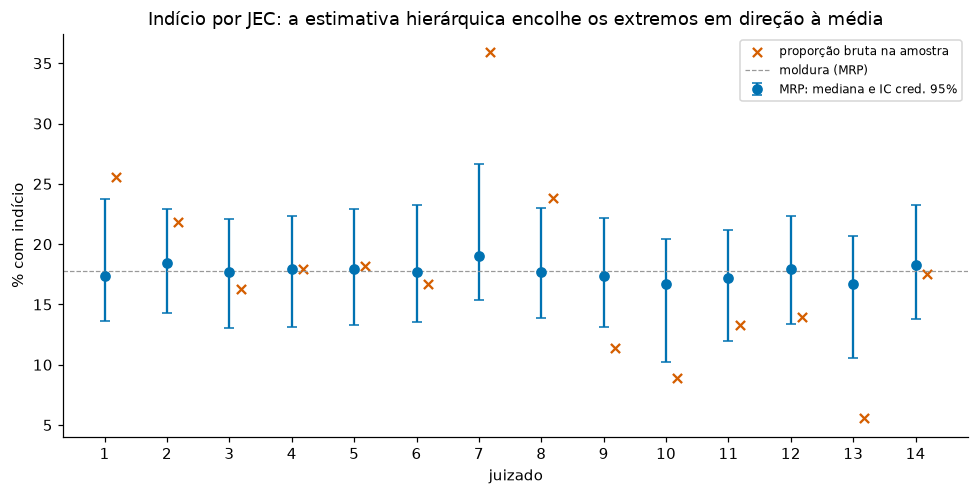


**Leitura (R19 com a informação de toda a moldura).**

- **Prevalência de indício.** O MRP estima **17,74%** (IC cred. 95% [15,46; 20,17]%). O estimador do desenho dá 17,65% [14,80; 20,91]%, e o pós-estratificado por assunto, 17,10% [14,78; 19,43]%. As três estimativas concordam. A amplitude do intervalo cai de 6,1 p.p. (desenho) para 4,7 p.p. (pós-estratificação) e 4,7 p.p. (MRP). O ganho vem de usar o assunto, conhecido para os 50.320 processos: o 6226 corresponde a 17,1% da moldura (8.614 processos).
- **Total na moldura.** O MRP estima **8.926** processos com indício (IC cred. 95% [7.777; 10.149]), contra 8.881 [7.452; 10.516] pelo desenho. Para a certeza: 5,28% [3,78; 7,11]%, ou 2.654 processos [1.901; 3.578] (desenho: 2.538 [1.794; 3.569]). É a resposta, com incerteza explícita, aos "cerca de 8.880" e "2.537" citados no roteiro.
- **Pergunta R19.** A mediana do MRP fica **dentro** do intervalo publicado; 98,8% da distribuição a posteriori está dentro dele.
- **Assunto.** A prevalência de indício é **67,5%** [58,5; 75,8]% no assunto 6226 e 7,4% [5,5; 9,8]% nos demais. A heterogeneidade entre assuntos é grande (σ_assunto = 1,61 [1,07; 2,42] na escala logito). A heterogeneidade entre juizados é pequena (σ_JEC = 0,20 [0,01; 0,61]). Foram observados 62 dos 251 códigos de assunto da moldura; os demais entram com o efeito sorteado do grupo.
- **Juizados.** As proporções brutas por JEC variam de 5,6% a 35,9%. As estimativas hierárquicas variam só de 16,7% a 19,0%, porque parte da variação bruta é ruído de amostras de 33 a 55 processos e parte vem da composição por assunto. No 7º JEC, a proporção bruta é 35,9%, e a estimativa hierárquica é 19,0% [15,4; 26,6]%, com P(acima da moldura) = 0,77. Isso confirma, com outro método, a leitura da Seção 5.3: não há evidência de um juizado diferente.
- **Comparação com os 30% da NT CIJMG.** A nota técnica fala do fluxo de **dois assuntos**. Para a moldura inteira, P(θ ≥ 0,30 | dados) = 0,0%; dentro do assunto 6226, P(θ ≥ 0,30 | dados) = 100,0%. A conclusão da Seção 6.3 ("os dados contradizem 30%") vale para a moldura, e não para um assunto de alta incidência. Se os assuntos da NT forem comparáveis ao 6226, ela se inverte.
- **Diagnósticos.** R-hat máximo 1,000, ESS mínimo 1.556 e nenhuma divergência.

**Limites.** O modelo reproduz a regra de codificação da pesquisa, e não um diagnóstico jurídico independente (Seção 33). O assunto vem da moldura do TJRN, na data da extração. Os efeitos aditivos supõem que a diferença entre assuntos seja parecida em todos os juizados.


In [109]:
# 31.2 Assunto 6226, juizados com agrupamento parcial e heterogeneidade
_p6 = MRP_IND['assunto']['6226']
_po = MRP_IND['assunto']['outros']
TAB_ASSUNTO_MRP = pd.DataFrame([BY.resumo(_p6, 'prevalência de indício no assunto 6226'),
                                BY.resumo(_po, 'prevalência de indício nos demais assuntos'),
                                BY.resumo(MRP_IND['sigma_assunto'], 'σ_assunto (logito)'),
                                BY.resumo(MRP_IND['sigma_jec'], 'σ_JEC (logito)')])
display(tabela_ptbr(TAB_ASSUNTO_MRP, casas=3))

_prev = MRP_IND['prevalencia']
_lin_j = []
for _j, _d in MRP_IND['jec'].items():
    _r = BY.resumo(_d)
    _bruta = am.loc[am.jec == _j, 'indicio'].astype(float)
    _lin_j.append({'JEC': int(_j), 'n na amostra': int(len(_bruta)), 'proporção bruta': float(_bruta.mean()),
                   'MRP mediana': _r['mediana'], 'MRP inf.': _r['IC cred. inf.'], 'MRP sup.': _r['IC cred. sup.'],
                   'P(acima da moldura)': float((_d > _prev).mean())})
TAB_JEC_MRP = pd.DataFrame(_lin_j)
display(tabela_ptbr(TAB_JEC_MRP, casas=3, pct=['proporção bruta', 'MRP mediana', 'MRP inf.', 'MRP sup.']))

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.errorbar(TAB_JEC_MRP.JEC, 100 * TAB_JEC_MRP['MRP mediana'],
            yerr=[100 * (TAB_JEC_MRP['MRP mediana'] - TAB_JEC_MRP['MRP inf.']),
                  100 * (TAB_JEC_MRP['MRP sup.'] - TAB_JEC_MRP['MRP mediana'])],
            fmt='o', color='#0072B2', capsize=3, label='MRP: mediana e IC cred. 95%')
ax.scatter(TAB_JEC_MRP.JEC + 0.18, 100 * TAB_JEC_MRP['proporção bruta'], marker='x', color='#D55E00',
           label='proporção bruta na amostra')
ax.axhline(100 * np.median(_prev), color='#999', ls='--', lw=0.8, label='moldura (MRP)')
ax.set(xticks=TAB_JEC_MRP.JEC, xlabel='juizado', ylabel='% com indício',
       title='Indício por JEC: a estimativa hierárquica encolhe os extremos em direção à média')
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIGURAS / 'mrp_indicio_por_jec.png', dpi=150); plt.show()

_ri, _rc = BY.resumo(MRP_IND['prevalencia']), BY.resumo(MRP_CER['prevalencia'])
_j7 = TAB_JEC_MRP.set_index('JEC').loc[7]
_amp = TAB_MRP.set_index(['resposta', 'método'])['amplitude (p.p.)']
_ic_pub = IC_REF['indício']['publicado (Wald + FPC, N = 83.139)']
V.update(mrp_ind=fpct(_ri['mediana']), mrp_ind_ic=fic(_ri['IC cred. inf.'], _ri['IC cred. sup.'], pct=True),
         mrp_cer=fpct(_rc['mediana']), mrp_cer_ic=fic(_rc['IC cred. inf.'], _rc['IC cred. sup.'], pct=True),
         mrp_tot=fint(round(_tot_i['mediana'])), mrp_tot_ic=fic(_tot_i['IC cred. inf.'], _tot_i['IC cred. sup.'], casas=0),
         mrp_tot_c=fint(round(_tot_c['mediana'])), mrp_tot_c_ic=fic(_tot_c['IC cred. inf.'], _tot_c['IC cred. sup.'], casas=0),
         des_tot=fint(round(est_ind['total'])), des_tot_ic=fic(*est_ind['total_ic'], casas=0),
         des_tot_c=fint(round(est_cer['total'])), des_tot_c_ic=fic(*est_cer['total_ic'], casas=0),
         ps_ind=fpct(PS_IND['p']), ps_ind_ic=fic(*PS_IND['ic'], pct=True),
         ps_cer=fpct(PS_CER['p']), ps_cer_ic=fic(*PS_CER['ic'], pct=True),
         des_ic_logit=fic(*intervalo_logit_desenho(est_ind['p_st'], est_ind['ep']), pct=True),
         amp_des=fnum(_amp[('indício', 'desenho: estratificado por ano (logito)')], 1),
         amp_ps=fnum(_amp[('indício', 'desenho: pós-estratificado por assunto (6226 × demais)')], 1),
         amp_mrp=fnum(_amp[('indício', 'bayesiano: MRP (ano + JEC + assunto)')], 1),
         mrp_6226=fpct(np.median(_p6), 1), mrp_6226_ic=fic(*np.quantile(_p6, [.025, .975]), pct=True, casas=1),
         mrp_outros=fpct(np.median(_po), 1), mrp_outros_ic=fic(*np.quantile(_po, [.025, .975]), pct=True, casas=1),
         mrp_p6226_30=fpct((_p6 >= 0.30).mean(), 1), mrp_pind_30=fpct((MRP_IND['prevalencia'] >= 0.30).mean(), 1),
         mrp_sig_j=fnum(np.median(MRP_IND['sigma_jec']), 2),
         mrp_sig_j_ic=fic(*np.quantile(MRP_IND['sigma_jec'], [.025, .975]), casas=2),
         mrp_sig_a=fnum(np.median(MRP_IND['sigma_assunto']), 2),
         mrp_sig_a_ic=fic(*np.quantile(MRP_IND['sigma_assunto'], [.025, .975]), casas=2),
         mrp_j7_bruta=fpct(_j7['proporção bruta'], 1), mrp_j7=fpct(_j7['MRP mediana'], 1),
         mrp_j7_ic=fic(_j7['MRP inf.'], _j7['MRP sup.'], pct=True, casas=1), mrp_j7_p=fnum(_j7['P(acima da moldura)'], 2),
         mrp_jec_min=fpct(TAB_JEC_MRP['MRP mediana'].min(), 1), mrp_jec_max=fpct(TAB_JEC_MRP['MRP mediana'].max(), 1),
         mrp_jec_bmin=fpct(TAB_JEC_MRP['proporção bruta'].min(), 1), mrp_jec_bmax=fpct(TAB_JEC_MRP['proporção bruta'].max(), 1),
         mrp_rhat=fnum(max(MRP_IND['diagnosticos']['R-hat máximo'], MRP_CER['diagnosticos']['R-hat máximo']), 3),
         mrp_ess=fint(min(MRP_IND['diagnosticos']['ESS bulk mínimo'], MRP_CER['diagnosticos']['ESS bulk mínimo'])),
         mrp_assuntos_am=fint(MRP_IND['assuntos_na_amostra']), mrp_assuntos_mo=fint(MRP_IND['assuntos_na_moldura']),
         mrp_dentro_pub='dentro' if _ic_pub[0] <= _ri['mediana'] <= _ic_pub[1] else 'fora',
         mrp_p_pub=fpct(((MRP_IND['prevalencia'] >= _ic_pub[0]) & (MRP_IND['prevalencia'] <= _ic_pub[1])).mean(), 1),
         n_6226_mold=fint(_N_grupo['6226']), p_6226_mold=fpct(_N_grupo['6226'] / _N_mold, 1))
display(Markdown(C.preencher(r'''
**Leitura (R19 com a informação de toda a moldura).**

- **Prevalência de indício.** O MRP estima **{{mrp_ind}}** (IC cred. 95% {{mrp_ind_ic}}). O estimador do desenho dá {{p_indicio}} {{des_ic_logit}}, e o pós-estratificado por assunto, {{ps_ind}} {{ps_ind_ic}}. As três estimativas concordam. A amplitude do intervalo cai de {{amp_des}} p.p. (desenho) para {{amp_ps}} p.p. (pós-estratificação) e {{amp_mrp}} p.p. (MRP). O ganho vem de usar o assunto, conhecido para os 50.320 processos: o 6226 corresponde a {{p_6226_mold}} da moldura ({{n_6226_mold}} processos).
- **Total na moldura.** O MRP estima **{{mrp_tot}}** processos com indício (IC cred. 95% {{mrp_tot_ic}}), contra {{des_tot}} {{des_tot_ic}} pelo desenho. Para a certeza: {{mrp_cer}} {{mrp_cer_ic}}, ou {{mrp_tot_c}} processos {{mrp_tot_c_ic}} (desenho: {{des_tot_c}} {{des_tot_c_ic}}). É a resposta, com incerteza explícita, aos "cerca de 8.880" e "2.537" citados no roteiro.
- **Pergunta R19.** A mediana do MRP fica **{{mrp_dentro_pub}}** do intervalo publicado; {{mrp_p_pub}} da distribuição a posteriori está dentro dele.
- **Assunto.** A prevalência de indício é **{{mrp_6226}}** {{mrp_6226_ic}} no assunto 6226 e {{mrp_outros}} {{mrp_outros_ic}} nos demais. A heterogeneidade entre assuntos é grande (σ_assunto = {{mrp_sig_a}} {{mrp_sig_a_ic}} na escala logito). A heterogeneidade entre juizados é pequena (σ_JEC = {{mrp_sig_j}} {{mrp_sig_j_ic}}). Foram observados {{mrp_assuntos_am}} dos {{mrp_assuntos_mo}} códigos de assunto da moldura; os demais entram com o efeito sorteado do grupo.
- **Juizados.** As proporções brutas por JEC variam de {{mrp_jec_bmin}} a {{mrp_jec_bmax}}. As estimativas hierárquicas variam só de {{mrp_jec_min}} a {{mrp_jec_max}}, porque parte da variação bruta é ruído de amostras de 33 a 55 processos e parte vem da composição por assunto. No 7º JEC, a proporção bruta é {{mrp_j7_bruta}}, e a estimativa hierárquica é {{mrp_j7}} {{mrp_j7_ic}}, com P(acima da moldura) = {{mrp_j7_p}}. Isso confirma, com outro método, a leitura da Seção 5.3: não há evidência de um juizado diferente.
- **Comparação com os 30% da NT CIJMG.** A nota técnica fala do fluxo de **dois assuntos**. Para a moldura inteira, P(θ ≥ 0,30 | dados) = {{mrp_pind_30}}; dentro do assunto 6226, P(θ ≥ 0,30 | dados) = {{mrp_p6226_30}}. A conclusão da Seção 6.3 ("os dados contradizem 30%") vale para a moldura, e não para um assunto de alta incidência. Se os assuntos da NT forem comparáveis ao 6226, ela se inverte.
- **Diagnósticos.** R-hat máximo {{mrp_rhat}}, ESS mínimo {{mrp_ess}} e nenhuma divergência.

**Limites.** O modelo reproduz a regra de codificação da pesquisa, e não um diagnóstico jurídico independente (Seção 33). O assunto vem da moldura do TJRN, na data da extração. Os efeitos aditivos supõem que a diferença entre assuntos seja parecida em todos os juizados.
''', V)))

## 32. Bayes por processo com as verossimilhanças estimadas

Na Seção 6, P(D | Hₐ) e P(D | H₀) entraram como números exatos, embora sejam proporções estimadas em 105 e 488 processos. Aqui elas recebem uma distribuição a posteriori. Os quatro desfechos são modelados **em conjunto**, com uma Dirichlet(1, 1, 1, 1) por hipótese, porque somam um dentro de cada hipótese e não são quatro evidências independentes. A priori P(Hₐ) também ganha incerteza: Beta(6, 14), média 0,30 com o peso de 20 processos, como na decisão D1, e Beta(1, 1) como cenário sem informação. O resultado é uma distribuição para a razão de verossimilhança (RV) e para a posteriori, e não um número só.

A segunda parte compara o desfecho com outra evidência disponível no ajuizamento: o **assunto 6226**. Para não usar os mesmos processos duas vezes, as verossimilhanças e a priori são estimadas em **2022–2023**, e a posteriori resultante é confrontada com os processos de **2024**, como teste preditivo.

In [110]:
# 32.1 RV e posteriori com incerteza (Dirichlet-multinomial × Beta)
_ordem_d = ['acordo', 'mérito', 'extinção sem mérito', 'sem sentença registrada']
_cA = bay.loc[bay.Ha, 'desfecho'].astype(str).value_counts().reindex(_ordem_d, fill_value=0)
_c0 = bay.loc[~bay.Ha, 'desfecho'].astype(str).value_counts().reindex(_ordem_d, fill_value=0)
BP = pd.concat({nome: BY.bayes_processo(_cA, _c0, pri, seed=SEMENTE_BAYES + 20 + i)
                for i, (nome, pri) in enumerate([('Beta(6, 14): cenário CIJMG', (6, 14)),
                                                 ('Beta(1, 1): sem informação', (1, 1))])}, names=['priori P(Hₐ)'])
display(tabela_ptbr(BP.reset_index(level=0), casas=3))

# 32.2 Assunto 6226: verossimilhanças e priori de 2022–2023, previsão para 2024
_tr_b = _am_b.ano < 2024
_te_b = ~_tr_b
_Ha_b = _am_b.indicio == 1
_s6_b = _am_b.assunto.eq('6226')
BA = BY.bayes_assunto_temporal(int((_s6_b & _Ha_b & _tr_b).sum()), int((_Ha_b & _tr_b).sum()),
                               int((_s6_b & ~_Ha_b & _tr_b).sum()), int((~_Ha_b & _tr_b).sum()),
                               (1 + int((_Ha_b & _tr_b).sum()), 1 + int((~_Ha_b & _tr_b).sum())),
                               seed=SEMENTE_BAYES + 30)
_rng_pp = np.random.default_rng(SEMENTE_BAYES + 31)
_lin_a = []
for _nome, _mask, _post in [('assunto 6226', _s6_b, BA['post_6226']), ('demais assuntos', ~_s6_b, BA['post_outros'])]:
    _n24 = int((_mask & _te_b).sum())
    _k24 = int((_mask & _te_b & _Ha_b).sum())
    _pred = _rng_pp.binomial(_n24, _post)
    _lin_a.append({'grupo em 2024': _nome, 'processos': _n24, 'indícios observados': _k24,
                   'P(Hₐ | grupo) prevista': float(np.median(_post)),
                   'prevista inf.': float(np.quantile(_post, .025)), 'prevista sup.': float(np.quantile(_post, .975)),
                   'contagem prevista inf.': int(np.quantile(_pred, .025)),
                   'contagem prevista sup.': int(np.quantile(_pred, .975)),
                   'observado no intervalo preditivo': bool(np.quantile(_pred, .025) <= _k24 <= np.quantile(_pred, .975))})
TAB_ASSUNTO_PRED = pd.DataFrame(_lin_a)
display(tabela_ptbr(TAB_ASSUNTO_PRED, casas=3))
assert TAB_ASSUNTO_PRED['observado no intervalo preditivo'].all()

_bp = BP.loc['Beta(6, 14): cenário CIJMG'].set_index('dado')
_rv6 = BY.resumo(BA['RV_6226'])
_rvo = BY.resumo(BA['RV_outros'])
_ta = TAB_ASSUNTO_PRED.set_index('grupo em 2024')
V.update(bp_rv_ext=fnum(_bp.loc['extinção sem mérito', 'RV mediana'], 2),
         bp_rv_ext_ic=fic(_bp.loc['extinção sem mérito', 'RV inf.'], _bp.loc['extinção sem mérito', 'RV sup.']),
         bp_p_ext=fnum(_bp.loc['extinção sem mérito', 'P(RV > 1)'], 2),
         bp_post_ext=fnum(_bp.loc['extinção sem mérito', 'posteriori mediana'], 2),
         bp_post_ext_ic=fic(_bp.loc['extinção sem mérito', 'posteriori inf.'], _bp.loc['extinção sem mérito', 'posteriori sup.']),
         bp_rv_aco=fnum(_bp.loc['acordo', 'RV mediana'], 2),
         bp_rv_aco_ic=fic(_bp.loc['acordo', 'RV inf.'], _bp.loc['acordo', 'RV sup.']),
         bp_p_aco=fnum(_bp.loc['acordo', 'P(RV > 1)'], 2),
         rv6=fnum(_rv6['mediana'], 1), rv6_ic=fic(_rv6['IC cred. inf.'], _rv6['IC cred. sup.'], casas=1),
         rvo=fnum(_rvo['mediana'], 2), rvo_ic=fic(_rvo['IC cred. inf.'], _rvo['IC cred. sup.']),
         pred6=fpct(_ta.loc['assunto 6226', 'P(Hₐ | grupo) prevista'], 1),
         pred6_ic=fic(_ta.loc['assunto 6226', 'prevista inf.'], _ta.loc['assunto 6226', 'prevista sup.'], pct=True, casas=1),
         obs6=f"{fint(_ta.loc['assunto 6226', 'indícios observados'])}/{fint(_ta.loc['assunto 6226', 'processos'])}",
         predo=fpct(_ta.loc['demais assuntos', 'P(Hₐ | grupo) prevista'], 1),
         predo_ic=fic(_ta.loc['demais assuntos', 'prevista inf.'], _ta.loc['demais assuntos', 'prevista sup.'], pct=True, casas=1),
         obso=f"{fint(_ta.loc['demais assuntos', 'indícios observados'])}/{fint(_ta.loc['demais assuntos', 'processos'])}")
display(Markdown(C.preencher(r'''
**Leitura (R6–R8 com incerteza).**

- **O desfecho continua sendo evidência fraca.** A extinção sem mérito tem RV {{bp_rv_ext}} (IC cred. 95% {{bp_rv_ext_ic}}), com P(RV > 1) = {{bp_p_ext}}. Com a priori Beta(6, 14), a posteriori P(Hₐ | extinção) tem mediana {{bp_post_ext}}, mas o intervalo {{bp_post_ext_ic}} é quase tão largo quanto a própria priori. O acordo tem RV {{bp_rv_aco}} {{bp_rv_aco_ic}} (P(RV > 1) = {{bp_p_aco}}). A Seção 6 dava a mesma direção, mas um número exato; aqui fica visível que **a incerteza da priori domina** e que o desfecho mal a reduz.
- **O assunto é evidência forte.** Estimada em 2022–2023, a RV do assunto 6226 é **{{rv6}}** {{rv6_ic}}, e a dos demais assuntos, {{rvo}} {{rvo_ic}}. É a diferença entre uma evidência que move a crença uma ordem de grandeza e uma que quase não a move.
- **Teste preditivo em 2024.** Com a priori e as verossimilhanças de 2022–2023, a posteriori prevista para 2024 é {{pred6}} {{pred6_ic}} no 6226, e o observado foi {{obs6}}. Nos demais assuntos, a previsão é {{predo}} {{predo_ic}}, e o observado foi {{obso}}. As duas contagens caem dentro do intervalo preditivo: a atualização bayesiana feita com um período **prevê** o período seguinte.

**Cautela.** A RV do assunto mede quanto o assunto reproduz o **rótulo** da pesquisa. Se F3_19 e F3_20 foram avaliados olhando a massa de ações do mesmo assunto, parte da força dessa evidência é da própria regra de codificação (Seção 33). Isso não a torna inútil para triagem, mas a impede de ser lida como prova de predação de um processo individual.
''', V)))

,priori P(Hₐ),dado,RV mediana,RV inf.,RV sup.,P(RV > 1),priori P(Hₐ) mediana,posteriori mediana,posteriori inf.,posteriori sup.
0,"Beta(6, 14): cenário CIJMG",acordo,"0,593","0,263","1,142","0,063","0,294","0,195","0,061","0,437"
1,"Beta(6, 14): cenário CIJMG",mérito,"0,952","0,797","1,110","0,277","0,294","0,283","0,119","0,502"
2,"Beta(6, 14): cenário CIJMG",extinção sem mérito,"1,286","0,906","1,774","0,923","0,294","0,347","0,150","0,587"
3,"Beta(6, 14): cenário CIJMG",sem sentença registrada,"1,571","0,329","5,518","0,739","0,294","0,391","0,091","0,758"
0,"Beta(1, 1): sem informação",acordo,"0,594","0,263","1,139","0,062","0,501","0,368","0,014","0,961"
1,"Beta(1, 1): sem informação",mérito,"0,953","0,797","1,113","0,280","0,501","0,488","0,024","0,974"
2,"Beta(1, 1): sem informação",extinção sem mérito,"1,284","0,899","1,760","0,921","0,501","0,563","0,032","0,980"
3,"Beta(1, 1): sem informação",sem sentença registrada,"1,588","0,326","5,560","0,736","0,501","0,603","0,030","0,986"


,grupo em 2024,processos,indícios observados,P(Hₐ | grupo) prevista,prevista inf.,prevista sup.,contagem prevista inf.,contagem prevista sup.,observado no intervalo preditivo
0,assunto 6226,26,17,"0,699","0,595","0,791",13,23,True
1,demais assuntos,164,11,"0,063","0,040","0,093",4,19,True



**Leitura (R6–R8 com incerteza).**

- **O desfecho continua sendo evidência fraca.** A extinção sem mérito tem RV 1,29 (IC cred. 95% [0,91; 1,77]), com P(RV > 1) = 0,92. Com a priori Beta(6, 14), a posteriori P(Hₐ | extinção) tem mediana 0,35, mas o intervalo [0,15; 0,59] é quase tão largo quanto a própria priori. O acordo tem RV 0,59 [0,26; 1,14] (P(RV > 1) = 0,06). A Seção 6 dava a mesma direção, mas um número exato; aqui fica visível que **a incerteza da priori domina** e que o desfecho mal a reduz.
- **O assunto é evidência forte.** Estimada em 2022–2023, a RV do assunto 6226 é **9,8** [6,7; 15,0], e a dos demais assuntos, 0,29 [0,19; 0,40]. É a diferença entre uma evidência que move a crença uma ordem de grandeza e uma que quase não a move.
- **Teste preditivo em 2024.** Com a priori e as verossimilhanças de 2022–2023, a posteriori prevista para 2024 é 69,9% [59,5; 79,1]% no 6226, e o observado foi 17/26. Nos demais assuntos, a previsão é 6,3% [4,0; 9,3]%, e o observado foi 11/164. As duas contagens caem dentro do intervalo preditivo: a atualização bayesiana feita com um período **prevê** o período seguinte.

**Cautela.** A RV do assunto mede quanto o assunto reproduz o **rótulo** da pesquisa. Se F3_19 e F3_20 foram avaliados olhando a massa de ações do mesmo assunto, parte da força dessa evidência é da própria regra de codificação (Seção 33). Isso não a torna inútil para triagem, mas a impede de ser lida como prova de predação de um processo individual.


## 33. A prevalência quando a codificação pode errar

Os rótulos F1–F3 foram atribuídos por uma única codificadora, sem segunda leitura (Seção 2.6). A Seção 19 mostrou o efeito de taxas de erro **fixas** e hipotéticas. Aqui a sensibilidade (Se) e a especificidade (Sp) da codificação recebem prioris, e a prevalência verdadeira π é estimada com toda essa incerteza:

$$P(\text{rótulo} = 1) = \pi\,Se + (1-\pi)(1-Sp).$$

Sem processos recodificados, os dados **não identificam** Se e Sp: a posteriori delas é igual à priori, e a de π herda essa incerteza (GUSTAFSON, 2015; JOSEPH; GYORKOS; COUPAL, 1995). Por isso a seção compara cenários, e não escolhe um. Os cenários são declarados abaixo, com a média e a dispersão de cada priori. A conta usa o binomial dos 595, porque a amostra é autoponderada. A correção de população finita (fração amostral de 1,2%) é desprezível.

In [111]:
# 33.1 Prevalência com Se e Sp incertas (amostragem-reamostragem por importância)
CENARIOS_ERRO = {
    'codificação perfeita (Se = Sp = 1)': None,
    'Seção 19 com incerteza: Se ~ Beta(45, 5), Sp ~ Beta(99, 1)': ((45, 5), (99, 1)),
    'codificadora mais sensível que específica: Se ~ Beta(98, 2), Sp ~ Beta(48, 2)': ((98, 2), (48, 2)),
    'erro maior nos dois sentidos: Se ~ Beta(16, 4), Sp ~ Beta(97, 3)': ((16, 4), (97, 3)),
}
_k, _n = funil['indicio'], funil['n']
_lin_e = []
for _i, (_nome, _pri) in enumerate(CENARIOS_ERRO.items()):
    if _pri is None:
        _pi = stats.beta(1 + _k, 1 + _n - _k).rvs(40_000, random_state=SEMENTE_BAYES + 40)
        _se_m = _sp_m = 1.0
        _ess = np.nan
    else:
        _e = BY.prevalencia_com_erro(_k, _n, _pri[0], _pri[1], seed=SEMENTE_BAYES + 41 + _i)
        _pi, _se_m, _sp_m, _ess = _e['pi'], float(_e['se'].mean()), float(_e['sp'].mean()), _e['ess_importancia']
    _r = BY.resumo(_pi)
    _lin_e.append({'cenário': _nome, 'Se média (posteriori)': _se_m, 'Sp média (posteriori)': _sp_m,
                   'π mediana': _r['mediana'], 'π inf.': _r['IC cred. inf.'], 'π sup.': _r['IC cred. sup.'],
                   'total na moldura (mediana)': _r['mediana'] * len(base), 'ESS da importância': _ess})
TAB_ERRO = pd.DataFrame(_lin_e)
display(tabela_ptbr(TAB_ERRO, casas=3, pct=['π mediana', 'π inf.', 'π sup.']))
_te = TAB_ERRO.set_index('cenário')
V.update(err_min=fpct(TAB_ERRO['π mediana'].min(), 1), err_max=fpct(TAB_ERRO['π mediana'].max(), 1),
         err_lo=fpct(TAB_ERRO['π inf.'].min(), 1), err_hi=fpct(TAB_ERRO['π sup.'].max(), 1),
         err_s19=fpct(_te.iloc[1]['π mediana'], 1), err_s19_ic=fic(_te.iloc[1]['π inf.'], _te.iloc[1]['π sup.'], pct=True, casas=1),
         err_esp=fpct(_te.iloc[2]['π mediana'], 1), err_esp_ic=fic(_te.iloc[2]['π inf.'], _te.iloc[2]['π sup.'], pct=True, casas=1))
display(Markdown(C.preencher(r'''
**Leitura.** Com codificação perfeita, a prevalência é {{p_indicio}}. No cenário da Seção 19, agora com incerteza, a mediana sobe para {{err_s19}} {{err_s19_ic}}: falsos negativos raros, mas possíveis, escondem predação. Se a codificadora marcasse indício com facilidade (Sp baixa), a mediana cairia para {{err_esp}} {{err_esp_ic}}. Entre os cenários, as medianas vão de {{err_min}} a {{err_max}}, e os intervalos, de {{err_lo}} a {{err_hi}}.

**Consequência.** A incerteza de medição pode ser **maior que a amostral**: o intervalo de Wilson ou do desenho supõe Se = Sp = 1. Sem uma subamostra recodificada, nenhum desses cenários pode ser preferido pelos dados. Se houver ocasião, uma segunda leitura independente de algumas dezenas de processos (com κ e uma tabela de concordância) informaria as prioris de Se e Sp e reduziria esse intervalo. Os modelos das Seções 31 e 32 também reproduzem o rótulo **tal como codificado**.
''', V)))

,cenário,Se média (posteriori),Sp média (posteriori),π mediana,π inf.,π sup.,total na moldura (mediana),ESS da importância
0,codificação perfeita (Se = Sp = 1),"1,000","1,000","17,716%","14,829%","20,924%","8.914,782",—
1,"Seção 19 com incerteza: Se ~ Beta(45, 5), Sp ~...","0,897","0,990","18,866%","14,678%","23,383%","9.493,262","24.908,862"
2,codificadora mais sensível que específica: Se ...,"0,980","0,960","14,955%","7,167%","19,521%","7.525,248","23.738,359"
3,"erro maior nos dois sentidos: Se ~ Beta(16, 4)...","0,789","0,970","19,355%","12,920%","28,361%","9.739,378","28.924,212"



**Leitura.** Com codificação perfeita, a prevalência é 17,65%. No cenário da Seção 19, agora com incerteza, a mediana sobe para 18,9% [14,7; 23,4]%: falsos negativos raros, mas possíveis, escondem predação. Se a codificadora marcasse indício com facilidade (Sp baixa), a mediana cairia para 15,0% [7,2; 19,5]%. Entre os cenários, as medianas vão de 15,0% a 19,4%, e os intervalos, de 7,2% a 28,4%.

**Consequência.** A incerteza de medição pode ser **maior que a amostral**: o intervalo de Wilson ou do desenho supõe Se = Sp = 1. Sem uma subamostra recodificada, nenhum desses cenários pode ser preferido pelos dados. Se houver ocasião, uma segunda leitura independente de algumas dezenas de processos (com κ e uma tabela de concordância) informaria as prioris de Se e Sp e reduziria esse intervalo. Os modelos das Seções 31 e 32 também reproduzem o rótulo **tal como codificado**.


## 34. Logística bayesiana para a quase separação

Na Seção 8, F2_01 e F2_02 andam juntas (φ = 0,97). Com isso, a máxima verossimilhança dá intervalos enormes e, no passo da certeza (30 eventos em 105), erros-padrão indefinidos. O Firth resolve parte do problema com uma penalização. A alternativa bayesiana é declarar que efeitos gigantescos são **improváveis a priori**. Aqui, cada coeficiente recebe uma t de Student com 3 graus de liberdade e escala 2,5, com os preditores centrados (GELMAN et al., 2008). Essa priori ainda admite ORs de 100 ou mais, mas não infinitos.

A comparação entre modelos usa a validação cruzada aproximada por LOO-PSIS (VEHTARI; GELMAN; GABRY, 2017), que estima o desempenho preditivo fora da amostra. O elpd é a log-densidade preditiva esperada: maior é melhor, e uma diferença menor que cerca de dois erros-padrão é empate prático.

In [112]:
# 34.1 Passo 1 (indício | Fase III) e passo 2 (certeza | indício), com LOO
import arviz as az
_X1 = d233[X_HADJA].astype(int)
_d_ind = d233[sub]
_y2 = (y3[sub] == 2).astype(int)
with C.capturar_avisos('logística bayesiana (PyMC)', AVISOS):
    LB1 = BY.logistica_bayes(_X1, y_ind, seed=SEMENTE_BAYES + 50)
    LB1_sem01 = BY.logistica_bayes(d233[['F2_02', 'F2_11']].astype(int), y_ind, seed=SEMENTE_BAYES + 51)
    LB1_nulo = BY.logistica_bayes(d233[[]], y_ind, seed=SEMENTE_BAYES + 52)
    LB2 = BY.logistica_bayes(_d_ind[X_HADJA].astype(int), _y2, seed=SEMENTE_BAYES + 53)
    LB2_nulo = BY.logistica_bayes(_d_ind[[]], _y2, seed=SEMENTE_BAYES + 54)
    LOO1 = az.compare({'F2_01 + F2_02 + F2_11': LB1['idata'], 'F2_02 + F2_11': LB1_sem01['idata'],
                       'só intercepto': LB1_nulo['idata']}, ic='loo')
    LOO2 = az.compare({'F2_01 + F2_02 + F2_11': LB2['idata'], 'só intercepto': LB2_nulo['idata']}, ic='loo')
for _m in (LB1, LB1_sem01, LB1_nulo, LB2, LB2_nulo):
    assert _m['diagnosticos']['R-hat máximo'] < 1.01 and _m['diagnosticos']['divergências'] == 0

_mle = pd.DataFrame({'termo': X_HADJA, 'OR (MV)': np.exp(MOD_HADJA.params[X_HADJA]).to_numpy(),
                     'IC MV inf.': np.exp(MOD_HADJA.conf_int().loc[X_HADJA, 0]).to_numpy(),
                     'IC MV sup.': np.exp(MOD_HADJA.conf_int().loc[X_HADJA, 1]).to_numpy(),
                     'OR (Firth)': FIRTH_H.loc[X_HADJA, 'OR'].to_numpy(),
                     'IC Firth inf.': FIRTH_H.loc[X_HADJA, 'ic_lo'].to_numpy(),
                     'IC Firth sup.': FIRTH_H.loc[X_HADJA, 'ic_hi'].to_numpy()})
TAB_LB1 = _mle.merge(LB1['tabela'], on='termo')
display(tabela_ptbr(TAB_LB1, casas=2))
display(tabela_ptbr(LB2['tabela'], casas=2))
display(LOO1[['rank', 'elpd_loo', 'p_loo', 'elpd_diff', 'dse', 'weight']].round(2))
display(LOO2[['rank', 'elpd_loo', 'p_loo', 'elpd_diff', 'dse', 'weight']].round(2))

# probabilidade a posteriori por padrão de sinais e o funil completo P(certeza) = P(indício) × P(certeza | indício)
_pads = pad[X_HADJA + ['n', 'indicios']].copy()
_p1 = BY.prob_padroes(LB1, _pads[X_HADJA])
_p2 = BY.prob_padroes(LB2, _pads[X_HADJA])
_pads['observado'] = _pads.indicios / _pads.n
_pads['P(indício) mediana'] = np.median(_p1, 0)
_pads['P(indício) inf.'] = np.quantile(_p1, .025, 0)
_pads['P(indício) sup.'] = np.quantile(_p1, .975, 0)
_pads['P(certeza) mediana'] = np.median(_p1 * _p2, 0)
_pads['P(certeza) inf.'] = np.quantile(_p1 * _p2, .025, 0)
_pads['P(certeza) sup.'] = np.quantile(_p1 * _p2, .975, 0)
display(tabela_ptbr(_pads, casas=3))

_lb = LB1['tabela'].set_index('termo')
_lb2 = LB2['tabela'].set_index('termo')
_tl = TAB_LB1.set_index('termo')
_pc = _pads.set_index(X_HADJA)
V.update(lb_or02=fnum(_lb.loc['F2_02', 'OR mediana'], 1), lb_or02_ic=fic(_lb.loc['F2_02', 'OR inf.'], _lb.loc['F2_02', 'OR sup.'], 1),
         lb_or01=fnum(_lb.loc['F2_01', 'OR mediana'], 2), lb_or01_ic=fic(_lb.loc['F2_01', 'OR inf.'], _lb.loc['F2_01', 'OR sup.'], 2),
         lb_or11=fnum(_lb.loc['F2_11', 'OR mediana'], 2), lb_or11_ic=fic(_lb.loc['F2_11', 'OR inf.'], _lb.loc['F2_11', 'OR sup.'], 2),
         lb_mv02_ic=fic(_tl.loc['F2_02', 'IC MV inf.'], _tl.loc['F2_02', 'IC MV sup.'], 1),
         lb2_or02=fnum(_lb2.loc['F2_02', 'OR mediana'], 2), lb2_or02_ic=fic(_lb2.loc['F2_02', 'OR inf.'], _lb2.loc['F2_02', 'OR sup.'], 2),
         lb2_or11=fnum(_lb2.loc['F2_11', 'OR mediana'], 2), lb2_or11_ic=fic(_lb2.loc['F2_11', 'OR inf.'], _lb2.loc['F2_11', 'OR sup.'], 2),
         lb2_p02=fnum(_lb2.loc['F2_02', 'P(β > 0)'], 2),
         loo1_melhor=LOO1.index[0], loo1_dif01=fnum(LOO1.loc['F2_01 + F2_02 + F2_11', 'elpd_diff'], 2),
         loo1_dse01=fnum(LOO1.loc['F2_01 + F2_02 + F2_11', 'dse'], 2),
         loo1_difnulo=fnum(LOO1.loc['só intercepto', 'elpd_diff'], 1), loo1_dsenulo=fnum(LOO1.loc['só intercepto', 'dse'], 1),
         loo2_melhor=LOO2.index[0], loo2_dif=fnum(LOO2['elpd_diff'].max(), 2), loo2_dse=fnum(LOO2['dse'].max(), 2),
         pc111=fpct(_pc.loc[(1, 1, 1), 'P(certeza) mediana'], 1),
         pc111_ic=fic(_pc.loc[(1, 1, 1), 'P(certeza) inf.'], _pc.loc[(1, 1, 1), 'P(certeza) sup.'], pct=True, casas=1),
         pi111=fpct(_pc.loc[(1, 1, 1), 'P(indício) mediana'], 1),
         pi111_ic=fic(_pc.loc[(1, 1, 1), 'P(indício) inf.'], _pc.loc[(1, 1, 1), 'P(indício) sup.'], pct=True, casas=1),
         pi000=fpct(_pc.loc[(0, 0, 0), 'P(indício) mediana'], 1),
         pi000_ic=fic(_pc.loc[(0, 0, 0), 'P(indício) inf.'], _pc.loc[(0, 0, 0), 'P(indício) sup.'], pct=True, casas=1),
         lb_rhat=fnum(max(m['diagnosticos']['R-hat máximo'] for m in (LB1, LB1_sem01, LB1_nulo, LB2, LB2_nulo)), 3))
display(Markdown(C.preencher(r'''
**Leitura (R10–R13 com prioris fracamente informativas).**

- **Passo 1, indício na Fase III.** O OR de F2_02 é {{lb_or02}} (IC cred. 95% {{lb_or02_ic}}), contra o IC de máxima verossimilhança {{lb_mv02_ic}}. A estimativa fica no mesmo lugar, mas o limite superior deixa de ser arbitrário. F2_11: {{lb_or11}} {{lb_or11_ic}}. F2_01: {{lb_or01}} {{lb_or01_ic}}, porque a informação está no par F2_01/F2_02, e não em cada um.
- **LOO no passo 1.** O melhor modelo é "{{loo1_melhor}}". Incluir F2_01 muda o elpd em {{loo1_dif01}} (EP da diferença {{loo1_dse01}}): empate prático. Retirar todos os sinais custa {{loo1_difnulo}} (EP {{loo1_dsenulo}}). Os sinais formais predizem o indício, e F2_01 é redundante dado F2_02.
- **Passo 2, certeza dado indício.** F2_02: OR {{lb2_or02}} {{lb2_or02_ic}}, com P(β > 0) = {{lb2_p02}}; F2_11: {{lb2_or11}} {{lb2_or11_ic}}. Os intervalos são finitos, o que a máxima verossimilhança não dava, e ficam centrados em um. Pelo LOO, o melhor modelo é "{{loo2_melhor}}" (diferença {{loo2_dif}}; EP {{loo2_dse}}). **Os sinais da petição não predizem a certeza**: a conclusão da razão contínua (Seção 8.2) agora tem uma medida preditiva direta.
- **Funil completo.** Com os três sinais presentes, P(indício) = {{pi111}} {{pi111_ic}} e P(certeza) = {{pc111}} {{pc111_ic}}. Sem nenhum sinal, P(indício) = {{pi000}} {{pi000_ic}}.
- **Diagnósticos.** R-hat máximo {{lb_rhat}} e nenhuma divergência nos cinco ajustes.
''', V)))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [intercepto_centrado, beta]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 3 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


... (17 outputs left out)

,rank,elpd_loo,p_loo,elpd_diff,dse,weight
F2_02 + F2_11,0,"-86,1400","2,9500","0,0000","0,0000","0,9900"
F2_01 + F2_02 + F2_11,1,"-87,0700","3,8700","0,9300","0,6800","0,0000"
só intercepto,2,"-161,3900","1,0300","75,2500","9,5600","0,0100"


,rank,elpd_loo,p_loo,elpd_diff,dse,weight
só intercepto,0,"-63,8300","1,0100","0,0000","0,0000","1,0000"
F2_01 + F2_02 + F2_11,1,"-66,3700","3,7000","2,5400","0,7900","0,0000"


,F2_01,F2_02,F2_11,n,indicios,observado,P(indício) mediana,P(indício) inf.,P(indício) sup.,P(certeza) mediana,P(certeza) inf.,P(certeza) sup.
0,0,0,0,89,7,"0,079","0,073","0,035","0,132","0,024","0,008","0,059"
1,0,0,1,45,12,"0,267","0,274","0,170","0,400","0,092","0,037","0,180"
2,0,1,1,1,1,"1,000","0,893","0,519","0,991","0,262","0,026","0,738"
3,1,0,0,1,0,"0,000","0,155","0,017","0,590","0,040","0,002","0,280"
4,1,0,1,2,1,"0,500","0,470","0,077","0,881","0,119","0,009","0,511"
5,1,1,0,44,35,"0,795","0,807","0,688","0,895","0,216","0,115","0,341"
6,1,1,1,51,49,"0,961","0,953","0,898","0,980","0,254","0,153","0,375"



**Leitura (R10–R13 com prioris fracamente informativas).**

- **Passo 1, indício na Fase III.** O OR de F2_02 é 22,1 (IC cred. 95% [3,0; 265,3]), contra o IC de máxima verossimilhança [2,5; 380,7]. A estimativa fica no mesmo lugar, mas o limite superior deixa de ser arbitrário. F2_11: 4,82 [2,16; 11,32]. F2_01: 2,37 [0,22; 18,22], porque a informação está no par F2_01/F2_02, e não em cada um.
- **LOO no passo 1.** O melhor modelo é "F2_02 + F2_11". Incluir F2_01 muda o elpd em 0,93 (EP da diferença 0,68): empate prático. Retirar todos os sinais custa 75,2 (EP 9,6). Os sinais formais predizem o indício, e F2_01 é redundante dado F2_02.
- **Passo 2, certeza dado indício.** F2_02: OR 0,86 [0,07; 10,88], com P(β > 0) = 0,45; F2_11: 0,99 [0,43; 2,40]. Os intervalos são finitos, o que a máxima verossimilhança não dava, e ficam centrados em um. Pelo LOO, o melhor modelo é "só intercepto" (diferença 2,54; EP 0,79). **Os sinais da petição não predizem a certeza**: a conclusão da razão contínua (Seção 8.2) agora tem uma medida preditiva direta.
- **Funil completo.** Com os três sinais presentes, P(indício) = 95,3% [89,8; 98,0]% e P(certeza) = 25,4% [15,3; 37,5]%. Sem nenhum sinal, P(indício) = 7,3% [3,5; 13,2]%.
- **Diagnósticos.** R-hat máximo 1,000 e nenhuma divergência nos cinco ajustes.


## 35. Resposta final ao roteiro

Esta tabela substitui a síntese provisória da Seção 14. Ela reúne os resultados das Partes I a VI. Todos os números são calculados neste notebook.

In [113]:
# 35.1 Consolidação dos números das Partes V e VI para a resposta final
_aval25 = TAB_AVALIACAO_25.set_index('avaliação')
_com28 = TAB_COMBINACAO_28.set_index('informação')
_bench = BENCH.set_index('método')
V.update(fin_auc_ajz=fnum(_aval25.loc['modelo congelado em 2024', 'AUC'], 3),
         fin_ap_ajz=fnum(_aval25.loc['modelo congelado em 2024', 'precisão média'], 3),
         fin_auc_ajz_cv=fnum(_aval25.loc['procedimento completo: CV externa, 2022–2023', 'AUC'], 3),
         fin_auc_ajz_ic=fic(_boot_25['AUC'].quantile(.025), _boot_25['AUC'].quantile(.975), casas=3),
         fin_auc_s24=fnum(_tabela_e.set_index('modelo').loc['regressão logística com assunto', 'AUC 2024'], 3),
         fin_auc_s28=fnum(_com28.loc['assunto da moldura', 'AUC 2024'], 4),
         fin_auc_traj=fnum(_com28.loc['trajetória DataJud', 'AUC 2024'], 3),
         fin_ari=fnum(_bench.loc['LCA categórica', 'ARI com rótulos existentes'], 3),
         fin_kp24=fnum(kp_2024, 3), fin_cert3=fint(int(TAB_VALIDACAO_3.loc[TAB_VALIDACAO_3.classe == 'certeza', 'n real'].iloc[0])))
display(Markdown(C.preencher(r'''
| Item | Resposta | Seções |
|---|---|---|
| R1–R2 | A probabilidade de indício depende do denominador: {{den_595}} entre os sorteados, {{den_444}} entre os elegíveis e {{den_233}} na Fase III. P(indício \| F2_02) = {{F2_02_lin_sim}}, mas P(F2_02 \| indício) = {{F2_02_col_ind}}. | 5 |
| R3–R4 | Bayes na notação do professor, com dois pares H₀ × Hₐ: o processo (partição do espaço amostral) e a prevalência (partição do espaço de θ). | 6 |
| R5, R9 | Priori principal de 0,30 (NT CIJMG e Araripina) e Beta(6, 14), com sensibilidade a outras quatro prioris. A revisão de escopo é conceitual; os números vêm das notas técnicas. A NT fala de dois assuntos: no assunto 6226, P(θ ≥ 0,30) = {{mrp_p6226_30}}; na moldura inteira, {{mrp_pind_30}}. | 6, 31 |
| R6 | Desfecho pelo proxy TPU completo. RV(extinção) = {{bp_rv_ext}} {{bp_rv_ext_ic}} e RV(acordo) = {{bp_rv_aco}} {{bp_rv_aco_ic}}: evidência **fraca**. Para contraste, RV(assunto 6226) = {{rv6}} {{rv6_ic}}, estimada em 2022–2023. | 3, 6, 32 |
| R7–R8 | Com priori 0,30 e extinção: P(D) = {{bay_0_tot03}} e posteriori {{bay_0_post03}}. Com a priori incerta, a posteriori é {{bp_post_ext}} {{bp_post_ext_ic}}. A atualização feita com 2022–2023 prevê 2024: {{pred6}} previsto contra {{obs6}} observado no 6226. | 6, 32 |
| R10 | Multinomial: RRR de F2_02 = {{mn_rrr_ind_02}} (indício) e {{mn_rrr_cert_02}} (certeza). | 8 |
| R11 | Ordinal: chances proporcionais **rejeitadas** (LR = {{lr_po}}; {{p_po}}); o PPO com F2_02 livre é adequado. Na razão contínua, os F2 não separam a certeza. Na versão bayesiana, OR de F2_02 no segundo passo = {{lb2_or02}} {{lb2_or02_ic}}, e o LOO prefere o modelo sem sinais. | 8, 34 |
| R12 | Logística condicional (JEC × ano, {{cl_uteis}} estratos úteis): OR de F2_11 = {{cl_or11}} {{cl_or11_ic}}, maior que o marginal, mas com intervalos sobrepostos. | 8 |
| R13 | Melhor ajuste: {{aj_bic_melhor}} pelo BIC e {{cv_melhor}} fora da amostra. Contra a Hadja, **empate** na dicotomia. Nenhum modelo acerta a certeza fora do ajuste (0 de {{fin_cert3}}). | 9, 17, 25, 34 |
| R14 | AUC = {{auc_h}} e Gini = {{gini_h}} em **todos** os modelos, porque há só {{n_padroes}} padrões de preditores; fora da amostra, AUC = {{cv_auc}}. Só com o assunto, conhecido no ajuizamento, AUC = {{fin_auc_ajz}} em 2024 {{fin_auc_ajz_ic}}, com o modelo escolhido apenas em 2022–2023. | 9, 26 |
| R15–R16 | A LCA não supervisionada do DataJud encontra três **trajetórias processuais**. Na amostra, o kappa ponderado contra a Hadja é {{av_kpond}} e o J é {{av_J}}; em 2024, fora do ajuste, o kappa ponderado é {{fin_kp24}} e o ARI {{fin_ari}}. O DataJud tem sinal, mas no **assunto**, e não na trajetória: uma logística supervisionada chega a AUC {{sup_auc}}, que cai para {{sup_auc_sem}} sem o assunto. | 10, 15, 28 |
| R17–R18 | Perfis de trajetória em `estcaso3_revisado/tabelas/trajetorias_processuais.xlsx`: {{lista_0}} / {{lista_1}} / {{lista_2}} processos. Não servem como listas de predação nem para triagem. | 11 |
| R19 | Pela amostra: {{p_indicio}}, intervalo do desenho {{des_ic_logit}}; sem os 2 não localizados, {{p_593}} {{ic_593}}. MRP com o assunto de toda a moldura: **{{mrp_ind}} {{mrp_ind_ic}}**, isto é, {{mrp_tot}} processos {{mrp_tot_ic}}; a mediana fica {{mrp_dentro_pub}} do intervalo publicado. Certeza: {{mrp_cer}} {{mrp_cer_ic}}, ou {{mrp_tot_c}} processos. O intervalo publicado é Wald com correção de população finita, e não Wilson. Se a codificação errar, a prevalência pode ir de {{err_min}} a {{err_max}}. | 12, 16, 31, 33 |
| P1 | CA de JEC × classe3 (inércia {{ca_inercia}} = χ²/n; {{ca_p}}); MCA com eixo documental dominante ({{mca_b1}} pela correção de Benzécri); biplots simétrico, assimétrico e de contribuição. | 7 |
| P2 | Gerador encadeado (LCA → logística → desfecho → lognormal), simulação do funil, recuperação dos parâmetros e Quadro de Variáveis ({{qt_n}} linhas) para a turma. | 2, 13, 19, 23 |

**Conclusão do estudo.**

1. **O que separa o indício.** Os sinais formais da petição (F2_01/F2_02 e F2_11) separam o indício na Fase III (AUC ≈ {{cv_auc}} fora da amostra). No ajuizamento, o **assunto** sozinho tem desempenho semelhante (AUC {{fin_auc_ajz}} em 2024): o assunto 6226 tem prevalência de {{mrp_6226}}, contra {{mrp_outros}} nos demais.
2. **O que não separa.** Nada do que foi observado separa a **certeza** do indício. A certeza depende de F3_18 (multiplicidade de ações da parte), que não está na petição nem no DataJud. A **trajetória** processual do DataJud (desfecho, recurso, tempo, movimentos) acrescenta pouco ao assunto (AUC {{fin_auc_traj}} sozinha).
3. **A prevalência.** A melhor estimativa usa o desenho e a informação auxiliar da moldura: {{mrp_ind}} {{mrp_ind_ic}}. A maior incerteza restante é de **medição** (uma codificadora), e não de amostragem.
4. **Validade.** A força do assunto pode refletir, em parte, o modo como F3_19 e F3_20 foram avaliados. Antes de qualquer uso em triagem, o modelo precisa ser validado numa coorte posterior a 2024, com rótulos atribuídos sem conhecer o assunto.

**Sobre as três AUCs do modelo de assunto.** A Seção 24 relata {{fin_auc_s24}} (regularização C = 0,3, fixada na exploração). A Seção 26 relata {{fin_auc_ajz}}, com C escolhido por validação cruzada aninhada só em 2022–2023: **é o número de referência**. A Seção 28 relata {{fin_auc_s28}} com o mesmo modelo, nos 593 processos com documento no DataJud.
''', V)))


| Item | Resposta | Seções |
|---|---|---|
| R1–R2 | A probabilidade de indício depende do denominador: 0,1765 entre os sorteados, 0,2365 entre os elegíveis e 0,4506 na Fase III. P(indício \| F2_02) = 0,885, mas P(F2_02 \| indício) = 0,810. | 5 |
| R3–R4 | Bayes na notação do professor, com dois pares H₀ × Hₐ: o processo (partição do espaço amostral) e a prevalência (partição do espaço de θ). | 6 |
| R5, R9 | Priori principal de 0,30 (NT CIJMG e Araripina) e Beta(6, 14), com sensibilidade a outras quatro prioris. A revisão de escopo é conceitual; os números vêm das notas técnicas. A NT fala de dois assuntos: no assunto 6226, P(θ ≥ 0,30) = 100,0%; na moldura inteira, 0,0%. | 6, 31 |
| R6 | Desfecho pelo proxy TPU completo. RV(extinção) = 1,29 [0,91; 1,77] e RV(acordo) = 0,59 [0,26; 1,14]: evidência **fraca**. Para contraste, RV(assunto 6226) = 9,8 [6,7; 15,0], estimada em 2022–2023. | 3, 6, 32 |
| R7–R8 | Com priori 0,30 e extinção: P(D) = 0,2478 e posteriori 0,357. Com a priori incerta, a posteriori é 0,35 [0,15; 0,59]. A atualização feita com 2022–2023 prevê 2024: 69,9% previsto contra 17/26 observado no 6226. | 6, 32 |
| R10 | Multinomial: RRR de F2_02 = 32,51 (indício) e 26,87 (certeza). | 8 |
| R11 | Ordinal: chances proporcionais **rejeitadas** (LR = 17,56; p < 0,001); o PPO com F2_02 livre é adequado. Na razão contínua, os F2 não separam a certeza. Na versão bayesiana, OR de F2_02 no segundo passo = 0,86 [0,07; 10,88], e o LOO prefere o modelo sem sinais. | 8, 34 |
| R12 | Logística condicional (JEC × ano, 34 estratos úteis): OR de F2_11 = 11,6 [3,2; 42,5], maior que o marginal, mas com intervalos sobrepostos. | 8 |
| R13 | Melhor ajuste: cumulativo PPO (F2_02 livre) pelo BIC e cumulativo PO fora da amostra. Contra a Hadja, **empate** na dicotomia. Nenhum modelo acerta a certeza fora do ajuste (0 de 30). | 9, 17, 25, 34 |
| R14 | AUC = 0,9077 e Gini = 0,815 em **todos** os modelos, porque há só 7 padrões de preditores; fora da amostra, AUC = 0,899. Só com o assunto, conhecido no ajuizamento, AUC = 0,876 em 2024 [0,788; 0,944], com o modelo escolhido apenas em 2022–2023. | 9, 26 |
| R15–R16 | A LCA não supervisionada do DataJud encontra três **trajetórias processuais**. Na amostra, o kappa ponderado contra a Hadja é 0,027 e o J é 0,091; em 2024, fora do ajuste, o kappa ponderado é 0,042 e o ARI 0,010. O DataJud tem sinal, mas no **assunto**, e não na trajetória: uma logística supervisionada chega a AUC 0,852, que cai para 0,709 sem o assunto. | 10, 15, 28 |
| R17–R18 | Perfis de trajetória em `estcaso3_revisado/tabelas/trajetorias_processuais.xlsx`: 18.576 / 16.396 / 15.130 processos. Não servem como listas de predação nem para triagem. | 11 |
| R19 | Pela amostra: 17,65%, intervalo do desenho [14,80; 20,91]%; sem os 2 não localizados, 17,71% [14,84; 20,98]%. MRP com o assunto de toda a moldura: **17,74% [15,46; 20,17]%**, isto é, 8.926 processos [7.777; 10.149]; a mediana fica dentro do intervalo publicado. Certeza: 5,28% [3,78; 7,11]%, ou 2.654 processos. O intervalo publicado é Wald com correção de população finita, e não Wilson. Se a codificação errar, a prevalência pode ir de 15,0% a 19,4%. | 12, 16, 31, 33 |
| P1 | CA de JEC × classe3 (inércia 0,0523 = χ²/n; p = 0,2237); MCA com eixo documental dominante (90,8% pela correção de Benzécri); biplots simétrico, assimétrico e de contribuição. | 7 |
| P2 | Gerador encadeado (LCA → logística → desfecho → lognormal), simulação do funil, recuperação dos parâmetros e Quadro de Variáveis (41 linhas) para a turma. | 2, 13, 19, 23 |

**Conclusão do estudo.**

1. **O que separa o indício.** Os sinais formais da petição (F2_01/F2_02 e F2_11) separam o indício na Fase III (AUC ≈ 0,899 fora da amostra). No ajuizamento, o **assunto** sozinho tem desempenho semelhante (AUC 0,876 em 2024): o assunto 6226 tem prevalência de 67,5%, contra 7,4% nos demais.
2. **O que não separa.** Nada do que foi observado separa a **certeza** do indício. A certeza depende de F3_18 (multiplicidade de ações da parte), que não está na petição nem no DataJud. A **trajetória** processual do DataJud (desfecho, recurso, tempo, movimentos) acrescenta pouco ao assunto (AUC 0,678 sozinha).
3. **A prevalência.** A melhor estimativa usa o desenho e a informação auxiliar da moldura: 17,74% [15,46; 20,17]%. A maior incerteza restante é de **medição** (uma codificadora), e não de amostragem.
4. **Validade.** A força do assunto pode refletir, em parte, o modo como F3_19 e F3_20 foram avaliados. Antes de qualquer uso em triagem, o modelo precisa ser validado numa coorte posterior a 2024, com rótulos atribuídos sem conhecer o assunto.

**Sobre as três AUCs do modelo de assunto.** A Seção 24 relata 0,859 (regularização C = 0,3, fixada na exploração). A Seção 26 relata 0,876, com C escolhido por validação cruzada aninhada só em 2022–2023: **é o número de referência**. A Seção 28 relata 0,8759 com o mesmo modelo, nos 593 processos com documento no DataJud.


---

## 36. Referências

Referências de todo o estudo, inclusive das Partes V e VI.

**Métodos (probabilidade, Bayes, inferência).**
- AGRESTI, A.; FRANKLIN, C.; KLINGENBERG, B. *Statistics: the art and science of learning from data*. 4. ed. Boston: Pearson, 2018.
- BOLFARINE, H.; BUSSAB, W. O. *Elementos de amostragem*. São Paulo: Blucher, 2004.
- BOZZA, S.; TARONI, F.; BIEDERMANN, A. *Bayes factors for forensic decision analyses with R*. Cham: Springer, 2022.
- DEVORE, J. L. *Probabilidade e estatística para engenharia e ciências*. São Paulo: Thomson, 2006.
- DONOVAN, T. M.; MICKEY, R. M. *Bayesian statistics for beginners*. Oxford: OUP, 2019.
- FINKELSTEIN, M. O.; LEVIN, B. *Statistics for lawyers*. 3. ed. New York: Springer, 2015.
- MARIN, J.-M.; ROBERT, C. P. *Bayesian essentials with R*. 2. ed. New York: Springer, 2014.
- MORETTIN, P. A.; BUSSAB, W. O. *Estatística básica*. São Paulo: Saraiva, 2023.
- NEVES, C. B. das. *Ruído num espaço de probabilidades democrático de Direito*. Goiânia: FD/UFG, 2023.
- TARONI, F. et al. *Data analysis in forensic science*: a Bayesian decision perspective. Chichester: Wiley, 2010.

**Métodos (dados categóricos, modelos, classificação).**
- ARTES, R.; BARROSO, L. P. *Métodos multivariados de análise estatística*. São Paulo: Blucher, 2023.
- EVERITT, B. S.; SKRONDAL, A. *The Cambridge dictionary of statistics*. 4. ed. Cambridge: CUP, 2010.
- FÁVERO, L. P.; BELFIORE, P. *Manual de análise de dados*. Rio de Janeiro: Elsevier, 2017.
- FRIENDLY, M.; MEYER, D. *Discrete data analysis with R*. Boca Raton: CRC, 2016.
- GIOLO, S. R. *Introdução à análise de dados categóricos*. Curitiba: UFPR, 2006 (apostila); São Paulo: Blucher, 2017 (sumário).
- HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. *The elements of statistical learning*. 2. ed. New York: Springer, 2009.
- JAMES, G. et al. *An introduction to statistical learning*. New York: Springer, 2013.
- KASSAMBARA, A. *Practical guide to principal component methods in R*. STHDA, 2017.
- MURPHY, K. P. *Machine learning*: a probabilistic perspective. Cambridge: MIT Press, 2012.
- ROSENBAUM, P. R. *Design of observational studies*. New York: Springer, 2010.

**Desenho, dados e contexto.**
- ENAP. *Guia BR de análise de dados*. Brasília: Enap, 2021.
- EPSTEIN, L.; KING, G. *Pesquisa empírica em direito*: as regras de inferência. São Paulo: FGV, 2013.
- GELMAN, A.; LOKEN, E. *The garden of forking paths*. 2013.
- KAHNEMAN, D.; SIBONY, O.; SUNSTEIN, C. R. *Ruído*. Rio de Janeiro: Objetiva, 2021.
- TOSHKOV, D. *Research design in political science*. London: Palgrave, 2016.
- ALENCAR, H. R. H. de. Monografia de mestrado (PPGDP), texto de qualificação, 2026; planilha `PlanilhaPreenchida…xlsx`.
- CNJ. Recomendação nº 159/2024 (Anexo A). CIJMG. Nota Técnica nº 01/2022.

**Métodos bayesianos (Parte VI).**
- GELMAN, A. et al. *Bayesian data analysis*. 3. ed. Boca Raton: CRC, 2013.
- GELMAN, A.; JAKULIN, A.; PITTAU, M. G.; SU, Y.-S. A weakly informative default prior distribution for logistic and other regression models. *The Annals of Applied Statistics*, v. 2, n. 4, p. 1360–1383, 2008.
- GELMAN, A.; LITTLE, T. C. Poststratification into many categories using hierarchical logistic regression. *Survey Methodology*, v. 23, n. 2, p. 127–135, 1997.
- GREENLAND, S.; ROBINS, J. M.; PEARL, J. Confounding and collapsibility in causal inference. *Statistical Science*, v. 14, n. 1, p. 29–46, 1999.
- GUSTAFSON, P. *Bayesian inference for partially identified models*. Boca Raton: CRC, 2015.
- JOSEPH, L.; GYORKOS, T. W.; COUPAL, L. Bayesian estimation of disease prevalence and the parameters of diagnostic tests in the absence of a gold standard. *American Journal of Epidemiology*, v. 141, n. 3, p. 263–272, 1995.
- MCELREATH, R. *Statistical rethinking*. 2. ed. Boca Raton: CRC, 2020.
- PARK, D. K.; GELMAN, A.; BAFUMI, J. Bayesian multilevel estimation with poststratification. *Political Analysis*, v. 12, n. 4, p. 375–385, 2004.
- VEHTARI, A.; GELMAN, A.; GABRY, J. Practical Bayesian model evaluation using leave-one-out cross-validation and WAIC. *Statistics and Computing*, v. 27, p. 1413–1432, 2017.

**Fontes primárias citadas por nome** (fora do acervo): Wilson (1927); Rogan & Gladen (1978); DeLong, DeLong & Clarke-Pearson (1988); Brant (1990); Firth (1993); Smithson (2003); Nylund, Asparouhov & Muthén (2007).

**Software.** Python 3.12; pandas, NumPy, SciPy, statsmodels, scikit-learn, lifelines, prince, stepmix, kmodes, PyMC, ArviZ, matplotlib (versões na Seção 1); módulo `framework/modulos/datajud_tpu` (proxies TPU) e API pública do DataJud (CNJ). Partes do código e do texto foram redigidas com assistência de IA (Claude), sob revisão e responsabilidade do autor.